In [2]:
%pip install beautifulsoup4

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [beautifulsoup4]

[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
from pathlib import Path
import pandas as pd

root = Path.home() / "Files/thesis/ski_thesis_clean"

resort_dir = root / "inputs" / "ski_resorts"
resort_dir.mkdir(parents=True, exist_ok=True)

print("Resort data directory:", resort_dir)

# Download the ski-area CSV from OpenSkiData
import requests
from bs4 import BeautifulSoup
from urllib.parse import urljoin

url = "https://www.openskidata.org/"
response = requests.get(url, timeout=30)
response.raise_for_status()

soup = BeautifulSoup(response.text, "html.parser")

csv_links = [
    urljoin(url, a["href"])
    for a in soup.find_all("a", href=True)
    if ".csv" in a["href"].lower()
]

print("\nAvailable CSV links:")
for link in csv_links:
    print(link)

Resort data directory: /Users/evabenson/Files/thesis/ski_thesis_clean/inputs/ski_resorts

Available CSV links:
https://tiles.openskimap.org/csv/ski_areas.csv
https://tiles.openskimap.org/csv/runs.csv
https://tiles.openskimap.org/csv/lifts.csv
https://tiles.openskimap.org/csv/spots.csv


In [4]:
import pandas as pd
import requests
from pathlib import Path

# Download ski-area dataset
url = "https://tiles.openskimap.org/csv/ski_areas.csv"

output_path = resort_dir / "ski_areas.csv"

response = requests.get(url, timeout=120)
response.raise_for_status()

output_path.write_bytes(response.content)

# Load dataset
ski_areas = pd.read_csv(output_path, low_memory=False)

print("Download complete!")
print("Total ski areas:", len(ski_areas))

print("\nColumns:")
print(ski_areas.columns.tolist())

print("\nFirst five records:")
display(ski_areas.head())

print("\nFile saved to:")
print(output_path)

Download complete!
Total ski areas: 12449

Columns:
['name', 'countries', 'regions', 'localities', 'status', 'has_downhill', 'has_nordic', 'downhill_distance_km', 'nordic_distance_km', 'vertical_m', 'min_elevation_m', 'max_elevation_m', 'lift_count', 'surface_lifts_count', 'run_convention', 'wikidata_id', 'websites', 'openskimap', 'id', 'geometry', 'lat', 'lng', 'sources']

First five records:


,name,countries,regions,localities,status,has_downhill,has_nordic,downhill_distance_km,nordic_distance_km,vertical_m,...,surface_lifts_count,run_convention,wikidata_id,websites,openskimap,id,geometry,lat,lng,sources
0,NaN,Finland,Paijanne Tavastia,Lahti,operating,no,yes,NaN,4.0,45.0,...,NaN,europe,NaN,NaN,https://openskimap.org/?obj=00019923-450d-4c5b...,00019923-450d-4c5b-87b5-62ce9d30aae0,Point,61.022254,25.764874,NaN
1,Уязы-Тау (Uyazy-Tau),Russia,Bashkortostan,NaN,operating,yes,no,2.0,NaN,127.0,...,1.0,europe,NaN,https://www.u-tau.ru/,https://openskimap.org/?obj=00041b7c10c4debf99...,00041b7c10c4debf99521176e653256929057b64,Point,54.424888,53.442217,https://www.skimap.org/SkiAreas/view/6048
2,NaN,Sweden,Jamtland,NaN,operating,no,yes,NaN,1.0,68.0,...,NaN,europe,NaN,NaN,https://openskimap.org/?obj=0007b723-edbb-44f8...,0007b723-edbb-44f8-84e1-ed039e7a42ed,Point,63.160194,13.740078,NaN
3,La Loge des Gardes,France,Allier,NaN,operating,yes,no,2.0,NaN,107.0,...,3.0,europe,NaN,NaN,https://openskimap.org/?obj=00081077f70487a0c4...,00081077f70487a0c4cea4fcb68a53d4f5f9a7b7,Polygon,46.003803,3.798578,https://www.openstreetmap.org/way/1254207382 h...
4,NaN,Romania,Suceava,NaN,operating,yes,no,NaN,NaN,79.0,...,1.0,europe,NaN,NaN,https://openskimap.org/?obj=0014ff18-8dde-43d7...,0014ff18-8dde-43d7-9bbd-b5e442c35b6d,Point,47.506366,25.626393,NaN



File saved to:
/Users/evabenson/Files/thesis/ski_thesis_clean/inputs/ski_resorts/ski_areas.csv


In [5]:
# Western states for initial analysis
western_states = [
    "Colorado",
    "Utah",
    "Wyoming",
    "Montana",
    "Idaho",
    "California",
    "Oregon",
    "Washington"
]

# Filter operating downhill ski areas
western_resorts = ski_areas[
    (ski_areas["countries"].fillna("").str.contains(
        "United States", case=False
    )) &
    (ski_areas["regions"].fillna("").apply(
        lambda x: any(state in x for state in western_states)
    )) &
    (ski_areas["status"] == "operating") &
    (ski_areas["has_downhill"] == "yes") &
    (ski_areas["name"].notna())
].copy()

# Keep relevant columns
western_resorts = western_resorts[
    [
        "id",
        "name",
        "regions",
        "lat",
        "lng",
        "vertical_m",
        "downhill_distance_km",
        "geometry",
        "openskimap"
    ]
]

western_resorts = western_resorts.sort_values(
    ["regions", "name"]
).reset_index(drop=True)

print("Total western ski areas:", len(western_resorts))

print("\nResorts by region:")
print(western_resorts["regions"].value_counts())

print("\nSample resorts:")
display(western_resorts.head(25))

# Save
western_resorts.to_csv(
    resort_dir / "western_ski_resorts.csv",
    index=False
)

Total western ski areas: 178

Resorts by region:
regions
Colorado             43
California           33
Idaho                20
Utah                 20
Washington           19
Montana              15
Wyoming              13
Oregon               12
Idaho;Montana         2
California;Nevada     1
Name: count, dtype: int64

Sample resorts:


,id,name,regions,lat,lng,vertical_m,downhill_distance_km,geometry,openskimap
0,b5e378babe1efff5c4f56d24fa07e390c8d7459f,Alta Sierra Ski Resort,California,35.710034,-118.559311,117.0,2.0,Point,https://openskimap.org/?obj=b5e378babe1efff5c4...
1,45bb6eeb6fcbe9bbb973eab11c2c9b099c2d22a5,Badger Pass Ski Area,California,37.659175,-119.662316,173.0,6.0,Point,https://openskimap.org/?obj=45bb6eeb6fcbe9bbb9...
2,78bac1237b378a398d712ba2cc962ddf9d1c6479,Bear Mountain,California,34.219728,-116.860500,503.0,13.0,Point,https://openskimap.org/?obj=78bac1237b378a398d...
3,f357cc18ead38a393c55cf27921fe05913dc33e1,Bear Valley,California,38.482607,-120.050297,561.0,36.0,Polygon,https://openskimap.org/?obj=f357cc18ead38a393c...
4,7de4fd5d40ce5ad4386d01ac4a4042e69d064b44,Boreal Mountain Resort,California,39.331447,-120.348122,161.0,14.0,Point,https://openskimap.org/?obj=7de4fd5d40ce5ad438...
5,fe7c9804fd3ee5acec38accb6b8ff7c63f87ee50,Buckhorn Ski Club,California,34.344570,-117.914370,NaN,NaN,Point,https://openskimap.org/?obj=fe7c9804fd3ee5acec...
6,655554abd438eed90056f7f0933c636eed3cd57b,Cedar Pass,California,41.554539,-120.266548,118.0,2.0,Polygon,https://openskimap.org/?obj=655554abd438eed900...
7,9e118f4eb36fb34e987c7a3ddd7f2d976b6a7443,China Peak Mountain Resort,California,37.226440,-119.158053,487.0,35.0,Point,https://openskimap.org/?obj=9e118f4eb36fb34e98...
8,a315850ec2616c43dbe1f04d589e29331c046f99,Christmas Tree Homesites,California,39.299877,-120.334232,418.0,1.0,Polygon,https://openskimap.org/?obj=a315850ec2616c43db...
9,f3b278ed1d57096cf05d75ae00fc052d9bce1ffc,Coppervale,California,40.345506,-120.904230,169.0,2.0,Point,https://openskimap.org/?obj=f3b278ed1d57096cf0...


In [6]:
# Resort counts by state
print("RESORT COUNTS BY STATE")
print(western_resorts["regions"].value_counts().to_string())

# Check size distribution
print("\nDOWNHILL DISTANCE DISTRIBUTION (KM)")
print(
    western_resorts["downhill_distance_km"]
    .describe()
    .round(1)
)

# Initial candidate filter
# 20 km of mapped downhill runs is a screening threshold,
# not an official measure of resort size.
candidate_resorts = western_resorts[
    (western_resorts["downhill_distance_km"] >= 20) &
    (western_resorts["lat"].notna()) &
    (western_resorts["lng"].notna())
].copy()

print("\nCANDIDATE RESORTS:", len(candidate_resorts))

print("\nCANDIDATES BY STATE")
print(candidate_resorts["regions"].value_counts().to_string())

print("\nFULL CANDIDATE LIST")
display(
    candidate_resorts[
        ["name", "regions", "vertical_m", "downhill_distance_km"]
    ].sort_values(["regions", "name"])
    .reset_index(drop=True)
)

RESORT COUNTS BY STATE
regions
Colorado             43
California           33
Idaho                20
Utah                 20
Washington           19
Montana              15
Wyoming              13
Oregon               12
Idaho;Montana         2
California;Nevada     1

DOWNHILL DISTANCE DISTRIBUTION (KM)
count    165.0
mean      36.6
std       43.9
min        0.0
25%        7.0
50%       23.0
75%       43.0
max      256.0
Name: downhill_distance_km, dtype: float64

CANDIDATE RESORTS: 91

CANDIDATES BY STATE
regions
Colorado             24
California           14
Utah                 14
Idaho                10
Montana              10
Washington            8
Oregon                6
Idaho;Montana         2
Wyoming               2
California;Nevada     1

FULL CANDIDATE LIST


,name,regions,vertical_m,downhill_distance_km
0,Bear Valley,California,561.0,36.0
1,China Peak Mountain Resort,California,487.0,35.0
2,Dodge Ridge Ski Area,California,481.0,34.0
3,Homewood Ski Area,California,500.0,35.0
4,June Mountain,California,781.0,27.0
...,...,...,...,...
86,Stevens Pass,Washington,561.0,30.0
87,Three Summits,Washington,384.0,43.0
88,White Pass Ski Area,Washington,620.0,36.0
89,Grand Targhee Resort,Wyoming,682.0,56.0


In [7]:
import pandas as pd
import numpy as np

# Work with all 91 candidates
resorts = candidate_resorts.copy()

print("TOTAL CANDIDATES:", len(resorts))

# Check missing data
print("\nMISSING VALUES")
print(
    resorts[
        ["name", "regions", "lat", "lng",
         "vertical_m", "downhill_distance_km"]
    ].isna().sum()
)

# Check exact duplicate names
print("\nDUPLICATE RESORT NAMES")
duplicates = resorts[
    resorts.duplicated(
        subset=["name", "regions"],
        keep=False
    )
].sort_values(["regions", "name"])

display(
    duplicates[
        ["name", "regions", "lat", "lng"]
    ]
)

# Identify resorts within 3 km of each other
# These may be duplicate records or neighboring ski areas.
from sklearn.neighbors import BallTree

coords = np.radians(
    resorts[["lat", "lng"]].to_numpy()
)

tree = BallTree(coords, metric="haversine")

nearby = tree.query_radius(
    coords,
    r=3 / 6371.0
)

pairs = []

for i, neighbors in enumerate(nearby):
    for j in neighbors:
        if j > i:
            pairs.append({
                "resort_1": resorts.iloc[i]["name"],
                "resort_2": resorts.iloc[j]["name"],
                "state_1": resorts.iloc[i]["regions"],
                "state_2": resorts.iloc[j]["regions"]
            })

nearby_pairs = pd.DataFrame(
    pairs,
    columns=["resort_1", "resort_2", "state_1", "state_2"]
)

print("\nRESORT PAIRS WITHIN 3 KM:", len(nearby_pairs))
display(nearby_pairs)

TOTAL CANDIDATES: 91

MISSING VALUES
name                    0
regions                 0
lat                     0
lng                     0
vertical_m              0
downhill_distance_km    0
dtype: int64

DUPLICATE RESORT NAMES


,name,regions,lat,lng



RESORT PAIRS WITHIN 3 KM: 2


,resort_1,resort_2,state_1,state_2
0,Alta Ski Area,Snowbird,Utah,Utah
1,Brighton Resort,Solitude Mountain Resort,Utah,Utah


In [8]:
# NSAA regional classification for our eight states
nsaa_region_map = {
    "Colorado": "Rocky Mountain",
    "Utah": "Rocky Mountain",
    "Wyoming": "Rocky Mountain",
    "Montana": "Rocky Mountain",
    "Idaho": "Rocky Mountain",
    "California": "Pacific Southwest",
    "Oregon": "Pacific Northwest",
    "Washington": "Pacific Northwest"
}

resorts["nsaa_region"] = resorts["regions"].map(nsaa_region_map)

# Check assignments
print("RESORTS BY NSAA REGION")
print(resorts["nsaa_region"].value_counts(dropna=False))

print("\nRESORTS BY STATE")
print(resorts["regions"].value_counts())

print("\nUNASSIGNED RESORTS")
display(
    resorts[resorts["nsaa_region"].isna()][
        ["name", "regions"]
    ]
)

# Save
output_path = resort_dir / "resort_sample_91.csv"

resorts.to_csv(output_path, index=False)

print("\nSaved to:", output_path)

RESORTS BY NSAA REGION
nsaa_region
Rocky Mountain       60
Pacific Southwest    14
Pacific Northwest    14
NaN                   3
Name: count, dtype: int64

RESORTS BY STATE
regions
Colorado             24
California           14
Utah                 14
Idaho                10
Montana              10
Washington            8
Oregon                6
Idaho;Montana         2
Wyoming               2
California;Nevada     1
Name: count, dtype: int64

UNASSIGNED RESORTS


,name,regions
33,Heavenly Mountain Resort,California;Nevada
97,Lookout Pass,Idaho;Montana
98,Lost Trail,Idaho;Montana



Saved to: /Users/evabenson/Files/thesis/ski_thesis_clean/inputs/ski_resorts/resort_sample_91.csv


In [9]:
# Correct resorts spanning multiple states
resorts.loc[
    resorts["name"] == "Heavenly Mountain Resort",
    "nsaa_region"
] = "Pacific Southwest"

resorts.loc[
    resorts["name"].isin(["Lookout Pass", "Lost Trail"]),
    "nsaa_region"
] = "Rocky Mountain"

# Verify
print("RESORTS BY NSAA REGION")
print(resorts["nsaa_region"].value_counts())

print("\nUNASSIGNED:", resorts["nsaa_region"].isna().sum())

# Save corrected sample
resorts.to_csv(
    resort_dir / "resort_sample_91.csv",
    index=False
)

RESORTS BY NSAA REGION
nsaa_region
Rocky Mountain       62
Pacific Southwest    15
Pacific Northwest    14
Name: count, dtype: int64

UNASSIGNED: 0


In [10]:
# Check geometry types for our 91 resorts
print("GEOMETRY TYPES")
print(resorts["geometry"].value_counts(dropna=False))

# Identify resorts with polygon boundaries
polygon_resorts = resorts[
    resorts["geometry"].isin(["Polygon", "MultiPolygon"])
].copy()

point_resorts = resorts[
    resorts["geometry"] == "Point"
].copy()

print("\nResorts with polygon geometry:", len(polygon_resorts))
print("Resorts with point geometry:", len(point_resorts))

print("\nGEOMETRY BY NSAA REGION")
display(
    pd.crosstab(
        resorts["nsaa_region"],
        resorts["geometry"]
    )
)

print("\nRESORTS WITH POLYGON GEOMETRY")
display(
    polygon_resorts[
        ["name", "regions", "geometry", "lat", "lng"]
    ].sort_values(["regions", "name"])
    .reset_index(drop=True)
)

print("\nRESORTS WITH POINT GEOMETRY")
display(
    point_resorts[
        ["name", "regions"]
    ].sort_values(["regions", "name"])
    .reset_index(drop=True)
)

GEOMETRY TYPES
geometry
Polygon    78
Point      13
Name: count, dtype: int64

Resorts with polygon geometry: 78
Resorts with point geometry: 13

GEOMETRY BY NSAA REGION


geometry,Point,Polygon
nsaa_region,,
Pacific Northwest,0,14
Pacific Southwest,5,10
Rocky Mountain,8,54



RESORTS WITH POLYGON GEOMETRY


,name,regions,geometry,lat,lng
0,Bear Valley,California,Polygon,38.482607,-120.050297
1,Homewood Ski Area,California,Polygon,39.078191,-120.169056
2,Kirkwood Mountain Resort,California,Polygon,38.678978,-120.067434
3,Mammoth Mountain,California,Polygon,37.644353,-119.008844
4,Northstar at Tahoe Resort,California,Polygon,39.263141,-120.133082
...,...,...,...,...,...
73,Stevens Pass,Washington,Polygon,47.737419,-121.090960
74,Three Summits,Washington,Polygon,47.401394,-121.413157
75,White Pass Ski Area,Washington,Polygon,46.624114,-121.396901
76,Grand Targhee Resort,Wyoming,Polygon,43.786422,-110.947754



RESORTS WITH POINT GEOMETRY


,name,regions
0,China Peak Mountain Resort,California
1,Dodge Ridge Ski Area,California
2,June Mountain,California
3,Mt. Shasta Ski Park,California
4,Snow Summit,California
5,Beaver Creek Resort (Arrowhead Mountain),Colorado
6,Breckenridge Ski Resort,Colorado
7,Cimarron Mountain Club,Colorado
8,Powderhorn,Colorado
9,Pebble Creek,Idaho


In [13]:
import pandas as pd
import requests

url = "https://tiles.openskimap.org/csv/runs.csv"
output_path = resort_dir / "runs.csv"

# Download only if not already saved
if not output_path.exists():
    response = requests.get(url, timeout=180)
    response.raise_for_status()
    output_path.write_bytes(response.content)

# Read a small sample first
runs_sample = pd.read_csv(
    output_path,
    nrows=10,
    low_memory=False
)

print("RUN DATA COLUMNS")
print(runs_sample.columns.tolist())

print("\nSAMPLE RECORDS")
display(runs_sample.head())

print("\nFILE SIZE (MB)")
print(round(output_path.stat().st_size / 1e6, 1))

RUN DATA COLUMNS
['name', 'ref', 'countries', 'regions', 'localities', 'ski_area_names', 'difficulty', 'color', 'oneway', 'lit', 'gladed', 'patrolled', 'grooming', 'uses', 'inclined_length_m', 'descent_m', 'ascent_m', 'average_pitch_%', 'max_pitch_%', 'min_elevation_m', 'max_elevation_m', 'difficulty_convention', 'wikidata_id', 'websites', 'openskimap', 'id', 'geometry', 'lat', 'lng', 'ski_area_ids', 'sources', 'description']

SAMPLE RECORDS


,name,ref,countries,regions,localities,ski_area_names,difficulty,color,oneway,lit,...,wikidata_id,websites,openskimap,id,geometry,lat,lng,ski_area_ids,sources,description
0,Burenwald,34.0,Switzerland,Saint Gallen,Unterwasser,NaN,freeride,orange,yes,NaN,...,NaN,NaN,https://openskimap.org/?obj=000023a20c6114a6ff...,000023a20c6114a6ffa43c9cd405083dfa79446e,LineString,47.190203,9.310158,NaN,https://www.openstreetmap.org/way/32791237,NaN
1,中央ゲレンデ,NaN,Japan,Fukushima Prefecture,NaN,"猪苗代スキー場, Inawashiro Snow Paradise",novice,green,yes,yes,...,NaN,NaN,https://openskimap.org/?obj=00003d10c6b2ff12a4...,00003d10c6b2ff12a40363821b2b365895590edc,LineString,37.578345,140.091578,68cdd4737546eae7847ae81dc2db65e3257d2345,https://www.openstreetmap.org/way/227239782,NaN
2,Les Provençaux,NaN,France,Hautes-Alpes,Orcières,Orcières Merlette,intermediate,red,yes,NaN,...,NaN,NaN,https://openskimap.org/?obj=00009ef3c919f5c719...,00009ef3c919f5c71900a82a9132c6a0b40159a8,LineString,44.704637,6.307030,293ceddf2ced898a483558519740f4f0dee9225f,https://www.openstreetmap.org/way/245417774,NaN
3,Cliff House,NaN,Canada,British Columbia,North Vancouver,Mt Seymour,advanced,black,yes,no,...,NaN,NaN,https://openskimap.org/?obj=0000b389b26b2d2697...,0000b389b26b2d2697ee6424fe16031748acc8c1,LineString,49.379620,-122.940549,be8cd62a82ece0c8de28787217191d54c221bb97,https://www.openstreetmap.org/way/1052533625,NaN
4,Pirkan Hiihto,NaN,Finland,Pirkanmaa,NaN,NaN,NaN,grey,NaN,NaN,...,NaN,https://www.pirkankierros.fi/,https://openskimap.org/?obj=0000bd790877836b56...,0000bd790877836b562bfec142d016adf5d93994,LineString,61.533322,23.619542,86d2b960-9cc4-45ac-96c2-33401f6191bb,https://www.openstreetmap.org/relation/534706,Pirkan Hiihto 2010



FILE SIZE (MB)
89.7


In [15]:
import pandas as pd
from pathlib import Path

# --------------------------------------------------
# STEP 10: MATCH SKI RUNS TO OUR 91 RESORTS
# --------------------------------------------------

# Project directories
root = Path.home() / "Files/thesis/ski_thesis_clean"
resort_dir = root / "inputs" / "ski_resorts"

# Load resort sample
resorts = pd.read_csv(
    resort_dir / "resort_sample_91.csv",
    dtype={"id": str},
    low_memory=False
)

# Load full ski-run dataset
runs = pd.read_csv(
    resort_dir / "runs.csv",
    dtype={"id": str, "ski_area_ids": str},
    low_memory=False
)

print("Total runs worldwide:", len(runs))
print("Total selected resorts:", len(resorts))

# --------------------------------------------------
# CLEAN SKI RUN DATA
# --------------------------------------------------

# Keep runs with resort IDs and coordinates
runs_clean = runs.dropna(
    subset=["ski_area_ids", "lat", "lng"]
).copy()

# Some runs belong to multiple ski areas
runs_clean["ski_area_ids"] = (
    runs_clean["ski_area_ids"]
    .str.split(";")
)

# Create one row per run-resort association
runs_clean = runs_clean.explode("ski_area_ids")

runs_clean["ski_area_ids"] = (
    runs_clean["ski_area_ids"]
    .str.strip()
)

# Remove empty IDs
runs_clean = runs_clean[
    runs_clean["ski_area_ids"].notna() &
    (runs_clean["ski_area_ids"] != "")
].copy()

# --------------------------------------------------
# MATCH RUNS TO RESORTS
# --------------------------------------------------

resort_runs = runs_clean.merge(
    resorts[
        ["id", "name", "regions", "nsaa_region"]
    ],
    left_on="ski_area_ids",
    right_on="id",
    how="inner",
    suffixes=("_run", "_resort"),
    validate="many_to_one"
)

print("\nRuns matched to selected resorts:", len(resort_runs))

# --------------------------------------------------
# COUNT RUNS PER RESORT
# --------------------------------------------------

run_counts = (
    resort_runs
    .groupby(["id_resort", "name_resort"])
    .size()
    .reset_index(name="n_runs")
)

# Rename resort ID for merging
run_counts = run_counts.rename(
    columns={"id_resort": "id"}
)

# Include resorts with zero matched runs
run_counts = resorts[
    ["id", "name", "regions", "nsaa_region"]
].merge(
    run_counts[["id", "n_runs"]],
    on="id",
    how="left",
    validate="one_to_one"
)

run_counts["n_runs"] = (
    run_counts["n_runs"]
    .fillna(0)
    .astype(int)
)

# --------------------------------------------------
# RESULTS
# --------------------------------------------------

print("\nTOTAL RESORTS:", len(run_counts))

print("\nRUN COUNT DISTRIBUTION")
print(run_counts["n_runs"].describe())

print("\nRESORTS WITH FEWER THAN 5 RUNS")
display(
    run_counts[
        run_counts["n_runs"] < 5
    ].sort_values("n_runs")
)

print("\nTOP 15 RESORTS BY RUN COUNT")
display(
    run_counts.nlargest(15, "n_runs")
)

print("\nRESORTS WITH AT LEAST 5 RUNS:",
      (run_counts["n_runs"] >= 5).sum())

print("\nRESORTS WITH ZERO MATCHED RUNS:",
      (run_counts["n_runs"] == 0).sum())

print("\nRUN COVERAGE BY NSAA REGION")
display(
    run_counts.groupby("nsaa_region").agg(
        n_resorts=("id", "count"),
        total_runs=("n_runs", "sum"),
        median_runs=("n_runs", "median"),
        resorts_with_5plus_runs=(
            "n_runs",
            lambda x: (x >= 5).sum()
        )
    )
)

# --------------------------------------------------
# SAVE OUTPUTS
# --------------------------------------------------

resort_runs.to_csv(
    resort_dir / "resort_runs_matched.csv",
    index=False
)

run_counts.to_csv(
    resort_dir / "resort_run_counts.csv",
    index=False
)

print("\nFiles saved:")
print(resort_dir / "resort_runs_matched.csv")
print(resort_dir / "resort_run_counts.csv")

Total runs worldwide: 231780
Total selected resorts: 91

Runs matched to selected resorts: 9824

TOTAL RESORTS: 91

RUN COUNT DISTRIBUTION
count     91.000000
mean     107.956044
std       77.640469
min       23.000000
25%       56.000000
50%       87.000000
75%      140.000000
max      452.000000
Name: n_runs, dtype: float64

RESORTS WITH FEWER THAN 5 RUNS


,id,name,regions,nsaa_region,n_runs



TOP 15 RESORTS BY RUN COUNT


,id,name,regions,nsaa_region,n_runs
51,d4086b2e9d44022ca27bde811816b5a4fc859c87,Big Sky Resort,Montana,Rocky Mountain,452
74,3dad9d62b112c018cb658fd1eb49bcd41c96f257,Park City Mountain Resort,Utah,Rocky Mountain,394
71,b7a200210f3dac1b9a5ca7b71429e6205c8c413e,Deer Valley Resort,Utah,Rocky Mountain,352
36,88a22ba23468cf120025366ef40f004c9043546e,Vail,Colorado,Rocky Mountain,324
19,1185f0916cf0cbf03f6b75c9d1449b86afb1516d,Beaver Creek Resort (Arrowhead Mountain),Colorado,Rocky Mountain,247
87,bd78d22761819b620dbaca7bdbdafc9205b08a32,Three Summits,Washington,Pacific Northwest,243
35,c036edc54d4fe7d4c6f93de5b9f3dcaff34a5a64,Telluride Ski Area,Colorado,Rocky Mountain,234
77,8cbbb46cdace32e91492bfe6abd8014ed16328e6,Snowbird,Utah,Rocky Mountain,205
33,5267096488ef4504f32f94de066e28cd88b7830e,Steamboat Ski Resort,Colorado,Rocky Mountain,199
27,7d855b81e131f7cb7bdbc7b55e47a18d3ccb5e67,Keystone,Colorado,Rocky Mountain,182



RESORTS WITH AT LEAST 5 RUNS: 91

RESORTS WITH ZERO MATCHED RUNS: 0

RUN COVERAGE BY NSAA REGION


,n_resorts,total_runs,median_runs,resorts_with_5plus_runs
nsaa_region,,,,
Pacific Northwest,14,1197,67.5,14
Pacific Southwest,15,1268,70.0,15
Rocky Mountain,62,7359,99.0,62



Files saved:
/Users/evabenson/Files/thesis/ski_thesis_clean/inputs/ski_resorts/resort_runs_matched.csv
/Users/evabenson/Files/thesis/ski_thesis_clean/inputs/ski_resorts/resort_run_counts.csv


In [16]:
import pandas as pd
import numpy as np
from pathlib import Path

root = Path.home() / "Files/thesis/ski_thesis_clean"
resort_dir = root / "inputs" / "ski_resorts"

resorts = pd.read_csv(
    resort_dir / "resort_sample_91.csv",
    dtype={"id": str}
)

resort_runs = pd.read_csv(
    resort_dir / "resort_runs_matched.csv",
    low_memory=False
)

# Add resort center coordinates
resort_centers = resorts[
    ["id", "lat", "lng"]
].rename(columns={
    "id": "id_resort",
    "lat": "resort_lat",
    "lng": "resort_lng"
})

resort_runs = resort_runs.merge(
    resort_centers,
    on="id_resort",
    how="left",
    validate="many_to_one"
)

# Haversine distance in kilometers
lat1 = np.radians(resort_runs["lat"].astype(float))
lon1 = np.radians(resort_runs["lng"].astype(float))
lat2 = np.radians(resort_runs["resort_lat"].astype(float))
lon2 = np.radians(resort_runs["resort_lng"].astype(float))

dlat = lat1 - lat2
dlon = lon1 - lon2

a = (
    np.sin(dlat / 2) ** 2
    + np.cos(lat1) * np.cos(lat2)
    * np.sin(dlon / 2) ** 2
)

resort_runs["distance_km"] = (
    6371 * 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
)

# Resort-level spatial coverage
spatial_summary = (
    resort_runs.groupby(
        ["id_resort", "name_resort"]
    )
    .agg(
        n_runs=("id_run", "nunique"),
        median_distance_km=("distance_km", "median"),
        p90_distance_km=(
            "distance_km",
            lambda x: x.quantile(0.90)
        ),
        max_distance_km=("distance_km", "max")
    )
    .reset_index()
)

print("SPATIAL COVERAGE SUMMARY")
display(
    spatial_summary[
        [
            "median_distance_km",
            "p90_distance_km",
            "max_distance_km"
        ]
    ].describe().round(2)
)

print("\n15 RESORTS WITH LARGEST MAXIMUM DISTANCES")
display(
    spatial_summary.nlargest(
        15, "max_distance_km"
    )[
        [
            "name_resort",
            "n_runs",
            "median_distance_km",
            "p90_distance_km",
            "max_distance_km"
        ]
    ].round(2)
)

print("\nRUNS MORE THAN 10 KM FROM RESORT CENTER")
print((resort_runs["distance_km"] > 10).sum())

# Save
spatial_summary.to_csv(
    resort_dir / "resort_spatial_coverage.csv",
    index=False
)

resort_runs.to_csv(
    resort_dir / "resort_runs_with_distances.csv",
    index=False
)

SPATIAL COVERAGE SUMMARY


,median_distance_km,p90_distance_km,max_distance_km
count,91.00,91.00,91.00
mean,1.14,2.05,2.73
std,0.54,1.70,2.55
min,0.44,0.64,0.80
25%,0.79,1.24,1.58
50%,0.96,1.61,2.08
75%,1.48,2.38,3.04
max,3.46,15.42,23.09



15 RESORTS WITH LARGEST MAXIMUM DISTANCES


,name_resort,n_runs,median_distance_km,p90_distance_km,max_distance_km
60,Three Summits,243,1.95,15.42,23.09
51,Whitefish Mountain Resort,160,1.29,2.44,7.72
43,Vail,324,2.10,5.39,7.50
21,Park City Mountain Resort,394,3.46,5.14,6.39
41,Keystone,182,2.29,4.12,5.02
8,Beaver Creek Resort (Arrowhead Mountain),247,2.33,3.72,4.65
73,Big Sky Resort,452,2.30,3.92,4.56
61,Telluride Ski Area,234,1.91,3.75,4.50
78,Powder Mountain Ski Resort,155,2.06,3.64,4.49
16,Breckenridge Ski Resort,167,1.53,2.73,4.48



RUNS MORE THAN 10 KM FROM RESORT CENTER
77


In [17]:
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.cluster import DBSCAN
from sklearn.metrics.pairwise import haversine_distances

root = Path.home() / "Files/thesis/ski_thesis_clean"
resort_dir = root / "inputs" / "ski_resorts"

resort_runs = pd.read_csv(
    resort_dir / "resort_runs_with_distances.csv",
    low_memory=False
)

# Select Three Summits
three = resort_runs[
    resort_runs["name_resort"] == "Three Summits"
].copy()

print("THREE SUMMITS")
print("Total matched runs:", len(three))

print("\nDISTANCE DISTRIBUTION")
print(three["distance_km"].describe().round(2))

# Cluster run coordinates using a 2 km neighborhood
coords = np.radians(
    three[["lat", "lng"]].astype(float).to_numpy()
)

clustering = DBSCAN(
    eps=2 / 6371.0088,
    min_samples=3,
    metric="haversine"
)

three["cluster"] = clustering.fit_predict(coords)

print("\nSPATIAL CLUSTERS")
cluster_summary = (
    three.groupby("cluster")
    .agg(
        n_runs=("id_run", "nunique"),
        mean_lat=("lat", "mean"),
        mean_lng=("lng", "mean"),
        max_distance_km=("distance_km", "max")
    )
    .reset_index()
    .sort_values("n_runs", ascending=False)
)

display(cluster_summary.round(3))

print("\nRUNS MORE THAN 10 KM FROM RESORT CENTER")
display(
    three.loc[
        three["distance_km"] > 10,
        ["name_run", "lat", "lng", "distance_km", "cluster"]
    ]
    .sort_values("distance_km", ascending=False)
    .head(20)
    .round(3)
)

THREE SUMMITS
Total matched runs: 243

DISTANCE DISTRIBUTION
count    243.00
mean       6.09
std        6.77
min        0.04
25%        1.36
50%        1.95
75%       13.25
max       23.09
Name: distance_km, dtype: float64

SPATIAL CLUSTERS


,cluster,n_runs,mean_lat,mean_lng,max_distance_km
1,0,164,47.396,-121.418,4.680
2,1,65,47.297,-121.304,17.013
3,2,11,47.252,-121.207,23.086
0,-1,3,47.312,-121.335,19.965



RUNS MORE THAN 10 KM FROM RESORT CENTER


,name_run,lat,lng,distance_km,cluster
5500,To Yakima River and Frozen Toe Point,47.248,-121.207,23.086,2
7721,No Name Loop,47.250,-121.206,22.967,2
6340,No Name Loop,47.249,-121.207,22.966,2
9165,Wait Station Loop,47.249,-121.208,22.930,2
1612,Going Home Loop,47.251,-121.206,22.852,2
9072,Alley Oop,47.253,-121.207,22.676,2
9524,Loop D Loop's,47.253,-121.207,22.640,2
4531,Wind Tunnel Way,47.256,-121.203,22.606,2
8989,Loop D Loop's,47.255,-121.207,22.551,2
2528,Little Hill Loop,47.254,-121.208,22.516,2


In [18]:
import pandas as pd
from pathlib import Path

root = Path.home() / "Files/thesis/ski_thesis_clean"
resort_dir = root / "inputs" / "ski_resorts"

resort_runs = pd.read_csv(
    resort_dir / "resort_runs_with_distances.csv",
    low_memory=False
)

print("ALL RUN DATA COLUMNS")
print(resort_runs.columns.tolist())

# Check classifications available
for col in [
    "activity",
    "type",
    "piste_type",
    "difficulty",
    "color",
    "name_run"
]:
    if col in resort_runs.columns:
        print(f"\n{col.upper()}")
        print(
            resort_runs[col]
            .value_counts(dropna=False)
            .head(20)
        )

# Inspect Three Summits specifically
three = resort_runs[
    resort_runs["name_resort"] == "Three Summits"
].copy()

print("\nTHREE SUMMITS RUN CLASSIFICATIONS")

for col in [
    "activity",
    "type",
    "piste_type",
    "difficulty",
    "color"
]:
    if col in three.columns:
        print(f"\n{col.upper()}")
        print(three[col].value_counts(dropna=False))

print("\nTHREE SUMMITS SAMPLE RUNS")

cols = [
    c for c in [
        "name_run",
        "difficulty",
        "color",
        "geometry",
        "distance_km"
    ]
    if c in three.columns
]

display(
    three[cols]
    .sort_values("distance_km", ascending=False)
    .head(25)
)

ALL RUN DATA COLUMNS
['name_run', 'ref', 'countries', 'regions_run', 'localities', 'ski_area_names', 'difficulty', 'color', 'oneway', 'lit', 'gladed', 'patrolled', 'grooming', 'uses', 'inclined_length_m', 'descent_m', 'ascent_m', 'average_pitch_%', 'max_pitch_%', 'min_elevation_m', 'max_elevation_m', 'difficulty_convention', 'wikidata_id', 'websites', 'openskimap', 'id_run', 'geometry', 'lat', 'lng', 'ski_area_ids', 'sources', 'description', 'id_resort', 'name_resort', 'regions_resort', 'nsaa_region', 'resort_lat', 'resort_lng', 'distance_km']

DIFFICULTY
difficulty
intermediate    3911
advanced        3081
easy            2068
expert           391
NaN              255
novice            85
extreme           19
freeride          14
Name: count, dtype: int64

COLOR
color
blue      3911
black     3472
green     2153
grey       255
orange      33
Name: count, dtype: int64

NAME_RUN
name_run
NaN                   1092
Home Run                21
Easy Street             18
Broadway           

,name_run,difficulty,color,geometry,distance_km
5500,To Yakima River and Frozen Toe Point,easy,green,LineString,23.085669
7721,No Name Loop,easy,green,LineString,22.967314
6340,No Name Loop,easy,green,LineString,22.966477
9165,Wait Station Loop,advanced,black,LineString,22.929915
1612,Going Home Loop,easy,green,LineString,22.852302
9072,Alley Oop,easy,green,LineString,22.675508
9524,Loop D Loop's,easy,green,LineString,22.639924
4531,Wind Tunnel Way,easy,green,LineString,22.605706
8989,Loop D Loop's,easy,green,LineString,22.550717
2528,Little Hill Loop,easy,green,LineString,22.516352


In [19]:
import pandas as pd
from pathlib import Path

# Project directories
root = Path.home() / "Files/thesis/ski_thesis_clean"
resort_dir = root / "inputs" / "ski_resorts"

# Load matched ski runs
resort_runs = pd.read_csv(
    resort_dir / "resort_runs_with_distances.csv",
    low_memory=False
)

# ---------------------------------------------
# 1. ALL SKI RUN USE CATEGORIES
# ---------------------------------------------

print("ALL RUN USE CATEGORIES")
print(
    resort_runs["uses"]
    .value_counts(dropna=False)
    .to_string()
)

# ---------------------------------------------
# 2. THREE SUMMITS USE CATEGORIES
# ---------------------------------------------

three = resort_runs[
    resort_runs["name_resort"] == "Three Summits"
].copy()

print("\nTHREE SUMMITS USE CATEGORIES")
print(
    three["uses"]
    .value_counts(dropna=False)
    .to_string()
)

# ---------------------------------------------
# 3. EXAMPLE RUNS BY USE CATEGORY
# ---------------------------------------------

print("\nEXAMPLE RUNS BY USE CATEGORY")

examples = (
    resort_runs
    .groupby("uses", dropna=False)
    .head(5)
)

display(
    examples[
        [
            "name_run",
            "name_resort",
            "uses",
            "difficulty",
            "min_elevation_m",
            "max_elevation_m"
        ]
    ].head(50)
)

# ---------------------------------------------
# 4. THREE SUMMITS RUN DETAILS
# ---------------------------------------------

print("\nTHREE SUMMITS RUN DETAILS")

display(
    three[
        [
            "name_run",
            "uses",
            "difficulty",
            "distance_km"
        ]
    ]
    .sort_values("distance_km", ascending=False)
    .head(25)
)

ALL RUN USE CATEGORIES
uses
downhill                9287
nordic                   428
snow_park                 59
nordic;fatbike;hike        9
nordic;downhill            7
fatbike;nordic;hike        6
downhill;nordic            6
nordic;hike                5
connection                 4
fatbike;nordic             3
downhill;nordic;hike       3
downhill;snow_park         2
nordic;fatbike             2
hike                       1
downhill;skitour           1
connection;downhill        1

THREE SUMMITS USE CATEGORIES
uses
nordic             133
downhill            99
downhill;nordic      5
nordic;downhill      4
snow_park            2

EXAMPLE RUNS BY USE CATEGORY


,name_run,name_resort,uses,difficulty,min_elevation_m,max_elevation_m
0,Tude Dude's Terrain Park,Solitude Mountain Resort,snow_park,easy,NaN,NaN
1,NaN,Three Summits,nordic,NaN,1102.0,1109.0
2,Skunk Creek Trails,Telluride Ski Area,nordic,intermediate,2792.0,2808.0
3,Freefall Glade,Copper Mountain,downhill,advanced,2998.0,3264.0
4,North Ridge,Schweitzer Mountain Resort,downhill,intermediate,1831.0,1948.0
5,NaN,Northstar at Tahoe Resort,downhill,NaN,1921.0,1922.0
6,G-3,Schweitzer Mountain Resort,downhill,advanced,1332.0,1563.0
7,Goat Trail,Beaver Mountain,downhill,novice,2224.0,2271.0
10,Revolution Superpipe,Mt. Shasta Ski Park,snow_park,advanced,1772.0,2079.0
20,NaN,Kelly Canyon Ski Resort,nordic,NaN,1884.0,1907.0



THREE SUMMITS RUN DETAILS


,name_run,uses,difficulty,distance_km
5500,To Yakima River and Frozen Toe Point,nordic,easy,23.085669
7721,No Name Loop,nordic,easy,22.967314
6340,No Name Loop,nordic,easy,22.966477
9165,Wait Station Loop,nordic,advanced,22.929915
1612,Going Home Loop,nordic,easy,22.852302
9072,Alley Oop,nordic,easy,22.675508
9524,Loop D Loop's,nordic,easy,22.639924
4531,Wind Tunnel Way,nordic,easy,22.605706
8989,Loop D Loop's,nordic,easy,22.550717
2528,Little Hill Loop,nordic,easy,22.516352


In [21]:
import pandas as pd
from pathlib import Path

root = Path.home() / "Files/thesis/ski_thesis_clean"
resort_dir = root / "inputs" / "ski_resorts"

resort_runs = pd.read_csv(
    resort_dir / "resort_runs_with_distances.csv",
    low_memory=False
)

resorts = pd.read_csv(
    resort_dir / "resort_sample_91.csv",
    dtype={"id": str}
)

# Identify runs supporting downhill skiing
def is_downhill(value):
    if pd.isna(value):
        return False

    uses = {
        item.strip().lower()
        for item in str(value).split(";")
    }

    return bool(uses & {"downhill", "snow_park"})

downhill_runs = resort_runs[
    resort_runs["uses"].apply(is_downhill)
].copy()

# Count unique downhill runs per resort
downhill_counts = (
    downhill_runs.groupby("id_resort")["id_run"]
    .nunique()
    .reset_index(name="n_downhill_runs")
    .rename(columns={"id_resort": "id"})
)

downhill_summary = resorts[
    ["id", "name", "regions", "nsaa_region"]
].merge(
    downhill_counts,
    on="id",
    how="left"
)

downhill_summary["n_downhill_runs"] = (
    downhill_summary["n_downhill_runs"]
    .fillna(0)
    .astype(int)
)

print("TOTAL DOWNHILL RUN ASSOCIATIONS:", len(downhill_runs))
print("RESORTS WITH DOWNHILL RUNS:",
      (downhill_summary["n_downhill_runs"] > 0).sum())

print("\nDOWNHILL RUN COUNT DISTRIBUTION")
print(downhill_summary["n_downhill_runs"].describe())

print("\nRESORTS WITH FEWER THAN 10 DOWNHILL RUNS")
display(
    downhill_summary[
        downhill_summary["n_downhill_runs"] < 10
    ].sort_values("n_downhill_runs")
)

print("\nTHREE SUMMITS")
display(
    downhill_summary[
        downhill_summary["name"] == "Three Summits"
    ]
)

# Save datasets
downhill_runs.to_csv(
    resort_dir / "resort_downhill_runs.csv",
    index=False
)

downhill_summary.to_csv(
    resort_dir / "resort_downhill_summary.csv",
    index=False
)

print("\nSaved downhill-only datasets.")

TOTAL DOWNHILL RUN ASSOCIATIONS: 9366
RESORTS WITH DOWNHILL RUNS: 91

DOWNHILL RUN COUNT DISTRIBUTION
count     91.000000
mean     102.923077
std       75.231972
min       23.000000
25%       56.000000
50%       80.000000
75%      125.500000
max      452.000000
Name: n_downhill_runs, dtype: float64

RESORTS WITH FEWER THAN 10 DOWNHILL RUNS


,id,name,regions,nsaa_region,n_downhill_runs



THREE SUMMITS


,id,name,regions,nsaa_region,n_downhill_runs
87,bd78d22761819b620dbaca7bdbdafc9205b08a32,Three Summits,Washington,Pacific Northwest,110



Saved downhill-only datasets.


In [22]:
import pandas as pd
import geopandas as gpd
from pathlib import Path

root = Path.home() / "Files/thesis/ski_thesis_clean"
resort_dir = root / "inputs" / "ski_resorts"

# Load downhill runs
runs = pd.read_csv(
    resort_dir / "resort_downhill_runs.csv",
    dtype={"id_resort": str},
    low_memory=False
)

# Create geographic points
points = gpd.GeoDataFrame(
    runs,
    geometry=gpd.points_from_xy(
        runs["lng"],
        runs["lat"]
    ),
    crs="EPSG:4326"
)

# Project to a meter-based coordinate system
# Appropriate for the contiguous western United States
points = points.to_crs("EPSG:5070")

# Buffer each downhill-run coordinate by 500 meters
points["geometry"] = points.geometry.buffer(500)

# Combine buffers within each resort
footprints = points[
    ["id_resort", "name_resort", "geometry"]
].dissolve(
    by="id_resort",
    as_index=False
)

# Calculate footprint area
footprints["area_km2"] = (
    footprints.geometry.area / 1_000_000
)

# Return to latitude/longitude for Earth Engine
footprints = footprints.to_crs("EPSG:4326")

# Save GeoJSON
output_path = resort_dir / "resort_downhill_footprints_500m.geojson"

footprints.to_file(
    output_path,
    driver="GeoJSON"
)

print("TOTAL RESORT FOOTPRINTS:", len(footprints))

print("\nFOOTPRINT AREA DISTRIBUTION (KM²)")
print(footprints["area_km2"].describe().round(2))

print("\n15 LARGEST FOOTPRINTS")
display(
    footprints[
        ["name_resort", "area_km2"]
    ].nlargest(15, "area_km2")
)

print("\nSaved:", output_path)

TOTAL RESORT FOOTPRINTS: 91

FOOTPRINT AREA DISTRIBUTION (KM²)
count    91.00
mean     11.31
std       8.23
min       3.63
25%       6.23
50%       8.54
75%      13.18
max      44.04
Name: area_km2, dtype: float64

15 LARGEST FOOTPRINTS


,name_resort,area_km2
21,Park City Mountain Resort,44.037248
43,Vail,41.324203
73,Big Sky Resort,40.076184
57,Deer Valley Resort,31.179874
8,Beaver Creek Resort (Arrowhead Mountain),30.731674
78,Powder Mountain Ski Resort,28.723027
1,Aspen Snowmass,23.226384
41,Keystone,23.178498
85,Yellowstone Club,21.184168
61,Telluride Ski Area,20.766606



Saved: /Users/evabenson/Files/thesis/ski_thesis_clean/inputs/ski_resorts/resort_downhill_footprints_500m.geojson


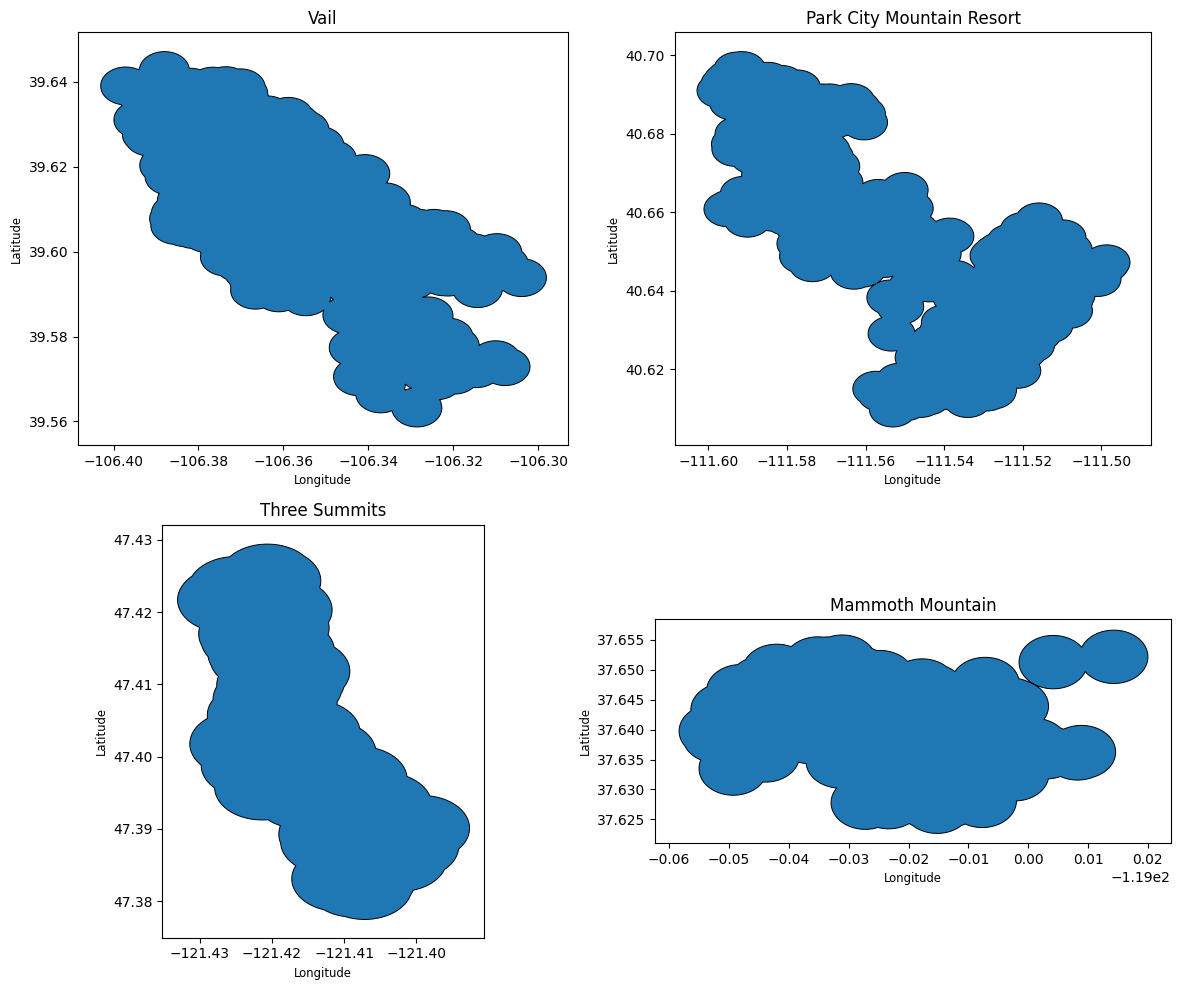

In [23]:
import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path

root = Path.home() / "Files/thesis/ski_thesis_clean"
resort_dir = root / "inputs" / "ski_resorts"

footprints = gpd.read_file(
    resort_dir / "resort_downhill_footprints_500m.geojson"
)

runs = gpd.read_file(
    resort_dir / "resort_downhill_footprints_500m.geojson"
)

selected = [
    "Vail",
    "Park City Mountain Resort",
    "Three Summits",
    "Mammoth Mountain"
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 10)
)

for ax, name in zip(axes.flatten(), selected):

    subset = footprints[
        footprints["name_resort"] == name
    ]

    subset.plot(
        ax=ax,
        edgecolor="black",
        linewidth=0.7
    )

    ax.set_title(name)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_aspect("equal")

plt.tight_layout()
plt.show()

In [24]:
%pip install contextily

  Using cached xyzservices-2026.9.1-py3-none-any.whl.metadata (4.1 kB)
Using cached xyzservices-2026.9.1-py3-none-any.whl (98 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [contextily]

[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


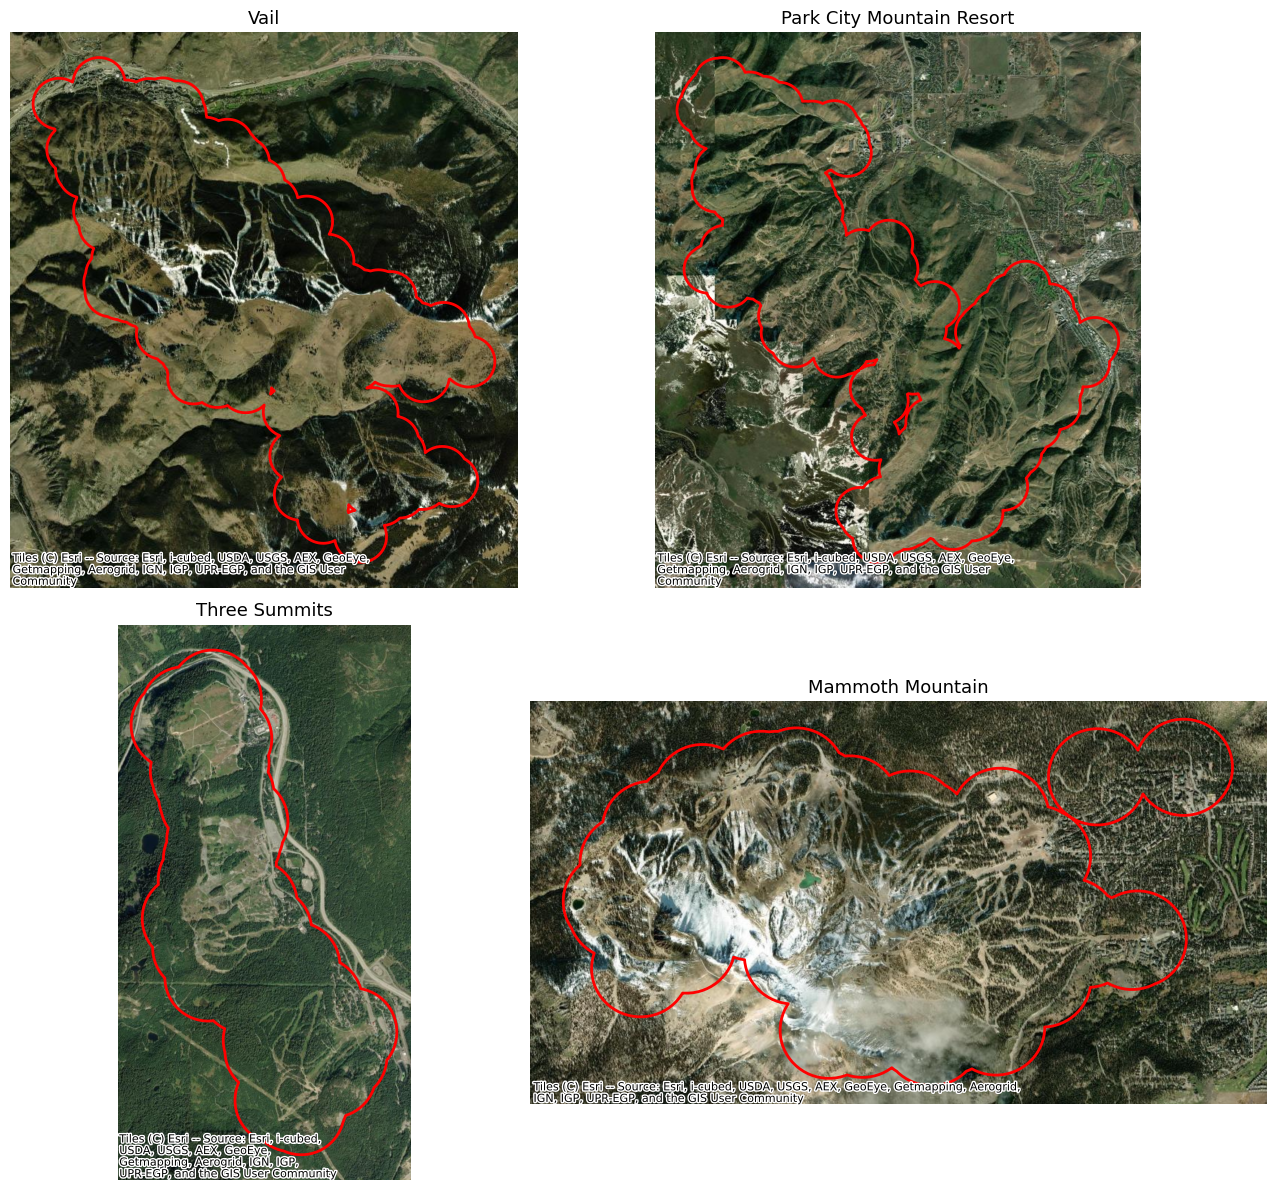

In [25]:
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as ctx
from pathlib import Path

root = Path.home() / "Files/thesis/ski_thesis_clean"
resort_dir = root / "inputs" / "ski_resorts"

footprints = gpd.read_file(
    resort_dir / "resort_downhill_footprints_500m.geojson"
)

# Web Mercator projection for basemap tiles
footprints = footprints.to_crs("EPSG:3857")

selected = [
    "Vail",
    "Park City Mountain Resort",
    "Three Summits",
    "Mammoth Mountain"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 12))

for ax, name in zip(axes.flatten(), selected):

    subset = footprints[
        footprints["name_resort"] == name
    ]

    # Draw footprint outline
    subset.plot(
        ax=ax,
        facecolor="none",
        edgecolor="red",
        linewidth=2
    )

    # Add satellite imagery
    ctx.add_basemap(
        ax,
        source=ctx.providers.Esri.WorldImagery
    )

    ax.set_title(name, fontsize=13)
    ax.set_axis_off()

plt.tight_layout()
plt.show()

In [27]:
import ee

PROJECT_ID = "fdos-491217"

ee.Initialize(project=PROJECT_ID)

print("Earth Engine connected successfully!")
print("Test:", ee.Number(91).getInfo())

Earth Engine connected successfully!
Test: 91


In [28]:
import ee
import geopandas as gpd
from pathlib import Path

# --------------------------------------------------
# INITIALIZE EARTH ENGINE
# --------------------------------------------------

ee.Initialize(project="fdos-491217")

# --------------------------------------------------
# LOAD RESORT FOOTPRINTS
# --------------------------------------------------

root = Path.home() / "Files/thesis/ski_thesis_clean"
resort_dir = root / "inputs" / "ski_resorts"

geojson_path = (
    resort_dir / "resort_downhill_footprints_500m.geojson"
)

footprints = gpd.read_file(geojson_path)
footprints = footprints.to_crs("EPSG:4326")

print("Local resort footprints:", len(footprints))

# --------------------------------------------------
# CONVERT TO EARTH ENGINE FEATURES
# --------------------------------------------------

features = []

for _, row in footprints.iterrows():

    geometry = ee.Geometry(
        row.geometry.__geo_interface__
    )

    feature = ee.Feature(
        geometry,
        {
            "resort_id": str(row["id_resort"]),
            "resort_name": str(row["name_resort"]),
            "area_km2": float(row["area_km2"])
        }
    )

    features.append(feature)

resort_fc = ee.FeatureCollection(features)

# --------------------------------------------------
# VALIDATE
# --------------------------------------------------

print("\nEarth Engine resort count:",
      resort_fc.size().getInfo())

print("\nFirst five resort names:")
print(
    resort_fc.aggregate_array("resort_name")
    .getInfo()[:5]
)

print("\nTotal footprint area (km²):",
      round(footprints["area_km2"].sum(), 2))

print("\nResort footprints successfully loaded!")

Local resort footprints: 91

Earth Engine resort count: 91

First five resort names:
['Palisades Tahoe Alpine Meadows', 'Aspen Snowmass', 'Aspen Highlands', 'Wolf Creek Ski Area', 'Sierra-at-Tahoe Ski Resort']

Total footprint area (km²): 1029.53

Resort footprints successfully loaded!


In [29]:
import ee

# --------------------------------------------------
# INITIALIZE EARTH ENGINE
# --------------------------------------------------

ee.Initialize(project="fdos-491217")

# --------------------------------------------------
# LOAD SNODAS
# --------------------------------------------------

snodas = ee.ImageCollection(
    "projects/climate-engine/snodas/daily"
)

DEPTH_BAND = "Snow_Depth"

print("SNODAS first image:")
print(snodas.first().getInfo()["properties"])

print("\nSNODAS bands:")
print(snodas.first().bandNames().getInfo())

# --------------------------------------------------
# SELECT VAIL RESORT
# --------------------------------------------------

vail = resort_fc.filter(
    ee.Filter.eq("resort_name", "Vail")
)

print("\nVail feature count:", vail.size().getInfo())

# --------------------------------------------------
# CHECK WINTER 2023 COVERAGE
# --------------------------------------------------

winter = snodas.filterDate(
    "2022-11-01",
    "2023-05-01"
)

print("\nWinter 2023 SNODAS images:", winter.size().getInfo())

# --------------------------------------------------
# EXAMINE SNOW DEPTH ON FEBRUARY 1, 2023
# --------------------------------------------------

feb1 = snodas.filterDate(
    "2023-02-01",
    "2023-02-02"
)

print("\nFebruary 1 images:", feb1.size().getInfo())

if feb1.size().getInfo() > 0:

    image = feb1.first().select(DEPTH_BAND)

    stats = image.reduceRegion(
        reducer=ee.Reducer.minMax().combine(
            reducer2=ee.Reducer.mean(),
            sharedInputs=True
        ),
        geometry=vail.geometry(),
        scale=1000,
        maxPixels=1e7
    )

    print("\nVail snow depth statistics:")
    print(stats.getInfo())

# --------------------------------------------------
# CHECK FIRST AND LAST AVAILABLE DATES
# --------------------------------------------------

dates = snodas.aggregate_array(
    "system:time_start"
)

print("\nFirst available date:",
      ee.Date(dates.reduce(ee.Reducer.min())).format("YYYY-MM-dd").getInfo())

print("Last available date:",
      ee.Date(dates.reduce(ee.Reducer.max())).format("YYYY-MM-dd").getInfo())

SNODAS first image:
{'system:time_start': 1064880000000, 'system:footprint': {'type': 'LinearRing', 'coordinates': [[-73.2658854500641, 52.879181375730084], [-83.19739584158245, 52.87918143402392], [-91.32317709181058, 52.87918144093572], [-102.15755209017304, 52.87918137412677], [-114.79765627077688, 52.87918141613061], [-124.7429986588166, 52.87912818942775], [-124.73837251425638, 24.94029440090678], [-120.66627599794985, 24.92201478375159], [-113.8947916442651, 24.89140896967269], [-107.57473957052792, 24.929496061602705], [-102.60898433990083, 24.922014758672155], [-97.19179688913619, 24.922014786081792], [-91.3231770934735, 24.913173214185527], [-85.45455731000229, 24.922014803889734], [-80.9402343712146, 24.935617127219526], [-76.42591147369056, 24.922014782183922], [-71.00872393598408, 24.92201481527867], [-66.93662745407798, 24.940294346511397], [-66.93200124556786, 52.879128160344976], [-73.2658854500641, 52.879181375730084]]}, 'date_ingested': '2018-02-14', 'system:asset_size

In [30]:
import ee

# --------------------------------------------------
# SETTINGS
# --------------------------------------------------

YEAR = 2023
START = f"{YEAR-1}-11-01"
END = f"{YEAR}-05-01"

winter = snodas.filterDate(START, END)

vail = resort_fc.filter(
    ee.Filter.eq("resort_name", "Vail")
)

# --------------------------------------------------
# DAILY SNOW METRICS
# --------------------------------------------------

def daily_metrics(image):

    depth = image.select("Snow_Depth")

    snow_30 = (
        depth.gt(0.30)
        .rename("snow_30cm")
        .toFloat()
    )

    snow_50 = (
        depth.gt(0.50)
        .rename("snow_50cm")
        .toFloat()
    )

    valid = (
        depth.mask()
        .rename("valid_days")
        .toFloat()
        .unmask(0)
    )

    return (
        snow_30
        .addBands(snow_50)
        .addBands(depth.rename("depth_m"))
        .addBands(valid)
    )

daily = winter.map(daily_metrics)

# --------------------------------------------------
# AGGREGATE ACROSS WINTER
# --------------------------------------------------

snow_30_days = daily.select("snow_30cm").sum()
snow_50_days = daily.select("snow_50cm").sum()

mean_depth = daily.select("depth_m").mean()
valid_days = daily.select("valid_days").sum()

seasonal_metrics = (
    snow_30_days
    .addBands(snow_50_days)
    .addBands(mean_depth)
    .addBands(valid_days)
)

# --------------------------------------------------
# SPATIAL AVERAGE ACROSS VAIL FOOTPRINT
# --------------------------------------------------

results = seasonal_metrics.reduceRegions(
    collection=vail,
    reducer=ee.Reducer.mean(),
    scale=1000,
    tileScale=4
)

print("Vail — Winter 2023")
print("Available daily images:", winter.size().getInfo())

for feature in results.getInfo()["features"]:
    print("\nResort:", feature["properties"]["resort_name"])

    for key, value in feature["properties"].items():
        if key in [
            "snow_30cm",
            "snow_50cm",
            "depth_m",
            "valid_days"
        ]:
            print(f"{key}: {value:.2f}" if value is not None
                  else f"{key}: missing")

Vail — Winter 2023
Available daily images: 181

Resort: Vail
depth_m: 0.92
snow_30cm: 166.68
snow_50cm: 145.15
valid_days: 181.00


In [31]:
import ee

ee.Initialize(project="fdos-491217")

# --------------------------------------------------
# SETTINGS
# --------------------------------------------------

START_YEAR = 2004
END_YEAR = 2023

snodas = ee.ImageCollection(
    "projects/climate-engine/snodas/daily"
)

# resort_fc is the 91-resort FeatureCollection
# created earlier in your notebook.

# --------------------------------------------------
# PROCESS ONE WINTER
# --------------------------------------------------

def calculate_winter(year):

    start = ee.Date.fromYMD(year - 1, 11, 1)
    end = ee.Date.fromYMD(year, 5, 1)

    winter = snodas.filterDate(start, end)

    def daily_metrics(image):

        depth = image.select("Snow_Depth")

        snow_30 = (
            depth.gt(0.30)
            .rename("snow_days_30cm")
            .toFloat()
        )

        snow_50 = (
            depth.gt(0.50)
            .rename("snow_days_50cm")
            .toFloat()
        )

        valid = (
            depth.mask()
            .rename("valid_days")
            .toFloat()
            .unmask(0)
        )

        return (
            snow_30
            .addBands(snow_50)
            .addBands(depth.rename("mean_depth_m"))
            .addBands(valid)
        )

    daily = winter.map(daily_metrics)

    seasonal = (
        daily.select("snow_days_30cm").sum()
        .addBands(
            daily.select("snow_days_50cm").sum()
        )
        .addBands(
            daily.select("mean_depth_m").mean()
        )
        .addBands(
            daily.select("valid_days").sum()
        )
    )

    results = seasonal.reduceRegions(
        collection=resort_fc,
        reducer=ee.Reducer.mean(),
        scale=1000,
        tileScale=4
    )

    def add_year(feature):

        return feature.set({
            "year": year,
            "snodas_image_count": winter.size()
        })

    return results.map(add_year)


# --------------------------------------------------
# BUILD FULL PANEL
# --------------------------------------------------

all_results = ee.FeatureCollection([
    calculate_winter(year)
    for year in range(START_YEAR, END_YEAR + 1)
]).flatten()

# --------------------------------------------------
# EXPORT TO GOOGLE DRIVE
# --------------------------------------------------

task = ee.batch.Export.table.toDrive(
    collection=all_results,
    description="resort_snodas_panel_2004_2023",
    folder="GEE_exports",
    fileNamePrefix="resort_snodas_panel_2004_2023",
    fileFormat="CSV",
    selectors=[
        "resort_id",
        "resort_name",
        "area_km2",
        "year",
        "snow_days_30cm",
        "snow_days_50cm",
        "mean_depth_m",
        "valid_days",
        "snodas_image_count"
    ]
)

task.start()

print("Export submitted successfully!")
print("Task ID:", task.id)
print("Task status:", task.status()["state"])
print("Expected resort-winter rows:", 91 * 20)

Export submitted successfully!
Task ID: QY2APYF3BDT5EPOLKZKWNPYC
Task status: READY
Expected resort-winter rows: 1820


In [32]:
import pandas as pd
from pathlib import Path

# --------------------------------------------------
# LOAD RESORT-LEVEL SNODAS PANEL
# --------------------------------------------------

root = Path.home() / "Files/thesis/ski_thesis_clean"

csv_path = (
    root / "inputs" / "ski_resorts"
    / "resort_snodas_panel_2004_2023.csv"
)

df = pd.read_csv(csv_path)

print("Total observations:", len(df))
print("Unique resorts:", df["resort_id"].nunique())
print("Years:", df["year"].min(), "-", df["year"].max())

# --------------------------------------------------
# 1. LOWEST SNOWPACK OBSERVATIONS
# --------------------------------------------------

print("\n" + "=" * 60)
print("20 LOWEST SNOWPACK RESORT-WINTER OBSERVATIONS")
print("=" * 60)

lowest = df.nsmallest(20, "snow_days_30cm")[
    [
        "resort_name",
        "year",
        "snow_days_30cm",
        "snow_days_50cm",
        "mean_depth_m",
        "valid_days"
    ]
]

print(lowest.round(2).to_string(index=False))

# --------------------------------------------------
# 2. RESORTS WITH LOWEST LONG-TERM SNOWPACK
# --------------------------------------------------

print("\n" + "=" * 60)
print("15 RESORTS WITH LOWEST AVERAGE SNOW DAYS")
print("=" * 60)

resort_summary = (
    df.groupby(["resort_id", "resort_name"])
    .agg(
        avg_30cm_days=("snow_days_30cm", "mean"),
        avg_50cm_days=("snow_days_50cm", "mean"),
        avg_depth_m=("mean_depth_m", "mean"),
        min_30cm_days=("snow_days_30cm", "min"),
        max_30cm_days=("snow_days_30cm", "max")
    )
    .reset_index()
    .sort_values("avg_30cm_days")
)

print(
    resort_summary[
        [
            "resort_name",
            "avg_30cm_days",
            "avg_50cm_days",
            "avg_depth_m",
            "min_30cm_days",
            "max_30cm_days"
        ]
    ]
    .head(15)
    .round(2)
    .to_string(index=False)
)

# --------------------------------------------------
# 3. CHECK SNODAS DATA COVERAGE
# --------------------------------------------------

print("\n" + "=" * 60)
print("SNODAS DATA COVERAGE BY WINTER")
print("=" * 60)

coverage = (
    df.groupby("year")
    .agg(
        image_count=("snodas_image_count", "first"),
        min_valid_days=("valid_days", "min"),
        avg_valid_days=("valid_days", "mean"),
        max_valid_days=("valid_days", "max")
    )
    .reset_index()
)

coverage["expected_days"] = [
    (pd.Timestamp(y, 5, 1) -
     pd.Timestamp(y - 1, 11, 1)).days
    for y in coverage["year"]
]

coverage["missing_images"] = (
    coverage["expected_days"] -
    coverage["image_count"]
)

print(coverage.round(2).to_string(index=False))

Total observations: 1820
Unique resorts: 91
Years: 2004 - 2023

20 LOWEST SNOWPACK RESORT-WINTER OBSERVATIONS
                resort_name  year  snow_days_30cm  snow_days_50cm  mean_depth_m  valid_days
                Snow Summit  2004            0.00            0.00          0.00       181.0
  49° North Mountain Resort  2004            0.00            0.00          0.02       181.0
                Snow Summit  2007            0.00            0.00          0.01       179.0
                Snow Summit  2013            0.00            0.00          0.03       180.0
                Snow Summit  2014            0.00            0.00          0.01       181.0
                Snow Summit  2015            0.00            0.00          0.01       181.0
                Snow Summit  2018            0.00            0.00          0.00       181.0
  49° North Mountain Resort  2005            0.09            0.08          0.02       181.0
     Silver Mountain Resort  2005            0.12            0

In [33]:
import ee
import pandas as pd

ee.Initialize(project="fdos-491217")

# --------------------------------------------------
# LOAD ELEVATION DATA
# --------------------------------------------------

elevation = (
    ee.Image("USGS/SRTMGL1_003")
    .select("elevation")
)

# --------------------------------------------------
# CALCULATE ELEVATION STATISTICS
# --------------------------------------------------

elevation_stats = elevation.reduceRegions(
    collection=resort_fc,
    reducer=(
        ee.Reducer.minMax()
        .combine(
            reducer2=ee.Reducer.mean(),
            sharedInputs=True
        )
    ),
    scale=90,
    tileScale=4
)

# --------------------------------------------------
# CONVERT TO DATAFRAME
# --------------------------------------------------

features = elevation_stats.getInfo()["features"]

records = []

for feature in features:
    p = feature["properties"]

    records.append({
        "resort_name": p["resort_name"],
        "elevation_min_m": p.get("min"),
        "elevation_mean_m": p.get("mean"),
        "elevation_max_m": p.get("max")
    })

elevation_df = pd.DataFrame(records)

# --------------------------------------------------
# EXAMINE LOW-SNOW RESORTS
# --------------------------------------------------

check_resorts = [
    "Snow Summit",
    "Mt. Bachelor",
    "49° North Mountain Resort",
    "Silver Mountain Resort",
    "Kelly Canyon Ski Resort",
    "Great Divide Ski Area"
]

print("ELEVATION OF LOW-SNOW RESORTS")
print("=" * 70)

print(
    elevation_df[
        elevation_df["resort_name"].isin(check_resorts)
    ]
    .round(0)
    .to_string(index=False)
)

print("\nALL RESORT ELEVATION SUMMARY")
print("=" * 70)

print(
    elevation_df[
        [
            "elevation_min_m",
            "elevation_mean_m",
            "elevation_max_m"
        ]
    ].describe().round(0)
)

ELEVATION OF LOW-SNOW RESORTS
              resort_name  elevation_min_m  elevation_mean_m  elevation_max_m
    Great Divide Ski Area             1727            1956.0             2226
  Kelly Canyon Ski Resort             1762            1928.0             2074
              Snow Summit             2106            2320.0             2497
49° North Mountain Resort             1151            1419.0             1753
   Silver Mountain Resort             1197            1618.0             1907
             Mt. Bachelor             1727            2098.0             2662

ALL RESORT ELEVATION SUMMARY
       elevation_min_m  elevation_mean_m  elevation_max_m
count             91.0              91.0             91.0
mean            2046.0            2402.0           2793.0
std              580.0             596.0            639.0
min              777.0             996.0           1250.0
25%             1702.0            1934.0           2330.0
50%             2016.0            2356.0      

Panel observations: 1820
Missing elevation: 0

Elevation / snow-day correlation: 0.202


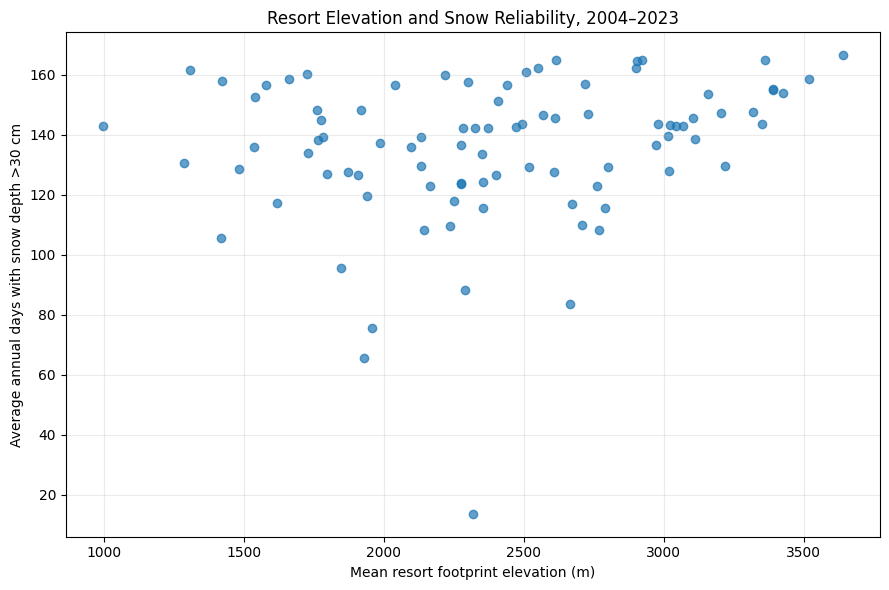

In [34]:
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# MERGE ELEVATION WITH SNODAS PANEL
# --------------------------------------------------

panel = df.merge(
    elevation_df,
    on="resort_name",
    how="left",
    validate="many_to_one"
)

print("Panel observations:", len(panel))
print("Missing elevation:", panel["elevation_mean_m"].isna().sum())

# --------------------------------------------------
# RESORT-LEVEL LONG-TERM AVERAGES
# --------------------------------------------------

resort_avg = (
    panel.groupby("resort_name", as_index=False)
    .agg(
        avg_snow_days_30cm=("snow_days_30cm", "mean"),
        avg_snow_days_50cm=("snow_days_50cm", "mean"),
        avg_depth_m=("mean_depth_m", "mean"),
        elevation_mean_m=("elevation_mean_m", "first")
    )
)

# --------------------------------------------------
# CORRELATION
# --------------------------------------------------

corr = resort_avg[
    ["elevation_mean_m", "avg_snow_days_30cm"]
].corr().iloc[0, 1]

print(f"\nElevation / snow-day correlation: {corr:.3f}")

# --------------------------------------------------
# PLOT
# --------------------------------------------------

plt.figure(figsize=(9, 6))

plt.scatter(
    resort_avg["elevation_mean_m"],
    resort_avg["avg_snow_days_30cm"],
    alpha=0.7
)

plt.xlabel("Mean resort footprint elevation (m)")
plt.ylabel("Average annual days with snow depth >30 cm")
plt.title("Resort Elevation and Snow Reliability, 2004–2023")

plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [35]:
import ee
import pandas as pd
from pathlib import Path

ee.Initialize(project="fdos-491217")

# --------------------------------------------------
# 1. LOAD ELEVATION AND TERRAIN
# --------------------------------------------------

dem = ee.Image("USGS/SRTMGL1_003").select("elevation")

terrain = ee.Terrain.products(dem)

slope = terrain.select("slope")
aspect = terrain.select("aspect")

# --------------------------------------------------
# 2. DERIVE ASPECT VARIABLES
# --------------------------------------------------

# North-facing = NW through NE (315°–45°)
north_facing = (
    aspect.gte(315)
    .Or(aspect.lte(45))
    .rename("north_facing_share")
    .toFloat()
)

# Northness: +1 = north, -1 = south
northness = (
    aspect.multiply(3.141592653589793 / 180)
    .cos()
    .rename("northness")
)

# Eastness: +1 = east, -1 = west
eastness = (
    aspect.multiply(3.141592653589793 / 180)
    .sin()
    .rename("eastness")
)

terrain_image = (
    dem.rename("elevation_m")
    .addBands(slope.rename("slope_deg"))
    .addBands(north_facing)
    .addBands(northness)
    .addBands(eastness)
)

# --------------------------------------------------
# 3. EXTRACT RESORT-LEVEL TERRAIN STATISTICS
# --------------------------------------------------

terrain_results = terrain_image.reduceRegions(
    collection=resort_fc,
    reducer=ee.Reducer.mean(),
    scale=90,
    tileScale=4
)

# --------------------------------------------------
# 4. CONVERT TO DATAFRAME
# --------------------------------------------------

features = terrain_results.getInfo()["features"]

records = []

for feature in features:
    p = feature["properties"]

    records.append({
        "resort_id": p["resort_id"],
        "resort_name": p["resort_name"],
        "elevation_mean_m": p.get("elevation_m"),
        "slope_mean_deg": p.get("slope_deg"),
        "north_facing_share": p.get("north_facing_share"),
        "northness": p.get("northness"),
        "eastness": p.get("eastness")
    })

terrain_df = pd.DataFrame(records)

# --------------------------------------------------
# 5. SAVE
# --------------------------------------------------

root = Path.home() / "Files/thesis/ski_thesis_clean"
output_dir = root / "inputs" / "ski_resorts"

output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "resort_terrain_variables.csv"

terrain_df.to_csv(output_path, index=False)

# --------------------------------------------------
# 6. VALIDATE
# --------------------------------------------------

print("Resorts:", len(terrain_df))
print("Missing values:")
print(terrain_df.isna().sum())

print("\nTerrain summary:")
print(
    terrain_df[
        [
            "elevation_mean_m",
            "slope_mean_deg",
            "north_facing_share",
            "northness",
            "eastness"
        ]
    ].describe().round(3)
)

print("\nFirst 10 resorts:")
print(terrain_df.head(10).round(3).to_string(index=False))

print("\nSaved to:", output_path)

Resorts: 91
Missing values:
resort_id             0
resort_name           0
elevation_mean_m      0
slope_mean_deg        0
north_facing_share    0
northness             0
eastness              0
dtype: int64

Terrain summary:
       elevation_mean_m  slope_mean_deg  north_facing_share  northness  \
count            91.000          91.000              91.000     91.000   
mean           2402.160          16.949               0.336      0.196   
std             595.513           3.134               0.154      0.271   
min             996.351          10.418               0.001     -0.777   
25%            1934.065          14.728               0.237      0.066   
50%            2356.246          16.301               0.357      0.236   
75%            2850.737          18.618               0.416      0.378   
max            3640.413          24.639               0.873      0.866   

       eastness  
count    91.000  
mean      0.094  
std       0.308  
min      -0.813  
25%      -0.093 

In [36]:
import ee

ee.Initialize(project="fdos-491217")

# --------------------------------------------------
# 1. LOAD DAYMET
# --------------------------------------------------

daymet = ee.ImageCollection("NASA/ORNL/DAYMET_V4")

print("Daymet bands:", daymet.first().bandNames().getInfo())

# --------------------------------------------------
# 2. SETTINGS
# --------------------------------------------------

START_YEAR = 2004
END_YEAR = 2023

# --------------------------------------------------
# 3. PROCESS ONE WINTER
# --------------------------------------------------

def calculate_daymet_winter(year):

    start = ee.Date.fromYMD(year - 1, 11, 1)
    end = ee.Date.fromYMD(year, 5, 1)

    winter = daymet.filterDate(start, end)

    def daily_weather(image):

        tmin = image.select("tmin")
        tmax = image.select("tmax")
        precip = image.select("prcp")

        tmean = tmin.add(tmax).divide(2)

        freezing = tmean.lt(0)

        freeze_precip = precip.multiply(freezing)

        return (
            tmean.rename("winter_tmean_c")
            .addBands(tmin.rename("winter_tmin_c"))
            .addBands(tmax.rename("winter_tmax_c"))
            .addBands(precip.rename("winter_precip_mm"))
            .addBands(freezing.rename("freezing_days"))
            .addBands(freeze_precip.rename("freeze_precip_mm"))
            .toFloat()
        )

    daily = winter.map(daily_weather)

    # Seasonal averages for temperatures
    temperature = daily.select([
        "winter_tmean_c",
        "winter_tmin_c",
        "winter_tmax_c"
    ]).mean()

    # Seasonal totals for precipitation and days
    totals = daily.select([
        "winter_precip_mm",
        "freezing_days",
        "freeze_precip_mm"
    ]).sum()

    seasonal = temperature.addBands(totals)

    # Extract mean spatial value per resort
    results = seasonal.reduceRegions(
        collection=resort_fc,
        reducer=ee.Reducer.mean(),
        scale=1000,
        tileScale=4
    )

    def add_metadata(feature):
        return feature.set({
            "year": year,
            "daymet_image_count": winter.size()
        })

    return results.map(add_metadata)


# --------------------------------------------------
# 4. BUILD FULL PANEL
# --------------------------------------------------

all_weather = ee.FeatureCollection([
    calculate_daymet_winter(year)
    for year in range(START_YEAR, END_YEAR + 1)
]).flatten()

# --------------------------------------------------
# 5. EXPORT TO GOOGLE DRIVE
# --------------------------------------------------

task_weather = ee.batch.Export.table.toDrive(
    collection=all_weather,
    description="resort_daymet_weather_2004_2023",
    folder="GEE_exports",
    fileNamePrefix="resort_daymet_weather_2004_2023",
    fileFormat="CSV",
    selectors=[
        "resort_id",
        "resort_name",
        "year",
        "winter_tmean_c",
        "winter_tmin_c",
        "winter_tmax_c",
        "winter_precip_mm",
        "freezing_days",
        "freeze_precip_mm",
        "daymet_image_count"
    ]
)

task_weather.start()

print("\nDaymet export submitted!")
print("Task ID:", task_weather.id)
print("Task status:", task_weather.status()["state"])
print("Expected rows:", 91 * 20)

Daymet bands: ['dayl', 'prcp', 'srad', 'swe', 'tmax', 'tmin', 'vp']

Daymet export submitted!
Task ID: 3B3QRVNEJE2VZFJKFPVKD6YF
Task status: READY
Expected rows: 1820


In [37]:
import ee

ee.Initialize(project="fdos-491217")

snodas = ee.ImageCollection(
    "projects/climate-engine/snodas/daily"
)

# --------------------------------------------------
# SETTINGS
# --------------------------------------------------

START_YEAR = 2004
END_YEAR = 2023

EXTRACTION_SCALE = 500

# --------------------------------------------------
# PROCESS ONE WINTER
# --------------------------------------------------

def calculate_winter_500m(year):

    start = ee.Date.fromYMD(year - 1, 11, 1)
    end = ee.Date.fromYMD(year, 5, 1)

    winter = snodas.filterDate(start, end)

    def daily_metrics(image):

        depth = image.select("Snow_Depth")

        snow_30 = (
            depth.gt(0.30)
            .rename("snow_days_30cm")
            .toFloat()
        )

        snow_50 = (
            depth.gt(0.50)
            .rename("snow_days_50cm")
            .toFloat()
        )

        valid = (
            depth.mask()
            .rename("valid_days")
            .toFloat()
            .unmask(0)
        )

        return (
            snow_30
            .addBands(snow_50)
            .addBands(depth.rename("mean_depth_m"))
            .addBands(valid)
        )

    daily = winter.map(daily_metrics)

    seasonal = (
        daily.select("snow_days_30cm").sum()
        .addBands(
            daily.select("snow_days_50cm").sum()
        )
        .addBands(
            daily.select("mean_depth_m").mean()
        )
        .addBands(
            daily.select("valid_days").sum()
        )
    )

    results = seasonal.reduceRegions(
        collection=resort_fc,
        reducer=ee.Reducer.mean(),
        scale=EXTRACTION_SCALE,
        tileScale=4
    )

    return results.map(
        lambda feature: feature.set({
            "year": year,
            "snodas_image_count": winter.size()
        })
    )


# --------------------------------------------------
# BUILD FULL PANEL
# --------------------------------------------------

results_500m = ee.FeatureCollection([
    calculate_winter_500m(year)
    for year in range(START_YEAR, END_YEAR + 1)
]).flatten()

# --------------------------------------------------
# EXPORT
# --------------------------------------------------

task_500m = ee.batch.Export.table.toDrive(
    collection=results_500m,
    description="resort_snodas_panel_500m_2004_2023",
    folder="GEE_exports",
    fileNamePrefix="resort_snodas_panel_500m_2004_2023",
    fileFormat="CSV",
    selectors=[
        "resort_id",
        "resort_name",
        "year",
        "snow_days_30cm",
        "snow_days_50cm",
        "mean_depth_m",
        "valid_days",
        "snodas_image_count"
    ]
)

task_500m.start()

print("500 m robustness export submitted!")
print("Task ID:", task_500m.id)
print("Task status:", task_500m.status()["state"])
print("Expected observations:", 91 * 20)

500 m robustness export submitted!
Task ID: WEJYF6ZMOU6T23EGM3FCO5BD
Task status: READY
Expected observations: 1820


In [38]:
import pandas as pd
from pathlib import Path

folder = (
    Path.home()
    / "Files/thesis/ski_thesis_clean/inputs/ski_resorts"
)

baseline = pd.read_csv(
    folder / "resort_snodas_panel_2004_2023.csv"
)

robust = pd.read_csv(
    folder / "resort_snodas_panel_500m_2004_2023.csv"
)

metrics = [
    "snow_days_30cm",
    "snow_days_50cm",
    "mean_depth_m"
]

comparison = baseline.merge(
    robust,
    on=["resort_id", "year"],
    suffixes=("_1000m", "_500m"),
    validate="one_to_one"
)

print("Matched observations:", len(comparison))

print("\nRESOLUTION ROBUSTNESS SUMMARY")
print("=" * 65)

for metric in metrics:
    a = comparison[f"{metric}_1000m"]
    b = comparison[f"{metric}_500m"]

    print(f"\n{metric}")
    print(f"  1000m mean: {a.mean():.3f}")
    print(f"  500m mean:  {b.mean():.3f}")
    print(f"  Correlation: {a.corr(b):.4f}")
    print(f"  Mean absolute difference: {(a-b).abs().mean():.3f}")
    print(f"  Maximum absolute difference: {(a-b).abs().max():.3f}")

# Identify the largest differences in 30 cm snow days
comparison["difference_30cm"] = (
    comparison["snow_days_30cm_500m"]
    - comparison["snow_days_30cm_1000m"]
)

print("\n10 LARGEST DIFFERENCES")
print("=" * 65)

print(
    comparison.assign(
        absolute_difference=comparison["difference_30cm"].abs()
    )
    .nlargest(10, "absolute_difference")[
        [
            "resort_name_1000m",
            "year",
            "snow_days_30cm_1000m",
            "snow_days_30cm_500m",
            "difference_30cm"
        ]
    ]
    .round(2)
    .to_string(index=False)
)

Matched observations: 1820

RESOLUTION ROBUSTNESS SUMMARY

snow_days_30cm
  1000m mean: 135.544
  500m mean:  135.529
  Correlation: 0.9968
  Mean absolute difference: 1.609
  Maximum absolute difference: 16.951

snow_days_50cm
  1000m mean: 116.391
  500m mean:  116.341
  Correlation: 0.9966
  Mean absolute difference: 1.952
  Maximum absolute difference: 25.222

mean_depth_m
  1000m mean: 0.951
  500m mean:  0.952
  Correlation: 0.9982
  Mean absolute difference: 0.022
  Maximum absolute difference: 0.307

10 LARGEST DIFFERENCES
                   resort_name_1000m  year  snow_days_30cm_1000m  snow_days_30cm_500m  difference_30cm
                        Pebble Creek  2018                 61.27                78.22            16.95
Nordic Valley Resort (Wolf Mountain)  2012                 55.48                72.39            16.91
                        Pebble Creek  2011                132.96               149.14            16.19
              Cimarron Mountain Club  2007         

In [39]:
import pandas as pd
from pathlib import Path

# --------------------------------------------------
# LOAD DAYMET DATA
# --------------------------------------------------

folder = (
    Path.home()
    / "Files/thesis/ski_thesis_clean/inputs/ski_resorts"
)

daymet_df = pd.read_csv(
    folder / "resort_daymet_weather_2004_2023.csv"
)

# --------------------------------------------------
# CHECK PANEL STRUCTURE
# --------------------------------------------------

print("DAYMET PANEL STRUCTURE")
print("=" * 60)

print("Observations:", len(daymet_df))
print("Unique resorts:", daymet_df["resort_id"].nunique())
print("Years:", daymet_df["year"].min(), "-", daymet_df["year"].max())

print("\nMissing values:")
print(daymet_df.isna().sum())

print("\nDuplicate resort-year rows:",
      daymet_df.duplicated(["resort_id", "year"]).sum())

# --------------------------------------------------
# SUMMARY STATISTICS
# --------------------------------------------------

weather_vars = [
    "winter_tmean_c",
    "winter_tmin_c",
    "winter_tmax_c",
    "winter_precip_mm",
    "freezing_days",
    "freeze_precip_mm"
]

print("\nWEATHER VARIABLE SUMMARY")
print("=" * 60)

print(
    daymet_df[weather_vars]
    .describe()
    .round(2)
    .to_string()
)

# --------------------------------------------------
# CHECK IMAGE COVERAGE
# --------------------------------------------------

print("\nDAYMET IMAGE COUNTS BY WINTER")
print("=" * 60)

print(
    daymet_df.groupby("year")["daymet_image_count"]
    .agg(["min", "max"])
    .to_string()
)

# --------------------------------------------------
# CHECK EXAMPLE RESORTS
# --------------------------------------------------

example_resorts = [
    "Vail",
    "Snow Summit",
    "Mt. Bachelor",
    "Aspen Snowmass"
]

print("\nEXAMPLE RESORTS — WINTER 2023")
print("=" * 60)

print(
    daymet_df[
        (daymet_df["year"] == 2023)
        & (daymet_df["resort_name"].isin(example_resorts))
    ][
        ["resort_name"] + weather_vars
    ]
    .round(2)
    .to_string(index=False)
)

DAYMET PANEL STRUCTURE
Observations: 1820
Unique resorts: 91
Years: 2004 - 2023

Missing values:
resort_id             0
resort_name           0
year                  0
winter_tmean_c        0
winter_tmin_c         0
winter_tmax_c         0
winter_precip_mm      0
freezing_days         0
freeze_precip_mm      0
daymet_image_count    0
dtype: int64

Duplicate resort-year rows: 0

WEATHER VARIABLE SUMMARY
       winter_tmean_c  winter_tmin_c  winter_tmax_c  winter_precip_mm  freezing_days  freeze_precip_mm
count         1820.00        1820.00        1820.00           1820.00        1820.00           1820.00
mean            -1.81          -6.82           3.19            742.17         111.09            494.83
std              2.37           2.88           2.35            481.05          31.40            284.71
min             -7.92         -13.49          -3.06            121.03           3.00              0.00
25%             -3.53          -9.12           1.61            415.99         

In [40]:
import pandas as pd
from pathlib import Path

# --------------------------------------------------
# PATHS
# --------------------------------------------------

folder = (
    Path.home()
    / "Files/thesis/ski_thesis_clean/inputs/ski_resorts"
)

# --------------------------------------------------
# LOAD DATASETS
# --------------------------------------------------

snodas_df = pd.read_csv(
    folder / "resort_snodas_panel_2004_2023.csv"
)

daymet_df = pd.read_csv(
    folder / "resort_daymet_weather_2004_2023.csv"
)

terrain_df = pd.read_csv(
    folder / "resort_terrain_variables.csv"
)

# --------------------------------------------------
# MERGE WEATHER
# --------------------------------------------------

panel = snodas_df.merge(
    daymet_df.drop(columns=["resort_name"]),
    on=["resort_id", "year"],
    how="left",
    validate="one_to_one"
)

# --------------------------------------------------
# MERGE TERRAIN
# --------------------------------------------------

panel = panel.merge(
    terrain_df.drop(columns=["resort_name"]),
    on="resort_id",
    how="left",
    validate="many_to_one"
)

# --------------------------------------------------
# VALIDATE
# --------------------------------------------------

print("FINAL MODELING PANEL")
print("=" * 60)

print("Observations:", len(panel))
print("Unique resorts:", panel["resort_id"].nunique())
print("Years:", panel["year"].min(), "-", panel["year"].max())

print("\nMissing values:")
print(panel.isna().sum())

print("\nDuplicate resort-year rows:",
      panel.duplicated(["resort_id", "year"]).sum())

# --------------------------------------------------
# SAVE
# --------------------------------------------------

output_path = (
    folder / "resort_snow_ml_panel_2004_2023.csv"
)

panel.to_csv(output_path, index=False)

print("\nSaved to:", output_path)

# --------------------------------------------------
# PREVIEW
# --------------------------------------------------

print("\nFirst five observations:")
print(panel.head().round(2).to_string(index=False))

FINAL MODELING PANEL
Observations: 1820
Unique resorts: 91
Years: 2004 - 2023

Missing values:
resort_id             0
resort_name           0
area_km2              0
year                  0
snow_days_30cm        0
snow_days_50cm        0
mean_depth_m          0
valid_days            0
snodas_image_count    0
winter_tmean_c        0
winter_tmin_c         0
winter_tmax_c         0
winter_precip_mm      0
freezing_days         0
freeze_precip_mm      0
daymet_image_count    0
elevation_mean_m      0
slope_mean_deg        0
north_facing_share    0
northness             0
eastness              0
dtype: int64

Duplicate resort-year rows: 0

Saved to: /Users/evabenson/Files/thesis/ski_thesis_clean/inputs/ski_resorts/resort_snow_ml_panel_2004_2023.csv

First five observations:
                               resort_id                    resort_name  area_km2  year  snow_days_30cm  snow_days_50cm  mean_depth_m  valid_days  snodas_image_count  winter_tmean_c  winter_tmin_c  winter_tmax_c  winter

In [41]:
import pandas as pd
from pathlib import Path

# --------------------------------------------------
# LOAD MODELING PANEL
# --------------------------------------------------

folder = (
    Path.home()
    / "Files/thesis/ski_thesis_clean/inputs/ski_resorts"
)

panel = pd.read_csv(
    folder / "resort_snow_ml_panel_2004_2023.csv"
)

# --------------------------------------------------
# DEFINE TARGET AND PREDICTORS
# --------------------------------------------------

target = "snow_days_30cm"

features = [
    "winter_tmean_c",
    "winter_precip_mm",
    "freezing_days",
    "freeze_precip_mm",
    "elevation_mean_m",
    "slope_mean_deg",
    "north_facing_share",
    "northness",
    "eastness"
]

# --------------------------------------------------
# SPLIT BY WINTER
# --------------------------------------------------

train = panel[panel["year"].between(2004, 2017)].copy()
val = panel[panel["year"].between(2018, 2020)].copy()
test = panel[panel["year"].between(2021, 2023)].copy()

X_train = train[features]
y_train = train[target]

X_val = val[features]
y_val = val[target]

X_test = test[features]
y_test = test[target]

# --------------------------------------------------
# VALIDATE SPLITS
# --------------------------------------------------

print("TRAINING / VALIDATION / TEST SPLIT")
print("=" * 60)

for name, data in [
    ("Training", train),
    ("Validation", val),
    ("Testing", test)
]:
    print(
        f"{name}: {len(data)} observations, "
        f"winters {data['year'].min()}–{data['year'].max()}, "
        f"{data['resort_id'].nunique()} resorts"
    )

print("\nPredictors:")
for feature in features:
    print(" -", feature)

print("\nTarget:", target)

print("\nMissing predictor values:")
print(panel[features].isna().sum().sum())

print("\nMean snow days by split:")
print(
    pd.DataFrame({
        "Training": [y_train.mean()],
        "Validation": [y_val.mean()],
        "Testing": [y_test.mean()]
    }).round(2)
)

TRAINING / VALIDATION / TEST SPLIT
Training: 1274 observations, winters 2004–2017, 91 resorts
Validation: 273 observations, winters 2018–2020, 91 resorts
Testing: 273 observations, winters 2021–2023, 91 resorts

Predictors:
 - winter_tmean_c
 - winter_precip_mm
 - freezing_days
 - freeze_precip_mm
 - elevation_mean_m
 - slope_mean_deg
 - north_facing_share
 - northness
 - eastness

Target: snow_days_30cm

Missing predictor values:
0

Mean snow days by split:
   Training  Validation  Testing
0    133.94      135.89   142.68


In [2]:
import numpy as np
import pandas as pd
import xgboost as xgb

from pathlib import Path
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# --------------------------------------------------
# 1. LOAD MODELING DATA
# --------------------------------------------------

folder = (
    Path.home()
    / "Files/thesis/ski_thesis_clean/inputs/ski_resorts"
)

panel = pd.read_csv(
    folder / "resort_snow_ml_panel_2004_2023.csv"
)

# --------------------------------------------------
# 2. DEFINE TARGET AND PREDICTORS
# --------------------------------------------------

target = "snow_days_30cm"

features = [
    "winter_tmean_c",
    "winter_precip_mm",
    "freezing_days",
    "freeze_precip_mm",
    "elevation_mean_m",
    "slope_mean_deg",
    "north_facing_share",
    "northness",
    "eastness"
]

# --------------------------------------------------
# 3. SPLIT DATA BY WINTER
# --------------------------------------------------

train = panel[panel["year"].between(2004, 2017)].copy()
val = panel[panel["year"].between(2018, 2020)].copy()
test = panel[panel["year"].between(2021, 2023)].copy()

X_train = train[features]
y_train = train[target]

X_val = val[features]
y_val = val[target]

X_test = test[features]
y_test = test[target]

print("Training observations:", len(train))
print("Validation observations:", len(val))
print("Testing observations:", len(test))

# --------------------------------------------------
# 4. TRAIN XGBOOST
# --------------------------------------------------

model = xgb.XGBRegressor(
    n_estimators=500,
    max_depth=3,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("\nXGBoost training complete!")

# --------------------------------------------------
# 5. GENERATE PREDICTIONS
# --------------------------------------------------

val_pred = model.predict(X_val)
test_pred = model.predict(X_test)

# --------------------------------------------------
# 6. RESORT-AVERAGE BASELINE
# --------------------------------------------------

resort_means = (
    train.groupby("resort_id")[target]
    .mean()
)

overall_train_mean = y_train.mean()

val_baseline = (
    val["resort_id"]
    .map(resort_means)
    .fillna(overall_train_mean)
    .to_numpy()
)

test_baseline = (
    test["resort_id"]
    .map(resort_means)
    .fillna(overall_train_mean)
    .to_numpy()
)

# --------------------------------------------------
# 7. EVALUATION FUNCTION
# --------------------------------------------------

def evaluate(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "R2": r2_score(y_true, y_pred)
    }

# --------------------------------------------------
# 8. COMPARE MODEL PERFORMANCE
# --------------------------------------------------

results = pd.DataFrame({
    "Validation baseline": evaluate(y_val, val_baseline),
    "Validation XGBoost": evaluate(y_val, val_pred),
    "Test baseline": evaluate(y_test, test_baseline),
    "Test XGBoost": evaluate(y_test, test_pred)
}).T

print("\nMODEL PERFORMANCE")
print("=" * 65)

print(results.round(3).to_string())

# --------------------------------------------------
# 9. FEATURE IMPORTANCE
# --------------------------------------------------

importance = pd.DataFrame({
    "feature": features,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

print("\nXGBOOST FEATURE IMPORTANCE")
print("=" * 65)

print(importance.round(4).to_string(index=False))

Training observations: 1274
Validation observations: 273
Testing observations: 273

XGBoost training complete!

MODEL PERFORMANCE
                        MAE    RMSE     R2
Validation baseline  19.297  25.162  0.466
Validation XGBoost   16.641  21.172  0.622
Test baseline        18.770  24.434  0.355
Test XGBoost         15.832  21.525  0.500

XGBOOST FEATURE IMPORTANCE
           feature  importance
  freeze_precip_mm      0.2532
     freezing_days      0.1281
         northness      0.1176
    slope_mean_deg      0.1063
    winter_tmean_c      0.0994
  elevation_mean_m      0.0827
  winter_precip_mm      0.0766
north_facing_share      0.0758
          eastness      0.0604


In [3]:
import pandas as pd
import numpy as np
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# --------------------------------------------------
# CREATE TEST PREDICTION DATAFRAME
# --------------------------------------------------

predictions = test[
    [
        "resort_id",
        "resort_name",
        "year",
        "snow_days_30cm"
    ]
].copy()

predictions["predicted_snow_days"] = test_pred
predictions["baseline_prediction"] = test_baseline

predictions["error"] = (
    predictions["predicted_snow_days"]
    - predictions["snow_days_30cm"]
)

predictions["absolute_error"] = predictions["error"].abs()

# --------------------------------------------------
# PERFORMANCE BY WINTER
# --------------------------------------------------

rows = []

for year, group in predictions.groupby("year"):

    actual = group["snow_days_30cm"]
    predicted = group["predicted_snow_days"]
    baseline = group["baseline_prediction"]

    rows.append({
        "year": year,
        "actual_mean": actual.mean(),
        "predicted_mean": predicted.mean(),
        "baseline_MAE": mean_absolute_error(actual, baseline),
        "xgboost_MAE": mean_absolute_error(actual, predicted),
        "xgboost_RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "xgboost_R2": r2_score(actual, predicted)
    })

year_results = pd.DataFrame(rows)

print("TEST PERFORMANCE BY WINTER")
print("=" * 75)

print(year_results.round(2).to_string(index=False))

# --------------------------------------------------
# LARGEST PREDICTION ERRORS
# --------------------------------------------------

print("\n15 LARGEST PREDICTION ERRORS")
print("=" * 75)

print(
    predictions.nlargest(15, "absolute_error")[
        [
            "resort_name",
            "year",
            "snow_days_30cm",
            "predicted_snow_days",
            "error"
        ]
    ]
    .round(2)
    .to_string(index=False)
)

TEST PERFORMANCE BY WINTER
 year  actual_mean  predicted_mean  baseline_MAE  xgboost_MAE  xgboost_RMSE  xgboost_R2
 2021       137.29      129.309998         18.52        20.10         27.24        0.40
 2022       131.20      127.650002         11.46        14.18         19.34        0.46
 2023       159.54      151.919998         26.32        13.22         16.55        0.33

15 LARGEST PREDICTION ERRORS
                resort_name  year  snow_days_30cm  predicted_snow_days   error
        Mt. Shasta Ski Park  2021          151.10            40.590000 -110.51
        Mt. Shasta Ski Park  2022          128.87            31.740000  -97.13
   Sunlight Mountain Resort  2021          131.87            71.750000  -60.12
                Eagle Point  2021           90.15           148.770004   58.63
         Discovery Ski Area  2021           85.75           136.750000   51.01
                Snow Summit  2023           46.15            96.839996   50.69
    Kelly Canyon Ski Resort  2022     

MT. SHASTA — HISTORICAL CONDITIONS
 year  snow_days_30cm  snow_days_50cm  mean_depth_m  winter_tmean_c  winter_precip_mm  freeze_precip_mm  freezing_days  elevation_mean_m
 2004          111.70          100.15          0.92            4.24           1361.92            153.11          21.09           1908.73
 2005          161.45          141.75          1.50            4.22            989.76            263.16          25.78           1908.73
 2006          126.18          122.64          1.53            3.16           1844.93            333.03          38.66           1908.73
 2007          118.08           97.36          0.60            4.51            859.07            144.22          29.89           1908.73
 2008          133.60          131.21          1.12            3.16            823.80            331.50          44.06           1908.73
 2009          131.05          109.30          0.89            4.26           1027.07            269.45          30.05           1908.73
 2010 

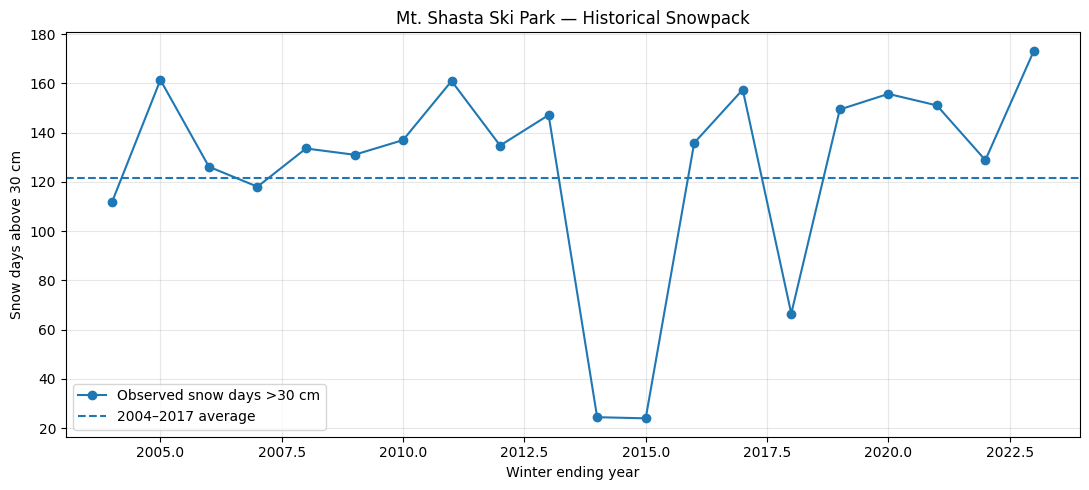

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. EXAMINE MT. SHASTA ACROSS ALL WINTERS
# --------------------------------------------------

shasta = panel[
    panel["resort_name"].str.contains(
        "Mt. Shasta", case=False, na=False
    )
].copy()

columns = [
    "year",
    "snow_days_30cm",
    "snow_days_50cm",
    "mean_depth_m",
    "winter_tmean_c",
    "winter_precip_mm",
    "freeze_precip_mm",
    "freezing_days",
    "elevation_mean_m"
]

print("MT. SHASTA — HISTORICAL CONDITIONS")
print("=" * 90)

print(
    shasta[columns]
    .sort_values("year")
    .round(2)
    .to_string(index=False)
)

# --------------------------------------------------
# 2. COMPARE TEST PREDICTIONS
# --------------------------------------------------

shasta_predictions = predictions[
    predictions["resort_name"].str.contains(
        "Mt. Shasta", case=False, na=False
    )
]

print("\nMT. SHASTA — TEST PREDICTIONS")
print("=" * 90)

print(
    shasta_predictions[
        [
            "year",
            "snow_days_30cm",
            "predicted_snow_days",
            "baseline_prediction",
            "error"
        ]
    ]
    .round(2)
    .to_string(index=False)
)

# --------------------------------------------------
# 3. VISUALIZE HISTORICAL SNOW DAYS
# --------------------------------------------------

plt.figure(figsize=(11, 5))

plt.plot(
    shasta["year"],
    shasta["snow_days_30cm"],
    marker="o",
    label="Observed snow days >30 cm"
)

plt.axhline(
    shasta[
        shasta["year"].between(2004, 2017)
    ]["snow_days_30cm"].mean(),
    linestyle="--",
    label="2004–2017 average"
)

plt.xlabel("Winter ending year")
plt.ylabel("Snow days above 30 cm")
plt.title("Mt. Shasta Ski Park — Historical Snowpack")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [5]:
import pandas as pd
from pathlib import Path

# --------------------------------------------------
# LOAD PANEL
# --------------------------------------------------

folder = (
    Path.home()
    / "Files/thesis/ski_thesis_clean/inputs/ski_resorts"
)

panel = pd.read_csv(
    folder / "resort_snow_ml_panel_2004_2023.csv"
)

# --------------------------------------------------
# CREATE FREEZING PRECIPITATION SHARE
# --------------------------------------------------

panel["freeze_precip_share"] = (
    panel["freeze_precip_mm"]
    / panel["winter_precip_mm"]
)

# --------------------------------------------------
# EXAMINE MT. SHASTA
# --------------------------------------------------

shasta = panel[
    panel["resort_name"].str.contains(
        "Mt. Shasta", case=False, na=False
    )
]

print("MT. SHASTA — FREEZING PRECIPITATION SHARE")
print("=" * 75)

print(
    shasta[
        [
            "year",
            "winter_tmean_c",
            "winter_precip_mm",
            "freeze_precip_mm",
            "freeze_precip_share",
            "snow_days_30cm"
        ]
    ]
    .sort_values("year")
    .round(3)
    .to_string(index=False)
)

# --------------------------------------------------
# COMPARE WITH OTHER RESORTS
# --------------------------------------------------

comparison = (
    panel.groupby("resort_name")
    .agg(
        mean_temperature=("winter_tmean_c", "mean"),
        mean_freeze_share=("freeze_precip_share", "mean"),
        mean_snow_days=("snow_days_30cm", "mean")
    )
    .sort_values("mean_freeze_share")
)

print("\n15 RESORTS WITH LOWEST FREEZING PRECIPITATION SHARE")
print("=" * 75)

print(comparison.head(15).round(3).to_string())

MT. SHASTA — FREEZING PRECIPITATION SHARE
 year  winter_tmean_c  winter_precip_mm  freeze_precip_mm  freeze_precip_share  snow_days_30cm
 2004           4.236          1361.915           153.111                0.112         111.697
 2005           4.220           989.763           263.164                0.266         161.455
 2006           3.156          1844.927           333.030                0.181         126.177
 2007           4.508           859.071           144.224                0.168         118.077
 2008           3.159           823.804           331.504                0.402         133.598
 2009           4.256          1027.067           269.447                0.262         131.049
 2010           3.782          1507.636           167.184                0.111         137.000
 2011           3.556          1311.244           209.441                0.160         161.000
 2012           3.912           857.365           100.155                0.117         134.790
 2013   

In [6]:
import ee
import geopandas as gpd
from pathlib import Path

# --------------------------------------------------
# 1. INITIALIZE EARTH ENGINE
# --------------------------------------------------

ee.Initialize(project="fdos-491217")

folder = (
    Path.home()
    / "Files/thesis/ski_thesis_clean/inputs/ski_resorts"
)

footprints = gpd.read_file(
    folder / "resort_downhill_footprints_500m.geojson"
).to_crs("EPSG:4326")

features = [
    ee.Feature(
        ee.Geometry(row.geometry.__geo_interface__),
        {
            "resort_id": str(row["id_resort"]),
            "resort_name": str(row["name_resort"])
        }
    )
    for _, row in footprints.iterrows()
]

resort_fc = ee.FeatureCollection(features)

# --------------------------------------------------
# 2. LOAD DAYMET
# --------------------------------------------------

daymet = ee.ImageCollection("NASA/ORNL/DAYMET_V4")

# --------------------------------------------------
# 3. BUILD WINTER WEATHER VARIABLES
# --------------------------------------------------

def winter_weather(year):

    year = int(year)

    start = ee.Date.fromYMD(year - 1, 11, 1)
    end = ee.Date.fromYMD(year, 5, 1)

    winter = daymet.filterDate(start, end)

    def daily_variables(image):

        tmin = image.select("tmin")
        tmax = image.select("tmax")
        precip = image.select("prcp")

        tmean = tmin.add(tmax).divide(2)

        freeze_min_precip = precip.updateMask(
            tmin.lt(0)
        ).unmask(0)

        cool_mean_precip = precip.updateMask(
            tmean.lt(2)
        ).unmask(0)

        month = ee.Date(
            image.get("system:time_start")
        ).get("month")

        is_djf = ee.Number(month).eq(12).Or(
            ee.Number(month).eq(1)
        ).Or(
            ee.Number(month).eq(2)
        )

        djf_precip = precip.multiply(
            ee.Image.constant(is_djf)
        )

        return ee.Image.cat([
            freeze_min_precip.rename("precip_tmin_below0_mm"),
            cool_mean_precip.rename("precip_tmean_below2_mm"),
            djf_precip.rename("djf_precip_mm")
        ]).copyProperties(
            image, ["system:time_start"]
        )

    seasonal = winter.map(daily_variables).sum()

    reduced = seasonal.reduceRegions(
        collection=resort_fc,
        reducer=ee.Reducer.mean(),
        scale=1000
    )

    return reduced.map(
        lambda feature: feature.set("year", year)
    )

# --------------------------------------------------
# 4. COMBINE ALL WINTERS
# --------------------------------------------------

all_results = ee.FeatureCollection([])

for year in range(2004, 2024):
    all_results = all_results.merge(
        winter_weather(year)
    )

# --------------------------------------------------
# 5. EXPORT TO GOOGLE DRIVE
# --------------------------------------------------

task = ee.batch.Export.table.toDrive(
    collection=all_results,
    description="resort_daymet_extended_2004_2023",
    folder="GEE_exports",
    fileNamePrefix="resort_daymet_extended_2004_2023",
    fileFormat="CSV",
    selectors=[
        "resort_id",
        "resort_name",
        "year",
        "precip_tmin_below0_mm",
        "precip_tmean_below2_mm",
        "djf_precip_mm"
    ]
)

task.start()

print("Export started!")
print("Task ID:", task.id)

Export started!
Task ID: GAK6JNIQOMIRZS5VAKLDTBXI


In [7]:
import pandas as pd
from pathlib import Path

# --------------------------------------------------
# 1. FILE PATHS
# --------------------------------------------------

folder = (
    Path.home()
    / "Files/thesis/ski_thesis_clean/inputs/ski_resorts"
)

# --------------------------------------------------
# 2. LOAD DATASETS
# --------------------------------------------------

panel = pd.read_csv(
    folder / "resort_snow_ml_panel_2004_2023.csv"
)

extended = pd.read_csv(
    folder / "resort_daymet_extended_2004_2023.csv"
)

# --------------------------------------------------
# 3. MERGE NEW WEATHER VARIABLES
# --------------------------------------------------

new_features = [
    "precip_tmin_below0_mm",
    "precip_tmean_below2_mm",
    "djf_precip_mm"
]

panel_extended = panel.merge(
    extended[["resort_id", "year"] + new_features],
    on=["resort_id", "year"],
    how="left",
    validate="one_to_one"
)

# --------------------------------------------------
# 4. VALIDATE MERGE
# --------------------------------------------------

print("EXTENDED MODELING PANEL")
print("=" * 60)

print("Observations:", len(panel_extended))
print("Unique resorts:", panel_extended["resort_id"].nunique())
print("Years:", panel_extended["year"].min(), "-", panel_extended["year"].max())

print("\nMissing values in new predictors:")
print(panel_extended[new_features].isna().sum())

print("\nDuplicate resort-year rows:",
      panel_extended.duplicated(["resort_id", "year"]).sum())

print("\nNew weather variable summary:")
print(
    panel_extended[new_features]
    .describe()
    .round(2)
    .to_string()
)

# --------------------------------------------------
# 5. SAVE
# --------------------------------------------------

output = folder / "resort_snow_ml_panel_extended_2004_2023.csv"

panel_extended.to_csv(output, index=False)

print("\nSaved to:", output)

EXTENDED MODELING PANEL
Observations: 1820
Unique resorts: 91
Years: 2004 - 2023

Missing values in new predictors:
precip_tmin_below0_mm     0
precip_tmean_below2_mm    0
djf_precip_mm             0
dtype: int64

Duplicate resort-year rows: 0

New weather variable summary:
       precip_tmin_below0_mm  precip_tmean_below2_mm  djf_precip_mm
count                1820.00                 1820.00        1820.00
mean                  654.67                  621.66         410.24
std                   380.55                  375.51         295.27
min                    95.56                   20.36          41.30
25%                   398.93                  370.99         204.25
50%                   538.84                  509.79         312.71
75%                   775.63                  745.40         502.71
max                  2609.30                 2533.43        1821.29

Saved to: /Users/evabenson/Files/thesis/ski_thesis_clean/inputs/ski_resorts/resort_snow_ml_panel_extended_2004_2

In [8]:
import numpy as np
import pandas as pd
import xgboost as xgb

from pathlib import Path
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# --------------------------------------------------
# 1. LOAD EXTENDED MODELING PANEL
# --------------------------------------------------

folder = (
    Path.home()
    / "Files/thesis/ski_thesis_clean/inputs/ski_resorts"
)

panel = pd.read_csv(
    folder / "resort_snow_ml_panel_extended_2004_2023.csv"
)

# --------------------------------------------------
# 2. DEFINE TARGET AND FEATURES
# --------------------------------------------------

target = "snow_days_30cm"

original_features = [
    "winter_tmean_c",
    "winter_precip_mm",
    "freezing_days",
    "freeze_precip_mm",
    "elevation_mean_m",
    "slope_mean_deg",
    "north_facing_share",
    "northness",
    "eastness"
]

extended_features = original_features + [
    "precip_tmin_below0_mm",
    "precip_tmean_below2_mm",
    "djf_precip_mm"
]

# --------------------------------------------------
# 3. SPLIT BY WINTER
# --------------------------------------------------

train = panel[panel["year"].between(2004, 2017)].copy()
val = panel[panel["year"].between(2018, 2020)].copy()
test = panel[panel["year"].between(2021, 2023)].copy()

# --------------------------------------------------
# 4. MODEL SETTINGS
# --------------------------------------------------

params = {
    "n_estimators": 500,
    "max_depth": 3,
    "learning_rate": 0.03,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "objective": "reg:squarederror",
    "random_state": 42,
    "n_jobs": -1
}

# --------------------------------------------------
# 5. TRAIN BOTH MODELS
# --------------------------------------------------

original_model = xgb.XGBRegressor(**params)
extended_model = xgb.XGBRegressor(**params)

original_model.fit(
    train[original_features],
    train[target]
)

extended_model.fit(
    train[extended_features],
    train[target]
)

# --------------------------------------------------
# 6. GENERATE PREDICTIONS
# --------------------------------------------------

original_val_pred = original_model.predict(
    val[original_features]
)

extended_val_pred = extended_model.predict(
    val[extended_features]
)

original_test_pred = original_model.predict(
    test[original_features]
)

extended_test_pred = extended_model.predict(
    test[extended_features]
)

# --------------------------------------------------
# 7. PERFORMANCE FUNCTION
# --------------------------------------------------

def evaluate(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "R2": r2_score(y_true, y_pred)
    }

# --------------------------------------------------
# 8. COMPARE PERFORMANCE
# --------------------------------------------------

results = pd.DataFrame({
    "Original validation": evaluate(
        val[target], original_val_pred
    ),
    "Extended validation": evaluate(
        val[target], extended_val_pred
    ),
    "Original test": evaluate(
        test[target], original_test_pred
    ),
    "Extended test": evaluate(
        test[target], extended_test_pred
    )
}).T

print("ORIGINAL VS EXTENDED XGBOOST")
print("=" * 70)

print(results.round(3).to_string())

# --------------------------------------------------
# 9. COMPARE MT. SHASTA PREDICTIONS
# --------------------------------------------------

comparison = test[
    ["resort_name", "year", target]
].copy()

comparison["original_prediction"] = original_test_pred
comparison["extended_prediction"] = extended_test_pred

comparison["original_absolute_error"] = abs(
    comparison[target] - comparison["original_prediction"]
)

comparison["extended_absolute_error"] = abs(
    comparison[target] - comparison["extended_prediction"]
)

shasta = comparison[
    comparison["resort_name"].str.contains(
        "Mt. Shasta", case=False, na=False
    )
]

print("\nMT. SHASTA — MODEL COMPARISON")
print("=" * 90)

print(
    shasta[
        [
            "year",
            target,
            "original_prediction",
            "extended_prediction",
            "original_absolute_error",
            "extended_absolute_error"
        ]
    ]
    .round(2)
    .to_string(index=False)
)

# --------------------------------------------------
# 10. EXTENDED MODEL FEATURE IMPORTANCE
# --------------------------------------------------

importance = pd.DataFrame({
    "feature": extended_features,
    "importance": extended_model.feature_importances_
}).sort_values("importance", ascending=False)

print("\nEXTENDED MODEL FEATURE IMPORTANCE")
print("=" * 70)

print(importance.round(4).to_string(index=False))

ORIGINAL VS EXTENDED XGBOOST
                        MAE    RMSE     R2
Original validation  16.641  21.172  0.622
Extended validation  16.100  20.216  0.655
Original test        15.832  21.525  0.500
Extended test        15.026  19.953  0.570

MT. SHASTA — MODEL COMPARISON
 year  snow_days_30cm  original_prediction  extended_prediction  original_absolute_error  extended_absolute_error
 2021          151.10            40.590000            97.739998                   110.51                    53.36
 2022          128.87            31.740000            69.199997                    97.13                    59.67
 2023          173.31           140.339996           139.889999                    32.97                    33.42

EXTENDED MODEL FEATURE IMPORTANCE
               feature  importance
      freeze_precip_mm      0.2650
        winter_tmean_c      0.0974
precip_tmean_below2_mm      0.0916
         freezing_days      0.0871
        slope_mean_deg      0.0804
             northness  

In [9]:
import pandas as pd
from pathlib import Path

folder = (
    Path.home()
    / "Files/thesis/ski_thesis_clean/inputs/ski_resorts"
)

resorts = pd.read_csv(
    folder / "resort_sample_91.csv"
)

print("RESORT DATA COLUMNS")
print("=" * 60)
print(resorts.columns.tolist())

print("\nFIRST FIVE RESORTS")
print("=" * 60)
print(resorts.head().to_string(index=False))

RESORT DATA COLUMNS
['id', 'name', 'regions', 'lat', 'lng', 'vertical_m', 'downhill_distance_km', 'geometry', 'openskimap', 'nsaa_region']

FIRST FIVE RESORTS
                                      id                       name    regions       lat         lng  vertical_m  downhill_distance_km geometry                                                           openskimap       nsaa_region
f357cc18ead38a393c55cf27921fe05913dc33e1                Bear Valley California 38.482607 -120.050297       561.0                  36.0  Polygon https://openskimap.org/?obj=f357cc18ead38a393c55cf27921fe05913dc33e1 Pacific Southwest
9e118f4eb36fb34e987c7a3ddd7f2d976b6a7443 China Peak Mountain Resort California 37.226440 -119.158053       487.0                  35.0    Point https://openskimap.org/?obj=9e118f4eb36fb34e987c7a3ddd7f2d976b6a7443 Pacific Southwest
162525ff9a2a65810a602b74f338303d1bb9ea38       Dodge Ridge Ski Area California 38.189917 -119.939334       481.0                  34.0    Point http

In [10]:
import numpy as np
import pandas as pd
import xgboost as xgb

from pathlib import Path
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# --------------------------------------------------
# 1. LOAD DATA
# --------------------------------------------------

folder = (
    Path.home()
    / "Files/thesis/ski_thesis_clean/inputs/ski_resorts"
)

panel = pd.read_csv(
    folder / "resort_snow_ml_panel_extended_2004_2023.csv"
)

resorts = pd.read_csv(
    folder / "resort_sample_91.csv"
)

# --------------------------------------------------
# 2. ADD GEOGRAPHIC VARIABLES
# --------------------------------------------------

locations = resorts[
    ["id", "lat", "lng", "nsaa_region"]
].rename(
    columns={
        "id": "resort_id",
        "lat": "latitude",
        "lng": "longitude"
    }
)

panel_geo = panel.merge(
    locations,
    on="resort_id",
    how="left",
    validate="many_to_one"
)

assert len(panel_geo) == 1820
assert panel_geo[
    ["latitude", "longitude", "nsaa_region"]
].notna().all().all()

print("GEOGRAPHIC PANEL")
print("=" * 65)
print("Observations:", len(panel_geo))
print("Unique resorts:", panel_geo["resort_id"].nunique())
print("Missing coordinates:",
      panel_geo[["latitude", "longitude"]].isna().sum().sum())

print("\nNSAA region distribution:")
print(
    panel_geo.groupby("nsaa_region")["resort_id"]
    .nunique()
    .to_string()
)

# --------------------------------------------------
# 3. SAVE UPDATED PANEL
# --------------------------------------------------

output = folder / "resort_snow_ml_panel_geo_2004_2023.csv"

panel_geo.to_csv(output, index=False)

print("\nSaved:", output)

# --------------------------------------------------
# 4. DEFINE FEATURES
# --------------------------------------------------

target = "snow_days_30cm"

extended_features = [
    "winter_tmean_c",
    "winter_precip_mm",
    "freezing_days",
    "freeze_precip_mm",
    "elevation_mean_m",
    "slope_mean_deg",
    "north_facing_share",
    "northness",
    "eastness",
    "precip_tmin_below0_mm",
    "precip_tmean_below2_mm",
    "djf_precip_mm"
]

geographic_features = extended_features + [
    "latitude",
    "longitude"
]

# --------------------------------------------------
# 5. SPLIT BY WINTER
# --------------------------------------------------

train = panel_geo[
    panel_geo["year"].between(2004, 2017)
].copy()

val = panel_geo[
    panel_geo["year"].between(2018, 2020)
].copy()

test = panel_geo[
    panel_geo["year"].between(2021, 2023)
].copy()

# --------------------------------------------------
# 6. TRAIN BOTH MODELS
# --------------------------------------------------

params = {
    "n_estimators": 500,
    "max_depth": 3,
    "learning_rate": 0.03,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "objective": "reg:squarederror",
    "random_state": 42,
    "n_jobs": -1
}

extended_model = xgb.XGBRegressor(**params)
geographic_model = xgb.XGBRegressor(**params)

extended_model.fit(
    train[extended_features],
    train[target]
)

geographic_model.fit(
    train[geographic_features],
    train[target]
)

# --------------------------------------------------
# 7. EVALUATE
# --------------------------------------------------

def evaluate(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "R2": r2_score(y_true, y_pred)
    }

extended_val_pred = extended_model.predict(
    val[extended_features]
)

geo_val_pred = geographic_model.predict(
    val[geographic_features]
)

extended_test_pred = extended_model.predict(
    test[extended_features]
)

geo_test_pred = geographic_model.predict(
    test[geographic_features]
)

results = pd.DataFrame({
    "Extended validation": evaluate(
        val[target], extended_val_pred
    ),
    "Geographic validation": evaluate(
        val[target], geo_val_pred
    ),
    "Extended test": evaluate(
        test[target], extended_test_pred
    ),
    "Geographic test": evaluate(
        test[target], geo_test_pred
    )
}).T

print("\nEXTENDED VS GEOGRAPHIC XGBOOST")
print("=" * 70)
print(results.round(3).to_string())

# --------------------------------------------------
# 8. MT. SHASTA COMPARISON
# --------------------------------------------------

comparison = test[
    ["resort_name", "year", target]
].copy()

comparison["extended_prediction"] = extended_test_pred
comparison["geographic_prediction"] = geo_test_pred

shasta = comparison[
    comparison["resort_name"].str.contains(
        "Mt. Shasta", case=False, na=False
    )
]

print("\nMT. SHASTA PREDICTIONS")
print("=" * 70)
print(shasta.round(2).to_string(index=False))

# --------------------------------------------------
# 9. GEOGRAPHIC MODEL FEATURE IMPORTANCE
# --------------------------------------------------

importance = pd.DataFrame({
    "feature": geographic_features,
    "importance": geographic_model.feature_importances_
}).sort_values("importance", ascending=False)

print("\nGEOGRAPHIC MODEL FEATURE IMPORTANCE")
print("=" * 70)
print(importance.round(4).to_string(index=False))

GEOGRAPHIC PANEL
Observations: 1820
Unique resorts: 91
Missing coordinates: 0

NSAA region distribution:
nsaa_region
Pacific Northwest    14
Pacific Southwest    15
Rocky Mountain       62

Saved: /Users/evabenson/Files/thesis/ski_thesis_clean/inputs/ski_resorts/resort_snow_ml_panel_geo_2004_2023.csv

EXTENDED VS GEOGRAPHIC XGBOOST
                          MAE    RMSE     R2
Extended validation    16.100  20.216  0.655
Geographic validation  15.859  19.919  0.665
Extended test          15.026  19.953  0.570
Geographic test        14.973  19.866  0.574

MT. SHASTA PREDICTIONS
        resort_name  year  snow_days_30cm  extended_prediction  geographic_prediction
Mt. Shasta Ski Park  2021          151.10            97.739998              93.959999
Mt. Shasta Ski Park  2022          128.87            69.199997              59.439999
Mt. Shasta Ski Park  2023          173.31           139.889999             141.699997

GEOGRAPHIC MODEL FEATURE IMPORTANCE
               feature  importance
 

In [11]:
import numpy as np
import pandas as pd
import xgboost as xgb

from pathlib import Path
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# --------------------------------------------------
# 1. LOAD DATA
# --------------------------------------------------

folder = (
    Path.home()
    / "Files/thesis/ski_thesis_clean/inputs/ski_resorts"
)

panel = pd.read_csv(
    folder / "resort_snow_ml_panel_geo_2004_2023.csv"
)

# --------------------------------------------------
# 2. DEFINE FEATURES
# --------------------------------------------------

target = "snow_days_30cm"

extended_features = [
    "winter_tmean_c",
    "winter_precip_mm",
    "freezing_days",
    "freeze_precip_mm",
    "elevation_mean_m",
    "slope_mean_deg",
    "north_facing_share",
    "northness",
    "eastness",
    "precip_tmin_below0_mm",
    "precip_tmean_below2_mm",
    "djf_precip_mm"
]

geographic_features = extended_features + [
    "latitude",
    "longitude"
]

# --------------------------------------------------
# 3. DEFINE ROLLING FOLDS
# --------------------------------------------------

folds = [
    (2011, 2012, 2014),
    (2014, 2015, 2017),
    (2017, 2018, 2020),
    (2020, 2021, 2023)
]

params = {
    "n_estimators": 500,
    "max_depth": 3,
    "learning_rate": 0.03,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "objective": "reg:squarederror",
    "random_state": 42,
    "n_jobs": -1
}

# --------------------------------------------------
# 4. RUN ROLLING VALIDATION
# --------------------------------------------------

results = []

for train_end, eval_start, eval_end in folds:

    train = panel[
        panel["year"] <= train_end
    ].copy()

    evaluation = panel[
        panel["year"].between(eval_start, eval_end)
    ].copy()

    for model_name, features in [
        ("Extended", extended_features),
        ("Geographic", geographic_features)
    ]:

        model = xgb.XGBRegressor(**params)

        model.fit(
            train[features],
            train[target]
        )

        predicted = model.predict(
            evaluation[features]
        )

        results.append({
            "model": model_name,
            "train_end": train_end,
            "evaluation_period": f"{eval_start}-{eval_end}",
            "MAE": mean_absolute_error(
                evaluation[target], predicted
            ),
            "RMSE": np.sqrt(
                mean_squared_error(
                    evaluation[target], predicted
                )
            ),
            "R2": r2_score(
                evaluation[target], predicted
            )
        })

results_df = pd.DataFrame(results)

# --------------------------------------------------
# 5. PRINT FOLD RESULTS
# --------------------------------------------------

print("ROLLING-ORIGIN VALIDATION")
print("=" * 80)

print(
    results_df
    .round(3)
    .to_string(index=False)
)

# --------------------------------------------------
# 6. AVERAGE PERFORMANCE
# --------------------------------------------------

print("\nAVERAGE PERFORMANCE ACROSS FOLDS")
print("=" * 80)

print(
    results_df.groupby("model")[
        ["MAE", "RMSE", "R2"]
    ]
    .mean()
    .round(3)
    .to_string()
)

# --------------------------------------------------
# 7. SAVE RESULTS
# --------------------------------------------------

output = folder / "xgboost_rolling_validation.csv"

results_df.to_csv(output, index=False)

print("\nSaved:", output)

ROLLING-ORIGIN VALIDATION
     model  train_end evaluation_period    MAE   RMSE    R2
  Extended       2011         2012-2014 20.095 26.407 0.504
Geographic       2011         2012-2014 20.084 26.848 0.487
  Extended       2014         2015-2017 15.461 22.699 0.660
Geographic       2014         2015-2017 15.416 22.497 0.666
  Extended       2017         2018-2020 16.100 20.216 0.655
Geographic       2017         2018-2020 15.859 19.919 0.665
  Extended       2020         2021-2023 14.008 18.351 0.636
Geographic       2020         2021-2023 14.021 18.442 0.633

AVERAGE PERFORMANCE ACROSS FOLDS
               MAE    RMSE     R2
model                            
Extended    16.416  21.918  0.614
Geographic  16.345  21.926  0.613

Saved: /Users/evabenson/Files/thesis/ski_thesis_clean/inputs/ski_resorts/xgboost_rolling_validation.csv


In [12]:
import numpy as np
import pandas as pd
import xgboost as xgb

from pathlib import Path
from itertools import product
from sklearn.metrics import mean_absolute_error

# --------------------------------------------------
# 1. LOAD DATA
# --------------------------------------------------

folder = (
    Path.home()
    / "Files/thesis/ski_thesis_clean/inputs/ski_resorts"
)

panel = pd.read_csv(
    folder / "resort_snow_ml_panel_geo_2004_2023.csv"
)

# --------------------------------------------------
# 2. DEFINE TARGET AND FEATURES
# --------------------------------------------------

target = "snow_days_30cm"

features = [
    "winter_tmean_c",
    "winter_precip_mm",
    "freezing_days",
    "freeze_precip_mm",
    "elevation_mean_m",
    "slope_mean_deg",
    "north_facing_share",
    "northness",
    "eastness",
    "precip_tmin_below0_mm",
    "precip_tmean_below2_mm",
    "djf_precip_mm"
]

# --------------------------------------------------
# 3. DEFINE TUNING FOLDS
# --------------------------------------------------

folds = [
    (2011, 2012, 2014),
    (2014, 2015, 2017),
    (2017, 2018, 2020)
]

# --------------------------------------------------
# 4. HYPERPARAMETER GRID
# --------------------------------------------------

parameter_grid = list(product(
    [2, 3, 4],       # max_depth
    [0.03, 0.05],    # learning_rate
    [300, 500]      # n_estimators
))

print("Parameter combinations:", len(parameter_grid))
print("Total model fits:", len(parameter_grid) * len(folds))

# --------------------------------------------------
# 5. RUN GRID SEARCH
# --------------------------------------------------

results = []

for depth, learning_rate, n_estimators in parameter_grid:

    fold_maes = []

    for train_end, eval_start, eval_end in folds:

        train = panel[
            panel["year"] <= train_end
        ]

        evaluation = panel[
            panel["year"].between(eval_start, eval_end)
        ]

        model = xgb.XGBRegressor(
            n_estimators=n_estimators,
            max_depth=depth,
            learning_rate=learning_rate,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="reg:squarederror",
            random_state=42,
            n_jobs=-1
        )

        model.fit(
            train[features],
            train[target]
        )

        predicted = model.predict(
            evaluation[features]
        )

        mae = mean_absolute_error(
            evaluation[target],
            predicted
        )

        fold_maes.append(mae)

    results.append({
        "max_depth": depth,
        "learning_rate": learning_rate,
        "n_estimators": n_estimators,
        "mean_validation_MAE": np.mean(fold_maes),
        "std_validation_MAE": np.std(fold_maes),
        "MAE_2012_2014": fold_maes[0],
        "MAE_2015_2017": fold_maes[1],
        "MAE_2018_2020": fold_maes[2]
    })

# --------------------------------------------------
# 6. RANK RESULTS
# --------------------------------------------------

tuning_results = pd.DataFrame(results)

tuning_results = tuning_results.sort_values(
    "mean_validation_MAE"
).reset_index(drop=True)

print("\nHYPERPARAMETER TUNING RESULTS")
print("=" * 95)

print(
    tuning_results
    .round(3)
    .to_string(index=False)
)

# --------------------------------------------------
# 7. BEST PARAMETERS
# --------------------------------------------------

best = tuning_results.iloc[0]

print("\nBEST PARAMETERS")
print("=" * 60)

print("Max depth:", int(best["max_depth"]))
print("Learning rate:", best["learning_rate"])
print("Number of trees:", int(best["n_estimators"]))
print("Mean validation MAE:", round(best["mean_validation_MAE"], 3))

# --------------------------------------------------
# 8. SAVE
# --------------------------------------------------

output = folder / "xgboost_hyperparameter_tuning.csv"

tuning_results.to_csv(output, index=False)

print("\nSaved:", output)

Parameter combinations: 12
Total model fits: 36

HYPERPARAMETER TUNING RESULTS
 max_depth  learning_rate  n_estimators  mean_validation_MAE  std_validation_MAE  MAE_2012_2014  MAE_2015_2017  MAE_2018_2020
         4           0.03           300               16.786               2.072         19.662         14.861         15.836
         2           0.05           300               16.895               1.988         19.706         15.419         15.560
         3           0.03           300               16.913               2.086         19.842         15.147         15.751
         2           0.03           300               16.926               1.924         19.648         15.596         15.536
         2           0.03           500               16.953               2.032         19.825         15.566         15.467
         4           0.03           500               17.025               1.984         19.792         15.236         16.046
         3           0.05           300

In [13]:
import numpy as np
import pandas as pd
import xgboost as xgb

from pathlib import Path
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# --------------------------------------------------
# 1. LOAD MODELING DATA
# --------------------------------------------------

folder = (
    Path.home()
    / "Files/thesis/ski_thesis_clean/inputs/ski_resorts"
)

panel = pd.read_csv(
    folder / "resort_snow_ml_panel_geo_2004_2023.csv"
)

# --------------------------------------------------
# 2. DEFINE TARGET AND FEATURES
# --------------------------------------------------

target = "snow_days_30cm"

features = [
    "winter_tmean_c",
    "winter_precip_mm",
    "freezing_days",
    "freeze_precip_mm",
    "elevation_mean_m",
    "slope_mean_deg",
    "north_facing_share",
    "northness",
    "eastness",
    "precip_tmin_below0_mm",
    "precip_tmean_below2_mm",
    "djf_precip_mm"
]

# --------------------------------------------------
# 3. CHRONOLOGICAL SPLIT
# --------------------------------------------------

train = panel[panel["year"] <= 2020].copy()
test = panel[panel["year"].between(2021, 2023)].copy()

X_train = train[features]
y_train = train[target]

X_test = test[features]
y_test = test[target]

print("Training observations:", len(train))
print("Evaluation observations:", len(test))

# --------------------------------------------------
# 4. MODEL PARAMETERS
# --------------------------------------------------

common_params = {
    "learning_rate": 0.03,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "objective": "reg:squarederror",
    "random_state": 42,
    "n_jobs": -1
}

original_model = xgb.XGBRegressor(
    n_estimators=500,
    max_depth=3,
    **common_params
)

tuned_model = xgb.XGBRegressor(
    n_estimators=300,
    max_depth=4,
    **common_params
)

# --------------------------------------------------
# 5. TRAIN MODELS
# --------------------------------------------------

original_model.fit(X_train, y_train)
tuned_model.fit(X_train, y_train)

original_pred = original_model.predict(X_test)
tuned_pred = tuned_model.predict(X_test)

# --------------------------------------------------
# 6. HISTORICAL RESORT-AVERAGE BASELINE
# --------------------------------------------------

resort_means = train.groupby("resort_id")[target].mean()

baseline_pred = (
    test["resort_id"]
    .map(resort_means)
    .fillna(y_train.mean())
    .to_numpy()
)

# --------------------------------------------------
# 7. EVALUATION FUNCTION
# --------------------------------------------------

def evaluate(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "R2": r2_score(actual, predicted)
    }

# --------------------------------------------------
# 8. OVERALL MODEL COMPARISON
# --------------------------------------------------

results = pd.DataFrame({
    "Resort-average baseline": evaluate(
        y_test, baseline_pred
    ),
    "Original XGBoost": evaluate(
        y_test, original_pred
    ),
    "Tuned XGBoost": evaluate(
        y_test, tuned_pred
    )
}).T

print("\n2021–2023 MODEL COMPARISON")
print("=" * 75)
print(results.round(3).to_string())

# --------------------------------------------------
# 9. PERFORMANCE BY WINTER
# --------------------------------------------------

predictions = test[
    ["resort_id", "resort_name", "year", target]
].copy()

predictions["baseline_pred"] = baseline_pred
predictions["original_pred"] = original_pred
predictions["tuned_pred"] = tuned_pred

rows = []

for year, group in predictions.groupby("year"):

    for name, column in [
        ("Baseline", "baseline_pred"),
        ("Original", "original_pred"),
        ("Tuned", "tuned_pred")
    ]:

        scores = evaluate(
            group[target],
            group[column]
        )

        rows.append({
            "year": year,
            "model": name,
            **scores
        })

year_results = pd.DataFrame(rows)

print("\nPERFORMANCE BY WINTER")
print("=" * 75)
print(year_results.round(3).to_string(index=False))

# --------------------------------------------------
# 10. MT. SHASTA COMPARISON
# --------------------------------------------------

shasta = predictions[
    predictions["resort_name"].str.contains(
        "Mt. Shasta", case=False, na=False
    )
]

print("\nMT. SHASTA PREDICTIONS")
print("=" * 75)
print(shasta.round(2).to_string(index=False))

# --------------------------------------------------
# 11. SAVE RESULTS
# --------------------------------------------------

results.to_csv(
    folder / "xgboost_tuned_model_comparison.csv"
)

year_results.to_csv(
    folder / "xgboost_tuned_performance_by_year.csv",
    index=False
)

predictions.to_csv(
    folder / "xgboost_tuned_test_predictions.csv",
    index=False
)

print("\nResults and predictions saved successfully.")

Training observations: 1547
Evaluation observations: 273

2021–2023 MODEL COMPARISON
                            MAE    RMSE     R2
Resort-average baseline  18.342  23.868  0.385
Original XGBoost         14.008  18.351  0.636
Tuned XGBoost            13.881  18.328  0.637

PERFORMANCE BY WINTER
 year    model    MAE   RMSE     R2
 2021 Baseline 17.956 23.492  0.551
 2021 Original 17.598 22.372  0.592
 2021    Tuned 17.623 22.521  0.587
 2022 Baseline 10.989 14.162  0.711
 2022 Original 12.269 16.356  0.615
 2022    Tuned 11.642 15.978  0.633
 2023 Baseline 26.082 30.930 -1.330
 2023 Original 12.157 15.566  0.410
 2023    Tuned 12.379 15.660  0.403

MT. SHASTA PREDICTIONS
                               resort_id         resort_name  year  snow_days_30cm  baseline_pred  original_pred  tuned_pred
d02d16e39611d48a0421991064355899bce16402 Mt. Shasta Ski Park  2021          151.10         122.09     118.160004  122.970001
d02d16e39611d48a0421991064355899bce16402 Mt. Shasta Ski Park  2022    

In [14]:
import numpy as np
import pandas as pd
import xgboost as xgb

from pathlib import Path
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# --------------------------------------------------
# 1. LOAD DATA
# --------------------------------------------------

folder = (
    Path.home()
    / "Files/thesis/ski_thesis_clean/inputs/ski_resorts"
)

panel = pd.read_csv(
    folder / "resort_snow_ml_panel_geo_2004_2023.csv"
)

# --------------------------------------------------
# 2. DEFINE FEATURES AND TARGETS
# --------------------------------------------------

features = [
    "winter_tmean_c",
    "winter_precip_mm",
    "freezing_days",
    "freeze_precip_mm",
    "elevation_mean_m",
    "slope_mean_deg",
    "north_facing_share",
    "northness",
    "eastness",
    "precip_tmin_below0_mm",
    "precip_tmean_below2_mm",
    "djf_precip_mm"
]

targets = [
    "snow_days_30cm",
    "snow_days_50cm",
    "mean_depth_m"
]

# --------------------------------------------------
# 3. SPLIT DATA
# --------------------------------------------------

train = panel[panel["year"] <= 2020].copy()
test = panel[panel["year"].between(2021, 2023)].copy()

# --------------------------------------------------
# 4. EVALUATION FUNCTION
# --------------------------------------------------

def evaluate(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "R2": r2_score(actual, predicted)
    }

# --------------------------------------------------
# 5. TRAIN MODELS
# --------------------------------------------------

results = []
predictions = test[
    ["resort_id", "resort_name", "year"]
].copy()

for target in targets:

    model = xgb.XGBRegressor(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

    model.fit(
        train[features],
        train[target]
    )

    predicted = model.predict(
        test[features]
    )

    resort_means = train.groupby(
        "resort_id"
    )[target].mean()

    baseline = (
        test["resort_id"]
        .map(resort_means)
        .fillna(train[target].mean())
        .to_numpy()
    )

    for model_name, values in [
        ("Resort baseline", baseline),
        ("Tuned XGBoost", predicted)
    ]:

        scores = evaluate(
            test[target], values
        )

        results.append({
            "target": target,
            "model": model_name,
            **scores
        })

    predictions[f"{target}_actual"] = test[target].to_numpy()
    predictions[f"{target}_predicted"] = predicted
    predictions[f"{target}_baseline"] = baseline

# --------------------------------------------------
# 6. PRINT RESULTS
# --------------------------------------------------

results_df = pd.DataFrame(results)

print("SNOWPACK OUTCOME COMPARISON")
print("=" * 85)

print(
    results_df
    .round(3)
    .to_string(index=False)
)

# --------------------------------------------------
# 7. SAVE RESULTS
# --------------------------------------------------

results_df.to_csv(
    folder / "xgboost_snowpack_outcome_comparison.csv",
    index=False
)

predictions.to_csv(
    folder / "xgboost_snowpack_outcome_predictions.csv",
    index=False
)

print("\nResults saved successfully.")

SNOWPACK OUTCOME COMPARISON
        target           model    MAE   RMSE    R2
snow_days_30cm Resort baseline 18.342 23.868 0.385
snow_days_30cm   Tuned XGBoost 13.881 18.328 0.637
snow_days_50cm Resort baseline 22.041 27.625 0.470
snow_days_50cm   Tuned XGBoost 17.820 22.357 0.653
  mean_depth_m Resort baseline  0.291  0.408 0.551
  mean_depth_m   Tuned XGBoost  0.178  0.248 0.834

Results saved successfully.


In [15]:
import numpy as np
import pandas as pd
import xgboost as xgb

from pathlib import Path
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# --------------------------------------------------
# 1. LOAD DATA
# --------------------------------------------------

folder = (
    Path.home()
    / "Files/thesis/ski_thesis_clean/inputs/ski_resorts"
)

panel = pd.read_csv(
    folder / "resort_snow_ml_panel_geo_2004_2023.csv"
)

# --------------------------------------------------
# 2. FEATURES AND TARGETS
# --------------------------------------------------

features = [
    "winter_tmean_c",
    "winter_precip_mm",
    "freezing_days",
    "freeze_precip_mm",
    "elevation_mean_m",
    "slope_mean_deg",
    "north_facing_share",
    "northness",
    "eastness",
    "precip_tmin_below0_mm",
    "precip_tmean_below2_mm",
    "djf_precip_mm"
]

targets = [
    "snow_days_30cm",
    "snow_days_50cm",
    "mean_depth_m"
]

# --------------------------------------------------
# 3. ROLLING VALIDATION PERIODS
# --------------------------------------------------

folds = [
    (2011, 2012, 2014),
    (2014, 2015, 2017),
    (2017, 2018, 2020),
    (2020, 2021, 2023)
]

# --------------------------------------------------
# 4. EVALUATION FUNCTION
# --------------------------------------------------

def evaluate(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "R2": r2_score(actual, predicted)
    }

# --------------------------------------------------
# 5. RUN VALIDATION
# --------------------------------------------------

results = []

for target in targets:

    for train_end, eval_start, eval_end in folds:

        train = panel[
            panel["year"] <= train_end
        ].copy()

        evaluation = panel[
            panel["year"].between(
                eval_start, eval_end
            )
        ].copy()

        model = xgb.XGBRegressor(
            n_estimators=300,
            max_depth=4,
            learning_rate=0.03,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="reg:squarederror",
            random_state=42,
            n_jobs=-1
        )

        model.fit(
            train[features],
            train[target]
        )

        predicted = model.predict(
            evaluation[features]
        )

        resort_means = train.groupby(
            "resort_id"
        )[target].mean()

        baseline = (
            evaluation["resort_id"]
            .map(resort_means)
            .fillna(train[target].mean())
            .to_numpy()
        )

        for name, values in [
            ("Baseline", baseline),
            ("XGBoost", predicted)
        ]:

            scores = evaluate(
                evaluation[target], values
            )

            results.append({
                "target": target,
                "period": f"{eval_start}-{eval_end}",
                "model": name,
                **scores
            })

# --------------------------------------------------
# 6. DISPLAY FOLD RESULTS
# --------------------------------------------------

results_df = pd.DataFrame(results)

print("ROLLING VALIDATION — ALL SNOWPACK OUTCOMES")
print("=" * 95)

print(
    results_df
    .round(3)
    .to_string(index=False)
)

# --------------------------------------------------
# 7. AVERAGE PERFORMANCE
# --------------------------------------------------

averages = (
    results_df
    .groupby(["target", "model"])[
        ["MAE", "RMSE", "R2"]
    ]
    .mean()
    .reset_index()
)

print("\nAVERAGE PERFORMANCE ACROSS FOUR FOLDS")
print("=" * 95)

print(
    averages
    .round(3)
    .to_string(index=False)
)

# --------------------------------------------------
# 8. SAVE RESULTS
# --------------------------------------------------

results_df.to_csv(
    folder / "xgboost_all_outcomes_rolling_validation.csv",
    index=False
)

averages.to_csv(
    folder / "xgboost_all_outcomes_rolling_averages.csv",
    index=False
)

print("\nResults saved successfully.")

ROLLING VALIDATION — ALL SNOWPACK OUTCOMES
        target    period    model    MAE   RMSE    R2
snow_days_30cm 2012-2014 Baseline 21.978 30.580 0.335
snow_days_30cm 2012-2014  XGBoost 19.662 25.588 0.534
snow_days_30cm 2015-2017 Baseline 19.766 30.624 0.382
snow_days_30cm 2015-2017  XGBoost 14.861 21.866 0.685
snow_days_30cm 2018-2020 Baseline 19.297 25.162 0.466
snow_days_30cm 2018-2020  XGBoost 15.836 19.962 0.664
snow_days_30cm 2021-2023 Baseline 18.342 23.868 0.385
snow_days_30cm 2021-2023  XGBoost 13.881 18.328 0.637
snow_days_50cm 2012-2014 Baseline 27.636 36.574 0.271
snow_days_50cm 2012-2014  XGBoost 22.915 29.284 0.533
snow_days_50cm 2015-2017 Baseline 23.208 34.752 0.334
snow_days_50cm 2015-2017  XGBoost 17.794 24.698 0.663
snow_days_50cm 2018-2020 Baseline 22.028 28.334 0.413
snow_days_50cm 2018-2020  XGBoost 17.080 22.002 0.646
snow_days_50cm 2021-2023 Baseline 22.041 27.625 0.470
snow_days_50cm 2021-2023  XGBoost 17.820 22.357 0.653
  mean_depth_m 2012-2014 Baseline  0.32

In [16]:
import numpy as np
import pandas as pd
from pathlib import Path

# --------------------------------------------------
# 1. LOAD DATA
# --------------------------------------------------

folder = (
    Path.home()
    / "Files/thesis/ski_thesis_clean/inputs/ski_resorts"
)

panel = pd.read_csv(
    folder / "resort_snow_ml_panel_geo_2004_2023.csv"
)

panel = panel.sort_values(
    ["resort_id", "year"]
).reset_index(drop=True)

# --------------------------------------------------
# 2. STATIC PRESEASON PREDICTORS
# --------------------------------------------------

static_features = [
    "elevation_mean_m",
    "slope_mean_deg",
    "north_facing_share",
    "northness",
    "eastness",
    "latitude",
    "longitude"
]

# --------------------------------------------------
# 3. HISTORICAL VARIABLES
# --------------------------------------------------

historical_variables = [
    "snow_days_30cm",
    "snow_days_50cm",
    "mean_depth_m",
    "winter_tmean_c",
    "winter_precip_mm",
    "freezing_days",
    "freeze_precip_mm"
]

# --------------------------------------------------
# 4. CREATE PREVIOUS-WINTER VARIABLES
# --------------------------------------------------

for variable in historical_variables:

    panel[f"{variable}_lag1"] = (
        panel.groupby("resort_id")[variable]
        .shift(1)
    )

# --------------------------------------------------
# 5. CREATE TRAILING THREE-WINTER AVERAGES
# --------------------------------------------------

for variable in historical_variables:

    panel[f"{variable}_prior3_mean"] = (
        panel.groupby("resort_id")[variable]
        .transform(
            lambda x: x.shift(1)
            .rolling(window=3, min_periods=3)
            .mean()
        )
    )

# --------------------------------------------------
# 6. VERIFY YEAR CONTINUITY
# --------------------------------------------------

year_gaps = (
    panel.groupby("resort_id")["year"]
    .diff()
    .dropna()
)

assert (year_gaps == 1).all(), (
    "Some resorts have gaps in their winter records."
)

# --------------------------------------------------
# 7. DEFINE PRESEASON DATASET
# --------------------------------------------------

targets = [
    "snow_days_30cm",
    "snow_days_50cm",
    "mean_depth_m"
]

lag_features = [
    f"{v}_lag1"
    for v in historical_variables
]

trailing_features = [
    f"{v}_prior3_mean"
    for v in historical_variables
]

preseason_features = (
    static_features
    + lag_features
    + trailing_features
)

# Keep the resort and year identifiers,
# predictors, and observed outcomes.

preseason = panel[
    [
        "resort_id",
        "resort_name",
        "year",
        "nsaa_region"
    ]
    + preseason_features
    + targets
].copy()

# Three complete previous winters are required.

preseason = preseason.dropna(
    subset=preseason_features + targets
).reset_index(drop=True)

# --------------------------------------------------
# 8. VERIFY DATASET
# --------------------------------------------------

print("PRESEASON MODELING DATASET")
print("=" * 70)

print("Observations:", len(preseason))
print("Resorts:", preseason["resort_id"].nunique())
print(
    "Year range:",
    preseason["year"].min(),
    "-",
    preseason["year"].max()
)
print("Number of predictors:", len(preseason_features))

print("\nPREDICTOR COLUMNS")
print("=" * 70)

for feature in preseason_features:
    print(feature)

print("\nOBSERVATIONS BY YEAR")
print("=" * 70)

print(
    preseason.groupby("year")
    .size()
    .to_string()
)

# --------------------------------------------------
# 9. SAVE DATASET
# --------------------------------------------------

output = (
    folder /
    "resort_preseason_ml_panel_2007_2023.csv"
)

preseason.to_csv(output, index=False)

print("\nSaved:", output)

PRESEASON MODELING DATASET
Observations: 1547
Resorts: 91
Year range: 2007 - 2023
Number of predictors: 21

PREDICTOR COLUMNS
elevation_mean_m
slope_mean_deg
north_facing_share
northness
eastness
latitude
longitude
snow_days_30cm_lag1
snow_days_50cm_lag1
mean_depth_m_lag1
winter_tmean_c_lag1
winter_precip_mm_lag1
freezing_days_lag1
freeze_precip_mm_lag1
snow_days_30cm_prior3_mean
snow_days_50cm_prior3_mean
mean_depth_m_prior3_mean
winter_tmean_c_prior3_mean
winter_precip_mm_prior3_mean
freezing_days_prior3_mean
freeze_precip_mm_prior3_mean

OBSERVATIONS BY YEAR
year
2007    91
2008    91
2009    91
2010    91
2011    91
2012    91
2013    91
2014    91
2015    91
2016    91
2017    91
2018    91
2019    91
2020    91
2021    91
2022    91
2023    91

Saved: /Users/evabenson/Files/thesis/ski_thesis_clean/inputs/ski_resorts/resort_preseason_ml_panel_2007_2023.csv


In [17]:
import numpy as np
import pandas as pd
import xgboost as xgb

from pathlib import Path
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# --------------------------------------------------
# 1. LOAD PRESEASON DATA
# --------------------------------------------------

folder = (
    Path.home()
    / "Files/thesis/ski_thesis_clean/inputs/ski_resorts"
)

panel = pd.read_csv(
    folder / "resort_preseason_ml_panel_2007_2023.csv"
)

# Load original history for climatology
history = pd.read_csv(
    folder / "resort_snow_ml_panel_geo_2004_2023.csv"
)

target = "snow_days_30cm"

features = [
    "elevation_mean_m",
    "slope_mean_deg",
    "north_facing_share",
    "northness",
    "eastness",
    "latitude",
    "longitude",
    "snow_days_30cm_lag1",
    "snow_days_50cm_lag1",
    "mean_depth_m_lag1",
    "winter_tmean_c_lag1",
    "winter_precip_mm_lag1",
    "freezing_days_lag1",
    "freeze_precip_mm_lag1",
    "snow_days_30cm_prior3_mean",
    "snow_days_50cm_prior3_mean",
    "mean_depth_m_prior3_mean",
    "winter_tmean_c_prior3_mean",
    "winter_precip_mm_prior3_mean",
    "freezing_days_prior3_mean",
    "freeze_precip_mm_prior3_mean"
]

# --------------------------------------------------
# 2. DEFINE CHRONOLOGICAL FOLDS
# --------------------------------------------------

folds = [
    (2011, 2012, 2014),
    (2014, 2015, 2017),
    (2017, 2018, 2020),
    (2020, 2021, 2023)
]

# --------------------------------------------------
# 3. EVALUATION FUNCTION
# --------------------------------------------------

def evaluate(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "R2": r2_score(actual, predicted)
    }

# --------------------------------------------------
# 4. TRAIN AND EVALUATE
# --------------------------------------------------

results = []
all_predictions = []

for train_end, eval_start, eval_end in folds:

    train = panel[
        panel["year"] <= train_end
    ].copy()

    evaluation = panel[
        panel["year"].between(
            eval_start, eval_end
        )
    ].copy()

    # Historical climatology uses only
    # observations before evaluation begins.
    historical = history[
        history["year"] <= train_end
    ]

    resort_means = historical.groupby(
        "resort_id"
    )[target].mean()

    baseline = (
        evaluation["resort_id"]
        .map(resort_means)
        .fillna(historical[target].mean())
        .to_numpy()
    )

    # Ridge regression
    ridge = make_pipeline(
        StandardScaler(),
        Ridge(alpha=10.0)
    )

    ridge.fit(
        train[features],
        train[target]
    )

    ridge_pred = ridge.predict(
        evaluation[features]
    )

    # XGBoost
    xgb_model = xgb.XGBRegressor(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

    xgb_model.fit(
        train[features],
        train[target]
    )

    xgb_pred = xgb_model.predict(
        evaluation[features]
    )

    # Evaluate each model
    for model_name, predicted in [
        ("Climatology", baseline),
        ("Ridge", ridge_pred),
        ("XGBoost", xgb_pred)
    ]:

        scores = evaluate(
            evaluation[target],
            predicted
        )

        results.append({
            "period": f"{eval_start}-{eval_end}",
            "model": model_name,
            **scores
        })

    # Save observation-level predictions
    fold_predictions = evaluation[
        ["resort_id", "resort_name", "year", target]
    ].copy()

    fold_predictions["climatology"] = baseline
    fold_predictions["ridge"] = ridge_pred
    fold_predictions["xgboost"] = xgb_pred

    all_predictions.append(fold_predictions)

# --------------------------------------------------
# 5. PRINT RESULTS
# --------------------------------------------------

results_df = pd.DataFrame(results)

print("PRESEASON FORECAST COMPARISON")
print("=" * 85)

print(
    results_df
    .round(3)
    .to_string(index=False)
)

# --------------------------------------------------
# 6. AVERAGE PERFORMANCE
# --------------------------------------------------

averages = (
    results_df
    .groupby("model")[["MAE", "RMSE", "R2"]]
    .mean()
    .sort_values("MAE")
)

print("\nAVERAGE PERFORMANCE ACROSS FOUR FOLDS")
print("=" * 85)

print(averages.round(3).to_string())

# --------------------------------------------------
# 7. SAVE RESULTS
# --------------------------------------------------

results_df.to_csv(
    folder / "preseason_30cm_model_comparison.csv",
    index=False
)

pd.concat(
    all_predictions,
    ignore_index=True
).to_csv(
    folder / "preseason_30cm_predictions.csv",
    index=False
)

print("\nResults saved successfully.")

PRESEASON FORECAST COMPARISON
   period       model    MAE   RMSE    R2
2012-2014 Climatology 21.978 30.580 0.335
2012-2014       Ridge 22.839 32.477 0.250
2012-2014     XGBoost 23.247 32.922 0.229
2015-2017 Climatology 19.766 30.624 0.382
2015-2017       Ridge 24.008 33.876 0.243
2015-2017     XGBoost 22.085 32.575 0.300
2018-2020 Climatology 19.297 25.162 0.466
2018-2020       Ridge 18.630 24.151 0.508
2018-2020     XGBoost 21.171 27.040 0.383
2021-2023 Climatology 18.342 23.868 0.385
2021-2023       Ridge 19.544 25.354 0.306
2021-2023     XGBoost 20.453 27.120 0.206

AVERAGE PERFORMANCE ACROSS FOUR FOLDS
                MAE    RMSE     R2
model                             
Climatology  19.846  27.559  0.392
Ridge        21.255  28.964  0.327
XGBoost      21.739  29.914  0.279

Results saved successfully.


In [18]:
import numpy as np
import pandas as pd
import xgboost as xgb

from pathlib import Path
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# --------------------------------------------------
# 1. LOAD DATA
# --------------------------------------------------

folder = (
    Path.home()
    / "Files/thesis/ski_thesis_clean/inputs/ski_resorts"
)

panel = pd.read_csv(
    folder / "resort_preseason_ml_panel_2007_2023.csv"
)

history = pd.read_csv(
    folder / "resort_snow_ml_panel_geo_2004_2023.csv"
)

target = "snow_days_30cm"

excluded = [
    "resort_id",
    "resort_name",
    "year",
    "nsaa_region",
    "snow_days_30cm",
    "snow_days_50cm",
    "mean_depth_m"
]

features = [
    c for c in panel.columns
    if c not in excluded
]

# --------------------------------------------------
# 2. EVALUATION FUNCTION
# --------------------------------------------------

def evaluate(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "R2": r2_score(actual, predicted)
    }

# --------------------------------------------------
# 3. ANNUAL EXPANDING-WINDOW FORECASTS
# --------------------------------------------------

results = []
all_predictions = []

for year in range(2012, 2024):

    train = panel[
        panel["year"] < year
    ].copy()

    test = panel[
        panel["year"] == year
    ].copy()

    historical = history[
        history["year"] < year
    ]

    resort_means = historical.groupby(
        "resort_id"
    )[target].mean()

    climatology = (
        test["resort_id"]
        .map(resort_means)
        .fillna(historical[target].mean())
        .to_numpy()
    )

    ridge = make_pipeline(
        StandardScaler(),
        Ridge(alpha=10.0)
    )

    ridge.fit(
        train[features],
        train[target]
    )

    ridge_pred = ridge.predict(
        test[features]
    )

    model = xgb.XGBRegressor(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

    model.fit(
        train[features],
        train[target]
    )

    xgb_pred = model.predict(
        test[features]
    )

    for name, pred in [
        ("Climatology", climatology),
        ("Ridge", ridge_pred),
        ("XGBoost", xgb_pred)
    ]:

        scores = evaluate(
            test[target], pred
        )

        results.append({
            "year": year,
            "model": name,
            **scores
        })

    year_predictions = test[
        ["resort_id", "resort_name", "year", target]
    ].copy()

    year_predictions["climatology"] = climatology
    year_predictions["ridge"] = ridge_pred
    year_predictions["xgboost"] = xgb_pred

    all_predictions.append(year_predictions)

# --------------------------------------------------
# 4. RESULTS BY WINTER
# --------------------------------------------------

results_df = pd.DataFrame(results)

print("ANNUAL PRESEASON FORECAST RESULTS")
print("=" * 85)

print(
    results_df
    .round(3)
    .to_string(index=False)
)

# --------------------------------------------------
# 5. AVERAGE PERFORMANCE
# --------------------------------------------------

averages = (
    results_df
    .groupby("model")[["MAE", "RMSE", "R2"]]
    .mean()
    .sort_values("MAE")
)

print("\nAVERAGE PERFORMANCE")
print("=" * 85)

print(averages.round(3).to_string())

# --------------------------------------------------
# 6. SAVE
# --------------------------------------------------

results_df.to_csv(
    folder / "preseason_annual_forecast_results.csv",
    index=False
)

pd.concat(
    all_predictions,
    ignore_index=True
).to_csv(
    folder / "preseason_annual_forecast_predictions.csv",
    index=False
)

print("\nResults saved successfully.")

ANNUAL PRESEASON FORECAST RESULTS
 year       model    MAE   RMSE     R2
 2012 Climatology 24.495 31.643  0.351
 2012       Ridge 26.071 34.030  0.250
 2012     XGBoost 25.285 33.890  0.256
 2013 Climatology 12.802 16.192  0.673
 2013       Ridge 13.369 18.399  0.578
 2013     XGBoost 14.881 19.516  0.525
 2014 Climatology 26.253 37.080  0.256
 2014       Ridge 28.993 39.608  0.151
 2014     XGBoost 28.489 39.491  0.156
 2015 Climatology 34.216 47.769 -0.006
 2015       Ridge 31.440 44.898  0.111
 2015     XGBoost 31.620 45.729  0.078
 2016 Climatology 13.583 17.117  0.641
 2016       Ridge 30.612 38.477 -0.815
 2016     XGBoost 37.307 49.297 -1.980
 2017 Climatology 13.688 17.758  0.450
 2017       Ridge 17.401 22.819  0.093
 2017     XGBoost 17.046 20.968  0.234
 2018 Climatology 28.932 35.275  0.353
 2018       Ridge 27.903 33.945  0.401
 2018     XGBoost 27.601 34.164  0.394
 2019 Climatology 13.951 17.453  0.589
 2019       Ridge 16.813 20.016  0.459
 2019     XGBoost 19.579 24.83

In [19]:
import pandas as pd
from pathlib import Path

folder = (
    Path.home()
    / "Files/thesis/ski_thesis_clean/inputs/ski_resorts"
)

panel = pd.read_csv(
    folder / "resort_preseason_ml_panel_2007_2023.csv"
)

print("PRESEASON PANEL YEARS")
print("=" * 60)

print(
    panel.groupby("year")
    .agg(
        resorts=("resort_id", "nunique"),
        mean_snow_days=("snow_days_30cm", "mean"),
        mean_depth=("mean_depth_m", "mean")
    )
    .round(2)
    .to_string()
)

print("\nYEAR COVERAGE")
print("=" * 60)
print("First winter:", panel["year"].min())
print("Last winter:", panel["year"].max())
print("Total winters:", panel["year"].nunique())

PRESEASON PANEL YEARS
      resorts  mean_snow_days  mean_depth
year                                     
2007       91          128.03        0.78
2008       91          142.35        1.24
2009       91          134.92        0.98
2010       91          142.61        0.95
2011       91          157.95        1.39
2012       91          130.07        0.84
2013       91          136.11        0.91
2014       91          130.70        0.88
2015       91          104.87        0.53
2016       91          142.61        1.00
2017       91          140.14        1.24
2018       91          120.83        0.77
2019       91          141.60        1.07
2020       91          145.23        0.91
2021       91          137.29        0.82
2022       91          131.20        0.79
2023       91          159.54        1.31

YEAR COVERAGE
First winter: 2007
Last winter: 2023
Total winters: 17


In [22]:
import requests
from pathlib import Path

folder = (
    Path.home()
    / "Files/thesis/ski_thesis_clean/inputs/ski_resorts"
)

url = (
    "https://www.cpc.ncep.noaa.gov/data/indices/"
    "ersst5.nino.mth.91-20.ascii"
)

response = requests.get(url, timeout=30)
response.raise_for_status()

lines = response.text.strip().splitlines()

print("NOAA CPC ENSO DATA")
print("=" * 70)

print("\nFIRST 8 LINES")
for line in lines[:8]:
    print(line)

print("\nLAST 8 LINES")
for line in lines[-8:]:
    print(line)

print("\nTotal lines:", len(lines))

# Save the original NOAA data
output = folder / "noaa_cpc_nino34_monthly.txt"
output.write_text(response.text)

print("\nSaved:", output)

NOAA CPC ENSO DATA

FIRST 8 LINES
YR   MON  NINO1+2  ANOM   NINO3    ANOM   NINO4    ANOM   NINO3.4  ANOM
1950   1   23.01   -1.55   23.56   -2.10   26.94   -1.38   24.55   -1.99
1950   2   24.32   -1.78   24.89   -1.52   26.67   -1.53   25.06   -1.69
1950   3   25.11   -1.38   26.36   -0.84   26.52   -1.80   25.87   -1.42
1950   4   23.63   -1.90   26.44   -1.14   26.90   -1.73   26.28   -1.54
1950   5   22.68   -1.74   25.69   -1.57   27.73   -1.18   26.18   -1.75
1950   6   21.33   -1.79   25.51   -1.11   28.13   -0.84   26.46   -1.27
1950   7   20.31   -1.65   24.91   -0.90   27.64   -1.26   26.29   -1.01

LAST 8 LINES
2025  11   21.19   -0.46   24.47   -0.63   28.17   -0.52   26.01   -0.70
2025  12   22.19   -0.62   24.43   -0.80   28.21   -0.33   25.93   -0.67
2026   1   24.28   -0.29   25.02   -0.64   28.24   -0.08   25.96   -0.58
2026   2   26.82    0.71   26.31   -0.09   28.40    0.20   26.48   -0.27
2026   3   27.38    0.89   27.41    0.21   28.75    0.43   27.27   -0.01
2026

In [23]:
import pandas as pd
from pathlib import Path

# --------------------------------------------------
# 1. FILE PATHS
# --------------------------------------------------

folder = (
    Path.home()
    / "Files/thesis/ski_thesis_clean/inputs/ski_resorts"
)

enso_path = folder / "noaa_cpc_nino34_monthly.txt"

panel_path = (
    folder / "resort_preseason_ml_panel_2007_2023.csv"
)

# --------------------------------------------------
# 2. LOAD NOAA CPC DATA
# --------------------------------------------------

# The file contains repeated ANOM column names,
# so we assign explicit column names.

columns = [
    "year",
    "month",
    "nino12_sst",
    "nino12_anom",
    "nino3_sst",
    "nino3_anom",
    "nino4_sst",
    "nino4_anom",
    "nino34_sst",
    "nino34_anom"
]

enso = pd.read_csv(
    enso_path,
    sep=r"\s+",
    skiprows=1,
    names=columns
)

# --------------------------------------------------
# 3. JULY-SEPTEMBER ENSO AVERAGE
# --------------------------------------------------

enso_jas = (
    enso[
        enso["month"].isin([7, 8, 9])
    ]
    .groupby("year")
    .agg(
        nino34_jas=(
            "nino34_anom",
            "mean"
        ),
        months=("month", "count")
    )
    .reset_index()
)

# Require all three months
enso_jas = enso_jas[
    enso_jas["months"] == 3
].copy()

# Forecast winter ends the following year
enso_jas["winter_year"] = (
    enso_jas["year"] + 1
)

# --------------------------------------------------
# 4. LOAD PRESEASON MODELING PANEL
# --------------------------------------------------

panel = pd.read_csv(panel_path)

# --------------------------------------------------
# 5. MERGE ENSO
# --------------------------------------------------

merged = panel.merge(
    enso_jas[
        ["winter_year", "nino34_jas"]
    ],
    left_on="year",
    right_on="winter_year",
    how="left",
    validate="many_to_one"
)

merged = merged.drop(
    columns=["winter_year"]
)

# --------------------------------------------------
# 6. VERIFY MERGE
# --------------------------------------------------

print("PRESEASON ENSO DATASET")
print("=" * 70)

print("Observations:", len(merged))
print("Resorts:", merged["resort_id"].nunique())
print("Winters:", merged["year"].nunique())

print(
    "Missing ENSO observations:",
    merged["nino34_jas"].isna().sum()
)

print("\nENSO VALUES BY WINTER")
print("=" * 70)

print(
    merged[
        ["year", "nino34_jas"]
    ]
    .drop_duplicates()
    .sort_values("year")
    .round(3)
    .to_string(index=False)
)

# --------------------------------------------------
# 7. SAVE
# --------------------------------------------------

output = (
    folder /
    "resort_preseason_ml_panel_enso_2007_2023.csv"
)

merged.to_csv(output, index=False)

print("\nSaved:", output)

PRESEASON ENSO DATASET
Observations: 1547
Resorts: 91
Winters: 17
Missing ENSO observations: 0

ENSO VALUES BY WINTER
 year  nino34_jas
 2007       0.307
 2008      -0.807
 2009      -0.227
 2010       0.573
 2011      -1.353
 2012      -0.627
 2013       0.367
 2014      -0.317
 2015       0.067
 2016       1.867
 2017      -0.547
 2018      -0.113
 2019       0.227
 2020       0.140
 2021      -0.573
 2022      -0.490
 2023      -0.910

Saved: /Users/evabenson/Files/thesis/ski_thesis_clean/inputs/ski_resorts/resort_preseason_ml_panel_enso_2007_2023.csv


In [24]:
import numpy as np
import pandas as pd
import xgboost as xgb

from pathlib import Path
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# --------------------------------------------------
# 1. LOAD DATA
# --------------------------------------------------

folder = (
    Path.home()
    / "Files/thesis/ski_thesis_clean/inputs/ski_resorts"
)

panel = pd.read_csv(
    folder / "resort_preseason_ml_panel_enso_2007_2023.csv"
)

history = pd.read_csv(
    folder / "resort_snow_ml_panel_geo_2004_2023.csv"
)

target = "snow_days_30cm"

excluded = [
    "resort_id",
    "resort_name",
    "year",
    "nsaa_region",
    "snow_days_30cm",
    "snow_days_50cm",
    "mean_depth_m",
    "nino34_jas"
]

base_features = [
    c for c in panel.columns
    if c not in excluded
]

enso_features = base_features + ["nino34_jas"]

# --------------------------------------------------
# 2. EVALUATION FUNCTION
# --------------------------------------------------

def evaluate(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "R2": r2_score(actual, predicted)
    }

# --------------------------------------------------
# 3. MODEL FUNCTION
# --------------------------------------------------

def make_xgboost():
    return xgb.XGBRegressor(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

# --------------------------------------------------
# 4. ANNUAL PRESEASON FORECASTS
# --------------------------------------------------

results = []
all_predictions = []

for year in range(2012, 2024):

    train = panel[
        panel["year"] < year
    ].copy()

    test = panel[
        panel["year"] == year
    ].copy()

    historical = history[
        history["year"] < year
    ]

    resort_means = historical.groupby(
        "resort_id"
    )[target].mean()

    climatology = (
        test["resort_id"]
        .map(resort_means)
        .fillna(historical[target].mean())
        .to_numpy()
    )

    # XGBoost without ENSO
    xgb_base = make_xgboost()

    xgb_base.fit(
        train[base_features],
        train[target]
    )

    pred_base = xgb_base.predict(
        test[base_features]
    )

    # XGBoost with ENSO
    xgb_enso = make_xgboost()

    xgb_enso.fit(
        train[enso_features],
        train[target]
    )

    pred_enso = xgb_enso.predict(
        test[enso_features]
    )

    # Ridge with ENSO
    ridge = make_pipeline(
        StandardScaler(),
        Ridge(alpha=10.0)
    )

    ridge.fit(
        train[enso_features],
        train[target]
    )

    pred_ridge = ridge.predict(
        test[enso_features]
    )

    predictions = {
        "Climatology": climatology,
        "XGBoost": pred_base,
        "XGBoost + ENSO": pred_enso,
        "Ridge + ENSO": pred_ridge
    }

    for name, pred in predictions.items():

        scores = evaluate(
            test[target], pred
        )

        results.append({
            "year": year,
            "model": name,
            **scores
        })

    year_predictions = test[
        ["resort_id", "resort_name", "year", target]
    ].copy()

    year_predictions["climatology"] = climatology
    year_predictions["xgboost"] = pred_base
    year_predictions["xgboost_enso"] = pred_enso
    year_predictions["ridge_enso"] = pred_ridge

    all_predictions.append(year_predictions)

# --------------------------------------------------
# 5. RESULTS
# --------------------------------------------------

results_df = pd.DataFrame(results)

averages = (
    results_df
    .groupby("model")[["MAE", "RMSE", "R2"]]
    .mean()
    .sort_values("MAE")
)

print("PRESEASON FORECAST COMPARISON WITH ENSO")
print("=" * 85)

print(averages.round(3).to_string())

# --------------------------------------------------
# 6. XGBOOST ENSO IMPROVEMENT BY YEAR
# --------------------------------------------------

comparison = (
    results_df.pivot(
        index="year",
        columns="model",
        values="MAE"
    )
)

comparison["ENSO improvement (%)"] = (
    (
        comparison["XGBoost"]
        - comparison["XGBoost + ENSO"]
    )
    / comparison["XGBoost"]
    * 100
)

print("\nXGBOOST ENSO IMPROVEMENT BY YEAR")
print("=" * 85)

print(
    comparison[
        [
            "XGBoost",
            "XGBoost + ENSO",
            "ENSO improvement (%)"
        ]
    ]
    .round(2)
    .to_string()
)

# --------------------------------------------------
# 7. SAVE RESULTS
# --------------------------------------------------

results_df.to_csv(
    folder / "preseason_enso_model_comparison.csv",
    index=False
)

pd.concat(
    all_predictions,
    ignore_index=True
).to_csv(
    folder / "preseason_enso_predictions.csv",
    index=False
)

print("\nResults saved successfully.")

PRESEASON FORECAST COMPARISON WITH ENSO
                   MAE    RMSE     R2
model                                
Climatology     19.829  25.609  0.302
Ridge + ENSO    23.090  29.533 -0.030
XGBoost         23.411  30.770 -0.082
XGBoost + ENSO  24.266  30.710 -0.092

XGBOOST ENSO IMPROVEMENT BY YEAR
model  XGBoost  XGBoost + ENSO  ENSO improvement (%)
year                                                
2012     25.29           26.60                 -5.20
2013     14.88           15.69                 -5.43
2014     28.49           31.20                 -9.53
2015     31.62           26.90                 14.93
2016     37.31           25.27                 32.25
2017     17.05           25.03                -46.82
2018     27.60           26.37                  4.44
2019     19.58           38.26                -95.41
2020     19.62           30.33                -54.58
2021     19.98           21.48                 -7.49
2022     11.40            9.54                 16.36
2023     

In [43]:
from pathlib import Path
import pandas as pd

path = (
    Path.home()
    / "Files/thesis/ski_thesis_clean/inputs/ski_resorts"
    / "resort_preseason_ml_panel_enso_2007_2023.csv"
)

df = pd.read_csv(path)

print("DATASET OVERVIEW")
print("=" * 70)

print("Shape:", df.shape)
print("Number of resorts:", df["resort_id"].nunique())
print("Years:", sorted(df["year"].unique()))

print("\nALL COLUMNS")
print("=" * 70)
for col in df.columns:
    print(col)

print("\nSNOW-COVER OUTCOME")
print("=" * 70)
print(df["snow_days_30cm"].describe())

print("\nMISSING VALUES")
print("=" * 70)
print(df.isna().sum()[df.isna().sum() > 0].to_string())

print("\nSAMPLE ROWS")
print("=" * 70)
print(df.head(3).to_string(index=False))

DATASET OVERVIEW
Shape: (1547, 29)
Number of resorts: 91
Years: [np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023)]

ALL COLUMNS
resort_id
resort_name
year
nsaa_region
elevation_mean_m
slope_mean_deg
north_facing_share
northness
eastness
latitude
longitude
snow_days_30cm_lag1
snow_days_50cm_lag1
mean_depth_m_lag1
winter_tmean_c_lag1
winter_precip_mm_lag1
freezing_days_lag1
freeze_precip_mm_lag1
snow_days_30cm_prior3_mean
snow_days_50cm_prior3_mean
mean_depth_m_prior3_mean
winter_tmean_c_prior3_mean
winter_precip_mm_prior3_mean
freezing_days_prior3_mean
freeze_precip_mm_prior3_mean
snow_days_30cm
snow_days_50cm
mean_depth_m
nino34_jas

SNOW-COVER OUTCOME
count    1547.000000
mean      136.828282
std        33.461611
min         0.000000
25%       127.850803
50%       14

In [44]:
%pip install -q earthaccess xarray netCDF4


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [57]:
import earthaccess

# Authenticate with NASA Earthdata
auth = earthaccess.login(strategy="interactive", persist=True)

print("Authenticated:", auth.authenticated)

# Search for UCLA Western US Snow Reanalysis
results = earthaccess.search_datasets(
    short_name="WUS_UCLA_SR"
)

print("\nMatching datasets:", len(results))

for dataset in results:
    print(dataset)

Authenticated: True

Matching datasets: 1
{
  "meta": {
    "revision-id": 41,
    "deleted": false,
    "format": "application/iso19115+xml",
    "provider-id": "NSIDC_CPRD",
    "has-combine": false,
    "user-id": "crumlyd",
    "has-formats": false,
    "associations": {
      "services": [
        "S2472217299-NSIDC_CPRD",
        "S3107386427-NSIDC_CPRD"
      ],
      "tools": [
        "TL3010466318-NSIDC_CPRD",
        "TL4019517520-NSIDC_CPRD",
        "TL4019511337-NSIDC_CPRD"
      ],
      "citations": [
        "CIT3963287656-ESDIS",
        "CIT4248443758-ESDIS",
        "CIT3857556806-ESDIS",
        "CIT4106708841-ESDIS",
        "CIT3804182354-ESDIS",
        "CIT3804217431-ESDIS",
        "CIT3857557937-ESDIS",
        "CIT3804227115-ESDIS",
        "CIT3804211515-ESDIS",
        "CIT3963298351-ESDIS",
        "CIT4248445724-ESDIS",
        "CIT4321024458-ESDIS",
        "CIT4106707043-ESDIS",
        "CIT3804132126-ESDIS",
        "CIT4106697126-ESDIS",
        "CIT

In [46]:
from pathlib import Path
import pandas as pd

base = Path.home() / "Files" / "thesis" / "ski_thesis_clean"

files = [
    base / "outputs" / "model_validation_predictions.csv",
    base / "outputs" / "model_validation.csv",
    base / "inputs" / "ski_resorts" / "resort_preseason_ml_panel_enso_2007_2023.csv",
]

for file in files:
    print(f"\n{'=' * 65}")
    print(file.name)
    print("Exists:", file.exists())

    if file.exists():
        df = pd.read_csv(file)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print(df.head(3).to_string(index=False))


model_validation_predictions.csv
Exists: True
Shape: (6000, 7)
Columns: ['fips', 'year', 'threshold_cm', 'validation', 'Model', 'observed', 'predicted']
 fips  year  threshold_cm validation        Model   observed  predicted
 8019  2004            10       LOYO FE1 Baseline  87.287497 126.704361
 8019  2005            10       LOYO FE1 Baseline 124.563982 135.220530
 8019  2006            10       LOYO FE1 Baseline 112.671397 128.792830

model_validation.csv
Exists: True
Shape: (20, 7)
Columns: ['threshold_cm', 'validation', 'Model', 'n_obs_scored', 'R2', 'MAE', 'RMSE']
 threshold_cm validation         Model  n_obs_scored       R2      MAE      RMSE
           10       LOYO  FE1 Baseline           400 0.791796 9.428876 13.544932
           10       LOYO  FE2 Expanded           400 0.804884 9.145378 13.112310
           10       LOYO FE3 Nonlinear           400 0.803038 9.219946 13.174191

resort_preseason_ml_panel_enso_2007_2023.csv
Exists: True
Shape: (1547, 29)
Columns: ['resort_id'

In [48]:
from pathlib import Path
import pandas as pd
import numpy as np

base = Path.home() / "Files" / "thesis" / "ski_thesis_clean" / "inputs" / "ski_resorts"

pred = pd.read_csv(base / "preseason_enso_predictions.csv")
panel = pd.read_csv(base / "resort_preseason_ml_panel_enso_2007_2023.csv")

# Add ENSO and resort characteristics to existing forecasts
df = pred.merge(
    panel[[
        "resort_id", "year", "nino34_jas",
        "nsaa_region", "elevation_mean_m"
    ]],
    on=["resort_id", "year"],
    how="left",
    validate="one_to_one"
)

# Classify ENSO using the available July-August-September index
df["enso_regime"] = np.select(
    [
        df["nino34_jas"] >= 0.5,
        df["nino34_jas"] <= -0.5
    ],
    ["El Niño", "La Niña"],
    default="Neutral"
)

models = ["climatology", "xgboost", "xgboost_enso", "ridge_enso"]

results = []

for regime, group in df.groupby("enso_regime"):
    for model in models:
        valid = group.dropna(subset=["snow_days_30cm", model])

        error = valid[model] - valid["snow_days_30cm"]

        results.append({
            "ENSO regime": regime,
            "Model": model,
            "Winters": valid["year"].nunique(),
            "Resort-years": len(valid),
            "MAE (days)": np.abs(error).mean(),
            "RMSE (days)": np.sqrt(np.mean(error**2)),
            "Bias (days)": error.mean()
        })

summary = pd.DataFrame(results)

print("Years included:", sorted(df["year"].unique()))
print("Missing ENSO values:", df["nino34_jas"].isna().sum())

print("\nENSO classification by winter:")
print(
    df[["year", "nino34_jas", "enso_regime"]]
    .drop_duplicates()
    .sort_values("year")
    .to_string(index=False)
)

print("\nForecast performance by ENSO regime:")
print(
    summary.round(2).to_string(index=False)
)

Years included: [np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023)]
Missing ENSO values: 0

ENSO classification by winter:
 year  nino34_jas enso_regime
 2012   -0.626667     La Niña
 2013    0.366667     Neutral
 2014   -0.316667     Neutral
 2015    0.066667     Neutral
 2016    1.866667     El Niño
 2017   -0.546667     La Niña
 2018   -0.113333     Neutral
 2019    0.226667     Neutral
 2020    0.140000     Neutral
 2021   -0.573333     La Niña
 2022   -0.490000     Neutral
 2023   -0.910000     La Niña

Forecast performance by ENSO regime:
ENSO regime        Model  Winters  Resort-years  MAE (days)  RMSE (days)  Bias (days)
    El Niño  climatology        1            91       13.58        17.12        -9.91
    El Niño      xgboost        1            91       37.31        49.30       -34.18
    El Niño xgboost_enso        1            91   

In [49]:
import pandas as pd
import numpy as np

# Use the merged dataset from the previous cell
df = df.copy()

# Divide resorts into elevation groups using resort-level
# elevations, so each resort belongs to one group.
resorts = df[["resort_id", "elevation_mean_m"]].drop_duplicates()

resorts["elevation_group"] = pd.qcut(
    resorts["elevation_mean_m"],
    q=3,
    labels=["Low", "Middle", "High"]
)

df = df.merge(
    resorts[["resort_id", "elevation_group"]],
    on="resort_id",
    how="left",
    validate="many_to_one"
)

models = [
    "climatology",
    "xgboost",
    "xgboost_enso",
    "ridge_enso"
]

results = []

for group, subset in df.groupby("elevation_group", observed=True):
    for model in models:
        error = subset[model] - subset["snow_days_30cm"]

        results.append({
            "Elevation group": group,
            "Model": model,
            "Resorts": subset["resort_id"].nunique(),
            "MAE": np.abs(error).mean(),
            "RMSE": np.sqrt(np.mean(error**2)),
            "Bias": error.mean()
        })

elevation_results = pd.DataFrame(results)

print("Elevation ranges:")
print(
    resorts.groupby("elevation_group", observed=True)
    ["elevation_mean_m"]
    .agg(["min", "max", "count"])
    .round(0)
)

print("\nForecast performance by elevation:")
print(
    elevation_results.round(2).to_string(index=False)
)

Elevation ranges:
                    min     max  count
elevation_group                       
Low               996.0  2145.0     31
Middle           2165.0  2671.0     30
High             2706.0  3640.0     30

Forecast performance by elevation:
Elevation group        Model  Resorts   MAE  RMSE  Bias
            Low  climatology       31 23.22 32.01 -1.52
            Low      xgboost       31 26.31 36.90 -1.07
            Low xgboost_enso       31 26.33 34.51 -6.27
            Low   ridge_enso       31 26.35 35.96  2.02
         Middle  climatology       30 21.01 28.38  0.16
         Middle      xgboost       30 25.65 34.20 -2.69
         Middle xgboost_enso       30 26.22 33.51 -8.66
         Middle   ridge_enso       30 24.49 32.91 -1.02
           High  climatology       30 15.15 21.04 -0.49
           High      xgboost       30 18.17 24.55 -1.60
           High xgboost_enso       30 20.17 27.56 -8.37
           High   ridge_enso       30 18.32 24.71 -2.96


In [50]:
from pathlib import Path
import pandas as pd
import numpy as np

base = Path.home() / "Files" / "thesis" / "ski_thesis_clean" / "inputs" / "ski_resorts"

pred = pd.read_csv(base / "preseason_enso_predictions.csv")
panel = pd.read_csv(base / "resort_preseason_ml_panel_enso_2007_2023.csv")

# The preseason panel contains lagged temperatures, not
# the actual temperature of each forecast winter.
# Use the following winter's lagged observation to recover
# each year's realized winter temperature.
temps = panel[[
    "resort_id", "year", "winter_tmean_c_lag1"
]].copy()

temps["year"] = temps["year"] - 1

temps = temps.rename(columns={
    "winter_tmean_c_lag1": "realized_winter_tmean_c"
})

df_warm = pred.merge(
    temps,
    on=["resort_id", "year"],
    how="left",
    validate="one_to_one"
)

# Define warm winters relative to each resort's
# observed temperature distribution.
df_warm["temp_anomaly_c"] = (
    df_warm["realized_winter_tmean_c"]
    - df_warm.groupby("resort_id")["realized_winter_tmean_c"].transform("mean")
)

df_warm["warm_category"] = np.where(
    df_warm["temp_anomaly_c"] > 0,
    "Warmer than average",
    "Cooler than average"
)

models = ["climatology", "xgboost", "xgboost_enso", "ridge_enso"]

results = []

for category, group in df_warm.dropna(
    subset=["realized_winter_tmean_c"]
).groupby("warm_category"):

    for model in models:
        error = group[model] - group["snow_days_30cm"]

        results.append({
            "Temperature category": category,
            "Model": model,
            "Resort-years": len(group),
            "MAE": np.abs(error).mean(),
            "RMSE": np.sqrt(np.mean(error**2)),
            "Bias": error.mean()
        })

print("Winters with temperature data:",
      sorted(df_warm.dropna(subset=["realized_winter_tmean_c"])["year"].unique()))

print("\nForecast performance by winter temperature:")
print(pd.DataFrame(results).round(2).to_string(index=False))

Winters with temperature data: [np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022)]

Forecast performance by winter temperature:
Temperature category        Model  Resort-years   MAE  RMSE   Bias
 Cooler than average  climatology           558 16.78 22.04  -6.44
 Cooler than average      xgboost           558 20.89 28.40  -7.55
 Cooler than average xgboost_enso           558 26.15 33.18 -17.90
 Cooler than average   ridge_enso           558 19.57 26.73  -5.71
 Warmer than average  climatology           443 22.42 32.72  11.75
 Warmer than average      xgboost           443 25.62 36.66  10.80
 Warmer than average xgboost_enso           443 23.90 32.81   5.68
 Warmer than average   ridge_enso           443 25.69 36.05  12.17


In [51]:
from pathlib import Path
import pandas as pd
import numpy as np

base = Path.home() / "Files" / "thesis" / "ski_thesis_clean" / "inputs" / "ski_resorts"

panel = pd.read_csv(
    base / "resort_preseason_ml_panel_enso_2007_2023.csv"
)

panel = panel.sort_values(["resort_id", "year"]).copy()

records = []

for resort_id, group in panel.groupby("resort_id"):
    group = group.sort_values("year")

    for _, row in group.iterrows():
        history = group.loc[
            group["year"] < row["year"],
            "snow_days_30cm"
        ].dropna()

        # Require at least five previous winters
        if len(history) < 5:
            continue

        low_threshold = history.quantile(1/3)
        high_threshold = history.quantile(2/3)

        actual = row["snow_days_30cm"]

        if actual < low_threshold:
            category = "Low snow"
        elif actual > high_threshold:
            category = "High snow"
        else:
            category = "Normal snow"

        records.append({
            "resort_id": resort_id,
            "resort_name": row["resort_name"],
            "year": int(row["year"]),
            "actual_snow_days": actual,
            "low_threshold": low_threshold,
            "high_threshold": high_threshold,
            "actual_category": category,
            "n_training_winters": len(history)
        })

categories = pd.DataFrame(records)

# Focus on the same 2012–2023 evaluation period
categories = categories[
    categories["year"].between(2012, 2023)
].copy()

print("Resorts:", categories["resort_id"].nunique())
print("Evaluation winters:", categories["year"].nunique())
print("Observations:", len(categories))

print("\nDistribution of actual winter categories:")
print(
    categories["actual_category"]
    .value_counts()
    .to_string()
)

print("\nCategories by winter:")
print(
    pd.crosstab(
        categories["year"],
        categories["actual_category"]
    ).to_string()
)

print("\nExample resort thresholds:")
print(
    categories[
        categories["resort_id"] == categories["resort_id"].iloc[0]
    ][[
        "year", "actual_snow_days",
        "low_threshold", "high_threshold",
        "actual_category"
    ]].round(1).to_string(index=False)
)

Resorts: 91
Evaluation winters: 12
Observations: 1092

Distribution of actual winter categories:
actual_category
Low snow       408
High snow      407
Normal snow    277

Categories by winter:
actual_category  High snow  Low snow  Normal snow
year                                             
2012                    32        45           14
2013                    25        37           29
2014                    40        37           14
2015                     6        73           12
2016                    44        17           30
2017                    27        26           38
2018                    27        51           13
2019                    36        22           33
2020                    51        18           22
2021                    37        28           26
2022                     4        50           37
2023                    78         4            9

Example resort thresholds:
 year  actual_snow_days  low_threshold  high_threshold actual_category
 2012   

In [52]:
import numpy as np
import pandas as pd

# Uses 'panel' and 'categories' from the previous cell

prob_records = []

for resort_id, group in panel.groupby("resort_id"):
    group = group.sort_values("year")

    for _, row in group.iterrows():
        year = int(row["year"])

        if year < 2012:
            continue

        history = group.loc[
            group["year"] < year,
            "snow_days_30cm"
        ].dropna()

        if len(history) < 5:
            continue

        low_threshold = history.quantile(1/3)
        high_threshold = history.quantile(2/3)

        # Classify historical winters against the thresholds
        # available at the forecast date.
        historical_categories = np.where(
            history < low_threshold,
            "Low snow",
            np.where(
                history > high_threshold,
                "High snow",
                "Normal snow"
            )
        )

        counts = pd.Series(historical_categories).value_counts()

        # Laplace smoothing prevents zero probabilities
        n = len(history)

        probabilities = {
            category: (counts.get(category, 0) + 1) / (n + 3)
            for category in ["Low snow", "Normal snow", "High snow"]
        }

        prob_records.append({
            "resort_id": resort_id,
            "year": year,
            "p_low": probabilities["Low snow"],
            "p_normal": probabilities["Normal snow"],
            "p_high": probabilities["High snow"]
        })

prob_climatology = pd.DataFrame(prob_records)

evaluation = categories.merge(
    prob_climatology,
    on=["resort_id", "year"],
    how="inner",
    validate="one_to_one"
)

for category, col in [
    ("Low snow", "p_low"),
    ("Normal snow", "p_normal"),
    ("High snow", "p_high")
]:
    evaluation[f"actual_{col}"] = (
        evaluation["actual_category"] == category
    ).astype(int)

# Multiclass Brier score: lower is better
evaluation["brier_score"] = sum(
    (evaluation[col] - evaluation[f"actual_{col}"]) ** 2
    for col in ["p_low", "p_normal", "p_high"]
)

print("Observations:", len(evaluation))
print("Mean multiclass Brier score:",
      round(evaluation["brier_score"].mean(), 4))

print("\nAverage forecast probabilities:")
print(
    evaluation[["p_low", "p_normal", "p_high"]]
    .mean()
    .round(3)
)

print("\nObserved category frequencies:")
print(
    evaluation["actual_category"]
    .value_counts(normalize=True)
    .round(3)
)

print("\nPerformance by year:")
print(
    evaluation.groupby("year")["brier_score"]
    .mean()
    .round(3)
    .to_string()
)

Observations: 1092
Mean multiclass Brier score: 0.6655

Average forecast probabilities:
p_low       0.334
p_normal    0.332
p_high      0.334
dtype: float64

Observed category frequencies:
actual_category
Low snow       0.374
High snow      0.373
Normal snow    0.254
Name: proportion, dtype: float64

Performance by year:
year
2012    0.632
2013    0.669
2014    0.709
2015    0.636
2016    0.670
2017    0.659
2018    0.643
2019    0.662
2020    0.682
2021    0.663
2022    0.667
2023    0.693


In [53]:
from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

base = Path.home() / "Files" / "thesis" / "ski_thesis_clean" / "inputs" / "ski_resorts"

panel = pd.read_csv(
    base / "resort_preseason_ml_panel_enso_2007_2023.csv"
)

panel = panel.sort_values(["year", "resort_id"]).copy()

features = [
    "elevation_mean_m",
    "slope_mean_deg",
    "north_facing_share",
    "northness",
    "eastness",
    "latitude",
    "longitude",
    "snow_days_30cm_lag1",
    "snow_days_50cm_lag1",
    "mean_depth_m_lag1",
    "winter_tmean_c_lag1",
    "winter_precip_mm_lag1",
    "freezing_days_lag1",
    "freeze_precip_mm_lag1",
    "snow_days_30cm_prior3_mean",
    "snow_days_50cm_prior3_mean",
    "mean_depth_m_prior3_mean",
    "winter_tmean_c_prior3_mean",
    "winter_precip_mm_prior3_mean",
    "freezing_days_prior3_mean",
    "freeze_precip_mm_prior3_mean",
    "nino34_jas"
]

records = []

for year in range(2012, 2024):

    train = panel[panel["year"] < year].copy()
    test = panel[panel["year"] == year].copy()

    if test.empty:
        continue

    # Resort-specific tercile thresholds calculated using
    # only the historical winters before this forecast year.
    thresholds = (
        train.groupby("resort_id")["snow_days_30cm"]
        .quantile([1/3, 2/3])
        .unstack()
    )

    thresholds.columns = ["low_threshold", "high_threshold"]

    train = train.join(thresholds, on="resort_id")
    test = test.join(thresholds, on="resort_id")

    # Classify training observations relative to the
    # same historical thresholds used for the test winter.
    train["category"] = np.where(
        train["snow_days_30cm"] < train["low_threshold"],
        "Low snow",
        np.where(
            train["snow_days_30cm"] > train["high_threshold"],
            "High snow",
            "Normal snow"
        )
    )

    test["category"] = np.where(
        test["snow_days_30cm"] < test["low_threshold"],
        "Low snow",
        np.where(
            test["snow_days_30cm"] > test["high_threshold"],
            "High snow",
            "Normal snow"
        )
    )

    model = make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(
            max_iter=2000,
            C=0.1
        )
    )

    model.fit(train[features], train["category"])

    probabilities = model.predict_proba(test[features])

    class_order = model.named_steps["logisticregression"].classes_

    for i, (_, row) in enumerate(test.iterrows()):

        p = dict(zip(class_order, probabilities[i]))

        records.append({
            "resort_id": row["resort_id"],
            "resort_name": row["resort_name"],
            "year": year,
            "actual_category": row["category"],
            "p_low": p.get("Low snow", 0),
            "p_normal": p.get("Normal snow", 0),
            "p_high": p.get("High snow", 0)
        })

ml_prob = pd.DataFrame(records)

ml_prob["brier_score"] = (
    (ml_prob["p_low"] - (ml_prob["actual_category"] == "Low snow"))**2
    + (ml_prob["p_normal"] - (ml_prob["actual_category"] == "Normal snow"))**2
    + (ml_prob["p_high"] - (ml_prob["actual_category"] == "High snow"))**2
)

print("Forecast observations:", len(ml_prob))
print("Mean ML Brier score:", round(ml_prob["brier_score"].mean(), 4))
print("Climatology Brier score: 0.6655")

print("\nML performance by year:")
print(
    ml_prob.groupby("year")["brier_score"]
    .mean()
    .round(3)
    .to_string()
)

print("\nAverage predicted probabilities:")
print(
    ml_prob[["p_low", "p_normal", "p_high"]]
    .mean()
    .round(3)
)

ml_prob.to_csv(
    base / "preseason_probabilistic_logistic_predictions.csv",
    index=False
)

Forecast observations: 1092
Mean ML Brier score: 0.709
Climatology Brier score: 0.6655

ML performance by year:
year
2012    0.660
2013    0.660
2014    0.806
2015    0.599
2016    1.032
2017    0.653
2018    0.605
2019    0.682
2020    0.707
2021    0.678
2022    0.693
2023    0.735

Average predicted probabilities:
p_low       0.371
p_normal    0.328
p_high      0.301
dtype: float64


In [54]:

from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# --------------------------------------------------
# 1. Load preseason data
# --------------------------------------------------

base = (
    Path.home()
    / "Files"
    / "thesis"
    / "ski_thesis_clean"
    / "inputs"
    / "ski_resorts"
)

panel = pd.read_csv(
    base / "resort_preseason_ml_panel_enso_2007_2023.csv"
).sort_values(["year", "resort_id"])

features = [
    "elevation_mean_m",
    "latitude",
    "longitude",
    "snow_days_30cm_lag1",
    "snow_days_30cm_prior3_mean",
    "nino34_jas"
]

classes = ["Low snow", "Normal snow", "High snow"]
prob_cols = ["p_low", "p_normal", "p_high"]

records = []

# --------------------------------------------------
# 2. Expanding-window validation
# --------------------------------------------------

for year in range(2012, 2024):

    train = panel[panel["year"] < year].copy()
    test = panel[panel["year"] == year].copy()

    if test.empty:
        continue

    # Define resort-specific historical thresholds
    # using only winters preceding the test year.

    thresholds = (
        train.groupby("resort_id")["snow_days_30cm"]
        .quantile([1/3, 2/3])
        .unstack()
    )

    thresholds.columns = [
        "low_threshold",
        "high_threshold"
    ]

    train = train.join(thresholds, on="resort_id")
    test = test.join(thresholds, on="resort_id")

    # IMPORTANT:
    # Use the SAME fixed thresholds for training
    # labels, test labels, and climatology probabilities.

    def classify(df):
        return np.where(
            df["snow_days_30cm"] < df["low_threshold"],
            "Low snow",
            np.where(
                df["snow_days_30cm"] > df["high_threshold"],
                "High snow",
                "Normal snow"
            )
        )

    train["category"] = classify(train)
    test["category"] = classify(test)

    # --------------------------------------------------
    # 3. Simplified logistic regression
    # --------------------------------------------------

    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            C=0.01,
            max_iter=2000
        )
    )

    model.fit(train[features], train["category"])

    ml_probabilities = pd.DataFrame(
        model.predict_proba(test[features]),
        columns=model.named_steps[
            "logisticregression"
        ].classes_,
        index=test.index
    ).reindex(columns=classes, fill_value=0)

    # --------------------------------------------------
    # 4. Matched probabilistic climatology
    # --------------------------------------------------

    # For each resort, calculate the frequency
    # of each category in the SAME training sample.
    # Apply Laplace smoothing.

    historical_counts = (
        train.groupby(["resort_id", "category"])
        .size()
        .unstack(fill_value=0)
        .reindex(columns=classes, fill_value=0)
    )

    historical_prob = (
        historical_counts + 1
    ).div(
        historical_counts.sum(axis=1) + 3,
        axis=0
    )

    # --------------------------------------------------
    # 5. Save comparable predictions
    # --------------------------------------------------

    for idx, row in test.iterrows():

        resort = row["resort_id"]

        ml_p = ml_probabilities.loc[idx]
        clim_p = historical_prob.loc[resort]

        for model_name, probabilities in [
            ("Climatology", clim_p),
            ("Simple logistic", ml_p)
        ]:

            p = probabilities.to_numpy(dtype=float)

            actual = np.array([
                float(row["category"] == category)
                for category in classes
            ])

            brier = np.sum((p - actual) ** 2)

            records.append({
                "year": year,
                "resort_id": resort,
                "resort_name": row["resort_name"],
                "model": model_name,
                "actual_category": row["category"],
                "low_threshold": row["low_threshold"],
                "high_threshold": row["high_threshold"],
                "p_low": p[0],
                "p_normal": p[1],
                "p_high": p[2],
                "brier_score": brier
            })

# --------------------------------------------------
# 6. Results
# --------------------------------------------------

results = pd.DataFrame(records)

print("Evaluation winters:",
      results["year"].nunique())

print("Resorts:",
      results["resort_id"].nunique())

print("Forecasts per model:",
      len(results) // 2)

print("\nOVERALL BRIER SCORES")
print(
    results.groupby("model")["brier_score"]
    .mean()
    .round(4)
    .to_string()
)

print("\nBRIER SCORES BY YEAR")
print(
    results.pivot_table(
        index="year",
        columns="model",
        values="brier_score",
        aggfunc="mean"
    ).round(3).to_string()
)

print("\nAVERAGE PREDICTED PROBABILITIES")
print(
    results.groupby("model")[prob_cols]
    .mean()
    .round(3)
    .to_string()
)

print("\nOBSERVED CATEGORY FREQUENCIES")
print(
    results[results["model"] == "Climatology"]
    ["actual_category"]
    .value_counts(normalize=True)
    .round(3)
    .to_string()
)

# Save for later analysis
results.to_csv(
    base / "preseason_probabilistic_matched_comparison.csv",
    index=False
)

print("\nSaved: preseason_probabilistic_matched_comparison.csv")


Evaluation winters: 12
Resorts: 91
Forecasts per model: 1092

OVERALL BRIER SCORES
model
Climatology        0.6655
Simple logistic    0.6825

BRIER SCORES BY YEAR
model  Climatology  Simple logistic
year                               
2012         0.632            0.636
2013         0.669            0.675
2014         0.709            0.728
2015         0.636            0.590
2016         0.670            0.899
2017         0.659            0.652
2018         0.643            0.639
2019         0.662            0.672
2020         0.682            0.689
2021         0.663            0.668
2022         0.667            0.678
2023         0.693            0.665

AVERAGE PREDICTED PROBABILITIES
                 p_low  p_normal  p_high
model                                   
Climatology      0.334     0.332   0.334
Simple logistic  0.356     0.333   0.312

OBSERVED CATEGORY FREQUENCIES
actual_category
Low snow       0.374
High snow      0.373
Normal snow    0.254

Saved: preseason_probabil

In [55]:

from pathlib import Path
import pandas as pd

base = (
    Path.home()
    / "Files"
    / "thesis"
    / "ski_thesis_clean"
    / "inputs"
    / "ski_resorts"
)

results = pd.read_csv(
    base / "preseason_probabilistic_matched_comparison.csv"
)

focus_years = [2015, 2016, 2022, 2023]

focus = results[
    results["year"].isin(focus_years)
].copy()

# Average probabilities assigned by each model
summary = (
    focus.groupby(["year", "model"])
    .agg(
        p_low=("p_low", "mean"),
        p_normal=("p_normal", "mean"),
        p_high=("p_high", "mean"),
        brier=("brier_score", "mean")
    )
    .reset_index()
)

print("AVERAGE PRESEASON FORECAST PROBABILITIES")
print(
    summary.round(3).to_string(index=False)
)

# Actual snow categories, counted once per resort-year
actual = focus[
    focus["model"] == "Climatology"
].copy()

actual["low"] = (
    actual["actual_category"] == "Low snow"
).astype(int)

actual["normal"] = (
    actual["actual_category"] == "Normal snow"
).astype(int)

actual["high"] = (
    actual["actual_category"] == "High snow"
).astype(int)

print("\nACTUAL WINTER OUTCOMES")
print(
    actual.groupby("year")[["low", "normal", "high"]]
    .mean()
    .round(3)
    .to_string()
)

# How often did each model identify the most likely category?
focus["predicted_category"] = (
    focus[["p_low", "p_normal", "p_high"]]
    .idxmax(axis=1)
    .map({
        "p_low": "Low snow",
        "p_normal": "Normal snow",
        "p_high": "High snow"
    })
)

focus["correct"] = (
    focus["predicted_category"]
    == focus["actual_category"]
)

print("\nMOST-LIKELY-CATEGORY ACCURACY")
print(
    focus.groupby(["year", "model"])["correct"]
    .mean()
    .round(3)
    .to_string()
)


AVERAGE PRESEASON FORECAST PROBABILITIES
 year           model  p_low  p_normal  p_high  brier
 2015     Climatology  0.364     0.274   0.363  0.636
 2015 Simple logistic  0.407     0.271   0.322  0.590
 2016     Climatology  0.331     0.337   0.332  0.670
 2016 Simple logistic  0.517     0.404   0.078  0.899
 2022     Climatology  0.333     0.333   0.333  0.667
 2022 Simple logistic  0.333     0.317   0.350  0.678
 2023     Climatology  0.316     0.368   0.316  0.693
 2023 Simple logistic  0.316     0.348   0.336  0.665

ACTUAL WINTER OUTCOMES
        low  normal   high
year                      
2015  0.802   0.132  0.066
2016  0.187   0.330  0.484
2022  0.549   0.407  0.044
2023  0.044   0.099  0.857

MOST-LIKELY-CATEGORY ACCURACY
year  model          
2015  Climatology        0.802
      Simple logistic    0.681
2016  Climatology        0.187
      Simple logistic    0.187
2022  Climatology        0.549
      Simple logistic    0.132
2023  Climatology        0.099
      Simple logi

In [58]:

import earthaccess

# Search for one overlapping winter to test against SNODAS
granules = earthaccess.search_data(
    short_name="WUS_UCLA_SR",
    version="1",
    temporal=("2018-10-01", "2019-09-30"),
    count=5
)

print("Granules found:", len(granules))

for i, granule in enumerate(granules):
    print(f"\n--- Granule {i + 1} ---")
    print("ID:", granule["meta"].get("native-id"))
    print("Size (MB):", granule["umm"].get("DataGranule", {}).get("ArchiveAndDistributionInformation"))
    print("Download links:", granule.data_links()[:2])


Granules found: 5

--- Granule 1 ---
ID: WUS_UCLA_SR_v01_N48_0W124_0_agg_16_WY2018_19_SD_POST.nc
Size (MB): [{'Name': 'Not provided', 'Size': 20.4267, 'SizeInBytes': 21418895, 'Checksum': {'Value': '3e6fcaec044d078e06778aaec7530f2f5c8bee79a6d260789b83d69013fdb38d', 'Algorithm': 'SHA256'}, 'SizeUnit': 'MB'}]
Download links: ['https://data.nsidc.earthdatacloud.nasa.gov/nsidc-cumulus-prod-protected/SNOWEX/WUS_UCLA_SR/1/2018/10/01/WUS_UCLA_SR_v01_N48_0W124_0_agg_16_WY2018_19_SD_POST.nc']

--- Granule 2 ---
ID: WUS_UCLA_SR_v01_N48_0W125_0_agg_16_WY2018_19_SD_POST.nc
Size (MB): [{'Name': 'Not provided', 'Size': 26.083, 'SizeInBytes': 27350005, 'Checksum': {'Value': '954c33a01809de19b78524f4c81b6d92d038f447e87c8faec4f404468ced822e', 'Algorithm': 'SHA256'}, 'SizeUnit': 'MB'}]
Download links: ['https://data.nsidc.earthdatacloud.nasa.gov/nsidc-cumulus-prod-protected/SNOWEX/WUS_UCLA_SR/1/2018/10/01/WUS_UCLA_SR_v01_N48_0W125_0_agg_16_WY2018_19_SD_POST.nc']

--- Granule 3 ---
ID: WUS_UCLA_SR_v01_N4

In [59]:

from pathlib import Path
import pandas as pd
import numpy as np

base = (
    Path.home()
    / "Files"
    / "thesis"
    / "ski_thesis_clean"
    / "inputs"
    / "ski_resorts"
)

resorts = pd.read_csv(
    base / "resort_preseason_ml_panel_enso_2007_2023.csv"
)

resorts = resorts[
    ["resort_id", "resort_name", "latitude", "longitude"]
].drop_duplicates("resort_id").copy()

# UCLA tile names use geographic degree boundaries.
# The exact tile convention will be checked against
# granule metadata before downloading.

resorts["tile_lat"] = np.floor(resorts["latitude"]).astype(int)
resorts["tile_lon"] = np.floor(resorts["longitude"]).astype(int)

resorts["tile_id"] = (
    "N" + resorts["tile_lat"].astype(str)
    + "_0W" + (-resorts["tile_lon"]).astype(str)
    + "_0"
)

print("Resorts:", len(resorts))
print("Potential geographic tiles:", resorts["tile_id"].nunique())

print("\nResorts per potential tile:")
print(
    resorts.groupby("tile_id")
    .agg(
        resorts=("resort_id", "count"),
        examples=("resort_name", lambda x: ", ".join(x.head(3)))
    )
    .sort_values("resorts", ascending=False)
    .to_string()
)

print("\nCoordinate ranges:")
print(
    resorts[["latitude", "longitude"]]
    .agg(["min", "max"])
    .to_string()
)


Resorts: 91
Potential geographic tiles: 49

Resorts per potential tile:
             resorts                                                                      examples
tile_id                                                                                           
N39_0W107_0        9                              Aspen Snowmass, Aspen Highlands, Copper Mountain
N40_0W112_0        7                     Alta Ski Area, Park City Mountain Resort, Sundance Resort
N39_0W121_0        5  Palisades Tahoe Alpine Meadows, Northstar at Tahoe Resort, Homewood Ski Area
N41_0W112_0        5                 Snowbasin Resort, Beaver Mountain, Powder Mountain Ski Resort
N39_0W106_0        5                             Loveland Basin Ski Area, Arapahoe Basin, Keystone
N45_0W122_0        3      Timberline Lodge Ski Area, Mt. Hood Skibowl, Mt. Hood Meadows Ski Resort
N37_0W120_0        3                   June Mountain, China Peak Mountain Resort, Mammoth Mountain
N38_0W121_0        3             Sier

In [60]:

import earthaccess
import pandas as pd
import numpy as np
from pathlib import Path

base = (
    Path.home()
    / "Files"
    / "thesis"
    / "ski_thesis_clean"
    / "inputs"
    / "ski_resorts"
)

resorts = pd.read_csv(
    base / "resort_preseason_ml_panel_enso_2007_2023.csv"
)

steamboat = resorts[
    resorts["resort_name"].str.contains(
        "Steamboat", case=False, na=False
    )
].iloc[0]

lat = float(steamboat["latitude"])
lon = float(steamboat["longitude"])

print("Resort:", steamboat["resort_name"])
print("Latitude:", lat)
print("Longitude:", lon)

# Search all snow-depth granules for this water year
# in a small bounding box around Steamboat.
granules = earthaccess.search_data(
    short_name="WUS_UCLA_SR",
    version="1",
    temporal=("2018-10-01", "2019-09-30"),
    bounding_box=(
        lon - 0.05,
        lat - 0.05,
        lon + 0.05,
        lat + 0.05
    ),
    count=100
)

print("\nMatching granules:", len(granules))

for g in granules:
    name = g["meta"].get("native-id", "")

    if "SD_POST" in name:
        print("\nSnow-depth granule:", name)
        print("Download link:", g.data_links()[0])
        print("Spatial metadata:",
              g["umm"].get("SpatialExtent"))


Resort: Steamboat Ski Resort
Latitude: 40.460962
Longitude: -106.776852

Matching granules: 2

Snow-depth granule: WUS_UCLA_SR_v01_N40_0W107_0_agg_16_WY2018_19_SD_POST.nc
Download link: https://data.nsidc.earthdatacloud.nasa.gov/nsidc-cumulus-prod-protected/SNOWEX/WUS_UCLA_SR/1/2018/10/01/WUS_UCLA_SR_v01_N40_0W107_0_agg_16_WY2018_19_SD_POST.nc
Spatial metadata: {'HorizontalSpatialDomain': {'Geometry': {'BoundingRectangles': [{'WestBoundingCoordinate': -106.998, 'EastBoundingCoordinate': -106.001, 'NorthBoundingCoordinate': 40.9978, 'SouthBoundingCoordinate': 40.0023}]}}}


In [61]:

from pathlib import Path
import earthaccess
import xarray as xr

# Folder for UCLA reanalysis files
download_dir = (
    Path.home()
    / "Files"
    / "thesis"
    / "ski_thesis_clean"
    / "inputs"
    / "ucla_snow_reanalysis"
)

download_dir.mkdir(parents=True, exist_ok=True)

# Use the matching snow-depth granule from our search
snow_granules = [
    g for g in granules
    if "SD_POST" in g["meta"].get("native-id", "")
]

print("Snow-depth granules selected:", len(snow_granules))

# Download only the Steamboat snow-depth tile
downloaded = earthaccess.download(
    snow_granules,
    local_path=str(download_dir)
)

print("\nDownloaded files:")
for file in downloaded:
    print(file)

# Open the first NetCDF file
file_path = downloaded[0]

ds = xr.open_dataset(file_path)

print("\nNETCDF DATASET:")
print(ds)

print("\nVARIABLES AND ATTRIBUTES:")
for name in ds.data_vars:
    print(f"\n{name}")
    print(ds[name].attrs)

print("\nCOORDINATES:")
for name in ds.coords:
    values = ds[name]
    print(
        name,
        "shape:", values.shape,
        "first:", values.values.flat[0],
        "last:", values.values.flat[-1]
    )

ds.close()


Snow-depth granules selected: 1


QUEUEING TASKS | : 100%|██████████| 1/1 [00:00<00:00, 2341.88it/s]
PROCESSING TASKS | : 100%|██████████| 1/1 [00:04<00:00,  4.51s/it]
COLLECTING RESULTS | : 100%|██████████| 1/1 [00:00<00:00, 30174.85it/s]



Downloaded files:
/Users/evabenson/Files/thesis/ski_thesis_clean/inputs/ucla_snow_reanalysis/WUS_UCLA_SR_v01_N40_0W107_0_agg_16_WY2018_19_SD_POST.nc

NETCDF DATASET:
<xarray.Dataset> Size: 370MB
Dimensions:    (Day: 365, Stats: 5, Longitude: 225, Latitude: 225)
Coordinates:
  * Longitude  (Longitude) float32 900B -107.0 -107.0 -107.0 ... -106.0 -106.0
  * Latitude   (Latitude) float32 900B 41.0 40.99 40.99 ... 40.01 40.01 40.0
Dimensions without coordinates: Day, Stats
Data variables:
    SD_Post    (Day, Stats, Longitude, Latitude) float32 370MB ...

VARIABLES AND ATTRIBUTES:

SD_Post
{'Units': 'meters'}

COORDINATES:
Latitude shape: (225,) first: 40.997776 last: 40.002293
Longitude shape: (225,) first: -106.99778 last: -106.00144


In [62]:

import xarray as xr
import numpy as np

ds = xr.open_dataset(file_path)

print("GLOBAL ATTRIBUTES:")
for key, value in ds.attrs.items():
    print(f"{key}: {value}")

print("\nSNOW DEPTH ENCODING:")
print(ds["SD_Post"].encoding)

print("\nSTATISTICS DIMENSION:")
print("Number of statistics:", ds.sizes["Stats"])

# Find the grid cell nearest Steamboat
lat = 40.460962
lon = -106.776852

sample = ds["SD_Post"].sel(
    Latitude=lat,
    Longitude=lon,
    method="nearest"
)

print("\nNEAREST GRID CELL:")
print("Latitude:", float(sample.Latitude))
print("Longitude:", float(sample.Longitude))

print("\nSAMPLE VALUES BY STATISTIC:")
for stat in range(ds.sizes["Stats"]):
    values = sample.isel(Stats=stat).values

    print(
        f"Stats={stat}:",
        "min =", round(float(np.nanmin(values)), 3),
        "mean =", round(float(np.nanmean(values)), 3),
        "max =", round(float(np.nanmax(values)), 3)
    )

print("\nFIRST 10 DAYS BY STATISTIC:")
print(
    sample.isel(Day=slice(0, 10))
    .to_pandas()
    .round(3)
    .to_string()
)

ds.close()


GLOBAL ATTRIBUTES:

SNOW DEPTH ENCODING:
{'dtype': dtype('float32'), 'zlib': True, 'szip': False, 'zstd': False, 'bzip2': False, 'blosc': False, 'shuffle': False, 'complevel': 9, 'fletcher32': False, 'contiguous': False, 'chunksizes': (1, 5, 225, 225), 'preferred_chunks': {'Day': 1, 'Stats': 5, 'Longitude': 225, 'Latitude': 225}, 'source': '/Users/evabenson/Files/thesis/ski_thesis_clean/inputs/ucla_snow_reanalysis/WUS_UCLA_SR_v01_N40_0W107_0_agg_16_WY2018_19_SD_POST.nc', 'original_shape': (365, 5, 225, 225), '_FillValue': np.float32(-999.0)}

STATISTICS DIMENSION:
Number of statistics: 5

NEAREST GRID CELL:
Latitude: 40.46003723144531
Longitude: -106.77538299560547

SAMPLE VALUES BY STATISTIC:
Stats=0: min = 0.0 mean = 0.672 max = 2.345
Stats=1: min = 0.0 mean = 0.022 max = 0.076
Stats=2: min = 0.0 mean = 0.633 max = 2.192
Stats=3: min = 0.0 mean = 0.632 max = 2.192
Stats=4: min = 0.0 mean = 0.67 max = 2.345

FIRST 10 DAYS BY STATISTIC:
Stats      0      1      2      3      4
Day     

In [63]:

import xarray as xr
import numpy as np
import pandas as pd

with xr.open_dataset(file_path) as ds:

    # Stats=0 is the ensemble mean, confirmed by NSIDC.
    snow = (
        ds["SD_Post"]
        .isel(Stats=0)
        .sel(
            Latitude=40.460962,
            Longitude=-106.776852,
            method="nearest"
        )
        .values
    )

# The file begins October 1, 2018.
dates = pd.date_range(
    "2018-10-01",
    periods=len(snow),
    freq="D"
)

daily = pd.DataFrame({
    "date": dates,
    "snow_depth_m": snow
})

# November 2018 through April 2019
winter = daily[
    (daily["date"] >= "2018-11-01")
    & (daily["date"] <= "2019-04-30")
].copy()

print("Steamboat — UCLA 2018–2019")
print("Winter days:", len(winter))
print("Valid snow-depth days:", winter["snow_depth_m"].notna().sum())

print("\nSnowpack metrics:")
print("Days >= 30 cm:",
      int((winter["snow_depth_m"] >= 0.30).sum()))
print("Days >= 50 cm:",
      int((winter["snow_depth_m"] >= 0.50).sum()))
print("Mean depth (m):",
      round(winter["snow_depth_m"].mean(), 3))
print("Maximum depth (m):",
      round(winter["snow_depth_m"].max(), 3))

print("\nMonthly mean snow depth:")
print(
    winter.groupby(winter["date"].dt.to_period("M"))[
        "snow_depth_m"
    ].mean().round(3).to_string()
)


Steamboat — UCLA 2018–2019
Winter days: 181
Valid snow-depth days: 181

Snowpack metrics:
Days >= 30 cm: 158
Days >= 50 cm: 151
Mean depth (m): 1.173
Maximum depth (m): 2.345

Monthly mean snow depth:
date
2018-11    0.169
2018-12    0.657
2019-01    1.104
2019-02    1.538
2019-03    2.021
2019-04    1.565
Freq: M


In [64]:

from pathlib import Path
import pandas as pd

base = (
    Path.home()
    / "Files"
    / "thesis"
    / "ski_thesis_clean"
    / "inputs"
    / "ski_resorts"
)

file = base / "resort_snodas_panel_500m_2004_2023.csv"

snodas = pd.read_csv(file)

print("SNODAS columns:")
print(snodas.columns.tolist())

steamboat = snodas[
    snodas.astype(str).apply(
        lambda col: col.str.contains(
            "Steamboat", case=False, na=False
        )
    ).any(axis=1)
]

print("\nSteamboat records:")
print(steamboat.to_string(index=False))

print("\n2019 records:")
if "year" in steamboat.columns:
    print(
        steamboat[
            pd.to_numeric(steamboat["year"], errors="coerce") == 2019
        ].to_string(index=False)
    )


SNODAS columns:
['resort_id', 'resort_name', 'year', 'snow_days_30cm', 'snow_days_50cm', 'mean_depth_m', 'valid_days', 'snodas_image_count']

Steamboat records:
                               resort_id          resort_name  year  snow_days_30cm  snow_days_50cm  mean_depth_m  valid_days  snodas_image_count
5267096488ef4504f32f94de066e28cd88b7830e Steamboat Ski Resort  2004      153.877146      126.417053      0.733634       181.0                 181
5267096488ef4504f32f94de066e28cd88b7830e Steamboat Ski Resort  2005      143.393825      123.112643      0.787747       181.0                 181
5267096488ef4504f32f94de066e28cd88b7830e Steamboat Ski Resort  2006      151.271662      139.768896      0.947152       181.0                 181
5267096488ef4504f32f94de066e28cd88b7830e Steamboat Ski Resort  2007      118.033765       83.585876      0.513380       179.0                 179
5267096488ef4504f32f94de066e28cd88b7830e Steamboat Ski Resort  2008      145.497641      140.136157      1.00

In [66]:

from pathlib import Path

root = Path.home() / "Files/thesis/ski_thesis_clean"

extensions = {
    ".geojson", ".gpkg", ".shp",
    ".json", ".kml", ".parquet"
}

print("Potential resort geometry files:\n")

for path in sorted(root.rglob("*")):
    if path.is_file() and path.suffix.lower() in extensions:
        print(path.relative_to(root))


Potential resort geometry files:

inputs/geography/ski_counties.geojson
inputs/ski_resorts/resort_downhill_footprints_500m.geojson


In [67]:

from pathlib import Path
import geopandas as gpd

root = Path.home() / "Files/thesis/ski_thesis_clean"

geometry_file = (
    root
    / "inputs"
    / "ski_resorts"
    / "resort_downhill_footprints_500m.geojson"
)

resorts_geo = gpd.read_file(geometry_file)

print("Number of geometries:", len(resorts_geo))
print("Coordinate system:", resorts_geo.crs)

print("\nColumns:")
print(resorts_geo.columns.tolist())

print("\nGeometry types:")
print(resorts_geo.geometry.geom_type.value_counts())

print("\nFirst 5 records:")
print(resorts_geo.drop(columns="geometry").head().to_string(index=False))

print("\nSteamboat geometry:")
steamboat_geo = resorts_geo[
    resorts_geo.astype(str).apply(
        lambda col: col.str.contains(
            "Steamboat", case=False, na=False
        )
    ).any(axis=1)
]

print(steamboat_geo.drop(columns="geometry").to_string(index=False))

if not steamboat_geo.empty:
    print("\nSteamboat bounds:")
    print(steamboat_geo.total_bounds)


Number of geometries: 91
Coordinate system: EPSG:4326

Columns:
['id_resort', 'name_resort', 'area_km2', 'geometry']

Geometry types:
Polygon         83
MultiPolygon     8
Name: count, dtype: int64

First 5 records:
                               id_resort                    name_resort  area_km2
01fc91766cf1ba8156fdc3d233e90205b0dd3001 Palisades Tahoe Alpine Meadows  8.937759
03b56bd47b26c384d82474a2fb4b3fbc3a0c4a31                 Aspen Snowmass 23.226384
0469463129ab65721499780f98a6394662564f32                Aspen Highlands  8.626179
0509d7d69847b7f5da4850cc299a909099d5382f            Wolf Creek Ski Area  9.743428
0558a46359e12971010ba1ba17046a6bf304e6af     Sierra-at-Tahoe Ski Resort  8.275825

Steamboat geometry:
                               id_resort          name_resort  area_km2
5267096488ef4504f32f94de066e28cd88b7830e Steamboat Ski Resort 18.318593

Steamboat bounds:
[-106.80705588   40.430414   -106.73283711   40.47692812]


In [68]:

import numpy as np
import pandas as pd
import xarray as xr
from shapely.geometry import Point
from shapely.prepared import prep

# Select Steamboat's full resort footprint
steamboat_polygon = resorts_geo.loc[
    resorts_geo["name_resort"] == "Steamboat Ski Resort",
    "geometry"
].iloc[0]

with xr.open_dataset(file_path) as ds:
    lats = ds["Latitude"].values
    lons = ds["Longitude"].values

    # UCLA dimensions are (Day, Stats, Longitude, Latitude)
    mask = np.array([
        [
            steamboat_polygon.covers(
                Point(float(lon), float(lat))
            )
            for lat in lats
        ]
        for lon in lons
    ])

    lon_idx, lat_idx = np.where(mask)

    print("UCLA grid cells inside Steamboat:", len(lon_idx))

    if len(lon_idx) == 0:
        raise ValueError("No UCLA grid cells found inside resort polygon.")

    # Load ensemble mean snow depth at selected cells only
    snow = np.stack([
        ds["SD_Post"]
        .isel(Stats=0, Longitude=int(i), Latitude=int(j))
        .values
        for i, j in zip(lon_idx, lat_idx)
    ], axis=1)

# Daily dates for water year 2019
dates = pd.date_range("2018-10-01", periods=snow.shape[0])

winter_mask = (
    (dates >= "2018-11-01")
    & (dates <= "2019-04-30")
)

winter_snow = snow[winter_mask]

# Calculate spatially averaged daily indicators
daily_30cm = np.nanmean(winter_snow >= 0.30, axis=1)
daily_50cm = np.nanmean(winter_snow >= 0.50, axis=1)

ucla_30cm = float(np.sum(daily_30cm))
ucla_50cm = float(np.sum(daily_50cm))
ucla_depth = float(np.nanmean(winter_snow))

print("\nUCLA — Steamboat 2019 (full footprint)")
print("Days >= 30 cm:", round(ucla_30cm, 2))
print("Days >= 50 cm:", round(ucla_50cm, 2))
print("Mean depth (m):", round(ucla_depth, 3))

print("\nSNODAS — Steamboat 2019")
print("Days >= 30 cm: 166.87")
print("Days >= 50 cm: 143.84")
print("Mean depth (m): 1.000")

print("\nUCLA minus SNODAS")
print("30 cm days:", round(ucla_30cm - 166.870596, 2))
print("50 cm days:", round(ucla_50cm - 143.837117, 2))
print("Mean depth (m):", round(ucla_depth - 0.999664, 3))


UCLA grid cells inside Steamboat: 102

UCLA — Steamboat 2019 (full footprint)
Days >= 30 cm: 148.89
Days >= 50 cm: 137.2
Mean depth (m): 1.151

SNODAS — Steamboat 2019
Days >= 30 cm: 166.87
Days >= 50 cm: 143.84
Mean depth (m): 1.000

UCLA minus SNODAS
30 cm days: -17.98
50 cm days: -6.64
Mean depth (m): 0.152


In [69]:

import earthaccess

# Search all UCLA granules for one water year
granules_2019 = earthaccess.search_data(
    short_name="WUS_UCLA_SR",
    version="1",
    temporal=("2018-10-01", "2019-09-30"),
    count=5000
)

snow_granules_2019 = [
    g for g in granules_2019
    if "_SD_POST.nc" in g["meta"].get("native-id", "")
]

print("All granules returned:", len(granules_2019))
print("Snow-depth granules:", len(snow_granules_2019))

print("\nExample snow-depth filenames:")
for g in snow_granules_2019[:10]:
    print(g["meta"]["native-id"])

print("\nEstimated total snow-depth archive size (GB):")
total_bytes = 0

for g in snow_granules_2019:
    info = g["umm"].get("DataGranule", {}).get(
        "ArchiveAndDistributionInformation", []
    )

    for item in info:
        if item.get("SizeInBytes"):
            total_bytes += int(item["SizeInBytes"])
            break

print(round(total_bytes / 1e9, 2))


All granules returned: 732
Snow-depth granules: 366

Example snow-depth filenames:
WUS_UCLA_SR_v01_N48_0W124_0_agg_16_WY2018_19_SD_POST.nc
WUS_UCLA_SR_v01_N48_0W125_0_agg_16_WY2018_19_SD_POST.nc
WUS_UCLA_SR_v01_N48_0W121_0_agg_16_WY2018_19_SD_POST.nc
WUS_UCLA_SR_v01_N48_0W123_0_agg_16_WY2018_19_SD_POST.nc
WUS_UCLA_SR_v01_N48_0W120_0_agg_16_WY2018_19_SD_POST.nc
WUS_UCLA_SR_v01_N48_0W122_0_agg_16_WY2018_19_SD_POST.nc
WUS_UCLA_SR_v01_N48_0W119_0_agg_16_WY2018_19_SD_POST.nc
WUS_UCLA_SR_v01_N31_0W103_0_agg_16_WY2018_19_SD_POST.nc
WUS_UCLA_SR_v01_N31_0W105_0_agg_16_WY2018_19_SD_POST.nc
WUS_UCLA_SR_v01_N31_0W109_0_agg_16_WY2018_19_SD_POST.nc

Estimated total snow-depth archive size (GB):
20.33


In [70]:

import numpy as np
import pandas as pd
import re
from shapely.geometry import box
from shapely.ops import unary_union

# Resort polygons are already loaded as resorts_geo
footprints = unary_union(resorts_geo.geometry)

# Identify all 1-degree tiles intersecting any resort footprint
minx, miny, maxx, maxy = resorts_geo.total_bounds

needed_tiles = set()

for lat in range(int(np.floor(miny)), int(np.ceil(maxy))):
    for lon in range(int(np.floor(minx)), int(np.ceil(maxx))):

        tile_polygon = box(lon, lat, lon + 1, lat + 1)

        if footprints.intersects(tile_polygon):
            tile_id = f"N{lat}_0W{abs(lon)}_0"
            needed_tiles.add(tile_id)

print("Geographic tiles intersecting resort footprints:",
      len(needed_tiles))

# Match against actual UCLA granule filenames
selected_granules = []

for g in snow_granules_2019:
    filename = g["meta"].get("native-id", "")

    match = re.search(r"N\d+_0W\d+_0", filename)

    if match and match.group() in needed_tiles:
        selected_granules.append(g)

print("Matching UCLA snow-depth files:",
      len(selected_granules))

total_bytes = 0

for g in selected_granules:
    info = g["umm"].get("DataGranule", {}).get(
        "ArchiveAndDistributionInformation", []
    )

    for item in info:
        if item.get("SizeInBytes"):
            total_bytes += int(item["SizeInBytes"])
            break

print("Download size for 2019:",
      round(total_bytes / 1e9, 2), "GB")

print("Estimated size for 37 winters:",
      round(total_bytes * 37 / 1e9, 2), "GB")

print("\nSelected tile IDs:")
print(", ".join(sorted(needed_tiles)))

missing = [
    tile for tile in needed_tiles
    if not any(
        tile in g["meta"].get("native-id", "")
        for g in selected_granules
    )
]

print("\nTiles without matching 2019 granules:", missing)


Geographic tiles intersecting resort footprints: 52
Matching UCLA snow-depth files: 52
Download size for 2019: 5.62 GB
Estimated size for 37 winters: 208.09 GB

Selected tile IDs:
N34_0W117_0, N37_0W107_0, N37_0W108_0, N37_0W113_0, N37_0W119_0, N37_0W120_0, N38_0W107_0, N38_0W108_0, N38_0W113_0, N38_0W120_0, N38_0W121_0, N39_0W106_0, N39_0W107_0, N39_0W108_0, N39_0W109_0, N39_0W121_0, N40_0W106_0, N40_0W107_0, N40_0W112_0, N41_0W112_0, N41_0W123_0, N42_0W113_0, N42_0W114_0, N43_0W111_0, N43_0W112_0, N43_0W115_0, N43_0W117_0, N43_0W122_0, N43_0W123_0, N44_0W117_0, N44_0W122_0, N45_0W110_0, N45_0W111_0, N45_0W112_0, N45_0W114_0, N45_0W117_0, N45_0W122_0, N46_0W111_0, N46_0W113_0, N46_0W114_0, N46_0W122_0, N47_0W114_0, N47_0W115_0, N47_0W116_0, N47_0W117_0, N47_0W118_0, N47_0W121_0, N47_0W122_0, N48_0W115_0, N48_0W117_0, N48_0W118_0, N48_0W122_0

Tiles without matching 2019 granules: []


In [71]:

import numpy as np
import pandas as pd

winter_dates = dates[winter_mask]

records = []

for month in range(11, 13):
    month_mask = winter_dates.month == month
    values = winter_snow[month_mask]

    records.append({
        "month": month,
        "snow_days_30cm": np.nanmean(values >= 0.30, axis=1).sum(),
        "snow_days_50cm": np.nanmean(values >= 0.50, axis=1).sum(),
        "mean_depth_m": np.nanmean(values),
        "valid_days": np.isfinite(values).any(axis=1).sum()
    })

for month in range(1, 5):
    month_mask = winter_dates.month == month
    values = winter_snow[month_mask]

    records.append({
        "month": month,
        "snow_days_30cm": np.nanmean(values >= 0.30, axis=1).sum(),
        "snow_days_50cm": np.nanmean(values >= 0.50, axis=1).sum(),
        "mean_depth_m": np.nanmean(values),
        "valid_days": np.isfinite(values).any(axis=1).sum()
    })

monthly_panel = pd.DataFrame(records)

print("Steamboat UCLA monthly panel — winter 2019")
print(monthly_panel.round(3).to_string(index=False))

print("\nSeason totals:")
print("30 cm days:", round(monthly_panel["snow_days_30cm"].sum(), 2))
print("50 cm days:", round(monthly_panel["snow_days_50cm"].sum(), 2))
print("Total valid days:", monthly_panel["valid_days"].sum())


Steamboat UCLA monthly panel — winter 2019
 month  snow_days_30cm  snow_days_50cm  mean_depth_m  valid_days
    11           5.275           2.608         0.179          30
    12          27.363          20.451         0.620          31
     1          30.304          29.186         1.045          31
     2          27.451          27.382         1.449          28
     3          30.392          30.392         2.021          31
     4          28.108          27.176         1.605          30

Season totals:
30 cm days: 148.89
50 cm days: 137.2
Total valid days: 181


In [73]:

%pip install -q h5netcdf h5py

import h5netcdf
import h5py

print("h5netcdf:", h5netcdf.__version__)
print("h5py:", h5py.__version__)

import xarray as xr
import time

start = time.time()

ds_remote = xr.open_dataset(
    remote_files[0],
    engine="h5netcdf"
)

print("\nRemote dataset:")
print(ds_remote)

sample = ds_remote["SD_Post"].isel(
    Day=100,
    Stats=0
).sel(
    Latitude=40.460962,
    Longitude=-106.776852,
    method="nearest"
)

print("\nSample snow depth:", float(sample.values), "meters")
print("Elapsed time:", round(time.time() - start, 2), "seconds")

ds_remote.close()
for f in remote_files:
    f.close()



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
h5netcdf: 1.8.3
h5py: 3.16.0

Remote dataset:
<xarray.Dataset> Size: 370MB
Dimensions:    (Day: 365, Stats: 5, Longitude: 225, Latitude: 225)
Coordinates:
  * Longitude  (Longitude) float32 900B -107.0 -107.0 -107.0 ... -106.0 -106.0
  * Latitude   (Latitude) float32 900B 41.0 40.99 40.99 ... 40.01 40.01 40.0
Dimensions without coordinates: Day, Stats
Data variables:
    SD_Post    (Day, Stats, Longitude, Latitude) float32 370MB ...

Sample snow depth: 0.972000002861023 meters
Elapsed time: 5.07 seconds


In [74]:

import time
import numpy as np
import pandas as pd
import xarray as xr
from shapely.geometry import Point

start = time.time()

# Open the remote file again
remote_files = earthaccess.open([snow_granules[0]])

try:
    with xr.open_dataset(
        remote_files[0],
        engine="h5netcdf"
    ) as ds:

        polygon = resorts_geo.loc[
            resorts_geo["name_resort"] == "Steamboat Ski Resort",
            "geometry"
        ].iloc[0]

        lats = ds["Latitude"].values
        lons = ds["Longitude"].values

        # Identify UCLA grid cells inside Steamboat
        lon_idx, lat_idx = np.where([
            [
                polygon.covers(Point(float(lon), float(lat)))
                for lat in lats
            ]
            for lon in lons
        ])

        print("Resort grid cells:", len(lon_idx))

        # Retrieve all days for those cells
        snow = ds["SD_Post"].isel(
            Stats=0,
            Longitude=xr.DataArray(lon_idx, dims="cell"),
            Latitude=xr.DataArray(lat_idx, dims="cell")
        ).transpose("Day", "cell").values

    dates = pd.date_range(
        "2018-10-01",
        periods=snow.shape[0]
    )

    results = []

    for month in [11, 12, 1, 2, 3, 4]:
        calendar_year = 2018 if month >= 11 else 2019

        values = snow[
            (dates.year == calendar_year)
            & (dates.month == month)
        ]

        valid = np.isfinite(values)
        n_valid = valid.sum(axis=1)

        def snow_days(threshold):
            fraction = np.divide(
                ((values >= threshold) & valid).sum(axis=1),
                n_valid,
                out=np.full(len(values), np.nan),
                where=n_valid > 0
            )
            return float(np.nansum(fraction))

        results.append({
            "month": month,
            "snow_days_30cm": snow_days(0.30),
            "snow_days_50cm": snow_days(0.50),
            "mean_depth_m": float(np.nanmean(values)),
            "valid_days": int((n_valid > 0).sum())
        })

    result = pd.DataFrame(results)

    print("\nRemote UCLA monthly snowpack:")
    print(result.round(3).to_string(index=False))

    print("\nSeason totals:")
    print("30 cm days:", round(result.snow_days_30cm.sum(), 2))
    print("50 cm days:", round(result.snow_days_50cm.sum(), 2))

    print("\nTotal elapsed time:",
          round(time.time() - start, 1), "seconds")

finally:
    for f in remote_files:
        f.close()


QUEUEING TASKS | : 100%|██████████| 1/1 [00:00<00:00, 2716.52it/s]
PROCESSING TASKS | : 100%|██████████| 1/1 [00:02<00:00,  2.09s/it]
COLLECTING RESULTS | : 100%|██████████| 1/1 [00:00<00:00, 9341.43it/s]


Resort grid cells: 102

Remote UCLA monthly snowpack:
 month  snow_days_30cm  snow_days_50cm  mean_depth_m  valid_days
    11           5.275           2.608         0.179          30
    12          27.363          20.451         0.620          31
     1          30.304          29.186         1.045          31
     2          27.451          27.382         1.449          28
     3          30.392          30.392         2.021          31
     4          28.108          27.176         1.605          30

Season totals:
30 cm days: 148.89
50 cm days: 137.2

Total elapsed time: 23.2 seconds


In [75]:

import pandas as pd
from shapely.geometry import box

tile_records = []

for tile_id in sorted(needed_tiles):

    parts = tile_id.replace("N", "").split("_0W")
    lat = int(parts[0])
    lon = -int(parts[1].replace("_0", ""))

    tile_polygon = box(lon, lat, lon + 1, lat + 1)

    matching = resorts_geo[
        resorts_geo.geometry.intersects(tile_polygon)
    ]

    for _, resort in matching.iterrows():
        tile_records.append({
            "tile_id": tile_id,
            "resort_id": resort["id_resort"],
            "resort_name": resort["name_resort"]
        })

tile_resort_map = pd.DataFrame(tile_records)

print("Total resort-tile intersections:", len(tile_resort_map))
print("Unique resorts:", tile_resort_map.resort_id.nunique())
print("Unique tiles:", tile_resort_map.tile_id.nunique())

print("\nResorts spanning multiple tiles:")
counts = tile_resort_map.groupby(
    ["resort_id", "resort_name"]
).size()

print(counts[counts > 1].to_string())

print("\nResorts per tile:")
print(
    tile_resort_map.groupby("tile_id")
    .size()
    .sort_values(ascending=False)
    .to_string()
)


Total resort-tile intersections: 95
Unique resorts: 91
Unique tiles: 52

Resorts spanning multiple tiles:
resort_id                                 resort_name      
1899d3be7b756dfaa8181c0c6970de5c6e3062b7  Montana Snowbowl     2
599ab4e38467e64159f25ffe13e0716a485d7cca  Brundage Mountain    2
ba4944ecd2e640acedf666287f228427b607680e  Mammoth Mountain     2
df0ebcea3daf2a4ad2c46e99f043d37d57cf1b9b  Mt. Bachelor         2

Resorts per tile:
tile_id
N39_0W107_0    9
N40_0W112_0    7
N41_0W112_0    5
N39_0W121_0    5
N39_0W106_0    5
N37_0W120_0    3
N45_0W122_0    3
N38_0W121_0    3
N44_0W117_0    2
N46_0W122_0    2
N43_0W115_0    2
N45_0W112_0    2
N43_0W111_0    2
N38_0W120_0    2
N47_0W122_0    2
N48_0W115_0    2
N38_0W107_0    2
N44_0W122_0    2
N37_0W108_0    2
N46_0W114_0    1
N46_0W111_0    1
N46_0W113_0    1
N45_0W117_0    1
N34_0W117_0    1
N47_0W117_0    1
N47_0W114_0    1
N47_0W115_0    1
N47_0W116_0    1
N47_0W118_0    1
N47_0W121_0    1
N48_0W117_0    1
N48_0W118_0    1
N45

In [77]:

# Check which resorts are in the busiest tile
test_tile = "N39_0W107_0"

print(
    tile_resort_map.loc[
        tile_resort_map["tile_id"] == test_tile,
        ["resort_name", "resort_id"]
    ].to_string(index=False)
)

# Confirm the 2019 snow-depth file is available
matching_granules = [
    g for g in snow_granules_2019
    if test_tile in g["meta"]["native-id"]
]

print("\nMatching UCLA files:", len(matching_granules))

if matching_granules:
    print(matching_granules[0]["meta"]["native-id"])


                             resort_name                                resort_id
                          Aspen Snowmass 03b56bd47b26c384d82474a2fb4b3fbc3a0c4a31
                         Aspen Highlands 0469463129ab65721499780f98a6394662564f32
                         Copper Mountain 0bab3102857cf4c7243d3db844c283a24413fa28
Beaver Creek Resort (Arrowhead Mountain) 1185f0916cf0cbf03f6b75c9d1449b86afb1516d
                 Breckenridge Ski Resort 27206747b07d41c64659c2ffd8753c554127752d
                          Aspen Mountain 2a2d5ad1138c3aac0abe644e073bee96589412d4
                                    Vail 88a22ba23468cf120025366ef40f004c9043546e
                              Buttermilk aecc514c89c8ea9a6b3b8bac5e7468ef23917b60
                              Ski Cooper caf0bd6c118f5974144ef382d4a267f5aefb2366

Matching UCLA files: 1
WUS_UCLA_SR_v01_N39_0W107_0_agg_16_WY2018_19_SD_POST.nc


In [78]:

import time
import numpy as np
import pandas as pd
import xarray as xr
import earthaccess
from shapely.geometry import Point

start = time.time()
test_tile = "N39_0W107_0"

granule = matching_granules[0]
tile_resorts = tile_resort_map[
    tile_resort_map["tile_id"] == test_tile
]

remote = earthaccess.open([granule])
records = []

try:
    with xr.open_dataset(remote[0], engine="h5netcdf") as ds:

        lats = ds["Latitude"].values
        lons = ds["Longitude"].values

        dates = pd.date_range(
            "2018-10-01",
            periods=ds.sizes["Day"]
        )

        for _, resort in tile_resorts.iterrows():

            polygon = resorts_geo.loc[
                resorts_geo["id_resort"] == resort["resort_id"],
                "geometry"
            ].iloc[0]

            lon_idx, lat_idx = np.where([
                [
                    polygon.covers(Point(float(lon), float(lat)))
                    for lat in lats
                ]
                for lon in lons
            ])

            if len(lon_idx) == 0:
                print("No grid cells:", resort["resort_name"])
                continue

            snow = ds["SD_Post"].isel(
                Stats=0,
                Longitude=xr.DataArray(lon_idx, dims="cell"),
                Latitude=xr.DataArray(lat_idx, dims="cell")
            ).transpose("Day", "cell").values

            for month in [11, 12, 1, 2, 3, 4]:

                calendar_year = 2018 if month >= 11 else 2019

                values = snow[
                    (dates.year == calendar_year)
                    & (dates.month == month)
                ]

                valid = np.isfinite(values)
                valid_count = valid.sum(axis=1)

                def count_days(threshold):
                    fractions = np.divide(
                        ((values >= threshold) & valid).sum(axis=1),
                        valid_count,
                        out=np.full(len(values), np.nan),
                        where=valid_count > 0
                    )
                    return float(np.nansum(fractions))

                records.append({
                    "resort_id": resort["resort_id"],
                    "resort_name": resort["resort_name"],
                    "year": 2019,
                    "month": month,
                    "tile_id": test_tile,
                    "grid_cells": len(lon_idx),
                    "snow_days_30cm": count_days(0.30),
                    "snow_days_50cm": count_days(0.50),
                    "mean_depth_m": float(np.nanmean(values)),
                    "valid_days": int((valid_count > 0).sum())
                })

            print("Completed:", resort["resort_name"])

finally:
    for f in remote:
        f.close()

multi_resort_panel = pd.DataFrame(records)

print("\nResort summary:")
print(
    multi_resort_panel.groupby("resort_name").agg(
        grid_cells=("grid_cells", "first"),
        snow_days_30cm=("snow_days_30cm", "sum"),
        snow_days_50cm=("snow_days_50cm", "sum"),
        mean_depth_m=("mean_depth_m", "mean")
    ).round(2).to_string()
)

print("\nMonthly observations:", len(multi_resort_panel))
print("Total elapsed time:", round(time.time() - start, 1), "seconds")


QUEUEING TASKS | : 100%|██████████| 1/1 [00:00<00:00, 1151.02it/s]
PROCESSING TASKS | : 100%|██████████| 1/1 [00:01<00:00,  1.89s/it]
COLLECTING RESULTS | : 100%|██████████| 1/1 [00:00<00:00, 22310.13it/s]


Completed: Aspen Snowmass
Completed: Aspen Highlands
Completed: Copper Mountain
Completed: Beaver Creek Resort (Arrowhead Mountain)
Completed: Breckenridge Ski Resort
Completed: Aspen Mountain
Completed: Vail
Completed: Buttermilk
Completed: Ski Cooper

Resort summary:
                                          grid_cells  snow_days_30cm  snow_days_50cm  mean_depth_m
resort_name                                                                                       
Aspen Highlands                                   51          125.47           98.49          0.70
Aspen Mountain                                    44          138.55          116.00          0.85
Aspen Snowmass                                   123          146.87          126.24          0.96
Beaver Creek Resort (Arrowhead Mountain)         161          135.73          109.86          0.75
Breckenridge Ski Resort                          109          157.54          133.80          0.96
Buttermilk                           

In [79]:

from pathlib import Path
import pandas as pd

project = Path.home() / "Files/thesis/ski_thesis_clean"

print("=== MODEL VALIDATION ===")
validation = pd.read_csv(project / "outputs/model_validation.csv")
print(validation.to_string(index=False))

print("\n=== AVAILABLE SCRIPTS ===")
for f in sorted((project / "scripts").rglob("*.py")):
    print(f.relative_to(project))

print("\n=== RECENT MODEL OUTPUTS ===")
files = sorted(
    (project / "outputs").rglob("*"),
    key=lambda p: p.stat().st_mtime if p.is_file() else 0,
    reverse=True
)

for f in [p for p in files if p.is_file()][:25]:
    print(f.relative_to(project))


=== MODEL VALIDATION ===
 threshold_cm validation         Model  n_obs_scored       R2       MAE      RMSE
           10       LOYO  FE1 Baseline           400 0.791796  9.428876 13.544932
           10       LOYO  FE2 Expanded           400 0.804884  9.145378 13.112310
           10       LOYO FE3 Nonlinear           400 0.803038  9.219946 13.174191
           10       LOYO Random Forest           400 0.762469  9.548241 14.467465
           10       LOYO       XGBoost           400 0.772154  9.516556 14.169471
           10    Forward  FE1 Baseline           200 0.789987  9.698673 13.475667
           10    Forward  FE2 Expanded           200 0.811762  9.276591 12.757929
           10    Forward FE3 Nonlinear           200 0.755990 10.374928 14.525489
           10    Forward Random Forest           200 0.785369 10.603916 13.622998
           10    Forward       XGBoost           200 0.762646 11.039261 14.325991
           30       LOYO  FE1 Baseline           400 0.809705 11.408552 1

In [85]:

from pathlib import Path
import numpy as np
import pandas as pd

folder = Path.home() / "Files/thesis/ski_thesis_clean/inputs/ski_resorts"

df = pd.read_csv(
    folder / "resort_snodas_panel_500m_2004_2023.csv"
)

df["year"] = df["year"].astype(int)
df = df.sort_values(["year", "resort_id"]).copy()

results = []

# Begin evaluation in 2012, after eight historical winters.
for year in range(2012, 2024):

    training = df[df["year"] < year]
    testing = df[df["year"] == year]

    # Historical mean for each resort.
    climatology = (
        training.groupby("resort_id")["snow_days_30cm"]
        .mean()
    )

    # Calculate historical leave-one-year-out errors
    # using only years before the forecast year.
    errors = []

    for historical_year in sorted(training["year"].unique()):
        earlier = training[training["year"] < historical_year]

        if earlier["year"].nunique() < 4:
            continue

        historical_mean = (
            earlier.groupby("resort_id")["snow_days_30cm"]
            .mean()
        )

        observed = training[
            training["year"] == historical_year
        ].copy()

        observed["baseline"] = (
            observed["resort_id"].map(historical_mean)
        )

        errors.extend(
            (
                observed["snow_days_30cm"]
                - observed["baseline"]
            ).dropna().tolist()
        )

    errors = np.array(errors)

    # Central 80% empirical prediction interval.
    lower_error = np.quantile(errors, 0.10)
    upper_error = np.quantile(errors, 0.90)

    for _, row in testing.iterrows():
        baseline = climatology.get(row["resort_id"], np.nan)

        results.append({
            "year": year,
            "resort_id": row["resort_id"],
            "resort_name": row["resort_name"],
            "actual": row["snow_days_30cm"],
            "predicted": baseline,
            "anomaly": row["snow_days_30cm"] - baseline,
            "lower_80": max(0, baseline + lower_error),
            "upper_80": baseline + upper_error
        })

forecast = pd.DataFrame(results)

forecast["covered"] = (
    (forecast["actual"] >= forecast["lower_80"])
    & (forecast["actual"] <= forecast["upper_80"])
)

forecast["interval_width"] = (
    forecast["upper_80"] - forecast["lower_80"]
)

print("=== OVERALL RESULTS ===")
print("Observations:", len(forecast))
print("Coverage:", round(forecast["covered"].mean() * 100, 2), "%")
print("Mean interval width:", round(forecast["interval_width"].mean(), 2), "days")
print("MAE:", round((forecast["actual"] - forecast["predicted"]).abs().mean(), 2))

print("\n=== COVERAGE BY YEAR ===")
print(
    forecast.groupby("year").agg(
        coverage_pct=("covered", lambda x: 100 * x.mean()),
        mean_width=("interval_width", "mean"),
        mean_anomaly=("anomaly", "mean")
    ).round(2).to_string()
)

print("\n=== STEAMBOAT FORECASTS ===")
print(
    forecast[
        forecast["resort_name"].str.contains(
            "Steamboat", case=False, na=False
        )
    ][[
        "year", "actual", "predicted",
        "anomaly", "lower_80", "upper_80", "covered"
    ]].round(2).to_string(index=False)
)


=== OVERALL RESULTS ===
Observations: 1092
Coverage: 77.01 %
Mean interval width: 59.43 days
MAE: 19.81

=== COVERAGE BY YEAR ===
      coverage_pct  mean_width  mean_anomaly
year                                        
2012         57.14       52.68         -6.54
2013         82.42       58.43          0.60
2014         64.84       54.27         -4.66
2015         50.55       57.85        -29.61
2016         94.51       66.88          9.74
2017         93.41       61.48          6.44
2018         62.64       59.56        -12.61
2019         92.31       64.45          8.33
2020         89.01       61.76         11.66
2021         82.42       59.51          2.73
2022         95.60       59.01         -3.49
2023         59.34       57.30         25.25

=== STEAMBOAT FORECASTS ===
 year  actual  predicted  anomaly  lower_80  upper_80  covered
 2012  140.47     145.53    -5.06    136.69    189.37     True
 2013  138.10     144.97    -6.87    128.40    186.85     True
 2014  166.78     144.

In [86]:

import pandas as pd
from pathlib import Path

folder = Path.home() / "Files/thesis/ski_thesis_clean/inputs/ski_resorts"

df = pd.read_csv(
    folder / "resort_snodas_panel_500m_2004_2023.csv"
)

df["year"] = df["year"].astype(int)

# Use the same pre-2012 period for every resort.
historical = df[df["year"] < 2012]

variability = (
    historical.groupby(["resort_id", "resort_name"])
    ["snow_days_30cm"]
    .agg(
        mean_snow_days="mean",
        std_snow_days="std",
        min_snow_days="min",
        max_snow_days="max",
        n_years="count"
    )
    .reset_index()
)

variability["coefficient_of_variation"] = (
    variability["std_snow_days"]
    / variability["mean_snow_days"]
)

print("=== RESORT VARIABILITY SUMMARY ===")
print(
    variability[
        ["mean_snow_days", "std_snow_days",
         "coefficient_of_variation"]
    ].describe().round(2).to_string()
)

print("\n=== 10 MOST VARIABLE RESORTS ===")
print(
    variability.nlargest(10, "std_snow_days")[
        ["resort_name", "mean_snow_days",
         "std_snow_days", "n_years"]
    ].round(2).to_string(index=False)
)

print("\n=== 10 LEAST VARIABLE RESORTS ===")
print(
    variability.nsmallest(10, "std_snow_days")[
        ["resort_name", "mean_snow_days",
         "std_snow_days", "n_years"]
    ].round(2).to_string(index=False)
)

print("\n=== STEAMBOAT ===")
print(
    variability[
        variability["resort_name"].str.contains(
            "Steamboat", case=False, na=False
        )
    ].round(2).to_string(index=False)
)


=== RESORT VARIABILITY SUMMARY ===
       mean_snow_days  std_snow_days  coefficient_of_variation
count           91.00          91.00                     91.00
mean           136.28          22.23                      0.19
std             24.22          13.94                      0.19
min             16.83           7.21                      0.04
25%            126.33          12.56                      0.08
50%            142.84          15.94                      0.12
75%            151.74          26.41                      0.22
max            165.89          62.80                      1.21

=== 10 MOST VARIABLE RESORTS ===
                resort_name  mean_snow_days  std_snow_days  n_years
  49° North Mountain Resort           76.10          62.80        8
Mt. Hood Meadows Ski Resort          132.54          60.33        8
     Silver Mountain Resort           95.68          59.76        8
  Timberline Lodge Ski Area          133.10          56.04        8
               Pebble Cr

In [87]:

from pathlib import Path
import numpy as np
import pandas as pd

folder = Path.home() / "Files/thesis/ski_thesis_clean/inputs/ski_resorts"
df = pd.read_csv(folder / "resort_snodas_panel_500m_2004_2023.csv")
df["year"] = df["year"].astype(int)
df = df.sort_values(["year", "resort_id"]).copy()

records = []

for year in range(2012, 2024):
    past = df[df["year"] < year]
    current = df[df["year"] == year].copy()

    # Resort-specific historical mean and standard deviation.
    stats = past.groupby("resort_id")["snow_days_30cm"].agg(
        mean="mean", std="std"
    )

    # Generate genuine historical forecast errors.
    calibration = []

    for hist_year in sorted(past["year"].unique()):
        earlier = past[past["year"] < hist_year]

        if earlier["year"].nunique() < 4:
            continue

        hist_stats = earlier.groupby("resort_id")[
            "snow_days_30cm"
        ].agg(mean="mean", std="std")

        observed = past[past["year"] == hist_year].copy()
        observed = observed.join(
            hist_stats, on="resort_id"
        )

        observed["error"] = (
            observed["snow_days_30cm"] - observed["mean"]
        )

        calibration.append(observed)

    cal = pd.concat(calibration, ignore_index=True)

    # Original pooled, asymmetric interval.
    q_low, q_high = np.quantile(
        cal["error"].dropna(), [0.10, 0.90]
    )

    # Standardize historical errors by resort variability.
    # Minimum scale prevents unstable division.
    cal["scale"] = cal["std"].clip(lower=5)
    standardized = (
        cal["error"] / cal["scale"]
    ).replace([np.inf, -np.inf], np.nan).dropna()

    z_low, z_high = np.quantile(
        standardized, [0.10, 0.90]
    )

    current = current.join(stats, on="resort_id")
    current["scale"] = current["std"].clip(lower=5)

    current["pooled_lower"] = (
        current["mean"] + q_low
    ).clip(lower=0)

    current["pooled_upper"] = current["mean"] + q_high

    current["adjusted_lower"] = (
        current["mean"] + z_low * current["scale"]
    ).clip(lower=0)

    current["adjusted_upper"] = (
        current["mean"] + z_high * current["scale"]
    )

    records.append(current)

results = pd.concat(records, ignore_index=True)

for method in ["pooled", "adjusted"]:
    results[f"{method}_covered"] = (
        (results["snow_days_30cm"] >= results[f"{method}_lower"])
        & (results["snow_days_30cm"] <= results[f"{method}_upper"])
    )

    results[f"{method}_width"] = (
        results[f"{method}_upper"] - results[f"{method}_lower"]
    )

print("=== OVERALL COMPARISON ===")
for method in ["pooled", "adjusted"]:
    print(
        f"{method:10s} "
        f"Coverage: {results[f'{method}_covered'].mean()*100:5.2f}% | "
        f"Mean width: {results[f'{method}_width'].mean():5.2f} days"
    )

print("\n=== COVERAGE BY YEAR ===")
print(
    results.groupby("year").agg(
        pooled_coverage=("pooled_covered", lambda x: x.mean()*100),
        adjusted_coverage=("adjusted_covered", lambda x: x.mean()*100),
        pooled_width=("pooled_width", "mean"),
        adjusted_width=("adjusted_width", "mean")
    ).round(2).to_string()
)

print("\n=== SELECTED RESORT INTERVALS IN 2023 ===")
selected = [
    "Steamboat", "Loveland", "Mt. Hood Meadows",
    "49° North"
]

subset = results[
    (results["year"] == 2023)
    & results["resort_name"].str.contains(
        "|".join(selected), case=False, na=False, regex=True
    )
]

print(
    subset[[
        "resort_name", "snow_days_30cm", "mean",
        "pooled_lower", "pooled_upper",
        "adjusted_lower", "adjusted_upper"
    ]].round(2).to_string(index=False)
)


=== OVERALL COMPARISON ===
pooled     Coverage: 77.01% | Mean width: 59.43 days
adjusted   Coverage: 78.57% | Mean width: 67.48 days

=== COVERAGE BY YEAR ===
      pooled_coverage  adjusted_coverage  pooled_width  adjusted_width
year                                                                  
2012            57.14              59.34         52.68           50.66
2013            82.42              84.62         58.43           60.68
2014            64.84              65.93         54.27           60.94
2015            50.55              60.44         57.85           69.31
2016            94.51              95.60         66.88           78.04
2017            93.41              96.70         61.48           73.21
2018            62.64              63.74         59.56           69.10
2019            92.31              81.32         64.45           73.99
2020            89.01              95.60         61.76           71.65
2021            82.42              92.31         59.51      

In [88]:

from pathlib import Path
import pandas as pd
import numpy as np

folder = Path.home() / "Files/thesis/ski_thesis_clean/inputs/ski_resorts"

df = pd.read_csv(folder / "preseason_30cm_predictions.csv")

df["actual_anomaly"] = (
    df["snow_days_30cm"] - df["climatology"]
)

for model in ["ridge", "xgboost"]:
    df[f"{model}_anomaly"] = df[model] - df["climatology"]

    # Correctly predicting above/below normal.
    df[f"{model}_direction_correct"] = (
        np.sign(df[f"{model}_anomaly"])
        == np.sign(df["actual_anomaly"])
    )

    # Anomaly prediction error.
    df[f"{model}_anomaly_error"] = (
        df["actual_anomaly"] - df[f"{model}_anomaly"]
    )

print("=== OVERALL ANOMALY FORECAST PERFORMANCE ===")

for model in ["ridge", "xgboost"]:
    print(f"\n{model.upper()}")
    print(
        "Direction accuracy:",
        round(df[f"{model}_direction_correct"].mean()*100, 2),
        "%"
    )
    print(
        "Anomaly MAE:",
        round(df[f"{model}_anomaly_error"].abs().mean(), 2),
        "days"
    )
    print(
        "Correlation:",
        round(
            df["actual_anomaly"].corr(
                df[f"{model}_anomaly"]
            ), 3
        )
    )

print("\n=== DIRECTION ACCURACY BY YEAR ===")

print(
    df.groupby("year").agg(
        actual_mean_anomaly=("actual_anomaly", "mean"),
        ridge_direction_accuracy=(
            "ridge_direction_correct",
            lambda x: 100*x.mean()
        ),
        xgboost_direction_accuracy=(
            "xgboost_direction_correct",
            lambda x: 100*x.mean()
        )
    ).round(2).to_string()
)

print("\n=== FORECAST MAGNITUDE ===")

print(
    df[[
        "actual_anomaly",
        "ridge_anomaly",
        "xgboost_anomaly"
    ]].std().round(2).to_string()
)


=== OVERALL ANOMALY FORECAST PERFORMANCE ===

RIDGE
Direction accuracy: 55.31 %
Anomaly MAE: 21.26 days
Correlation: 0.19

XGBOOST
Direction accuracy: 49.18 %
Anomaly MAE: 21.74 days
Correlation: 0.115

=== DIRECTION ACCURACY BY YEAR ===
      actual_mean_anomaly  ridge_direction_accuracy  xgboost_direction_accuracy
year                                                                           
2012                -6.26                     42.86                       49.45
2013                -0.23                     72.53                       51.65
2014                -5.63                     60.44                       49.45
2015               -30.36                     63.74                       62.64
2016                 7.38                     43.96                       47.25
2017                 4.91                     51.65                       51.65
2018               -13.11                     53.85                       52.75
2019                 7.66                 

In [89]:

from pathlib import Path
import pandas as pd

path = Path("inputs/ski_resorts/resort_snow_ml_panel_geo_2004_2023.csv")

# Works when the notebook is in the project root or its notebooks/ folder
if not path.exists():
    path = Path("..") / path

df = pd.read_csv(path)

print("Shape:", df.shape)
print("Resorts:", df["resort_id"].nunique())
print("Years:", df["year"].min(), "-", df["year"].max())
print("\nColumns:")
print(df.columns.tolist())
print("\nMissing values:")
print(df.isna().sum()[df.isna().sum() > 0])
print("\nSnow days summary:")
print(df["snow_days_30cm"].describe())


Shape: (1820, 27)
Resorts: 91
Years: 2004 - 2023

Columns:
['resort_id', 'resort_name', 'area_km2', 'year', 'snow_days_30cm', 'snow_days_50cm', 'mean_depth_m', 'valid_days', 'snodas_image_count', 'winter_tmean_c', 'winter_tmin_c', 'winter_tmax_c', 'winter_precip_mm', 'freezing_days', 'freeze_precip_mm', 'daymet_image_count', 'elevation_mean_m', 'slope_mean_deg', 'north_facing_share', 'northness', 'eastness', 'precip_tmin_below0_mm', 'precip_tmean_below2_mm', 'djf_precip_mm', 'latitude', 'longitude', 'nsaa_region']

Missing values:
Series([], dtype: int64)

Snow days summary:
count    1820.000000
mean      135.544446
std        35.249100
min         0.000000
25%       125.760199
50%       144.116575
75%       158.694845
max       181.898060
Name: snow_days_30cm, dtype: float64


In [96]:

import ee

# Reset the existing Earth Engine session
ee.Reset()

# Initialize with the correct Google Cloud project
ee.Initialize(project="fdos-491217")

# Verify the project used by the active session
print("Active project:", ee.data._get_state().cloud_api_user_project)

# Verify Earth Engine access
print(
    "SNODAS images:",
    ee.ImageCollection(
        "projects/climate-engine/snodas/daily"
    ).filterDate(
        "2022-10-01", "2023-07-01"
    ).size().getInfo()
)


Active project: fdos-491217
SNODAS images: 273


In [97]:

# Submit the 2023 daily SNODAS export
test_task = extract_winter(2023)

print("\nExport status:")
print(test_task.status())


Started winter 2023: LCHAILPATC5ZPX72IVSEYAQY | Images: 273

Export status:
{'state': 'READY', 'description': 'resort_snodas_daily_2023', 'priority': 100, 'creation_timestamp_ms': 1795449144297, 'update_timestamp_ms': 1795449144297, 'start_timestamp_ms': 0, 'task_type': 'EXPORT_FEATURES', 'id': 'LCHAILPATC5ZPX72IVSEYAQY', 'name': 'projects/fdos-491217/operations/LCHAILPATC5ZPX72IVSEYAQY'}


In [98]:

import ee
import pandas as pd
from pathlib import Path

# ============================================================
# DAILY SNODAS EXTRACTION — 91 SKI RESORTS
# Test winter: 2023
# Period: October 1, 2022 – June 30, 2023
# ============================================================

# 1. Initialize Earth Engine
ee.Reset()
ee.Initialize(project="fdos-491217")

print("Earth Engine initialized.")

# 2. Load resort locations
path = Path("inputs/ski_resorts/resort_sample_91.csv")

if not path.exists():
    path = Path("..") / path

resorts = pd.read_csv(path)

print("Resorts loaded:", len(resorts))

# 3. Create 500 m resort sampling buffers
features = []

for _, r in resorts.iterrows():
    geometry = ee.Geometry.Point([
        float(r["lng"]),
        float(r["lat"])
    ]).buffer(500)

    features.append(
        ee.Feature(
            geometry,
            {
                "resort_id": str(r["id"]),
                "resort_name": str(r["name"])
            }
        )
    )

resort_fc = ee.FeatureCollection(features)

# 4. Load daily SNODAS
snodas = ee.ImageCollection(
    "projects/climate-engine/snodas/daily"
)

# 5. Define daily extraction and export
def extract_winter(year):

    start = ee.Date.fromYMD(year - 1, 10, 1)
    end = ee.Date.fromYMD(year, 7, 1)

    collection = snodas.filterDate(start, end)

    def extract_day(image):
        date = image.date().format("YYYY-MM-dd")

        # Correct SNODAS band name
        depth = image.select("Snow_Depth")

        sampled = depth.reduceRegions(
            collection=resort_fc,
            reducer=ee.Reducer.mean(),
            scale=1000
        )

        return sampled.map(
            lambda feature: feature.set({
                "date": date,
                "winter_year": year
            })
        )

    daily = collection.map(extract_day).flatten()

    task = ee.batch.Export.table.toDrive(
        collection=daily,
        description=f"resort_snodas_daily_{year}",
        folder="ski_thesis_snodas_daily",
        fileNamePrefix=f"resort_snodas_daily_{year}",
        fileFormat="CSV",
        selectors=[
            "resort_id",
            "resort_name",
            "date",
            "winter_year",
            "mean"
        ]
    )

    task.start()

    print(f"\nExport submitted for winter {year}")
    print("Task ID:", task.id)
    print("SNODAS images:", collection.size().getInfo())

    return task

# 6. Export test winter
test_task = extract_winter(2023)

print("\nCurrent task status:")
print(test_task.status())


Earth Engine initialized.
Resorts loaded: 91

Export submitted for winter 2023
Task ID: JQUWCRTX7XMHEP6V57JY4JRD
SNODAS images: 273

Current task status:
{'state': 'READY', 'description': 'resort_snodas_daily_2023', 'priority': 100, 'creation_timestamp_ms': 1795449241913, 'update_timestamp_ms': 1795449241913, 'start_timestamp_ms': 0, 'task_type': 'EXPORT_FEATURES', 'id': 'JQUWCRTX7XMHEP6V57JY4JRD', 'name': 'projects/fdos-491217/operations/JQUWCRTX7XMHEP6V57JY4JRD'}


In [100]:

from pathlib import Path
import pandas as pd

path = Path("inputs/ski_resorts/resort_snodas_daily_2023.csv")

# Handle notebook running from the notebooks folder
if not path.exists():
    path = Path("..") / path

daily = pd.read_csv(path, parse_dates=["date"])

print("Loaded:", path)
print("Shape:", daily.shape)
print(daily.head())


Loaded: inputs/ski_resorts/resort_snodas_daily_2023.csv
Shape: (24843, 5)
                                  resort_id                 resort_name  \
0  f357cc18ead38a393c55cf27921fe05913dc33e1                 Bear Valley   
1  9e118f4eb36fb34e987c7a3ddd7f2d976b6a7443  China Peak Mountain Resort   
2  162525ff9a2a65810a602b74f338303d1bb9ea38        Dodge Ridge Ski Area   
3  f3545b1a07aba1aff23c5cb645c24225d9eea12a           Homewood Ski Area   
4  1f94daed2b308fa325be064eebc82535fcc3861b               June Mountain   

        date  winter_year  mean  
0 2022-10-01         2023   0.0  
1 2022-10-01         2023   0.0  
2 2022-10-01         2023   0.0  
3 2022-10-01         2023   0.0  
4 2022-10-01         2023   0.0  


<StringArray>
['Bear Valley', 'Breckenridge Ski Resort', 'Steamboat Ski Resort', 'Vail']
Length: 4, dtype: str


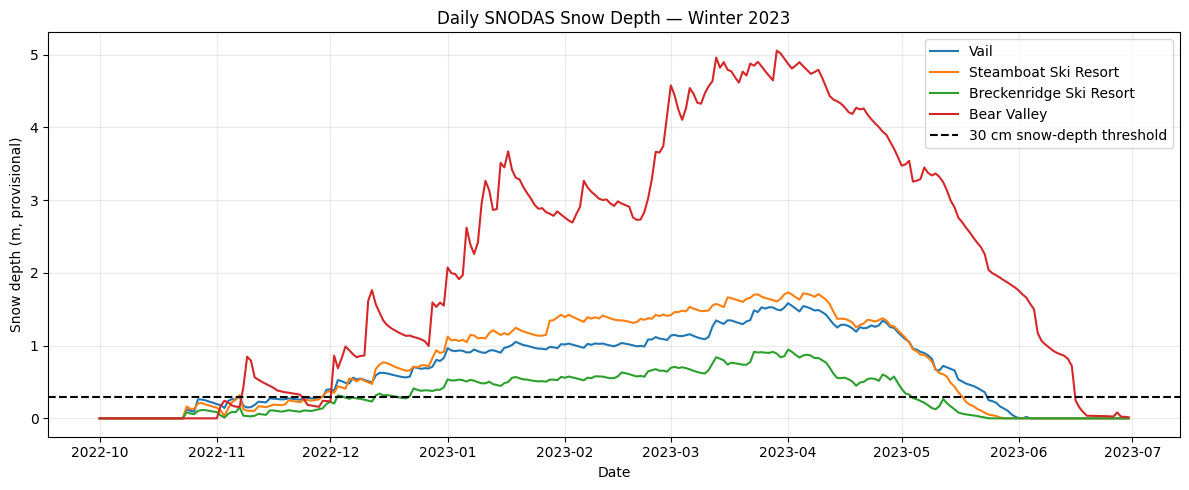

In [102]:

import matplotlib.pyplot as plt

# Find available resort names
print(
    daily[
        daily["resort_name"].str.contains(
            "Vail|Steamboat|Breckenridge|Bear Valley",
            case=False,
            na=False
        )
    ]["resort_name"].unique()
)

# Plot selected resorts
selected = [
    "Vail",
    "Steamboat",
    "Breckenridge",
    "Bear Valley"
]

fig, ax = plt.subplots(figsize=(12, 5))

for name in selected:
    subset = daily[
        daily["resort_name"].str.contains(
            name, case=False, na=False
        )
    ].sort_values("date")

    if not subset.empty:
        ax.plot(
            subset["date"],
            subset["mean"],
            label=subset["resort_name"].iloc[0]
        )

ax.axhline(
    0.30,
    color="black",
    linestyle="--",
    label="30 cm snow-depth threshold"
)

ax.set_title("Daily SNODAS Snow Depth — Winter 2023")
ax.set_ylabel("Snow depth (m, provisional)")
ax.set_xlabel("Date")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


In [103]:

import pandas as pd
import numpy as np

results = []

for resort_id, group in daily.groupby("resort_id"):

    group = group.sort_values("date").copy()

    # 7-day centered rolling average snow depth
    group["depth_7d"] = (
        group["mean"]
        .rolling(window=7, center=True, min_periods=7)
        .mean()
    )

    sustained = group["depth_7d"] >= 0.30

    # First and last qualifying dates
    dates = group.loc[sustained, "date"]

    if len(dates) > 0:
        start = dates.min()
        end = dates.max()
        season_length = (end - start).days + 1
    else:
        start = pd.NaT
        end = pd.NaT
        season_length = 0

    # Longest consecutive period >=30 cm
    above = (group["mean"] >= 0.30).fillna(False)
    runs = above.ne(above.shift()).cumsum()

    longest = (
        above.groupby(runs).sum().max()
        if len(above) else 0
    )

    results.append({
        "resort_id": resort_id,
        "resort_name": group["resort_name"].iloc[0],
        "winter_year": 2023,
        "season_start": start,
        "season_end": end,
        "season_length_days": season_length,
        "longest_continuous_days": int(longest),
        "total_snow_days_30cm": int(above.sum())
    })

season_2023 = pd.DataFrame(results)

display(
    season_2023[
        season_2023["resort_name"].str.contains(
            "Vail|Steamboat|Breckenridge|Bear Valley",
            case=False,
            na=False
        )
    ].sort_values("resort_name")
)

print("\nSeason length summary:")
print(season_2023["season_length_days"].describe())


,resort_id,resort_name,winter_year,season_start,season_end,season_length_days,longest_continuous_days,total_snow_days_30cm
84,f357cc18ead38a393c55cf27921fe05913dc33e1,Bear Valley,2023,2022-11-06,2023-06-16,223,196,212
16,27206747b07d41c64659c2ffd8753c554127752d,Breckenridge Ski Resort,2023,2022-12-15,2023-05-03,140,133,140
28,5267096488ef4504f32f94de066e28cd88b7830e,Steamboat Ski Resort,2023,2022-11-29,2023-05-17,170,170,171
43,88a22ba23468cf120025366ef40f004c9043546e,Vail,2023,2022-11-28,2023-05-23,177,175,176



Season length summary:
count     91.000000
mean     192.648352
std       32.995748
min       82.000000
25%      166.000000
50%      200.000000
75%      220.000000
max      245.000000
Name: season_length_days, dtype: float64


In [104]:

import pandas as pd
import numpy as np

def calculate_persistent_season(group, threshold=0.30, persistence=14):

    group = group.sort_values("date").copy()

    above = group["mean"] >= threshold

    # Identify consecutive runs above the threshold
    run_id = above.ne(above.shift()).cumsum()

    runs = (
        group.assign(above=above, run_id=run_id)
        .groupby("run_id")
        .agg(
            start=("date", "min"),
            end=("date", "max"),
            days=("date", "count"),
            above=("above", "first")
        )
    )

    # Only keep sustained snowpack periods
    sustained = runs[
        (runs["above"]) &
        (runs["days"] >= persistence)
    ]

    if sustained.empty:
        return pd.Series({
            "season_start": pd.NaT,
            "season_end": pd.NaT,
            "season_length_days": 0
        })

    start = sustained["start"].min()
    end = sustained["end"].max()

    return pd.Series({
        "season_start": start,
        "season_end": end,
        "season_length_days": (end - start).days + 1
    })

persistent_2023 = (
    daily.groupby(["resort_id", "resort_name"])
    .apply(
        calculate_persistent_season,
        include_groups=False
    )
    .reset_index()
)

display(
    persistent_2023[
        persistent_2023["resort_name"].str.contains(
            "Vail|Steamboat|Breckenridge|Bear Valley",
            case=False,
            na=False
        )
    ].sort_values("resort_name")
)

print("\nPersistent season summary:")
print(persistent_2023["season_length_days"].describe())


,resort_id,resort_name,season_start,season_end,season_length_days
84,f357cc18ead38a393c55cf27921fe05913dc33e1,Bear Valley,2022-11-08,2023-06-15,220
16,27206747b07d41c64659c2ffd8753c554127752d,Breckenridge Ski Resort,2022-12-22,2023-05-03,133
28,5267096488ef4504f32f94de066e28cd88b7830e,Steamboat Ski Resort,2022-11-29,2023-05-17,170
43,88a22ba23468cf120025366ef40f004c9043546e,Vail,2022-11-30,2023-05-23,175



Persistent season summary:
count     91.000000
mean     186.461538
std       36.813436
min       46.000000
25%      165.500000
50%      191.000000
75%      216.000000
max      249.000000
Name: season_length_days, dtype: float64


In [105]:

# Examine the longest and shortest persistent seasons

print("10 longest seasons:")
display(
    persistent_2023[
        ["resort_name", "season_start",
         "season_end", "season_length_days"]
    ].sort_values(
        "season_length_days", ascending=False
    ).head(10)
)

print("\n10 shortest seasons:")
display(
    persistent_2023[
        ["resort_name", "season_start",
         "season_end", "season_length_days"]
    ].sort_values(
        "season_length_days"
    ).head(10)
)

# Check daily coverage and missing depth values
coverage = daily.groupby("resort_id").agg(
    observations=("date", "count"),
    unique_dates=("date", "nunique"),
    missing_depth=("mean", lambda x: x.isna().sum())
)

print("\nDaily coverage:")
print(coverage.describe())

print("\nMissing calendar dates:")
expected_dates = pd.date_range(
    "2022-10-01", "2023-06-30", freq="D"
)

missing_dates = expected_dates.difference(
    pd.DatetimeIndex(daily["date"].unique())
)

print(list(missing_dates.strftime("%Y-%m-%d")))


10 longest seasons:


,resort_name,season_start,season_end,season_length_days
72,Mt Baker,2022-10-25,2023-06-30,249
45,Snowbird,2022-10-27,2023-06-30,247
20,Alta Ski Area,2022-10-27,2023-06-30,247
11,Dodge Ridge Ski Area,2022-11-08,2023-06-30,235
69,Mt. Shasta Ski Park,2022-11-08,2023-06-29,234
81,Mt. Hood Meadows Ski Resort,2022-11-06,2023-06-24,231
52,Brighton Resort,2022-11-03,2023-06-18,228
3,Wolf Creek Ski Area,2022-11-04,2023-06-18,227
13,Loveland Basin Ski Area,2022-11-05,2023-06-18,226
88,Sugar Bowl Resort,2022-11-08,2023-06-18,223



10 shortest seasons:


,resort_name,season_start,season_end,season_length_days
30,Snow Summit,2023-02-23,2023-04-09,46
19,Great Divide Ski Area,2023-02-19,2023-04-29,70
47,Granby Ranch,2022-12-31,2023-04-13,104
79,Nordic Valley Resort (Wolf Mountain),2022-12-31,2023-05-04,125
65,Red Lodge Mountain,2023-01-19,2023-05-25,127
55,Buttermilk,2022-12-29,2023-05-09,132
54,Powderhorn,2022-12-28,2023-05-09,133
16,Breckenridge Ski Resort,2022-12-22,2023-05-03,133
33,Purgatory Resort,2022-12-29,2023-05-15,138
90,Bridger Bowl,2022-12-13,2023-05-02,141



Daily coverage:
       observations  unique_dates  missing_depth
count          91.0          91.0           91.0
mean          273.0         273.0            0.0
std             0.0           0.0            0.0
min           273.0         273.0            0.0
25%           273.0         273.0            0.0
50%           273.0         273.0            0.0
75%           273.0         273.0            0.0
max           273.0         273.0            0.0

Missing calendar dates:
[]


In [106]:

# Compare 7-, 14-, and 21-day persistence definitions

comparison = None

for days in [7, 14, 21]:
    result = (
        daily.groupby(["resort_id", "resort_name"])
        .apply(
            calculate_persistent_season,
            threshold=0.30,
            persistence=days,
            include_groups=False
        )
        .reset_index()
    )

    result = result.rename(columns={
        "season_start": f"start_{days}d",
        "season_end": f"end_{days}d",
        "season_length_days": f"length_{days}d"
    })

    if comparison is None:
        comparison = result
    else:
        comparison = comparison.merge(
            result,
            on=["resort_id", "resort_name"]
        )

# Compare four example resorts
display(
    comparison[
        comparison["resort_name"].str.contains(
            "Vail|Steamboat|Breckenridge|Bear Valley",
            case=False,
            na=False
        )
    ][[
        "resort_name",
        "length_7d",
        "length_14d",
        "length_21d",
        "start_21d",
        "end_21d"
    ]].sort_values("resort_name")
)

# Summary across all 91 resorts
print("\nSeason length comparison:")
print(
    comparison[
        ["length_7d", "length_14d", "length_21d"]
    ].describe().round(1)
)

# Identify resorts most affected by 21-day requirement
comparison["change_14_to_21"] = (
    comparison["length_21d"] -
    comparison["length_14d"]
)

print("\nLargest reductions from 14 to 21 days:")
display(
    comparison[
        ["resort_name", "length_14d",
         "length_21d", "change_14_to_21"]
    ].sort_values("change_14_to_21").head(10)
)


,resort_name,length_7d,length_14d,length_21d,start_21d,end_21d
84,Bear Valley,220,220,196,2022-12-02,2023-06-15
16,Breckenridge Ski Resort,133,133,133,2022-12-22,2023-05-03
28,Steamboat Ski Resort,170,170,170,2022-11-29,2023-05-17
43,Vail,175,175,175,2022-11-30,2023-05-23



Season length comparison:
       length_7d  length_14d  length_21d
count       91.0        91.0        91.0
mean       188.7       186.5       182.9
std         34.9        36.8        38.4
min         70.0        46.0         0.0
25%        165.5       165.5       165.5
50%        192.0       191.0       191.0
75%        217.5       216.0       208.0
max        249.0       249.0       249.0

Largest reductions from 14 to 21 days:


,resort_name,length_14d,length_21d,change_14_to_21
30,Snow Summit,46,0,-46
88,Sugar Bowl Resort,223,199,-24
37,Kirkwood Mountain Resort,220,196,-24
4,Sierra-at-Tahoe Ski Resort,220,196,-24
84,Bear Valley,220,196,-24
11,Dodge Ridge Ski Area,235,211,-24
15,June Mountain,219,196,-23
49,China Peak Mountain Resort,217,195,-22
12,Montana Snowbowl,190,168,-22
87,Palisades Tahoe Olympic Valley,218,197,-21


In [107]:

# Check snowpack remaining at the end of the extraction window

last_day = daily["date"].max()

end_depth = (
    daily[daily["date"] == last_day]
    [["resort_name", "mean"]]
    .sort_values("mean", ascending=False)
)

print("Last observation:", last_day.date())

print("\nResorts with at least 30 cm remaining:")
remaining = end_depth[end_depth["mean"] >= 0.30]

print("Count:", len(remaining))
display(remaining)

print("\nResorts with at least 10 cm remaining:")
print((end_depth["mean"] >= 0.10).sum())


Last observation: 2023-06-30

Resorts with at least 30 cm remaining:
Count: 4


,resort_name,mean
24754,Dodge Ridge Ski Area,0.956480
24836,Mt Baker,0.642951
24829,Snowbird,0.548619
24819,Alta Ski Area,0.477506



Resorts with at least 10 cm remaining:
6


In [109]:

import pandas as pd

resorts = pd.read_csv("inputs/ski_resorts/resort_sample_91.csv")

print("Columns:", resorts.columns.tolist())

display(
    resorts[
        resorts["name"].str.contains(
            "Vail|Breckenridge|Steamboat|Bear Valley|Snowbird|Alta|Mt Baker|Dodge Ridge",
            case=False,
            na=False
        )
    ][["name", "lat", "lng"]].sort_values("name")
)


Columns: ['id', 'name', 'regions', 'lat', 'lng', 'vertical_m', 'downhill_distance_km', 'geometry', 'openskimap', 'nsaa_region']


,name,lat,lng
67,Alta Ski Area,40.573361,-111.635515
0,Bear Valley,38.482607,-120.050297
20,Breckenridge Ski Resort,39.472250,-106.065712
2,Dodge Ridge Ski Area,38.189917,-119.939334
84,Mt Baker,48.857115,-121.665157
77,Snowbird,40.571480,-111.640991
33,Steamboat Ski Resort,40.460962,-106.776852
36,Vail,39.623789,-106.365457


In [110]:

# Inspect OpenSkiMap geometry and metadata

print("Example geometry:")
print(str(resorts.loc[0, "geometry"])[:1200])

print("\nExample OpenSkiMap reference:")
print(resorts.loc[0, "openskimap"])

print("\nExample region:")
print(resorts.loc[0, "regions"])

print("\nMissing values:")
print(
    resorts[
        ["geometry", "openskimap", "vertical_m"]
    ].isna().sum()
)


Example geometry:
Polygon

Example OpenSkiMap reference:
https://openskimap.org/?obj=f357cc18ead38a393c55cf27921fe05913dc33e1

Example region:
California

Missing values:
geometry      0
openskimap    0
vertical_m    0
dtype: int64


In [112]:

import pandas as pd

files = [
    "resort_downhill_runs.csv",
    "runs.csv",
    "resort_terrain_variables.csv",
    "resort_downhill_summary.csv"
]

for filename in files:
    path = f"inputs/ski_resorts/{filename}"
    df = pd.read_csv(path, nrows=3)

    print(f"\n{'=' * 60}")
    print(filename)
    print("Columns:", df.columns.tolist())
    display(df.head(2))



resort_downhill_runs.csv
Columns: ['name_run', 'ref', 'countries', 'regions_run', 'localities', 'ski_area_names', 'difficulty', 'color', 'oneway', 'lit', 'gladed', 'patrolled', 'grooming', 'uses', 'inclined_length_m', 'descent_m', 'ascent_m', 'average_pitch_%', 'max_pitch_%', 'min_elevation_m', 'max_elevation_m', 'difficulty_convention', 'wikidata_id', 'websites', 'openskimap', 'id_run', 'geometry', 'lat', 'lng', 'ski_area_ids', 'sources', 'description', 'id_resort', 'name_resort', 'regions_resort', 'nsaa_region', 'resort_lat', 'resort_lng', 'distance_km']


,name_run,ref,countries,regions_run,localities,ski_area_names,difficulty,color,oneway,lit,...,ski_area_ids,sources,description,id_resort,name_resort,regions_resort,nsaa_region,resort_lat,resort_lng,distance_km
0,Tude Dude's Terrain Park,NaN,United States,Utah,NaN,Solitude Mountain Resort,easy,green,NaN,NaN,...,b40e925163e2330550f940711b8571409fafb3a4,https://www.openstreetmap.org/way/1341930155,NaN,b40e925163e2330550f940711b8571409fafb3a4,Solitude Mountain Resort,Utah,Rocky Mountain,40.614572,-111.600985,0.560694
1,Freefall Glade,NaN,United States,Colorado,Copper Mountain,Copper Mountain,advanced,black,yes,NaN,...,0bab3102857cf4c7243d3db844c283a24413fa28,https://www.openstreetmap.org/way/87103625,NaN,0bab3102857cf4c7243d3db844c283a24413fa28,Copper Mountain,Colorado,Rocky Mountain,39.491493,-106.158353,1.143080



runs.csv
Columns: ['name', 'ref', 'countries', 'regions', 'localities', 'ski_area_names', 'difficulty', 'color', 'oneway', 'lit', 'gladed', 'patrolled', 'grooming', 'uses', 'inclined_length_m', 'descent_m', 'ascent_m', 'average_pitch_%', 'max_pitch_%', 'min_elevation_m', 'max_elevation_m', 'difficulty_convention', 'wikidata_id', 'websites', 'openskimap', 'id', 'geometry', 'lat', 'lng', 'ski_area_ids', 'sources', 'description']


,name,ref,countries,regions,localities,ski_area_names,difficulty,color,oneway,lit,...,wikidata_id,websites,openskimap,id,geometry,lat,lng,ski_area_ids,sources,description
0,Burenwald,34.0,Switzerland,Saint Gallen,Unterwasser,NaN,freeride,orange,yes,NaN,...,NaN,NaN,https://openskimap.org/?obj=000023a20c6114a6ff...,000023a20c6114a6ffa43c9cd405083dfa79446e,LineString,47.190203,9.310158,NaN,https://www.openstreetmap.org/way/32791237,NaN
1,中央ゲレンデ,NaN,Japan,Fukushima Prefecture,NaN,"猪苗代スキー場, Inawashiro Snow Paradise",novice,green,yes,yes,...,NaN,NaN,https://openskimap.org/?obj=00003d10c6b2ff12a4...,00003d10c6b2ff12a40363821b2b365895590edc,LineString,37.578345,140.091578,68cdd4737546eae7847ae81dc2db65e3257d2345,https://www.openstreetmap.org/way/227239782,NaN



resort_terrain_variables.csv
Columns: ['resort_id', 'resort_name', 'elevation_mean_m', 'slope_mean_deg', 'north_facing_share', 'northness', 'eastness']


,resort_id,resort_name,elevation_mean_m,slope_mean_deg,north_facing_share,northness,eastness
0,01fc91766cf1ba8156fdc3d233e90205b0dd3001,Palisades Tahoe Alpine Meadows,2325.545823,19.679928,0.244295,0.043958,0.185245
1,03b56bd47b26c384d82474a2fb4b3fbc3a0c4a31,Aspen Snowmass,3022.142467,15.429535,0.730705,0.738123,0.067961



resort_downhill_summary.csv
Columns: ['id', 'name', 'regions', 'nsaa_region', 'n_downhill_runs']


,id,name,regions,nsaa_region,n_downhill_runs
0,f357cc18ead38a393c55cf27921fe05913dc33e1,Bear Valley,California,Pacific Southwest,62
1,9e118f4eb36fb34e987c7a3ddd7f2d976b6a7443,China Peak Mountain Resort,California,Pacific Southwest,108


In [113]:

import pandas as pd

runs = pd.read_csv(
    "inputs/ski_resorts/resort_downhill_runs.csv"
)

examples = [
    "Vail",
    "Breckenridge Ski Resort",
    "Steamboat Ski Resort",
    "Bear Valley",
    "Snowbird",
    "Alta Ski Area",
    "Mt Baker",
    "Dodge Ridge Ski Area"
]

for resort in examples:
    subset = runs[
        runs["name_resort"] == resort
    ].copy()

    subset["min_elevation_m"] = pd.to_numeric(
        subset["min_elevation_m"],
        errors="coerce"
    )

    print(f"\n{resort} — {len(subset)} mapped runs")

    display(
        subset.sort_values("min_elevation_m")[
            [
                "name_run",
                "min_elevation_m",
                "max_elevation_m",
                "lat",
                "lng",
                "distance_km"
            ]
        ].head(8)
    )



Vail — 324 mapped runs


,name_run,min_elevation_m,max_elevation_m,lat,lng,distance_km
8891,Cascade Way,2452.0,2588.0,39.639148,-106.397266,3.215162
3508,Born Free,2467.0,2481.0,39.642083,-106.388412,2.828829
849,NaN,2476.0,2476.0,39.642756,-106.388173,2.869189
234,NaN,2476.0,2476.0,39.642778,-106.388120,2.867914
133,Born Free,2481.0,2537.0,39.640012,-106.387502,2.611171
7612,NaN,2495.0,2497.0,39.639217,-106.373676,1.854296
4471,Vail Village Catwalk - Lower,2497.0,2546.0,39.639104,-106.376732,1.957643
7570,Head First,2497.0,2649.0,39.636560,-106.374176,1.604416



Breckenridge Ski Resort — 167 mapped runs


,name_run,min_elevation_m,max_elevation_m,lat,lng,distance_km
4296,Gondola Ski Back,2918.0,2942.0,39.483928,-106.050529,1.839653
8378,Lowest 4 O'Clock,2924.0,2956.0,39.480334,-106.050787,1.564933
8112,Lower Sawmill,2935.0,2961.0,39.474274,-106.049535,1.406653
7450,Silverthorne,2936.0,3014.0,39.473595,-106.049646,1.387098
4829,Lower Sawmill,2937.0,2941.0,39.475600,-106.047934,1.570746
7704,Gondola Ski Back,2939.0,2946.0,39.482830,-106.051919,1.668974
7636,Gondola Ski Back,2946.0,2971.0,39.481066,-106.052897,1.473353
6287,Lower 4 O'Clock,2955.0,3261.0,39.476166,-106.062642,0.508962



Steamboat Ski Resort — 199 mapped runs


,name_run,min_elevation_m,max_elevation_m,lat,lng,distance_km
8458,Right-o-Way,2102.0,2261.0,40.461397,-106.795563,1.583730
2469,Stampede,2108.0,2180.0,40.458220,-106.799986,1.980839
1580,Lil' Rodeo Park,2108.0,2163.0,40.458483,-106.800098,1.985929
6897,Wild Blue Way,2109.0,2160.0,40.458862,-106.801110,2.065560
70,Headwall,2149.0,2184.0,40.459671,-106.797250,1.731698
4105,Ski-in/ski-out access trail,2169.0,2175.0,40.461189,-106.797285,1.728864
8296,Short Cut,2180.0,2258.0,40.460686,-106.793220,1.385116
356,See Me,2184.0,2363.0,40.458335,-106.792327,1.341440


... (6 outputs left out)


Mt Baker — 47 mapped runs


,name_run,min_elevation_m,max_elevation_m,lat,lng,distance_km
541,Expresso,1106.0,1283.0,48.857974,-121.654165,0.809815
8190,NaN,1113.0,1117.0,48.857525,-121.660479,0.345262
5514,NaN,1115.0,1117.0,48.857791,-121.659913,0.390940
3678,Honkers,1115.0,1178.0,48.857796,-121.662321,0.220866
4008,Lower White Salmon,1117.0,1234.0,48.857535,-121.656790,0.613902
8945,Cat Track,1117.0,1219.0,48.857799,-121.662156,0.232351
2769,Nosedive,1117.0,1375.0,48.855422,-121.657408,0.597361
5714,NaN,1144.0,1180.0,48.855684,-121.662898,0.229419



Dodge Ridge Ski Area — 64 mapped runs


,name_run,min_elevation_m,max_elevation_m,lat,lng,distance_km
2028,Low Road,2002.0,2050.0,38.189375,-119.953331,1.224762
6604,Ego Alley,2003.0,2121.0,38.185984,-119.953819,1.339367
3900,Ry's Run,2006.0,2210.0,38.186543,-119.952467,1.207550
6177,Gentle Ben,2006.0,2080.0,38.187458,-119.956462,1.521701
3536,Clementine,2028.0,2078.0,38.187910,-119.950857,1.031502
3609,Bone Yard,2034.0,2185.0,38.187345,-119.948901,0.883685
3977,Lower Gold Nugget,2052.0,2134.0,38.187833,-119.946230,0.645702
3332,Lower Stagecoach,2055.0,2291.0,38.191517,-119.944728,0.503861


In [114]:

import pandas as pd
from pathlib import Path

path = Path("inputs/ski_resorts/ski_areas.csv")
ski_areas = pd.read_csv(path, nrows=3)

print("Ski area columns:")
print(ski_areas.columns.tolist())

print("\nPotential lift-related files:")
for path in Path("inputs").rglob("*"):
    if path.is_file() and any(
        term in path.name.lower()
        for term in ["lift", "station", "aerialway", "base"]
    ):
        print(path)


Ski area columns:
['name', 'countries', 'regions', 'localities', 'status', 'has_downhill', 'has_nordic', 'downhill_distance_km', 'nordic_distance_km', 'vertical_m', 'min_elevation_m', 'max_elevation_m', 'lift_count', 'surface_lifts_count', 'run_convention', 'wikidata_id', 'websites', 'openskimap', 'id', 'geometry', 'lat', 'lng', 'sources']

Potential lift-related files:


In [115]:

# Compare reported resort minimum elevations
# with minimum elevations of matched downhill runs

areas = pd.read_csv("inputs/ski_resorts/ski_areas.csv")

area_elevations = areas[
    ["id", "name", "min_elevation_m", "max_elevation_m", "lift_count"]
].rename(columns={
    "id": "resort_id",
    "name": "resort_name",
    "min_elevation_m": "area_min_m",
    "max_elevation_m": "area_max_m"
})

run_elevations = (
    runs.groupby("id_resort")["min_elevation_m"]
    .min()
    .reset_index()
    .rename(columns={
        "id_resort": "resort_id",
        "min_elevation_m": "lowest_run_m"
    })
)

elevation_check = area_elevations.merge(
    run_elevations,
    on="resort_id",
    how="inner"
)

elevation_check["difference_m"] = (
    elevation_check["lowest_run_m"] -
    elevation_check["area_min_m"]
)

examples = [
    "Vail", "Breckenridge Ski Resort",
    "Steamboat Ski Resort", "Bear Valley",
    "Snowbird", "Alta Ski Area",
    "Mt Baker", "Dodge Ridge Ski Area"
]

display(
    elevation_check[
        elevation_check["resort_name"].isin(examples)
    ][[
        "resort_name", "area_min_m",
        "lowest_run_m", "difference_m", "lift_count"
    ]].sort_values("resort_name")
)

print("\nElevation differences across matched resorts:")
print(elevation_check["difference_m"].describe())


,resort_name,area_min_m,lowest_run_m,difference_m,lift_count
20,Alta Ski Area,2602.0,2483.0,-119.0,11.0
84,Bear Valley,2024.0,2024.0,0.0,9.0
16,Breckenridge Ski Resort,2918.0,2918.0,0.0,35.0
11,Dodge Ridge Ski Area,2002.0,2002.0,0.0,11.0
72,Mt Baker,1106.0,1106.0,0.0,10.0
45,Snowbird,2365.0,2359.0,-6.0,14.0
28,Steamboat Ski Resort,2102.0,2102.0,0.0,24.0
43,Vail,2452.0,2452.0,0.0,32.0



Elevation differences across matched resorts:
count     91.000000
mean      -4.593407
std       18.293884
min     -119.000000
25%        0.000000
50%        0.000000
75%        0.000000
max        7.000000
Name: difference_m, dtype: float64


In [116]:

# Identify runs within 100 m of each resort's minimum elevation

base_candidates = runs.merge(
    area_elevations[["resort_id", "area_min_m"]],
    left_on="id_resort",
    right_on="resort_id",
    how="left"
)

base_candidates["elevation_above_min"] = (
    base_candidates["min_elevation_m"]
    - base_candidates["area_min_m"]
)

base_candidates = base_candidates[
    base_candidates["elevation_above_min"].between(0, 100)
].copy()

counts = (
    base_candidates.groupby("name_resort")
    .size()
    .rename("n_base_candidate_runs")
)

print("Candidate runs per resort:")
print(counts.describe())

print("\nExample resorts:")
display(
    counts.reindex([
        "Vail",
        "Breckenridge Ski Resort",
        "Steamboat Ski Resort",
        "Bear Valley",
        "Snowbird",
        "Alta Ski Area",
        "Mt Baker",
        "Dodge Ridge Ski Area"
    ])
)

print("\nResorts with no candidate runs:")
print(
    sorted(
        set(runs["name_resort"].dropna())
        - set(counts.index)
    )
)


Candidate runs per resort:
count    91.000000
mean     18.780220
std      10.830822
min       1.000000
25%      11.000000
50%      16.000000
75%      28.000000
max      51.000000
Name: n_base_candidate_runs, dtype: float64

Example resorts:


name_resort
Vail                       28
Breckenridge Ski Resort    20
Steamboat Ski Resort       13
Bear Valley                 2
Snowbird                   23
Alta Ski Area              29
Mt Baker                   16
Dodge Ridge Ski Area       16
Name: n_base_candidate_runs, dtype: int64


Resorts with no candidate runs:
[]


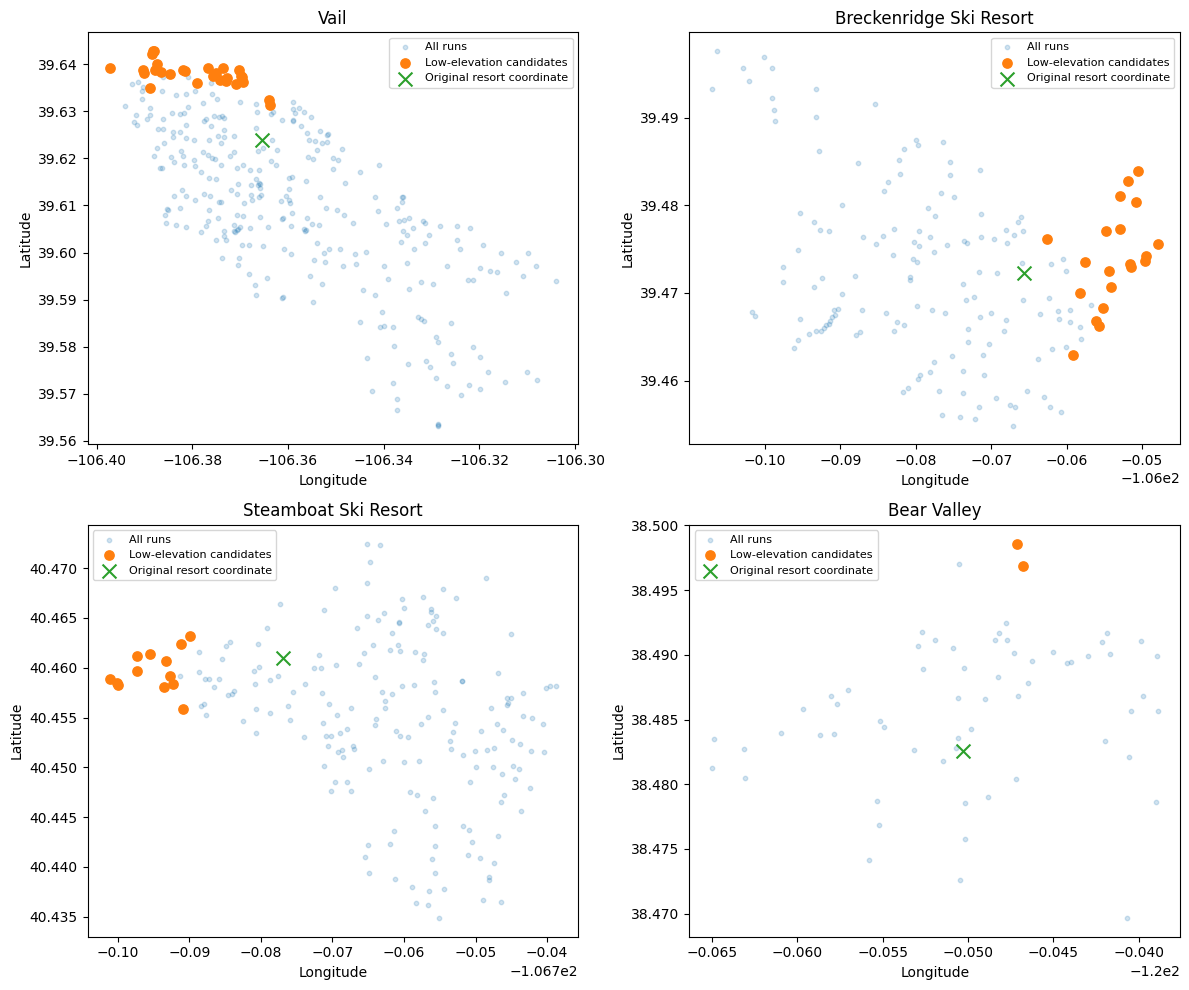

In [117]:

import matplotlib.pyplot as plt

examples = [
    "Vail",
    "Breckenridge Ski Resort",
    "Steamboat Ski Resort",
    "Bear Valley"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, resort in zip(axes.flat, examples):
    all_runs = runs[runs["name_resort"] == resort]
    low_runs = base_candidates[
        base_candidates["name_resort"] == resort
    ]
    original = resorts[resorts["name"] == resort]

    ax.scatter(
        all_runs["lng"], all_runs["lat"],
        s=10, alpha=0.2, label="All runs"
    )
    ax.scatter(
        low_runs["lng"], low_runs["lat"],
        s=45, label="Low-elevation candidates"
    )

    if not original.empty:
        ax.scatter(
            original["lng"], original["lat"],
            marker="x", s=100,
            label="Original resort coordinate"
        )

    ax.set_title(resort)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()


In [118]:

import numpy as np

candidate_centers = (
    base_candidates.groupby(["id_resort", "name_resort"])
    .agg(
        base_lat=("lat", "median"),
        base_lng=("lng", "median"),
        n_candidates=("lat", "count")
    )
    .reset_index()
)

original_points = resorts[
    ["id", "lat", "lng"]
].rename(columns={
    "id": "id_resort",
    "lat": "original_lat",
    "lng": "original_lng"
})

candidate_centers = candidate_centers.merge(
    original_points,
    on="id_resort",
    how="left"
)

# Haversine distance in kilometers
lat1 = np.radians(candidate_centers["original_lat"])
lon1 = np.radians(candidate_centers["original_lng"])
lat2 = np.radians(candidate_centers["base_lat"])
lon2 = np.radians(candidate_centers["base_lng"])

a = (
    np.sin((lat2 - lat1) / 2)**2
    + np.cos(lat1) * np.cos(lat2)
    * np.sin((lon2 - lon1) / 2)**2
)

candidate_centers["distance_from_original_km"] = (
    6371 * 2 * np.arcsin(np.sqrt(a))
)

print("Distance from original resort coordinates:")
print(candidate_centers["distance_from_original_km"].describe())

print("\nExample resorts:")
display(
    candidate_centers[
        candidate_centers["name_resort"].isin([
            "Vail", "Breckenridge Ski Resort",
            "Steamboat Ski Resort", "Bear Valley"
        ])
    ][[
        "name_resort", "n_candidates",
        "base_lat", "base_lng",
        "distance_from_original_km"
    ]].sort_values("name_resort")
)


Distance from original resort coordinates:
count    91.000000
mean      1.143890
std       0.816483
min       0.142457
25%       0.570676
50%       0.902769
75%       1.585109
max       3.887578
Name: distance_from_original_km, dtype: float64

Example resorts:


,name_resort,n_candidates,base_lat,base_lng,distance_from_original_km
84,Bear Valley,2,38.497720,-120.046980,1.705153
16,Breckenridge Ski Resort,20,39.473559,-106.053498,1.058435
28,Steamboat Ski Resort,13,40.459132,-106.793476,1.421095
43,Vail,28,39.638144,-106.377882,1.918403


In [119]:

from IPython.display import display, HTML

examples = [
    "Vail",
    "Breckenridge Ski Resort",
    "Steamboat Ski Resort",
    "Bear Valley"
]

for name in examples:
    row = candidate_centers[
        candidate_centers["name_resort"] == name
    ].iloc[0]

    lat, lng = row["base_lat"], row["base_lng"]

    url = (
        f"https://www.google.com/maps/@"
        f"{lat},{lng},16z/data=!3m1!1e3"
    )

    display(HTML(
        f'<a href="{url}" target="_blank">'
        f'{name} — satellite view</a>'
    ))


In [120]:

# Create a base-area sampling dataset for all 91 resorts

base_points = resorts[
    ["id", "name", "lat", "lng", "regions", "nsaa_region"]
].merge(
    candidate_centers[
        ["id_resort", "base_lat", "base_lng",
         "n_candidates", "distance_from_original_km"]
    ],
    left_on="id",
    right_on="id_resort",
    how="left",
    validate="one_to_one"
)

base_points = base_points.rename(columns={
    "lat": "original_lat",
    "lng": "original_lng"
}).drop(columns="id_resort")

assert len(base_points) == 91
assert base_points[["base_lat", "base_lng"]].notna().all().all()

output = "inputs/ski_resorts/resort_base_points_91.csv"
base_points.to_csv(output, index=False)

print("Saved:", output)
print("Resorts:", len(base_points))
print("Missing coordinates:",
      base_points[["base_lat", "base_lng"]].isna().sum().sum())

display(base_points.head())


Saved: inputs/ski_resorts/resort_base_points_91.csv
Resorts: 91
Missing coordinates: 0


,id,name,original_lat,original_lng,regions,nsaa_region,base_lat,base_lng,n_candidates,distance_from_original_km
0,f357cc18ead38a393c55cf27921fe05913dc33e1,Bear Valley,38.482607,-120.050297,California,Pacific Southwest,38.497720,-120.046980,2,1.705153
1,9e118f4eb36fb34e987c7a3ddd7f2d976b6a7443,China Peak Mountain Resort,37.226440,-119.158053,California,Pacific Southwest,37.231632,-119.157166,29,0.582641
2,162525ff9a2a65810a602b74f338303d1bb9ea38,Dodge Ridge Ski Area,38.189917,-119.939334,California,Pacific Southwest,38.186411,-119.950849,16,1.079253
3,f3545b1a07aba1aff23c5cb645c24225d9eea12a,Homewood Ski Area,39.078191,-120.169056,California,Pacific Southwest,39.081398,-120.164791,10,0.512576
4,1f94daed2b308fa325be064eebc82535fcc3861b,June Mountain,37.753661,-119.075663,California,Pacific Southwest,37.765351,-119.087534,5,1.666944


In [121]:

import ee
import pandas as pd

# Initialize Earth Engine
ee.Reset()
ee.Initialize(project="fdos-491217")

# Load our new base-area coordinates
base_points = pd.read_csv(
    "inputs/ski_resorts/resort_base_points_91.csv"
)

# Create 500 m buffers around base-area coordinates
base_features = []

for _, row in base_points.iterrows():
    point = ee.Geometry.Point([
        float(row["base_lng"]),
        float(row["base_lat"])
    ])

    base_features.append(
        ee.Feature(
            point.buffer(500),
            {
                "resort_id": str(row["id"]),
                "resort_name": str(row["name"])
            }
        )
    )

base_fc = ee.FeatureCollection(base_features)

# Load daily SNODAS
snodas = ee.ImageCollection(
    "projects/climate-engine/snodas/daily"
)

print("Base-area resorts:", base_fc.size().getInfo())
print(
    "SNODAS images for winter 2023:",
    snodas.filterDate(
        "2022-10-01", "2023-07-01"
    ).size().getInfo()
)


Base-area resorts: 91
SNODAS images for winter 2023: 273


In [122]:

# Export daily SNODAS snow depth at resort base areas

year = 2023

collection = snodas.filterDate(
    f"{year-1}-10-01",
    f"{year}-07-01"
)

def extract_base_day(image):
    date = image.date().format("YYYY-MM-dd")

    sampled = image.select("Snow_Depth").reduceRegions(
        collection=base_fc,
        reducer=ee.Reducer.mean(),
        scale=1000
    )

    return sampled.map(
        lambda feature: feature.set({
            "date": date,
            "winter_year": year
        })
    )

daily_base_collection = collection.map(
    extract_base_day
).flatten()

task_base_2023 = ee.batch.Export.table.toDrive(
    collection=daily_base_collection,
    description="resort_snodas_base_daily_2023",
    folder="ski_thesis_snodas_daily",
    fileNamePrefix="resort_snodas_base_daily_2023",
    fileFormat="CSV",
    selectors=[
        "resort_id",
        "resort_name",
        "date",
        "winter_year",
        "mean"
    ]
)

task_base_2023.start()

print("Export started.")
print("Task ID:", task_base_2023.id)
print("Status:", task_base_2023.status()["state"])


Export started.
Task ID: P2AGE4ZVPF5ANOHVVTR5U24B
Status: READY


In [123]:

# Calculate 2023 natural snow season lengths at resort bases

daily_base = pd.read_csv(
    "inputs/ski_resorts/resort_snodas_base_daily_2023.csv",
    parse_dates=["date"]
)

persistent_base_2023 = (
    daily_base.groupby(["resort_id", "resort_name"])
    .apply(
        calculate_persistent_season,
        threshold=0.30,
        persistence=14,
        include_groups=False
    )
    .reset_index()
)

# Compare original locations with base-area locations
season_comparison = persistent_2023.merge(
    persistent_base_2023,
    on="resort_id",
    suffixes=("_original", "_base"),
    validate="one_to_one"
)

season_comparison["change_days"] = (
    season_comparison["season_length_days_base"]
    - season_comparison["season_length_days_original"]
)

display(
    season_comparison[
        season_comparison["resort_name_base"].isin([
            "Vail", "Breckenridge Ski Resort",
            "Steamboat Ski Resort", "Bear Valley",
            "Snowbird", "Alta Ski Area",
            "Mt Baker", "Dodge Ridge Ski Area"
        ])
    ][[
        "resort_name_base",
        "season_length_days_original",
        "season_length_days_base",
        "change_days"
    ]].sort_values("resort_name_base")
)

print("\nAcross all 91 resorts:")
print(season_comparison["change_days"].describe().round(1))

print("\nAverage base-area season length:")
print(persistent_base_2023["season_length_days"].mean().round(1))


,resort_name_base,season_length_days_original,season_length_days_base,change_days
20,Alta Ski Area,247,239,-8
84,Bear Valley,220,220,0
16,Breckenridge Ski Resort,133,117,-16
11,Dodge Ridge Ski Area,235,229,-6
72,Mt Baker,249,239,-10
45,Snowbird,247,242,-5
28,Steamboat Ski Resort,170,158,-12
43,Vail,175,146,-29



Across all 91 resorts:
count    91.0
mean    -13.5
std      17.4
min     -68.0
25%     -26.0
50%      -8.0
75%      -1.0
max      35.0
Name: change_days, dtype: float64

Average base-area season length:
172.9


In [124]:

print("10 longest base-area seasons:")
display(
    persistent_base_2023[
        ["resort_name", "season_start",
         "season_end", "season_length_days"]
    ].sort_values(
        "season_length_days", ascending=False
    ).head(10)
)

print("\n10 shortest base-area seasons:")
display(
    persistent_base_2023[
        ["resort_name", "season_start",
         "season_end", "season_length_days"]
    ].sort_values(
        "season_length_days"
    ).head(10)
)

print("\nBase-area season length distribution:")
print(
    persistent_base_2023["season_length_days"]
    .describe().round(1)
)


10 longest base-area seasons:


,resort_name,season_start,season_end,season_length_days
45,Snowbird,2022-10-27,2023-06-25,242
72,Mt Baker,2022-11-04,2023-06-30,239
20,Alta Ski Area,2022-10-27,2023-06-22,239
69,Mt. Shasta Ski Park,2022-11-08,2023-06-28,233
88,Sugar Bowl Resort,2022-11-08,2023-06-24,229
11,Dodge Ridge Ski Area,2022-11-08,2023-06-24,229
52,Brighton Resort,2022-11-03,2023-06-15,225
13,Loveland Basin Ski Area,2022-11-05,2023-06-14,222
59,Mammoth Mountain,2022-11-08,2023-06-17,222
3,Wolf Creek Ski Area,2022-11-04,2023-06-12,221



10 shortest base-area seasons:


,resort_name,season_start,season_end,season_length_days
30,Snow Summit,2023-02-24,2023-04-07,43
19,Great Divide Ski Area,2023-02-19,2023-04-10,51
62,Discovery Ski Area,2023-01-28,2023-04-29,92
47,Granby Ranch,2022-12-31,2023-04-12,103
41,Keystone,2022-12-23,2023-04-12,111
16,Breckenridge Ski Resort,2022-12-23,2023-04-18,117
90,Bridger Bowl,2023-01-01,2023-05-01,121
2,Aspen Highlands,2022-12-29,2023-05-01,124
55,Buttermilk,2022-12-29,2023-05-01,124
79,Nordic Valley Resort (Wolf Mountain),2022-12-31,2023-05-04,125



Base-area season length distribution:
count     91.0
mean     172.9
std       38.6
min       43.0
25%      156.0
50%      171.0
75%      199.0
max      242.0
Name: season_length_days, dtype: float64


In [125]:

# Compare persistent season windows with snow-covered days

threshold = 0.30

snow_day_summary = (
    daily_base.assign(
        snow_covered=daily_base["mean"] >= threshold
    )
    .groupby(["resort_id", "resort_name"])
    .agg(
        snow_covered_days=("snow_covered", "sum"),
        maximum_depth_m=("mean", "max"),
        average_depth_m=("mean", "mean")
    )
    .reset_index()
)

season_diagnostics = persistent_base_2023.merge(
    snow_day_summary,
    on=["resort_id", "resort_name"],
    validate="one_to_one"
)

season_diagnostics["snow_days_minus_window"] = (
    season_diagnostics["snow_covered_days"]
    - season_diagnostics["season_length_days"]
)

display(
    season_diagnostics[
        [
            "resort_name",
            "season_length_days",
            "snow_covered_days",
            "snow_days_minus_window",
            "maximum_depth_m"
        ]
    ].sort_values("snow_days_minus_window").head(15)
)

print("\nAcross all resorts:")
print(
    season_diagnostics[
        ["season_length_days",
         "snow_covered_days",
         "snow_days_minus_window"]
    ].describe().round(1)
)


,resort_name,season_length_days,snow_covered_days,snow_days_minus_window,maximum_depth_m
84,Bear Valley,220,211,-9,4.865745
49,China Peak Mountain Resort,210,202,-8,4.004574
37,Kirkwood Mountain Resort,220,212,-8,4.430770
11,Dodge Ridge Ski Area,229,222,-7,4.345883
59,Mammoth Mountain,222,216,-6,4.060566
65,Red Lodge Mountain,162,158,-4,1.380021
30,Snow Summit,43,40,-3,1.147025
69,Mt. Shasta Ski Park,233,232,-1,4.615996
41,Keystone,111,111,0,0.639181
25,Lost Trail,196,196,0,1.546442



Across all resorts:
       season_length_days  snow_covered_days  snow_days_minus_window
count                91.0               91.0                    91.0
mean                172.9              176.2                     3.3
std                  38.6               37.5                     5.8
min                  43.0               40.0                    -9.0
25%                 156.0              157.0                     0.0
50%                 171.0              175.0                     2.0
75%                 199.0              202.0                     5.5
max                 242.0              243.0                    23.0


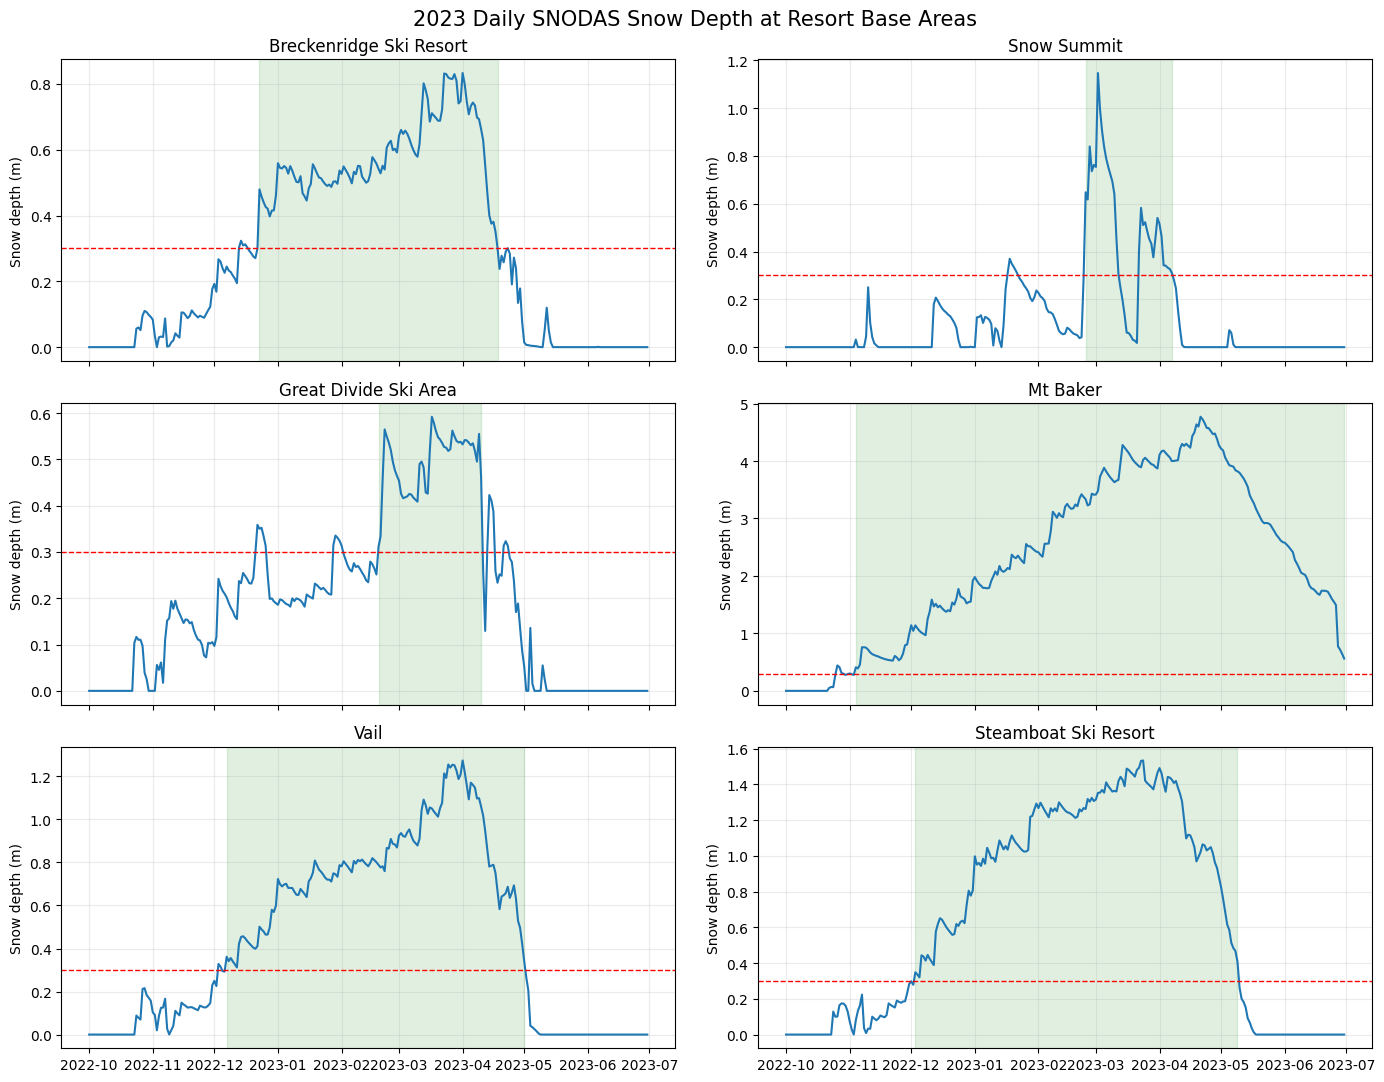

In [126]:

import matplotlib.pyplot as plt

resorts_to_plot = [
    "Breckenridge Ski Resort",
    "Snow Summit",
    "Great Divide Ski Area",
    "Mt Baker",
    "Vail",
    "Steamboat Ski Resort"
]

fig, axes = plt.subplots(
    3, 2, figsize=(14, 11), sharex=True
)

for ax, name in zip(axes.flat, resorts_to_plot):
    subset = daily_base[
        daily_base["resort_name"] == name
    ].sort_values("date")

    ax.plot(
        subset["date"],
        subset["mean"],
        linewidth=1.5
    )
    ax.axhline(
        0.30, color="red", linestyle="--",
        linewidth=1, label="30 cm threshold"
    )

    ax.set_title(name)
    ax.set_ylabel("Snow depth (m)")
    ax.grid(alpha=0.25)

    season = persistent_base_2023[
        persistent_base_2023["resort_name"] == name
    ]

    if not season.empty:
        start = pd.to_datetime(
            season.iloc[0]["season_start"]
        )
        end = pd.to_datetime(
            season.iloc[0]["season_end"]
        )

        if pd.notna(start) and pd.notna(end):
            ax.axvspan(
                start, end,
                alpha=0.12, color="green"
            )

plt.suptitle(
    "2023 Daily SNODAS Snow Depth at Resort Base Areas",
    fontsize=15
)
plt.tight_layout()
plt.show()


In [127]:

# Define reusable base-area SNODAS extraction function

def export_base_winter(year):
    collection = snodas.filterDate(
        f"{year-1}-10-01",
        f"{year}-07-01"
    )

    def extract_day(image):
        date = image.date().format("YYYY-MM-dd")

        sampled = image.select("Snow_Depth").reduceRegions(
            collection=base_fc,
            reducer=ee.Reducer.mean(),
            scale=1000
        )

        return sampled.map(
            lambda feature: feature.set({
                "date": date,
                "winter_year": year
            })
        )

    daily_collection = collection.map(
        extract_day
    ).flatten()

    task = ee.batch.Export.table.toDrive(
        collection=daily_collection,
        description=f"resort_snodas_base_daily_{year}",
        folder="ski_thesis_snodas_daily",
        fileNamePrefix=f"resort_snodas_base_daily_{year}",
        fileFormat="CSV",
        selectors=[
            "resort_id",
            "resort_name",
            "date",
            "winter_year",
            "mean"
        ]
    )

    task.start()

    print(
        f"{year}: {task.status()['state']} "
        f"(task {task.id})"
    )

    return task


# First batch: 2004–2008
base_tasks = {}

for year in range(2004, 2009):
    base_tasks[year] = export_base_winter(year)


2004: READY (task 67DIPY5ULC6OWISKTKNF6NMP)
2005: READY (task DLBPYLKVF5JFOFGITONGIY3V)
2006: READY (task OFCWEMGB3NYRW4OLWXCJEMZQ)
2007: READY (task 2DC24YOBJZQWZ5PX2UTFLEGX)
2008: READY (task SVT6TOTJLH2YFVU6EGM2XJIG)


In [128]:

# Export all remaining winters (2009–2022)

for year in range(2009, 2023):
    base_tasks[year] = export_base_winter(year)

print("\nTotal historical export tasks:", len(base_tasks))
print("2023 was already exported separately.")


2009: READY (task CRQZN2FM5R5RQI5H4DUEGRMA)
2010: READY (task J4SF6XJWEUIB5UDEVAWVCTR3)
2011: READY (task BSWOLZ3XMTC7LG37NERAZHKV)
2012: READY (task PEV77PF2O35UWP5OURPP4EFL)
2013: READY (task MZUSGQILYZISW5VC5ZCTG4FB)
2014: READY (task YFEVTUMY2LXLXK3VLUSE4YPI)
2015: READY (task 6D2CWGSGDS76QYU6TIKJIBUH)
2016: READY (task S5CCF5YML2GVSX237JHNPDF4)
2017: READY (task QTLBK4CS2WHFTKBGQJU7S5IJ)
2018: READY (task 3MKERHRDYT4LF7YXX5A65CEN)
2019: READY (task I2V72QEEZHE77Q2HCN7CDYRH)
2020: READY (task SP2AEY2UXAWLHRY3DWBSZ3EX)
2021: READY (task 2332L2GOCZ7OPXSYA6WQM35T)
2022: READY (task GVCLOKXVZG4R3VQKGEBS7QGN)

Total historical export tasks: 19
2023 was already exported separately.


In [130]:

import pandas as pd
from pathlib import Path

data_dir = Path("inputs/ski_resorts")

# Find all base-area daily SNODAS exports
files = sorted(
    data_dir.glob("resort_snodas_base_daily_*.csv")
)

print("Files found:", len(files))

# Require all 20 winters
assert len(files) == 20, (
    f"Expected 20 files, found {len(files)}"
)

# Combine daily observations
daily_panel = pd.concat(
    [pd.read_csv(f) for f in files],
    ignore_index=True
)

daily_panel["date"] = pd.to_datetime(
    daily_panel["date"]
)

daily_panel = daily_panel.sort_values(
    ["resort_id", "date"]
).reset_index(drop=True)

# Basic validation
print("Total observations:", len(daily_panel))
print("Unique resorts:", daily_panel["resort_id"].nunique())
print("Unique winters:", daily_panel["winter_year"].nunique())
print("Missing snow depths:", daily_panel["mean"].isna().sum())
print("Duplicate resort-date rows:",
      daily_panel.duplicated(["resort_id", "date"]).sum())

print("\nObservations by winter:")
display(
    daily_panel.groupby("winter_year").agg(
        resorts=("resort_id", "nunique"),
        observations=("date", "count"),
        missing_depths=("mean", lambda x: x.isna().sum())
    )
)

# Save combined panel
output = data_dir / "resort_snodas_base_daily_2004_2023.csv"
daily_panel.to_csv(output, index=False)

print("\nSaved:", output)


Files found: 20
Total observations: 496405
Unique resorts: 91
Unique winters: 20
Missing snow depths: 0
Duplicate resort-date rows: 0

Observations by winter:


,resorts,observations,missing_depths
winter_year,,,
2004,91,24752,0
2005,91,24752,0
2006,91,24843,0
2007,91,24570,0
2008,91,24661,0
2009,91,24843,0
2010,91,24843,0
2011,91,24843,0
2012,91,24934,0



Saved: inputs/ski_resorts/resort_snodas_base_daily_2004_2023.csv


In [131]:

# Identify missing calendar dates in each winter

missing_dates = {}

for year in range(2004, 2024):
    expected = pd.date_range(
        start=f"{year-1}-10-01",
        end=f"{year}-06-30",
        freq="D"
    )

    observed = pd.DatetimeIndex(
        daily_panel.loc[
            daily_panel["winter_year"] == year, "date"
        ].unique()
    )

    missing = expected.difference(observed)

    if len(missing) > 0:
        missing_dates[year] = [
            d.strftime("%Y-%m-%d") for d in missing
        ]

for year, dates in missing_dates.items():
    print(f"{year}: {dates}")

print(
    "\nTotal missing calendar dates:",
    sum(len(dates) for dates in missing_dates.values())
)


2004: ['2003-10-30', '2004-02-25']
2005: ['2005-06-25']
2007: ['2006-10-01', '2007-02-14', '2007-03-26']
2008: ['2008-03-13', '2008-06-13', '2008-06-18']
2013: ['2012-12-20']

Total missing calendar dates: 10


In [133]:

import numpy as np
import pandas as pd

# ============================================================
# Calculate historical natural snow season lengths (2004–2023)
# Threshold: 30 cm
# Persistence: 14 consecutive calendar days
# ============================================================

def calculate_historical_season(group, threshold=0.30, persistence=14):

    # Get winter year from the group key
    year = int(group.name[2])

    # Complete October 1 – June 30 calendar
    calendar = pd.date_range(
        start=f"{year-1}-10-01",
        end=f"{year}-06-30",
        freq="D"
    )

    # Reindex so missing dates are explicitly represented as NaN
    depth = (
        group.set_index("date")["mean"]
        .reindex(calendar)
    )

    # A day qualifies only if snow depth >= 30 cm
    # Missing observations do not qualify
    covered = depth.ge(threshold) & depth.notna()

    # Identify consecutive runs of covered/uncovered days
    run_id = covered.ne(covered.shift()).cumsum()

    runs = pd.DataFrame({
        "date": calendar,
        "covered": covered.to_numpy(),
        "run_id": run_id.to_numpy()
    })

    # Find all consecutive snow-covered periods
    qualifying = (
        runs[runs["covered"]]
        .groupby("run_id")
        .agg(
            start=("date", "min"),
            end=("date", "max"),
            days=("date", "size")
        )
    )

    # Retain periods lasting at least 14 consecutive days
    qualifying = qualifying[
        qualifying["days"] >= persistence
    ]

    # Define the season from the first qualifying period
    # through the last qualifying period
    if qualifying.empty:
        start = pd.NaT
        end = pd.NaT
        length = 0
    else:
        start = qualifying["start"].min()
        end = qualifying["end"].max()
        length = (end - start).days + 1

    # Return resort-winter statistics
    return pd.Series({
        "season_start": start,
        "season_end": end,
        "season_length_days": int(length),
        "snow_covered_days": int(covered.sum()),
        "missing_days": int(depth.isna().sum()),
        "censored_at_june30": bool(
            pd.notna(end) and end == calendar[-1]
        )
    })


# ============================================================
# Apply to all resorts and winters
# ============================================================

historical_seasons = (
    daily_panel.groupby(
        ["resort_id", "resort_name", "winter_year"]
    )
    .apply(
        calculate_historical_season,
        include_groups=False
    )
    .reset_index()
)


# ============================================================
# Validate results
# ============================================================

print("Resort-winters:", len(historical_seasons))
print(
    "Unique resorts:",
    historical_seasons["resort_id"].nunique()
)
print(
    "Winters:",
    historical_seasons["winter_year"].nunique()
)

assert len(historical_seasons) == 91 * 20, (
    "Expected 1,820 resort-winters"
)

print("\nSeason length summary:")
print(
    historical_seasons["season_length_days"]
    .describe()
    .round(1)
)

print("\nMissing-day summary:")
print(
    historical_seasons["missing_days"]
    .value_counts()
    .sort_index()
)

print(
    "\nJune 30 censored seasons:",
    historical_seasons["censored_at_june30"].sum()
)

print("\nFirst five observations:")
display(historical_seasons.head())


# ============================================================
# Average season length by winter
# ============================================================

annual_summary = (
    historical_seasons.groupby("winter_year")
    .agg(
        mean_season_days=("season_length_days", "mean"),
        median_season_days=("season_length_days", "median"),
        mean_snow_covered_days=("snow_covered_days", "mean"),
        censored_resorts=("censored_at_june30", "sum")
    )
    .reset_index()
)

print("\nAnnual season length summary:")
display(annual_summary.round(1))


Resort-winters: 1820
Unique resorts: 91
Winters: 20

Season length summary:
count    1820.0
mean      137.7
std        56.2
min         0.0
25%       105.8
50%       146.0
75%       177.0
max       248.0
Name: season_length_days, dtype: float64

Missing-day summary:
missing_days
0    1365
1     182
2      91
3     182
Name: count, dtype: int64

June 30 censored seasons: 51

First five observations:


,resort_id,resort_name,winter_year,season_start,season_end,season_length_days,snow_covered_days,missing_days,censored_at_june30
0,01fc91766cf1ba8156fdc3d233e90205b0dd3001,Palisades Tahoe Alpine Meadows,2004,2003-12-09,2004-04-13,127,131,2,False
1,01fc91766cf1ba8156fdc3d233e90205b0dd3001,Palisades Tahoe Alpine Meadows,2005,2004-11-28,2005-05-31,185,196,1,False
2,01fc91766cf1ba8156fdc3d233e90205b0dd3001,Palisades Tahoe Alpine Meadows,2006,2005-12-06,2006-06-05,182,181,0,False
3,01fc91766cf1ba8156fdc3d233e90205b0dd3001,Palisades Tahoe Alpine Meadows,2007,2006-12-16,2007-05-07,143,145,3,False
4,01fc91766cf1ba8156fdc3d233e90205b0dd3001,Palisades Tahoe Alpine Meadows,2008,2007-12-08,2008-05-08,153,152,3,False



Annual season length summary:


,winter_year,mean_season_days,median_season_days,mean_snow_covered_days,censored_resorts
0,2004,119.9,127.0,122.5,3
1,2005,124.1,133.0,126.0,0
2,2006,148.5,152.0,149.9,4
3,2007,122.9,120.0,128.5,1
4,2008,160.1,162.0,163.6,0
5,2009,147.6,152.0,148.4,2
6,2010,160.8,163.0,163.9,5
7,2011,189.8,204.0,192.2,19
8,2012,127.3,124.0,132.7,7
9,2013,131.8,131.0,139.5,2


In [134]:

# Diagnose zero-day seasons and June 30 censoring

zero_seasons = historical_seasons[
    historical_seasons["season_length_days"] == 0
].copy()

print("Zero-day resort-winters:", len(zero_seasons))
print("Resorts with at least one zero-day winter:",
      zero_seasons["resort_id"].nunique())

print("\nZero-day seasons by resort:")
display(
    zero_seasons.groupby("resort_name")
    .agg(
        zero_winters=("winter_year", "count"),
        years=("winter_year",
               lambda x: ", ".join(map(str, sorted(x))))
    )
    .sort_values("zero_winters", ascending=False)
    .head(20)
)

print("\nJune 30 censoring by resort:")
display(
    historical_seasons.groupby("resort_name")
    .agg(
        censored_winters=("censored_at_june30", "sum"),
        mean_season_days=("season_length_days", "mean")
    )
    .query("censored_winters > 0")
    .sort_values("censored_winters", ascending=False)
    .head(20)
    .round(1)
)


Zero-day resort-winters: 80
Resorts with at least one zero-day winter: 33

Zero-day seasons by resort:


,zero_winters,years
resort_name,,
Snow Summit,15,"2004, 2005, 2007, 2008, 2011, 2012, 2013, 2014..."
Great Divide Ski Area,7,"2004, 2005, 2006, 2007, 2013, 2020, 2021"
Kelly Canyon Ski Resort,6,"2005, 2014, 2015, 2017, 2018, 2022"
49° North Mountain Resort,4,"2004, 2005, 2007, 2015"
June Mountain,4,"2004, 2007, 2012, 2015"
Beaver Creek Resort (Arrowhead Mountain),4,"2005, 2012, 2018, 2021"
Pebble Creek,4,"2004, 2005, 2015, 2018"
Granby Ranch,3,"2005, 2018, 2021"
Nordic Valley Resort (Wolf Mountain),2,"2012, 2015"



June 30 censoring by resort:


,censored_winters,mean_season_days
resort_name,,
Mt Baker,12,212.5
Crystal Mountain,7,198.8
Mt. Hood Meadows Ski Resort,4,177.0
Kirkwood Mountain Resort,3,177.1
Mt. Bachelor,3,169.2
White Pass Ski Area,3,187.8
Sugar Bowl Resort,2,155.6
Mt. Shasta Ski Park,2,137.4
Schweitzer Mountain Resort,2,184.3


In [135]:

# Diagnose natural snowpack in zero-day resort-winters

zero_details = (
    daily_panel.merge(
        zero_seasons[
            ["resort_id", "winter_year"]
        ],
        on=["resort_id", "winter_year"],
        how="inner",
        validate="many_to_one"
    )
    .groupby(
        ["resort_id", "resort_name", "winter_year"]
    )
    .agg(
        max_depth_m=("mean", "max"),
        mean_depth_m=("mean", "mean"),
        days_above_30cm=(
            "mean",
            lambda x: (x >= 0.30).sum()
        ),
        days_above_10cm=(
            "mean",
            lambda x: (x >= 0.10).sum()
        )
    )
    .reset_index()
)

print("Zero-day resort-winters:", len(zero_details))

print("\nSnow depth in zero-day winters:")
display(
    zero_details[
        [
            "max_depth_m",
            "days_above_30cm",
            "days_above_10cm"
        ]
    ].describe().round(2)
)

print("\nSelected resorts:")
display(
    zero_details[
        zero_details["resort_name"].isin([
            "Snow Summit",
            "Great Divide Ski Area",
            "Kelly Canyon Ski Resort",
            "49° North Mountain Resort",
            "Beaver Creek Resort (Arrowhead Mountain)",
            "June Mountain"
        ])
    ][[
        "resort_name",
        "winter_year",
        "max_depth_m",
        "days_above_30cm",
        "days_above_10cm"
    ]].sort_values(
        ["resort_name", "winter_year"]
    )
)


Zero-day resort-winters: 80

Snow depth in zero-day winters:


,max_depth_m,days_above_30cm,days_above_10cm
count,80.00,80.00,80.00
mean,0.39,9.85,55.41
std,0.15,9.39,34.52
min,0.04,0.00,0.00
25%,0.29,0.00,25.25
50%,0.39,10.00,58.50
75%,0.47,15.00,81.00
max,0.75,41.00,158.00



Selected resorts:


,resort_name,winter_year,max_depth_m,days_above_30cm,days_above_10cm
45,49° North Mountain Resort,2004,0.168783,0,12
46,49° North Mountain Resort,2005,0.223393,0,12
47,49° North Mountain Resort,2007,0.359577,14,106
48,49° North Mountain Resort,2015,0.481543,23,81
2,Beaver Creek Resort (Arrowhead Mountain),2005,0.457465,4,36
3,Beaver Creek Resort (Arrowhead Mountain),2012,0.405454,7,64
4,Beaver Creek Resort (Arrowhead Mountain),2018,0.212654,0,31
5,Beaver Creek Resort (Arrowhead Mountain),2021,0.207708,0,82
12,Great Divide Ski Area,2004,0.325416,1,60
13,Great Divide Ski Area,2005,0.283003,0,21


In [136]:

from pathlib import Path

output_dir = Path("inputs/ski_resorts")
output_dir.mkdir(parents=True, exist_ok=True)

# Save resort-year natural snow season outcomes
season_output = (
    output_dir / "resort_base_season_lengths_2004_2023.csv"
)

historical_seasons.to_csv(
    season_output,
    index=False
)

print("Saved:", season_output)
print("Resort-winters:", len(historical_seasons))
print(
    "Zero-day seasons:",
    (historical_seasons["season_length_days"] == 0).sum()
)
print(
    "June 30 censored seasons:",
    historical_seasons["censored_at_june30"].sum()
)


Saved: inputs/ski_resorts/resort_base_season_lengths_2004_2023.csv
Resort-winters: 1820
Zero-day seasons: 80
June 30 censored seasons: 51


In [137]:

from pathlib import Path
import pandas as pd

# Search existing thesis files for weather/climate datasets
search_dirs = [
    Path("inputs"),
    Path("data"),
    Path("outputs")
]

keywords = [
    "daymet",
    "climate",
    "weather",
    "temperature",
    "precip",
    "tmin",
    "tmax"
]

matches = []

for directory in search_dirs:
    if directory.exists():
        for file in directory.rglob("*"):
            if file.is_file() and file.suffix.lower() in [
                ".csv", ".parquet", ".feather"
            ]:
                if any(
                    word in file.name.lower()
                    for word in keywords
                ):
                    matches.append({
                        "file": str(file),
                        "size_mb": round(
                            file.stat().st_size / 1e6, 2
                        )
                    })

if matches:
    display(
        pd.DataFrame(matches)
        .sort_values("file")
        .reset_index(drop=True)
    )
else:
    print("No existing climate datasets found.")


,file,size_mb
0,inputs/county_climate_panel_v4.csv,0.30
1,inputs/daymet_nov_mar_2004_2023.csv,0.05
2,inputs/ski_resorts/resort_daymet_extended_2004...,0.22
3,inputs/ski_resorts/resort_daymet_weather_2004_...,0.33


In [139]:

import ee

ee.Initialize(project="fdos-491217")

daymet = ee.ImageCollection("NASA/ORNL/DAYMET_V4")

print("Daymet image count, 2004–2023:")
print(
    daymet.filterDate(
        "2003-10-01", "2023-07-01"
    ).size().getInfo()
)

print("\nAvailable bands:")
print(daymet.first().bandNames().getInfo())

print("\nFirst image date:")
print(
    ee.Date(
        daymet.first().get("system:time_start")
    ).format("YYYY-MM-dd").getInfo()
)


Daymet image count, 2004–2023:
7208

Available bands:
['dayl', 'prcp', 'srad', 'swe', 'tmax', 'tmin', 'vp']

First image date:
1980-01-01


In [141]:

# Find Steamboat in the base-area dataset
print("Columns:", base_points.columns.tolist())

display(
    base_points[
        base_points["name"].str.contains(
            "steamboat",
            case=False,
            na=False
        )
    ][["id", "name", "base_lat", "base_lng"]]
)


Columns: ['id', 'name', 'original_lat', 'original_lng', 'regions', 'nsaa_region', 'base_lat', 'base_lng', 'n_candidates', 'distance_from_original_km']


,id,name,base_lat,base_lng
33,5267096488ef4504f32f94de066e28cd88b7830e,Steamboat Ski Resort,40.459132,-106.793476


In [142]:

import ee
import pandas as pd

ee.Initialize(project="fdos-491217")

# Select Steamboat using its correct name
resort = base_points[
    base_points["name"] == "Steamboat Ski Resort"
].iloc[0]

# Use our established 500 m base-area buffer
geometry = ee.Geometry.Point([
    float(resort["base_lng"]),
    float(resort["base_lat"])
]).buffer(500)

# Winter 2023: October 2022 through June 2023
daymet = (
    ee.ImageCollection("NASA/ORNL/DAYMET_V4")
    .filterDate("2022-10-01", "2023-07-01")
    .select(["tmin", "tmax", "prcp", "srad", "dayl"])
)

def extract_daily_weather(image):
    values = image.reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=geometry,
        scale=1000,
        maxPixels=1e6
    )

    return ee.Feature(None, values).set({
        "date": image.date().format("YYYY-MM-dd"),
        "resort_name": str(resort["name"]),
        "resort_id": str(resort["id"])
    })

weather_fc = ee.FeatureCollection(
    daymet.map(extract_daily_weather)
)

# Download the test observations
features = weather_fc.getInfo()["features"]

weather_test = pd.DataFrame([
    feature["properties"]
    for feature in features
])

weather_test["date"] = pd.to_datetime(
    weather_test["date"]
)

weather_test = weather_test.sort_values("date")

print("Resort:", resort["name"])
print("Rows:", len(weather_test))
print(
    "Date range:",
    weather_test["date"].min(),
    "to",
    weather_test["date"].max()
)

print("\nMissing values:")
print(weather_test.isna().sum())

display(weather_test.head())

display(
    weather_test[
        ["tmin", "tmax", "prcp", "srad", "dayl"]
    ].describe().round(2)
)


Resort: Steamboat Ski Resort
Rows: 273
Date range: 2022-10-01 00:00:00 to 2023-06-30 00:00:00

Missing values:
date           0
dayl           0
prcp           0
resort_id      0
resort_name    0
srad           0
tmax           0
tmin           0
dtype: int64


,date,dayl,prcp,resort_id,resort_name,srad,tmax,tmin
0,2022-10-01,41469.671875,4.151758,5267096488ef4504f32f94de066e28cd88b7830e,Steamboat Ski Resort,208.169894,13.846594,2.175714
1,2022-10-02,41305.968750,1.079341,5267096488ef4504f32f94de066e28cd88b7830e,Steamboat Ski Resort,302.228140,16.128571,3.170549
2,2022-10-03,41142.578125,2.391978,5267096488ef4504f32f94de066e28cd88b7830e,Steamboat Ski Resort,226.074620,15.750439,2.852747
3,2022-10-04,40979.531250,0.000000,5267096488ef4504f32f94de066e28cd88b7830e,Steamboat Ski Resort,338.473845,16.179121,1.180220
4,2022-10-05,40816.859375,0.000000,5267096488ef4504f32f94de066e28cd88b7830e,Steamboat Ski Resort,376.475833,18.416373,0.356374


,tmin,tmax,prcp,srad,dayl
count,273.00,273.00,273.00,273.00,273.00
mean,-6.05,7.38,2.42,384.63,41424.09
std,7.49,9.59,3.81,179.12,7275.70
min,-27.99,-12.12,0.00,52.83,32772.39
25%,-11.89,-0.46,0.00,233.37,34762.06
50%,-6.75,4.48,0.00,351.07,39452.99
75%,0.69,16.92,3.87,512.12,48335.22
max,8.25,26.98,23.78,756.56,53627.61


In [143]:

import ee
import pandas as pd

ee.Initialize(project="fdos-491217")

# Base-area coordinates for all 91 resorts
base_points = pd.read_csv(
    "inputs/ski_resorts/resort_base_points_91.csv"
)

# Create buffered resort geometries
features = []

for _, resort in base_points.iterrows():
    point = ee.Geometry.Point([
        float(resort["base_lng"]),
        float(resort["base_lat"])
    ])

    features.append(
        ee.Feature(
            point.buffer(500),
            {
                "resort_id": str(resort["id"]),
                "resort_name": str(resort["name"])
            }
        )
    )

base_fc = ee.FeatureCollection(features)

# Winter 2023 daily Daymet
daymet = (
    ee.ImageCollection("NASA/ORNL/DAYMET_V4")
    .filterDate("2022-10-01", "2023-07-01")
    .select(["tmin", "tmax", "prcp", "srad", "dayl"])
)

# Extract all resorts for each daily image
def extract_resorts(image):
    sampled = image.reduceRegions(
        collection=base_fc,
        reducer=ee.Reducer.mean(),
        scale=1000,
        tileScale=4
    )

    date = image.date().format("YYYY-MM-dd")

    return sampled.map(
        lambda feature: ee.Feature(
            None,
            feature.toDictionary([
                "resort_id",
                "resort_name",
                "tmin",
                "tmax",
                "prcp",
                "srad",
                "dayl"
            ])
        ).set("date", date)
    )

weather_2023 = daymet.map(extract_resorts).flatten()

# Export to Google Drive
task = ee.batch.Export.table.toDrive(
    collection=weather_2023,
    description="resort_daymet_base_daily_2023",
    folder="EarthEngine",
    fileNamePrefix="resort_daymet_base_daily_2023",
    fileFormat="CSV",
    selectors=[
        "resort_id",
        "resort_name",
        "date",
        "tmin",
        "tmax",
        "prcp",
        "srad",
        "dayl"
    ]
)

task.start()

print("Export started.")
print("Task ID:", task.id)
print("Status:", task.status()["state"])
print("Expected rows:", 91 * 273)


Export started.
Task ID: YKP4F7PD7LUL7VBOIDEMWRC5
Status: READY
Expected rows: 24843


In [144]:

import ee

ee.Initialize(project="fdos-491217")

export_tasks = {}

for year in range(2004, 2023):

    start_date = f"{year-1}-10-01"
    end_date = f"{year}-07-01"

    daymet_year = (
        ee.ImageCollection("NASA/ORNL/DAYMET_V4")
        .filterDate(start_date, end_date)
        .select(["tmin", "tmax", "prcp", "srad", "dayl"])
    )

    weather_year = (
        daymet_year
        .map(extract_resorts)
        .flatten()
    )

    task = ee.batch.Export.table.toDrive(
        collection=weather_year,
        description=f"resort_daymet_base_daily_{year}",
        folder="EarthEngine",
        fileNamePrefix=f"resort_daymet_base_daily_{year}",
        fileFormat="CSV",
        selectors=[
            "resort_id",
            "resort_name",
            "date",
            "tmin",
            "tmax",
            "prcp",
            "srad",
            "dayl"
        ]
    )

    task.start()
    export_tasks[year] = task

    print(f"{year}: {task.status()['state']}")

print(f"\nSubmitted {len(export_tasks)} exports.")


2004: READY
2005: READY
2006: READY
2007: READY
2008: READY
2009: READY
2010: READY
2011: READY
2012: READY
2013: READY
2014: READY
2015: READY
2016: READY
2017: READY
2018: READY
2019: READY
2020: READY
2021: READY
2022: READY

Submitted 19 exports.


In [145]:

import ee
import pandas as pd
import numpy as np

ee.Initialize(project="fdos-491217")

# Load our 91 base-area coordinates
base_points = pd.read_csv(
    "inputs/ski_resorts/resort_base_points_91.csv"
)

# NASA SRTM elevation data (~30 m resolution)
dem = ee.Image("USGS/SRTMGL1_003").select("elevation")

# Calculate slope and aspect
terrain = ee.Terrain.products(dem)

elevation = dem.rename("elevation_m")
slope = terrain.select("slope").rename("slope_deg")
aspect = terrain.select("aspect")

# Convert aspect to northness/eastness
aspect_rad = aspect.multiply(np.pi / 180)

northness = aspect_rad.cos().rename("northness")
eastness = aspect_rad.sin().rename("eastness")

# Local elevation variability as a terrain ruggedness proxy
elevation_std = dem.reduceNeighborhood(
    reducer=ee.Reducer.stdDev(),
    kernel=ee.Kernel.circle(radius=150, units="meters")
).rename("elevation_std_150m")

terrain_image = ee.Image.cat([
    elevation,
    slope,
    northness,
    eastness,
    elevation_std
])

# Build sampling points
features = []

for _, resort in base_points.iterrows():
    point = ee.Geometry.Point([
        float(resort["base_lng"]),
        float(resort["base_lat"])
    ])

    features.append(
        ee.Feature(
            point.buffer(500),
            {
                "resort_id": str(resort["id"]),
                "resort_name": str(resort["name"])
            }
        )
    )

terrain_fc = ee.FeatureCollection(features)

# Extract terrain values
terrain_results = terrain_image.reduceRegions(
    collection=terrain_fc,
    reducer=ee.Reducer.mean(),
    scale=30,
    tileScale=4
)

# Export to Google Drive
task = ee.batch.Export.table.toDrive(
    collection=terrain_results,
    description="resort_base_terrain_91",
    folder="EarthEngine",
    fileNamePrefix="resort_base_terrain_91",
    fileFormat="CSV",
    selectors=[
        "resort_id",
        "resort_name",
        "elevation_m",
        "slope_deg",
        "northness",
        "eastness",
        "elevation_std_150m"
    ]
)

task.start()

print("Terrain export started.")
print("Task ID:", task.id)
print("Status:", task.status()["state"])
print("Expected rows:", len(base_points))


Terrain export started.
Task ID: KB2ULE3MIMSCGBYWCE3GV5CS
Status: READY
Expected rows: 91


In [146]:

from pathlib import Path
import pandas as pd
import re

folder = Path("inputs/ski_resorts")

# Match annual files only, excluding combined datasets
daymet_files = sorted(
    f for f in folder.glob("resort_daymet_base_daily_*.csv")
    if re.fullmatch(
        r"resort_daymet_base_daily_\d{4}\.csv",
        f.name
    )
)

snodas_files = sorted(
    f for f in folder.glob("resort_snodas_base_daily_*.csv")
    if re.fullmatch(
        r"resort_snodas_base_daily_\d{4}\.csv",
        f.name
    )
)

terrain_file = folder / "resort_base_terrain_91.csv"

print("Daymet annual files:", len(daymet_files))
print("SNODAS annual files:", len(snodas_files))
print("Terrain file exists:", terrain_file.exists())

print("\nDaymet years:")
print([int(f.stem[-4:]) for f in daymet_files])

print("\nSNODAS years:")
print([int(f.stem[-4:]) for f in snodas_files])

if terrain_file.exists():
    terrain_df = pd.read_csv(terrain_file)
    print("\nTerrain dataset shape:", terrain_df.shape)
    print("Terrain columns:", terrain_df.columns.tolist())
    display(terrain_df.head(3))


Daymet annual files: 20
SNODAS annual files: 20
Terrain file exists: True

Daymet years:
[2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]

SNODAS years:
[2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]

Terrain dataset shape: (91, 7)
Terrain columns: ['resort_id', 'resort_name', 'elevation_m', 'slope_deg', 'northness', 'eastness', 'elevation_std_150m']


,resort_id,resort_name,elevation_m,slope_deg,northness,eastness,elevation_std_150m
0,f357cc18ead38a393c55cf27921fe05913dc33e1,Bear Valley,2210.698879,26.849010,0.630880,-0.292672,33.611503
1,9e118f4eb36fb34e987c7a3ddd7f2d976b6a7443,China Peak Mountain Resort,2251.239649,16.546806,0.727741,-0.033769,21.304366
2,162525ff9a2a65810a602b74f338303d1bb9ea38,Dodge Ridge Ski Area,2106.171045,14.888862,0.438877,-0.414893,16.622472


In [147]:

import pandas as pd

# Load all 20 years
snodas = pd.concat(
    [pd.read_csv(f) for f in snodas_files],
    ignore_index=True
)

daymet = pd.concat(
    [pd.read_csv(f) for f in daymet_files],
    ignore_index=True
)

terrain = pd.read_csv(terrain_file)

# Standardize dates
snodas["date"] = pd.to_datetime(snodas["date"])
daymet["date"] = pd.to_datetime(daymet["date"])

# Check for duplicate keys before merging
for name, df in [("SNODAS", snodas), ("Daymet", daymet)]:
    duplicates = df.duplicated(
        ["resort_id", "date"]
    ).sum()
    print(f"{name} duplicate resort-date rows: {duplicates}")

print(
    "Terrain duplicate resort IDs:",
    terrain.duplicated("resort_id").sum()
)

# Keep the snow depth and weather variables
snodas_clean = snodas[
    ["resort_id", "date", "mean"]
].rename(columns={"mean": "snow_depth_m"})

daymet_clean = daymet[
    [
        "resort_id", "date",
        "tmin", "tmax", "prcp", "srad", "dayl"
    ]
]

terrain_clean = terrain.drop(
    columns=["resort_name"]
)

# Merge using resort ID and date
daily_model = snodas_clean.merge(
    daymet_clean,
    on=["resort_id", "date"],
    how="left",
    validate="one_to_one"
)

daily_model = daily_model.merge(
    terrain_clean,
    on="resort_id",
    how="left",
    validate="many_to_one"
)

# Add winter year
daily_model["winter_year"] = (
    daily_model["date"].dt.year
    + (daily_model["date"].dt.month >= 10).astype(int)
)

daily_model = daily_model.sort_values(
    ["resort_id", "date"]
).reset_index(drop=True)

print("\nMerged dataset shape:", daily_model.shape)
print("Unique resorts:", daily_model["resort_id"].nunique())
print("Winter years:", daily_model["winter_year"].nunique())

print("\nMissing values:")
print(daily_model.isna().sum())

print("\nSnow depth summary (meters):")
display(daily_model["snow_depth_m"].describe().round(3))

print("\nFirst five rows:")
display(daily_model.head())


SNODAS duplicate resort-date rows: 0
Daymet duplicate resort-date rows: 0
Terrain duplicate resort IDs: 0

Merged dataset shape: (496405, 14)
Unique resorts: 91
Winter years: 20

Missing values:
resort_id               0
date                    0
snow_depth_m            0
tmin                  455
tmax                  455
prcp                  455
srad                  455
dayl                  455
elevation_m             0
slope_deg               0
northness               0
eastness                0
elevation_std_150m      0
winter_year             0
dtype: int64

Snow depth summary (meters):


count    496405.000
mean          0.622
std           0.776
min           0.000
25%           0.000
50%           0.345
75%           0.967
max           6.221
Name: snow_depth_m, dtype: float64


First five rows:


,resort_id,date,snow_depth_m,tmin,tmax,prcp,srad,dayl,elevation_m,slope_deg,northness,eastness,elevation_std_150m,winter_year
0,01fc91766cf1ba8156fdc3d233e90205b0dd3001,2003-10-01,0.0,6.806610,18.212203,0.0,350.816621,41548.159980,2160.920862,23.546263,0.077521,0.466006,27.770223,2004
1,01fc91766cf1ba8156fdc3d233e90205b0dd3001,2003-10-02,0.0,4.964859,18.056610,0.0,380.465359,41391.897422,2160.920862,23.546263,0.077521,0.466006,27.770223,2004
2,01fc91766cf1ba8156fdc3d233e90205b0dd3001,2003-10-03,0.0,5.692881,18.306837,0.0,368.080290,41235.955177,2160.920862,23.546263,0.077521,0.466006,27.770223,2004
3,01fc91766cf1ba8156fdc3d233e90205b0dd3001,2003-10-04,0.0,7.422655,17.750339,0.0,318.310560,41080.333245,2160.920862,23.546263,0.077521,0.466006,27.770223,2004
4,01fc91766cf1ba8156fdc3d233e90205b0dd3001,2003-10-05,0.0,6.152768,17.928475,0.0,346.588860,40925.080817,2160.920862,23.546263,0.077521,0.466006,27.770223,2004


In [148]:

# Identify missing Daymet observations

missing_weather = daily_model[
    daily_model["tmin"].isna()
].copy()

print("Total missing weather rows:", len(missing_weather))

print(
    "Resorts affected:",
    missing_weather["resort_id"].nunique()
)

print(
    "Unique dates affected:",
    missing_weather["date"].nunique()
)

print("\nMissing weather observations by date:")

display(
    missing_weather.groupby(
        ["date", "winter_year"]
    ).agg(
        missing_resorts=("resort_id", "nunique")
    ).reset_index()
    .sort_values("date")
)

print("\nMissing weather observations by winter:")

display(
    missing_weather.groupby("winter_year")
    .size()
    .reset_index(name="missing_rows")
)


Total missing weather rows: 455
Resorts affected: 91
Unique dates affected: 5

Missing weather observations by date:


,date,winter_year,missing_resorts
0,2004-12-31,2005,91
1,2008-12-31,2009,91
2,2012-12-31,2013,91
3,2016-12-31,2017,91
4,2020-12-31,2021,91



Missing weather observations by winter:


,winter_year,missing_rows
0,2005,91
1,2009,91
2,2013,91
3,2017,91
4,2021,91


In [149]:

import numpy as np

# Preserve an indicator for missing Daymet dates
daily_model["daymet_missing_original"] = (
    daily_model["tmin"].isna()
)

# Interpolate continuous weather variables within each resort
continuous_vars = ["tmin", "tmax", "srad", "dayl"]

daily_model = daily_model.sort_values(
    ["resort_id", "date"]
).reset_index(drop=True)

for variable in continuous_vars:
    daily_model[variable] = (
        daily_model.groupby("resort_id")[variable]
        .transform(
            lambda s: s.interpolate(
                method="linear",
                limit=1,
                limit_area="inside"
            )
        )
    )

print("Originally missing Daymet rows:",
      daily_model["daymet_missing_original"].sum())

print("\nRemaining missing values:")
print(
    daily_model[
        ["tmin", "tmax", "prcp", "srad", "dayl"]
    ].isna().sum()
)

print("\nInterpolated dates:")
display(
    daily_model.loc[
        daily_model["daymet_missing_original"],
        ["date", "winter_year", "tmin", "tmax", "prcp"]
    ].drop_duplicates("date")
)


Originally missing Daymet rows: 455

Remaining missing values:
tmin      0
tmax      0
prcp    455
srad      0
dayl      0
dtype: int64

Interpolated dates:


,date,winter_year,tmin,tmax,prcp
363,2004-12-31,2005,-5.049915,-1.967797,NaN
1449,2008-12-31,2009,-3.562119,8.555141,NaN
2541,2012-12-31,2013,-10.515932,-1.930085,NaN
3634,2016-12-31,2017,-5.042797,4.480113,NaN
4727,2020-12-31,2021,-6.043220,6.093107,NaN


In [150]:

from pathlib import Path

# Fill the five missing precipitation dates
# using neighboring daily observations
daily_model["prcp"] = (
    daily_model.groupby("resort_id")["prcp"]
    .transform(
        lambda s: s.interpolate(
            method="linear",
            limit=1,
            limit_area="inside"
        )
    )
)

# Check that all variables are complete
print("Remaining missing values:")
print(daily_model.isna().sum())

print("\nInterpolated precipitation summary (mm/day):")
display(
    daily_model.loc[
        daily_model["daymet_missing_original"],
        "prcp"
    ].describe().round(2)
)

# Confirm uniqueness
assert not daily_model.duplicated(
    ["resort_id", "date"]
).any()

assert daily_model[
    ["snow_depth_m", "tmin", "tmax", "prcp",
     "srad", "dayl", "elevation_m"]
].notna().all().all()

# Save complete modeling dataset
output_path = Path(
    "inputs/ski_resorts/resort_daily_model_2004_2023.csv"
)

daily_model.to_csv(output_path, index=False)

print("\nSaved:", output_path)
print("Observations:", len(daily_model))
print("Resorts:", daily_model["resort_id"].nunique())
print("Winters:", daily_model["winter_year"].nunique())


Remaining missing values:
resort_id                  0
date                       0
snow_depth_m               0
tmin                       0
tmax                       0
prcp                       0
srad                       0
dayl                       0
elevation_m                0
slope_deg                  0
northness                  0
eastness                   0
elevation_std_150m         0
winter_year                0
daymet_missing_original    0
dtype: int64

Interpolated precipitation summary (mm/day):


count    455.00
mean       4.76
std        9.70
min        0.00
25%        0.00
50%        0.83
75%        5.07
max       60.22
Name: prcp, dtype: float64


Saved: inputs/ski_resorts/resort_daily_model_2004_2023.csv
Observations: 496405
Resorts: 91
Winters: 20


In [151]:

import numpy as np
import pandas as pd

# Start from the completed modeling dataset
model_df = daily_model.copy()

model_df = model_df.sort_values(
    ["resort_id", "winter_year", "date"]
).reset_index(drop=True)

# Daily temperature features
model_df["tmean"] = (
    model_df["tmin"] + model_df["tmax"]
) / 2

model_df["freezing_day"] = (
    model_df["tmean"] < 0
).astype(int)

# Approximate precipitation occurring on cold days
model_df["cold_precip_mm"] = (
    model_df["prcp"] * model_df["freezing_day"]
)

# Calendar-day seasonality
model_df["day_of_year"] = model_df["date"].dt.dayofyear

model_df["season_sin"] = np.sin(
    2 * np.pi * model_df["day_of_year"] / 365.25
)

model_df["season_cos"] = np.cos(
    2 * np.pi * model_df["day_of_year"] / 365.25
)

# Group by resort and winter
groups = model_df.groupby(
    ["resort_id", "winter_year"],
    sort=False
)

# Rolling precipitation totals
for window in [3, 7, 14, 30]:
    model_df[f"prcp_{window}d"] = (
        groups["prcp"].transform(
            lambda s: s.rolling(
                window, min_periods=1
            ).sum()
        )
    )

    model_df[f"cold_precip_{window}d"] = (
        groups["cold_precip_mm"].transform(
            lambda s: s.rolling(
                window, min_periods=1
            ).sum()
        )
    )

# Rolling temperature averages
for window in [7, 14]:
    model_df[f"tmean_{window}d"] = (
        groups["tmean"].transform(
            lambda s: s.rolling(
                window, min_periods=1
            ).mean()
        )
    )

print("Feature-engineered dataset:", model_df.shape)

print("\nNew features:")
print([
    c for c in model_df.columns
    if c not in daily_model.columns
])

print("\nMissing values in new features:")
new_features = [
    c for c in model_df.columns
    if c not in daily_model.columns
]
print(model_df[new_features].isna().sum())

print("\nExample: Steamboat, winter 2023")
display(
    model_df[
        (model_df["winter_year"] == 2023)
        & (model_df["resort_id"] ==
           "5267096488ef4504f32f94de066e28cd88b7830e")
    ][[
        "date",
        "snow_depth_m",
        "tmean",
        "prcp",
        "prcp_7d",
        "cold_precip_7d",
        "tmean_7d"
    ]].head(10)
)


Feature-engineered dataset: (496405, 31)

New features:
['tmean', 'freezing_day', 'cold_precip_mm', 'day_of_year', 'season_sin', 'season_cos', 'prcp_3d', 'cold_precip_3d', 'prcp_7d', 'cold_precip_7d', 'prcp_14d', 'cold_precip_14d', 'prcp_30d', 'cold_precip_30d', 'tmean_7d', 'tmean_14d']

Missing values in new features:
tmean              0
freezing_day       0
cold_precip_mm     0
day_of_year        0
season_sin         0
season_cos         0
prcp_3d            0
cold_precip_3d     0
prcp_7d            0
cold_precip_7d     0
prcp_14d           0
cold_precip_14d    0
prcp_30d           0
cold_precip_30d    0
tmean_7d           0
tmean_14d          0
dtype: int64

Example: Steamboat, winter 2023


,date,snow_depth_m,tmean,prcp,prcp_7d,cold_precip_7d,tmean_7d
157922,2022-10-01,0.0,8.011154,4.151758,4.151758,0.0,8.011154
157923,2022-10-02,0.0,9.649560,1.079341,5.231099,0.0,8.830357
157924,2022-10-03,0.0,9.301593,2.391978,7.623077,0.0,8.987436
157925,2022-10-04,0.0,8.679670,0.000000,7.623077,0.0,8.910495
157926,2022-10-05,0.0,9.386373,0.000000,7.623077,0.0,9.005670
157927,2022-10-06,0.0,10.194945,0.000000,7.623077,0.0,9.203883
157928,2022-10-07,0.0,9.720714,0.000000,7.623077,0.0,9.277716
157929,2022-10-08,0.0,9.355329,0.000000,3.471319,0.0,9.469741
157930,2022-10-09,0.0,9.703626,0.000000,2.391978,0.0,9.477465
157931,2022-10-10,0.0,9.699560,0.000000,0.000000,0.0,9.534317


In [152]:

import numpy as np
import pandas as pd

# Start from our saved daily panel
df = pd.read_csv(
    "inputs/ski_resorts/resort_daily_model_2004_2023.csv",
    parse_dates=["date"]
)

df = df.sort_values(["resort_id", "date"])

# Reconstruct complete October–June calendar for every resort-winter
groups = []

for (resort_id, year), g in df.groupby(
    ["resort_id", "winter_year"], sort=False
):
    calendar = pd.date_range(
        f"{year-1}-10-01",
        f"{year}-06-30",
        freq="D"
    )

    g = g.set_index("date").reindex(calendar)
    g.index.name = "date"

    g["resort_id"] = resort_id
    g["winter_year"] = year

    # Flag dates missing from the original SNODAS export
    g["snodas_missing_original"] = g["snow_depth_m"].isna()

    # Fill weather only, never snow depth
    for col in ["tmin", "tmax", "prcp", "srad", "dayl"]:
        g[col] = g[col].interpolate(
            method="linear",
            limit_direction="both"
        )

    # Restore static terrain variables
    for col in [
        "elevation_m", "slope_deg", "northness",
        "eastness", "elevation_std_150m"
    ]:
        g[col] = g[col].ffill().bfill()

    groups.append(g.reset_index())

full_daily = pd.concat(groups, ignore_index=True)

# Daily weather features
full_daily["tmean"] = (
    full_daily["tmin"] + full_daily["tmax"]
) / 2

full_daily["freezing_day"] = (
    full_daily["tmean"] < 0
).astype(int)

full_daily["cold_precip_mm"] = (
    full_daily["prcp"] * full_daily["freezing_day"]
)

full_daily["day_of_year"] = full_daily["date"].dt.dayofyear

full_daily["season_sin"] = np.sin(
    2 * np.pi * full_daily["day_of_year"] / 365.25
)

full_daily["season_cos"] = np.cos(
    2 * np.pi * full_daily["day_of_year"] / 365.25
)

groups = full_daily.groupby(
    ["resort_id", "winter_year"], sort=False
)

for window in [3, 7, 14, 30]:
    full_daily[f"prcp_{window}d"] = (
        groups["prcp"].transform(
            lambda s: s.rolling(window, min_periods=1).sum()
        )
    )

    full_daily[f"cold_precip_{window}d"] = (
        groups["cold_precip_mm"].transform(
            lambda s: s.rolling(window, min_periods=1).sum()
        )
    )

for window in [7, 14]:
    full_daily[f"tmean_{window}d"] = (
        groups["tmean"].transform(
            lambda s: s.rolling(window, min_periods=1).mean()
        )
    )

print("Complete calendar rows:", len(full_daily))
print("Missing SNODAS observations:",
      full_daily["snodas_missing_original"].sum())

print("\nMissing weather values:")
print(
    full_daily[
        ["tmin", "tmax", "prcp", "srad", "dayl"]
    ].isna().sum()
)

print("\nExample missing SNODAS dates:")
display(
    full_daily.loc[
        full_daily["snodas_missing_original"],
        ["date", "winter_year"]
    ].drop_duplicates().sort_values("date")
)


Complete calendar rows: 497315
Missing SNODAS observations: 910

Missing weather values:
tmin    0
tmax    0
prcp    0
srad    0
dayl    0
dtype: int64

Example missing SNODAS dates:


,date,winter_year
29,2003-10-30,2004
147,2004-02-25,2004
541,2005-06-25,2005
820,2006-10-01,2007
956,2007-02-14,2007
996,2007-03-26,2007
1257,2008-03-13,2008
1349,2008-06-13,2008
1354,2008-06-18,2008
2540,2012-12-20,2013


In [153]:

from pathlib import Path
import pandas as pd

# Ensure chronological ordering
full_daily = full_daily.sort_values(
    ["resort_id", "date"]
).reset_index(drop=True)

# Assign winter-based model splits
def assign_split(year):
    if year <= 2017:
        return "train"
    elif year <= 2020:
        return "validation"
    else:
        return "test"

full_daily["model_split"] = (
    full_daily["winter_year"].apply(assign_split)
)

# Keep only observed SNODAS targets for model fitting
model_data = full_daily.loc[
    full_daily["snow_depth_m"].notna()
].copy()

# Save both datasets
folder = Path("inputs/ski_resorts")

full_daily.to_csv(
    folder / "resort_daily_full_calendar_2004_2023.csv",
    index=False
)

model_data.to_csv(
    folder / "resort_daily_features_2004_2023.csv",
    index=False
)

# Verify split sizes
summary = (
    model_data.groupby("model_split")
    .agg(
        observations=("snow_depth_m", "size"),
        resorts=("resort_id", "nunique"),
        winters=("winter_year", "nunique"),
        mean_snow_depth_m=("snow_depth_m", "mean")
    )
    .round(3)
)

print("Full calendar rows:", len(full_daily))
print("Model-ready rows:", len(model_data))

print("\nModel split summary:")
display(summary)

print("\nMissing feature values:")
feature_cols = [
    "tmin", "tmax", "prcp", "srad", "dayl",
    "tmean", "prcp_7d", "cold_precip_7d",
    "tmean_7d", "elevation_m", "slope_deg"
]

print(model_data[feature_cols].isna().sum())


Full calendar rows: 497315
Model-ready rows: 496405

Model split summary:


,observations,resorts,winters,mean_snow_depth_m
model_split,,,,
test,74529,91,3,0.642
train,347256,91,14,0.629
validation,74620,91,3,0.566



Missing feature values:
tmin              0
tmax              0
prcp              0
srad              0
dayl              0
tmean             0
prcp_7d           0
cold_precip_7d    0
tmean_7d          0
elevation_m       0
slope_deg         0
dtype: int64


In [154]:

import pandas as pd
import statsmodels.formula.api as smf

# Training data only
fe_train = model_data.loc[
    model_data["model_split"] == "train"
].copy()

# Convert identifiers to categorical variables
fe_train["resort_id"] = fe_train["resort_id"].astype("category")
fe_train["winter_year"] = fe_train["winter_year"].astype("category")

# Two-way fixed-effects specification
formula = """
snow_depth_m ~
    tmean +
    prcp +
    cold_precip_mm +
    prcp_7d +
    tmean_7d +
    season_sin +
    season_cos +
    C(resort_id) +
    C(winter_year)
"""

# Fit with resort-clustered standard errors
fe_model = smf.ols(
    formula=formula,
    data=fe_train
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": fe_train["resort_id"]
    }
)

# Display coefficients of interest
variables = [
    "tmean",
    "prcp",
    "cold_precip_mm",
    "prcp_7d",
    "tmean_7d",
    "season_sin",
    "season_cos"
]

results = pd.DataFrame({
    "coefficient": fe_model.params[variables],
    "std_error": fe_model.bse[variables],
    "p_value": fe_model.pvalues[variables]
})

print("Daily fixed-effects regression")
print("Training observations:", int(fe_model.nobs))
print("R-squared:", round(fe_model.rsquared, 4))
print("Adjusted R-squared:", round(fe_model.rsquared_adj, 4))

display(results.round(5))


Daily fixed-effects regression
Training observations: 347256
R-squared: 0.6032
Adjusted R-squared: 0.6031


,coefficient,std_error,p_value
tmean,0.00109,0.00027,0.00005
prcp,-0.00575,0.00034,0.00000
cold_precip_mm,0.00541,0.00066,0.00000
prcp_7d,0.00305,0.00026,0.00000
tmean_7d,-0.02156,0.00178,0.00000
season_sin,0.59752,0.03339,0.00000
season_cos,0.17757,0.01855,0.00000


In [155]:

import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Training and validation samples
fe_train = model_data[
    model_data["model_split"] == "train"
].copy()

fe_val = model_data[
    model_data["model_split"] == "validation"
].copy()

# Resort FE with weather and seasonality
predictive_formula = """
snow_depth_m ~
    tmean +
    prcp +
    cold_precip_mm +
    prcp_7d +
    tmean_7d +
    season_sin +
    season_cos +
    C(resort_id)
"""

fe_predictive = smf.ols(
    formula=predictive_formula,
    data=fe_train
).fit(
    cov_type="cluster",
    cov_kwds={"groups": fe_train["resort_id"]}
)

# Predict validation winters
fe_val["predicted_depth_m"] = fe_predictive.predict(fe_val)

# Snow depth cannot be negative
fe_val["predicted_depth_m"] = (
    fe_val["predicted_depth_m"].clip(lower=0)
)

# Validation metrics
actual = fe_val["snow_depth_m"]
predicted = fe_val["predicted_depth_m"]

print("Predictive fixed-effects model")
print("Training R²:", round(fe_predictive.rsquared, 4))

print("\nValidation performance (2018–2020):")
print("MAE (m):", round(mean_absolute_error(actual, predicted), 4))
print("RMSE (m):", round(np.sqrt(mean_squared_error(actual, predicted)), 4))
print("R²:", round(r2_score(actual, predicted), 4))

print("\nValidation snow-depth comparison:")
display(pd.DataFrame({
    "Observed": actual.describe(),
    "Predicted": predicted.describe()
}).round(3))


Predictive fixed-effects model
Training R²: 0.5593

Validation performance (2018–2020):
MAE (m): 0.3044
RMSE (m): 0.4407
R²: 0.6005

Validation snow-depth comparison:


,Observed,Predicted
count,74620.000,74620.000
mean,0.566,0.667
std,0.697,0.526
min,0.000,0.000
25%,0.000,0.206
50%,0.308,0.645
75%,0.907,1.006
max,5.527,2.915


In [156]:

from xgboost import XGBRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd

# Weather, seasonal, and terrain predictors
features = [
    "tmin", "tmax", "prcp", "srad", "dayl",
    "tmean", "freezing_day",
    "cold_precip_mm",
    "prcp_3d", "prcp_7d", "prcp_14d", "prcp_30d",
    "cold_precip_3d", "cold_precip_7d",
    "cold_precip_14d", "cold_precip_30d",
    "tmean_7d", "tmean_14d",
    "season_sin", "season_cos",
    "elevation_m", "slope_deg",
    "northness", "eastness",
    "elevation_std_150m"
]

train = model_data[
    model_data["model_split"] == "train"
]

val = model_data[
    model_data["model_split"] == "validation"
]

X_train = train[features]
y_train = train["snow_depth_m"]

X_val = val[features]
y_val = val["snow_depth_m"]

# Baseline XGBoost model
xgb_model = XGBRegressor(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

# Predict and enforce nonnegative snow depth
val_pred = np.maximum(
    xgb_model.predict(X_val), 0
)

# Evaluate
print("XGBoost validation performance (2018–2020)")
print("MAE (m):",
      round(mean_absolute_error(y_val, val_pred), 4))
print("RMSE (m):",
      round(np.sqrt(mean_squared_error(y_val, val_pred)), 4))
print("R²:",
      round(r2_score(y_val, val_pred), 4))

print("\nPredicted vs observed:")
display(pd.DataFrame({
    "Observed": y_val.describe(),
    "Predicted": pd.Series(val_pred).describe()
}).round(3))

print("\nTop 15 feature importances:")
importance = pd.Series(
    xgb_model.feature_importances_,
    index=features
).sort_values(ascending=False)

display(importance.head(15).round(4))


XGBoost validation performance (2018–2020)
MAE (m): 0.2133
RMSE (m): 0.3613
R²: 0.7314

Predicted vs observed:


,Observed,Predicted
count,74620.000,74620.000
mean,0.566,0.622
std,0.697,0.707
min,0.000,0.000
25%,0.000,0.048
50%,0.308,0.400
75%,0.907,0.945
max,5.527,4.800



Top 15 feature importances:


cold_precip_30d       0.2730
season_sin            0.1375
prcp_30d              0.0804
elevation_m           0.0588
eastness              0.0561
northness             0.0478
slope_deg             0.0469
elevation_std_150m    0.0454
tmean_14d             0.0433
season_cos            0.0395
cold_precip_14d       0.0316
dayl                  0.0266
tmean_7d              0.0265
srad                  0.0145
prcp_14d              0.0143
dtype: float32

In [157]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Build validation predictions
season_val = val[
    ["resort_id", "winter_year", "date", "snow_depth_m"]
].copy()

season_val["predicted_depth_m"] = val_pred

# Function matching our historical season definition
def calculate_season_length(depth, threshold=0.30, min_days=14):
    depth = np.asarray(depth, dtype=float)

    # Missing snow depth breaks a qualifying run
    above = np.isfinite(depth) & (depth >= threshold)

    padded = np.r_[False, above, False]
    changes = np.diff(padded.astype(int))

    starts = np.where(changes == 1)[0]
    ends = np.where(changes == -1)[0]

    qualifying = (ends - starts) >= min_days

    if not qualifying.any():
        return 0

    first = starts[qualifying][0]
    last = ends[qualifying][-1] - 1

    return int(last - first + 1)

# Reconstruct full calendar for each resort-winter
season_results = []

for (resort_id, year), g in season_val.groupby(
    ["resort_id", "winter_year"]
):
    calendar = pd.date_range(
        f"{year-1}-10-01",
        f"{year}-06-30",
        freq="D"
    )

    g = g.set_index("date").reindex(calendar)

    observed_length = calculate_season_length(
        g["snow_depth_m"]
    )

    predicted_length = calculate_season_length(
        g["predicted_depth_m"]
    )

    season_results.append({
        "resort_id": resort_id,
        "winter_year": year,
        "observed_days": observed_length,
        "predicted_days": predicted_length
    })

season_results = pd.DataFrame(season_results)

season_results["error_days"] = (
    season_results["predicted_days"]
    - season_results["observed_days"]
)

print("Validation resort-winters:", len(season_results))

print("\nSeason-length prediction accuracy:")
print(
    "MAE (days):",
    round(mean_absolute_error(
        season_results["observed_days"],
        season_results["predicted_days"]
    ), 2)
)

print(
    "RMSE (days):",
    round(np.sqrt(mean_squared_error(
        season_results["observed_days"],
        season_results["predicted_days"]
    )), 2)
)

print(
    "Mean bias (days):",
    round(season_results["error_days"].mean(), 2)
)

print("\nObserved vs predicted season lengths:")
display(
    season_results[
        ["observed_days", "predicted_days", "error_days"]
    ].describe().round(1)
)

print("\nAverage season length by winter:")
display(
    season_results.groupby("winter_year")[
        ["observed_days", "predicted_days", "error_days"]
    ].mean().round(1)
)


Validation resort-winters: 273

Season-length prediction accuracy:
MAE (days): 27.39
RMSE (days): 36.35
Mean bias (days): 14.64

Observed vs predicted season lengths:


,observed_days,predicted_days,error_days
count,273.0,273.0,273.0
mean,132.7,147.3,14.6
std,55.4,39.5,33.3
min,0.0,40.0,-66.0
25%,108.0,120.0,-6.0
50%,139.0,146.0,11.0
75%,170.0,174.0,32.0
max,238.0,258.0,118.0



Average season length by winter:


,observed_days,predicted_days,error_days
winter_year,,,
2018,108.6,135.4,26.8
2019,147.7,156.5,8.8
2020,141.8,150.1,8.3


In [159]:

import numpy as np
import pandas as pd

# Summarize errors by observed season length
season_results["season_category"] = pd.cut(
    season_results["observed_days"],
    bins=[-1, 0, 60, 120, 180, 300],
    labels=[
        "No qualifying season",
        "1–60 days",
        "61–120 days",
        "121–180 days",
        "181+ days"
    ]
)

category_summary = (
    season_results.groupby(
        "season_category", observed=True
    )
    .agg(
        resort_winters=("error_days", "size"),
        observed_mean=("observed_days", "mean"),
        predicted_mean=("predicted_days", "mean"),
        mean_bias=("error_days", "mean"),
        mae=("error_days", lambda x: x.abs().mean())
    )
    .round(1)
)

print("Season-length errors by observed season category:")
display(category_summary)

print("\nSeason-length errors by winter:")
display(
    season_results.groupby("winter_year")
    .agg(
        observed_mean=("observed_days", "mean"),
        predicted_mean=("predicted_days", "mean"),
        mean_bias=("error_days", "mean"),
        mae=("error_days", lambda x: x.abs().mean())
    )
    .round(1)
)

print("\nTen largest overpredictions:")
display(
    season_results.nlargest(10, "error_days")[
        ["resort_id", "winter_year",
         "observed_days", "predicted_days", "error_days"]
    ]
)

print("\nTen largest underpredictions:")
display(
    season_results.nsmallest(10, "error_days")[
        ["resort_id", "winter_year",
         "observed_days", "predicted_days", "error_days"]
    ]
)


Season-length errors by observed season category:


,resort_winters,observed_mean,predicted_mean,mean_bias,mae
season_category,,,,,
No qualifying season,13,0.0,79.7,79.7,79.7
1–60 days,19,34.7,100.9,66.2,66.2
61–120 days,58,96.5,118.1,21.6,27.3
121–180 days,133,149.3,156.4,7.1,19.4
181+ days,50,202.3,192.5,-9.8,20.5



Season-length errors by winter:


,observed_mean,predicted_mean,mean_bias,mae
winter_year,,,,
2018,108.6,135.4,26.8,39.7
2019,147.7,156.5,8.8,21.4
2020,141.8,150.1,8.3,21.0



Ten largest overpredictions:


,resort_id,winter_year,observed_days,predicted_days,error_days
63,3dad9d62b112c018cb658fd1eb49bcd41c96f257,2018,0,118,118
6,0469463129ab65721499780f98a6394662564f32,2018,0,101,101
129,88a22ba23468cf120025366ef40f004c9043546e,2018,0,99,99
165,aecc514c89c8ea9a6b3b8bac5e7468ef23917b60,2018,0,95,95
207,d02d16e39611d48a0421991064355899bce16402,2018,37,130,93
117,745a3b9611363f0f1ca4f55e5403f39dede94ebb,2018,0,92,92
69,404f9961432a5c4db64c85b97591e6bbe7c7f8fc,2018,0,90,90
21,0bab3102857cf4c7243d3db844c283a24413fa28,2018,63,150,87
51,2a2d5ad1138c3aac0abe644e073bee96589412d4,2018,21,108,87
123,7d855b81e131f7cb7bdbc7b55e47a18d3ccb5e67,2018,39,125,86



Ten largest underpredictions:


,resort_id,winter_year,observed_days,predicted_days,error_days
267,fbff3ec1a04b26ff94e1f1356e35767dfdf1594e,2018,209,143,-66
36,1899d3be7b756dfaa8181c0c6970de5c6e3062b7,2018,198,143,-55
227,d6ccc4b24a3ff6253ea1439cf75e74bdf5f80579,2020,112,57,-55
18,09a69f4760c28437f6df8cb4d69eb6dea8452fc4,2018,188,134,-54
128,84ddf46f67c0fca577dc969188dc189f1c7a040f,2020,228,175,-53
195,c67f75462733dca449d070942e082a1c1a7d0689,2018,210,157,-53
269,fbff3ec1a04b26ff94e1f1356e35767dfdf1594e,2020,215,164,-51
151,a2909bf21b379e545b5be4f1dbe9b6c334e9e41c,2019,192,147,-45
194,c4431109a3fd5c562c509e2320a86c169aed0dd7,2020,150,107,-43
226,d6ccc4b24a3ff6253ea1439cf75e74bdf5f80579,2019,109,66,-43


In [160]:

import numpy as np
import pandas as pd

# Start from the complete calendar dataset
recursive_df = full_daily.copy()

recursive_df = recursive_df.sort_values(
    ["resort_id", "winter_year", "date"]
).reset_index(drop=True)

groups = recursive_df.groupby(
    ["resort_id", "winter_year"],
    sort=False
)

# Previous day's observed snow depth
recursive_df["snow_depth_lag1"] = (
    groups["snow_depth_m"].shift(1)
)

# Daily change in snow depth
recursive_df["snow_depth_change_m"] = (
    recursive_df["snow_depth_m"]
    - recursive_df["snow_depth_lag1"]
)

# Flag observations with valid consecutive-day targets
recursive_df["valid_change"] = (
    recursive_df["snow_depth_m"].notna()
    & recursive_df["snow_depth_lag1"].notna()
)

# Inspect target distribution
valid = recursive_df[
    recursive_df["valid_change"]
]

print("Total calendar observations:", len(recursive_df))
print("Valid daily snow-depth changes:", len(valid))

print("\nDaily snow-depth change distribution (meters):")
display(
    valid["snow_depth_change_m"]
    .describe(percentiles=[0.01, 0.05, 0.95, 0.99])
    .round(4)
)

print("\nPercentage of days:")
print(
    "Accumulation:",
    round((valid["snow_depth_change_m"] > 0).mean() * 100, 1)
)
print(
    "Melting/settling:",
    round((valid["snow_depth_change_m"] < 0).mean() * 100, 1)
)
print(
    "No change:",
    round((valid["snow_depth_change_m"] == 0).mean() * 100, 1)
)

print("\nValid changes by model split:")
display(
    valid.groupby("model_split")
    .agg(
        observations=("snow_depth_change_m", "size"),
        mean_change_m=("snow_depth_change_m", "mean")
    )
    .round(5)
)


Total calendar observations: 497315
Valid daily snow-depth changes: 493766

Daily snow-depth change distribution (meters):


count    493766.0000
mean          0.0001
std           0.0637
min          -1.4029
1%           -0.1335
5%           -0.0724
95%           0.0998
99%           0.2468
max           2.3678
Name: snow_depth_change_m, dtype: float64


Percentage of days:
Accumulation: 24.0
Melting/settling: 50.6
No change: 25.4

Valid changes by model split:


,observations,mean_change_m
model_split,,
test,74256,0.00005
train,345163,0.00013
validation,74347,-0.00005


In [161]:

from xgboost import XGBRegressor
import numpy as np
import pandas as pd

# Predictor variables
recursive_features = [
    "snow_depth_lag1",
    "tmin", "tmax", "prcp", "srad", "dayl",
    "tmean", "freezing_day", "cold_precip_mm",
    "prcp_3d", "prcp_7d", "prcp_14d", "prcp_30d",
    "cold_precip_3d", "cold_precip_7d",
    "cold_precip_14d", "cold_precip_30d",
    "tmean_7d", "tmean_14d",
    "season_sin", "season_cos",
    "elevation_m", "slope_deg",
    "northness", "eastness",
    "elevation_std_150m"
]

# Train only on valid consecutive-day changes
recursive_train = recursive_df.loc[
    (recursive_df["model_split"] == "train")
    & recursive_df["valid_change"]
].copy()

X_rec_train = recursive_train[recursive_features]
y_rec_train = recursive_train["snow_depth_change_m"]

# XGBoost daily-change model
recursive_model = XGBRegressor(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

recursive_model.fit(X_rec_train, y_rec_train)

# In-sample diagnostic only (not validation)
train_change_pred = recursive_model.predict(X_rec_train)

from sklearn.metrics import mean_absolute_error, r2_score

print("Recursive XGBoost model trained")
print("Training observations:", len(recursive_train))

print("\nIn-sample daily-change diagnostics:")
print(
    "MAE (m):",
    round(mean_absolute_error(y_rec_train, train_change_pred), 4)
)
print(
    "R²:",
    round(r2_score(y_rec_train, train_change_pred), 4)
)

print("\nTop 12 feature importances:")
rec_importance = pd.Series(
    recursive_model.feature_importances_,
    index=recursive_features
).sort_values(ascending=False)

display(rec_importance.head(12).round(4))


Recursive XGBoost model trained
Training observations: 345163

In-sample daily-change diagnostics:
MAE (m): 0.0224
R²: 0.5142

Top 12 feature importances:


cold_precip_3d     0.2132
freezing_day       0.1182
tmean              0.0790
prcp_3d            0.0633
cold_precip_mm     0.0466
tmax               0.0424
snow_depth_lag1    0.0402
cold_precip_7d     0.0381
prcp               0.0378
cold_precip_14d    0.0262
prcp_7d            0.0256
tmin               0.0249
dtype: float32

In [162]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Full-calendar validation data, including missing SNODAS dates
rec_val = recursive_df.loc[
    recursive_df["model_split"] == "validation"
].copy()

rec_val = rec_val.sort_values(
    ["resort_id", "winter_year", "date"]
).reset_index(drop=True)

# Recursive simulation
simulated_groups = []

for (resort_id, year), g in rec_val.groupby(
    ["resort_id", "winter_year"], sort=False
):
    g = g.copy()
    simulated_depth = 0.0
    predictions = []

    for _, row in g.iterrows():
        # Replace observed lagged depth with simulated depth
        X_day = pd.DataFrame(
            [{feature: row[feature] for feature in recursive_features}]
        )
        X_day["snow_depth_lag1"] = simulated_depth

        # Predict daily change in snow depth
        predicted_change = recursive_model.predict(X_day)[0]

        # Update snowpack, preventing negative depth
        simulated_depth = max(
            0.0,
            simulated_depth + float(predicted_change)
        )

        predictions.append(simulated_depth)

    g["recursive_pred_m"] = predictions
    simulated_groups.append(g)

recursive_predictions = pd.concat(
    simulated_groups, ignore_index=True
)

# Evaluate only dates with observed SNODAS depth
rec_eval = recursive_predictions.dropna(
    subset=["snow_depth_m"]
).copy()

actual = rec_eval["snow_depth_m"]
predicted = rec_eval["recursive_pred_m"]

print("Recursive XGBoost validation (2018–2020)")
print("Observations:", len(rec_eval))

print("\nDaily snow-depth performance:")
print("MAE (m):",
      round(mean_absolute_error(actual, predicted), 4))
print("RMSE (m):",
      round(np.sqrt(mean_squared_error(actual, predicted)), 4))
print("R²:",
      round(r2_score(actual, predicted), 4))

print("\nObserved vs simulated snow depth:")
display(pd.DataFrame({
    "Observed": actual.describe(),
    "Simulated": predicted.describe()
}).round(3))

print("\nMean daily prediction bias by winter:")
display(
    rec_eval.assign(
        error_m=rec_eval["recursive_pred_m"]
        - rec_eval["snow_depth_m"]
    ).groupby("winter_year")["error_m"]
    .mean().round(3)
)


Recursive XGBoost validation (2018–2020)
Observations: 74620

Daily snow-depth performance:
MAE (m): 0.1542
RMSE (m): 0.2751
R²: 0.8443

Observed vs simulated snow depth:


,Observed,Simulated
count,74620.000,74620.000
mean,0.566,0.589
std,0.697,0.714
min,0.000,0.000
25%,0.000,0.012
50%,0.308,0.330
75%,0.907,0.926
max,5.527,4.912



Mean daily prediction bias by winter:


winter_year
2018    0.015
2019    0.025
2020    0.031
Name: error_m, dtype: float64

In [163]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Calculate season lengths for recursive simulations
recursive_season_results = []

for (resort_id, year), g in recursive_predictions.groupby(
    ["resort_id", "winter_year"]
):
    g = g.sort_values("date")

    observed_length = calculate_season_length(
        g["snow_depth_m"].to_numpy()
    )

    predicted_length = calculate_season_length(
        g["recursive_pred_m"].to_numpy()
    )

    recursive_season_results.append({
        "resort_id": resort_id,
        "winter_year": year,
        "observed_days": observed_length,
        "predicted_days": predicted_length
    })

recursive_season_results = pd.DataFrame(
    recursive_season_results
)

recursive_season_results["error_days"] = (
    recursive_season_results["predicted_days"]
    - recursive_season_results["observed_days"]
)

# Overall accuracy
print("Recursive season-length validation (2018–2020)")
print("Resort-winters:", len(recursive_season_results))

print("\nSeason-length accuracy:")
print(
    "MAE (days):",
    round(mean_absolute_error(
        recursive_season_results["observed_days"],
        recursive_season_results["predicted_days"]
    ), 2)
)

print(
    "RMSE (days):",
    round(np.sqrt(mean_squared_error(
        recursive_season_results["observed_days"],
        recursive_season_results["predicted_days"]
    )), 2)
)

print(
    "Mean bias (days):",
    round(recursive_season_results["error_days"].mean(), 2)
)

print("\nObserved vs predicted season lengths:")
display(
    recursive_season_results[
        ["observed_days", "predicted_days", "error_days"]
    ].describe().round(1)
)

print("\nSeason-length accuracy by winter:")
display(
    recursive_season_results.groupby("winter_year")
    .agg(
        observed_mean=("observed_days", "mean"),
        predicted_mean=("predicted_days", "mean"),
        mean_bias=("error_days", "mean"),
        mae=("error_days", lambda x: x.abs().mean())
    ).round(1)
)

# Compare with original weather-only XGBoost
print("\nOriginal XGBoost season-length MAE: 27.39 days")
print("Original XGBoost season-length bias: +14.64 days")


Recursive season-length validation (2018–2020)
Resort-winters: 273

Season-length accuracy:
MAE (days): 21.5
RMSE (days): 28.69
Mean bias (days): 5.9

Observed vs predicted season lengths:


,observed_days,predicted_days,error_days
count,273.0,273.0,273.0
mean,132.7,138.6,5.9
std,55.4,45.8,28.1
min,0.0,0.0,-77.0
25%,108.0,118.0,-9.0
50%,139.0,144.0,4.0
75%,170.0,170.0,25.0
max,238.0,239.0,90.0



Season-length accuracy by winter:


,observed_mean,predicted_mean,mean_bias,mae
winter_year,,,,
2018,108.6,113.6,5.0,26.8
2019,147.7,158.4,10.7,20.2
2020,141.8,143.8,2.0,17.5



Original XGBoost season-length MAE: 27.39 days
Original XGBoost season-length bias: +14.64 days


In [164]:

import pandas as pd
import numpy as np

# Categorize resort-winters by observed season length
recursive_season_results["season_category"] = pd.cut(
    recursive_season_results["observed_days"],
    bins=[-1, 0, 60, 120, 180, 300],
    labels=[
        "No qualifying season",
        "1–60 days",
        "61–120 days",
        "121–180 days",
        "181+ days"
    ]
)

# Recursive model errors by season category
recursive_category_summary = (
    recursive_season_results.groupby(
        "season_category", observed=True
    )
    .agg(
        resort_winters=("error_days", "size"),
        observed_mean=("observed_days", "mean"),
        predicted_mean=("predicted_days", "mean"),
        mean_bias=("error_days", "mean"),
        mae=("error_days", lambda x: x.abs().mean())
    )
    .round(1)
)

print("Recursive XGBoost errors by observed season length:")
display(recursive_category_summary)

# Compare directly with original XGBoost
comparison = pd.DataFrame({
    "Original_XGBoost_MAE": category_summary["mae"],
    "Recursive_XGBoost_MAE": recursive_category_summary["mae"],
    "Original_Bias": category_summary["mean_bias"],
    "Recursive_Bias": recursive_category_summary["mean_bias"]
})

comparison["MAE_Improvement_Days"] = (
    comparison["Original_XGBoost_MAE"]
    - comparison["Recursive_XGBoost_MAE"]
)

print("\nComparison by season category:")
display(comparison.round(1))

# Count correctly identified zero-season winters
zero_seasons = recursive_season_results[
    recursive_season_results["observed_days"] == 0
]

print("\nZero-season detection:")
print("Observed zero-season winters:", len(zero_seasons))
print(
    "Correctly predicted zero seasons:",
    (zero_seasons["predicted_days"] == 0).sum()
)

print(
    "Average predicted days when observed = 0:",
    round(zero_seasons["predicted_days"].mean(), 1)
)


Recursive XGBoost errors by observed season length:


,resort_winters,observed_mean,predicted_mean,mean_bias,mae
season_category,,,,,
No qualifying season,13,0.0,37.3,37.3,37.3
1–60 days,19,34.7,70.1,35.4,35.4
61–120 days,58,96.5,113.0,16.5,25.3
121–180 days,133,149.3,151.0,1.7,17.0
181+ days,50,202.3,187.8,-14.5,19.8



Comparison by season category:


,Original_XGBoost_MAE,Recursive_XGBoost_MAE,Original_Bias,Recursive_Bias,MAE_Improvement_Days
season_category,,,,,
No qualifying season,79.7,37.3,79.7,37.3,42.4
1–60 days,66.2,35.4,66.2,35.4,30.8
61–120 days,27.3,25.3,21.6,16.5,2.0
121–180 days,19.4,17.0,7.1,1.7,2.4
181+ days,20.5,19.8,-9.8,-14.5,0.7



Zero-season detection:
Observed zero-season winters: 13
Correctly predicted zero seasons: 2
Average predicted days when observed = 0: 37.3


In [165]:

import numpy as np
import pandas as pd

# Identify resort-winters with no observed qualifying season
zero_ids = recursive_season_results.loc[
    recursive_season_results["observed_days"] == 0,
    ["resort_id", "winter_year", "predicted_days"]
]

# Helper: longest consecutive run above threshold
def longest_snow_run(depth, threshold=0.30):
    above = np.isfinite(depth) & (np.asarray(depth) >= threshold)

    padded = np.r_[False, above, False]
    changes = np.diff(padded.astype(int))

    starts = np.where(changes == 1)[0]
    ends = np.where(changes == -1)[0]

    return int((ends - starts).max()) if len(starts) else 0

# Examine daily snow-depth behavior
diagnostics = []

for _, row in zero_ids.iterrows():
    g = recursive_predictions.loc[
        (recursive_predictions["resort_id"] == row["resort_id"])
        & (recursive_predictions["winter_year"] == row["winter_year"])
    ].sort_values("date")

    observed = g["snow_depth_m"].to_numpy()
    simulated = g["recursive_pred_m"].to_numpy()

    diagnostics.append({
        "resort_id": row["resort_id"],
        "winter_year": row["winter_year"],
        "predicted_season_days": row["predicted_days"],
        "observed_max_m": np.nanmax(observed),
        "simulated_max_m": np.nanmax(simulated),
        "observed_days_30cm": np.sum(observed >= 0.30),
        "simulated_days_30cm": np.sum(simulated >= 0.30),
        "observed_longest_run": longest_snow_run(observed),
        "simulated_longest_run": longest_snow_run(simulated)
    })

zero_diagnostics = pd.DataFrame(diagnostics)

print("Zero-season resort-winters:", len(zero_diagnostics))

display(
    zero_diagnostics.sort_values(
        "predicted_season_days", ascending=False
    ).round(2)
)

print("\nAverage observed vs simulated conditions:")
display(
    zero_diagnostics[[
        "observed_max_m",
        "simulated_max_m",
        "observed_days_30cm",
        "simulated_days_30cm",
        "observed_longest_run",
        "simulated_longest_run"
    ]].mean().round(2)
)


Zero-season resort-winters: 13


,resort_id,winter_year,predicted_season_days,observed_max_m,simulated_max_m,observed_days_30cm,simulated_days_30cm,observed_longest_run,simulated_longest_run
4,404f9961432a5c4db64c85b97591e6bbe7c7f8fc,2018,90,0.49,0.77,10,92,10,90
3,3dad9d62b112c018cb658fd1eb49bcd41c96f257,2018,80,0.44,0.70,41,74,12,55
0,0469463129ab65721499780f98a6394662564f32,2018,50,0.43,0.67,16,61,11,50
11,aecc514c89c8ea9a6b3b8bac5e7468ef23917b60,2018,48,0.43,0.66,17,60,11,48
6,553e5c0881466894501e5f56ab41ba951300fc75,2019,46,0.57,0.85,10,46,9,46
12,d6ccc4b24a3ff6253ea1439cf75e74bdf5f80579,2018,40,0.44,0.70,11,43,11,40
9,88a22ba23468cf120025366ef40f004c9043546e,2018,39,0.40,0.56,15,52,10,39
10,9153444372de6ac1b7b4c41695defb5ee00eff1c,2018,30,0.33,0.48,1,46,1,30
2,30c18ba69d27fcd201067270535c9e43075a79e3,2020,26,0.44,0.44,21,55,7,26
1,1185f0916cf0cbf03f6b75c9d1449b86afb1516d,2018,18,0.21,0.48,0,24,0,18



Average observed vs simulated conditions:


observed_max_m            0.41
simulated_max_m           0.56
observed_days_30cm       13.23
simulated_days_30cm      44.15
observed_longest_run      7.38
simulated_longest_run    35.46
dtype: float64

In [166]:

import numpy as np
import pandas as pd

# Work from the complete daily calendar
recursive_df = recursive_df.sort_values(
    ["resort_id", "winter_year", "date"]
).reset_index(drop=True)

# Temperature above freezing (degree-days)
recursive_df["positive_degree_days"] = (
    recursive_df["tmean"].clip(lower=0)
)

# Temperature below freezing (degree-days)
recursive_df["freezing_degree_days"] = (
    (-recursive_df["tmean"]).clip(lower=0)
)

# Approximate precipitation on above-freezing days
recursive_df["warm_precip_mm"] = np.where(
    recursive_df["tmean"] > 0,
    recursive_df["prcp"],
    0.0
)

# Daily temperature range
recursive_df["temp_range"] = (
    recursive_df["tmax"] - recursive_df["tmin"]
)

groups = recursive_df.groupby(
    ["resort_id", "winter_year"],
    sort=False
)

# Rolling melt and freezing indicators
for window in [3, 7, 14]:
    recursive_df[f"positive_degree_days_{window}d"] = (
        groups["positive_degree_days"].transform(
            lambda s: s.rolling(
                window, min_periods=1
            ).sum()
        )
    )

    recursive_df[f"freezing_degree_days_{window}d"] = (
        groups["freezing_degree_days"].transform(
            lambda s: s.rolling(
                window, min_periods=1
            ).sum()
        )
    )

    recursive_df[f"warm_precip_{window}d"] = (
        groups["warm_precip_mm"].transform(
            lambda s: s.rolling(
                window, min_periods=1
            ).sum()
        )
    )

# Interaction between existing snowpack and warm conditions
recursive_df["snowpack_warmth"] = (
    recursive_df["snow_depth_lag1"].fillna(0)
    * recursive_df["positive_degree_days"]
)

new_melt_features = [
    "positive_degree_days",
    "freezing_degree_days",
    "warm_precip_mm",
    "temp_range",
    "positive_degree_days_3d",
    "positive_degree_days_7d",
    "positive_degree_days_14d",
    "freezing_degree_days_3d",
    "freezing_degree_days_7d",
    "freezing_degree_days_14d",
    "warm_precip_3d",
    "warm_precip_7d",
    "warm_precip_14d",
    "snowpack_warmth"
]

print("New snowmelt-related features:")
print(new_melt_features)

print("\nMissing values:")
print(recursive_df[new_melt_features].isna().sum())

print("\nFeature distributions:")
display(
    recursive_df[
        ["positive_degree_days",
         "positive_degree_days_7d",
         "warm_precip_7d",
         "snowpack_warmth"]
    ].describe().round(2)
)


New snowmelt-related features:
['positive_degree_days', 'freezing_degree_days', 'warm_precip_mm', 'temp_range', 'positive_degree_days_3d', 'positive_degree_days_7d', 'positive_degree_days_14d', 'freezing_degree_days_3d', 'freezing_degree_days_7d', 'freezing_degree_days_14d', 'warm_precip_3d', 'warm_precip_7d', 'warm_precip_14d', 'snowpack_warmth']

Missing values:
positive_degree_days        0
freezing_degree_days        0
warm_precip_mm              0
temp_range                  0
positive_degree_days_3d     0
positive_degree_days_7d     0
positive_degree_days_14d    0
freezing_degree_days_3d     0
freezing_degree_days_7d     0
freezing_degree_days_14d    0
warm_precip_3d              0
warm_precip_7d              0
warm_precip_14d             0
snowpack_warmth             0
dtype: int64

Feature distributions:


,positive_degree_days,positive_degree_days_7d,warm_precip_7d,snowpack_warmth
count,497315.00,497315.00,497315.00,497315.00
mean,4.00,26.82,11.86,1.31
std,4.90,30.31,23.67,3.81
min,0.00,0.00,0.00,0.00
25%,0.00,1.20,0.00,0.00
50%,1.86,15.23,1.02,0.00
75%,6.97,44.21,14.03,0.45
max,29.28,183.84,458.10,75.91


In [167]:

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import numpy as np
import pandas as pd

# Original recursive features plus snowmelt features
enhanced_features = recursive_features + new_melt_features

# Same training observations as original recursive model
enhanced_train = recursive_df.loc[
    (recursive_df["model_split"] == "train")
    & recursive_df["valid_change"]
].copy()

X_enhanced = enhanced_train[enhanced_features]
y_enhanced = enhanced_train["snow_depth_change_m"]

# Train enhanced recursive XGBoost
enhanced_model = XGBRegressor(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

enhanced_model.fit(X_enhanced, y_enhanced)

# Training diagnostics only
enhanced_train_pred = enhanced_model.predict(X_enhanced)

print("Enhanced recursive XGBoost trained")
print("Training observations:", len(enhanced_train))
print("Features:", len(enhanced_features))

print("\nTraining daily-change comparison:")
print(
    "Original recursive MAE: 0.0224 m"
)
print(
    "Enhanced recursive MAE:",
    round(mean_absolute_error(
        y_enhanced, enhanced_train_pred
    ), 4)
)

print(
    "Original recursive R²: 0.5142"
)
print(
    "Enhanced recursive R²:",
    round(r2_score(
        y_enhanced, enhanced_train_pred
    ), 4)
)

# Feature importance
enhanced_importance = pd.Series(
    enhanced_model.feature_importances_,
    index=enhanced_features
).sort_values(ascending=False)

print("\nTop 15 feature importances:")
display(enhanced_importance.head(15).round(4))


Enhanced recursive XGBoost trained
Training observations: 345163
Features: 40

Training daily-change comparison:
Original recursive MAE: 0.0224 m
Enhanced recursive MAE: 0.0216
Original recursive R²: 0.5142
Enhanced recursive R²: 0.5376

Top 15 feature importances:


cold_precip_3d             0.1770
snowpack_warmth            0.1281
freezing_day               0.0760
positive_degree_days_3d    0.0466
prcp_3d                    0.0452
cold_precip_mm             0.0320
prcp                       0.0301
tmean                      0.0270
cold_precip_7d             0.0242
positive_degree_days       0.0226
freezing_degree_days       0.0223
warm_precip_3d             0.0212
tmax                       0.0183
positive_degree_days_7d    0.0176
cold_precip_14d            0.0176
dtype: float32

In [168]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Complete validation calendar
enhanced_val = recursive_df.loc[
    recursive_df["model_split"] == "validation"
].copy()

enhanced_val = enhanced_val.sort_values(
    ["winter_year", "date", "resort_id"]
).reset_index(drop=True)

enhanced_val["enhanced_pred_m"] = np.nan

# Simulate each winter chronologically
for year, year_data in enhanced_val.groupby("winter_year", sort=True):

    # Initialize snowpack at zero for every resort
    previous_depth = {
        resort_id: 0.0
        for resort_id in year_data["resort_id"].unique()
    }

    for date, day_data in year_data.groupby("date", sort=True):

        resort_ids = day_data["resort_id"].to_numpy()

        # Simulated previous-day snow depths
        lagged_depth = np.array([
            previous_depth[rid] for rid in resort_ids
        ])

        # Construct predictors without observed snow-depth lags
        X_day = day_data[enhanced_features].copy()

        X_day["snow_depth_lag1"] = lagged_depth

        # Recalculate interaction using simulated snowpack
        X_day["snowpack_warmth"] = (
            lagged_depth
            * day_data["positive_degree_days"].to_numpy()
        )

        # Predict changes for all resorts simultaneously
        predicted_changes = enhanced_model.predict(X_day)

        # Update snowpack
        updated_depth = np.maximum(
            0.0,
            lagged_depth + predicted_changes
        )

        enhanced_val.loc[
            day_data.index, "enhanced_pred_m"
        ] = updated_depth

        # Carry predictions forward
        for rid, depth in zip(resort_ids, updated_depth):
            previous_depth[rid] = float(depth)

# Evaluate against observed SNODAS only
enhanced_eval = enhanced_val.dropna(
    subset=["snow_depth_m"]
).copy()

actual = enhanced_eval["snow_depth_m"]
predicted = enhanced_eval["enhanced_pred_m"]

print("Enhanced recursive validation (2018–2020)")
print("Observations:", len(enhanced_eval))

print("\nDaily snow-depth accuracy:")
print("MAE (m):",
      round(mean_absolute_error(actual, predicted), 4))
print("RMSE (m):",
      round(np.sqrt(mean_squared_error(actual, predicted)), 4))
print("R²:",
      round(r2_score(actual, predicted), 4))

print("\nComparison with original recursive model:")
print("Original MAE: 0.1542 m")
print("Original RMSE: 0.2751 m")
print("Original R²: 0.8443")

print("\nObserved vs enhanced simulated snow depth:")
display(pd.DataFrame({
    "Observed": actual.describe(),
    "Enhanced": predicted.describe()
}).round(3))

print("\nMean prediction bias by winter:")
display(
    enhanced_eval.assign(
        error_m=enhanced_eval["enhanced_pred_m"]
        - enhanced_eval["snow_depth_m"]
    ).groupby("winter_year")["error_m"]
    .mean().round(3)
)


Enhanced recursive validation (2018–2020)
Observations: 74620

Daily snow-depth accuracy:
MAE (m): 0.1563
RMSE (m): 0.2713
R²: 0.8486

Comparison with original recursive model:
Original MAE: 0.1542 m
Original RMSE: 0.2751 m
Original R²: 0.8443

Observed vs enhanced simulated snow depth:


,Observed,Enhanced
count,74620.000,74620.000
mean,0.566,0.599
std,0.697,0.724
min,0.000,0.000
25%,0.000,0.009
50%,0.308,0.343
75%,0.907,0.943
max,5.527,4.934



Mean prediction bias by winter:


winter_year
2018    0.011
2019    0.047
2020    0.043
Name: error_m, dtype: float64

In [169]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Calculate enhanced model season lengths
enhanced_season_rows = []

for (resort_id, year), g in enhanced_val.groupby(
    ["resort_id", "winter_year"]
):
    g = g.sort_values("date")

    observed_days = calculate_season_length(
        g["snow_depth_m"].to_numpy()
    )

    predicted_days = calculate_season_length(
        g["enhanced_pred_m"].to_numpy()
    )

    enhanced_season_rows.append({
        "resort_id": resort_id,
        "winter_year": year,
        "observed_days": observed_days,
        "enhanced_days": predicted_days
    })

enhanced_season_results = pd.DataFrame(enhanced_season_rows)

# Match with original recursive predictions
comparison = recursive_season_results[
    ["resort_id", "winter_year", "observed_days", "predicted_days"]
].merge(
    enhanced_season_results[
        ["resort_id", "winter_year", "enhanced_days"]
    ],
    on=["resort_id", "winter_year"],
    how="inner"
)

comparison = comparison.rename(columns={
    "predicted_days": "original_days"
})

# Calculate error columns
comparison["original_error"] = (
    comparison["original_days"] - comparison["observed_days"]
)

comparison["enhanced_error"] = (
    comparison["enhanced_days"] - comparison["observed_days"]
)

# Overall comparison
summary = pd.DataFrame({
    "Original recursive": {
        "MAE (days)": comparison["original_error"].abs().mean(),
        "RMSE (days)": np.sqrt(
            np.mean(comparison["original_error"] ** 2)
        ),
        "Mean bias (days)": comparison["original_error"].mean()
    },
    "Enhanced recursive": {
        "MAE (days)": comparison["enhanced_error"].abs().mean(),
        "RMSE (days)": np.sqrt(
            np.mean(comparison["enhanced_error"] ** 2)
        ),
        "Mean bias (days)": comparison["enhanced_error"].mean()
    }
})

print("Season-length validation comparison (2018–2020)")
print("Resort-winters:", len(comparison))
display(summary.round(2))

# Performance by observed season category
comparison["season_category"] = pd.cut(
    comparison["observed_days"],
    bins=[-1, 0, 60, 120, 180, 300],
    labels=[
        "No qualifying season",
        "1–60 days",
        "61–120 days",
        "121–180 days",
        "181+ days"
    ]
)

category_comparison = comparison.groupby(
    "season_category", observed=True
).agg(
    resort_winters=("observed_days", "size"),
    original_mae=("original_error", lambda x: x.abs().mean()),
    enhanced_mae=("enhanced_error", lambda x: x.abs().mean()),
    original_bias=("original_error", "mean"),
    enhanced_bias=("enhanced_error", "mean")
)

print("\nPerformance by observed season length:")
display(category_comparison.round(1))

# Zero-season detection
zero = comparison[comparison["observed_days"] == 0]

print("\nZero-season detection:")
print("Observed zero-season winters:", len(zero))
print(
    "Original correctly predicted:",
    (zero["original_days"] == 0).sum()
)
print(
    "Enhanced correctly predicted:",
    (zero["enhanced_days"] == 0).sum()
)

print("\nAverage predicted days for observed zero seasons:")
print("Original:", round(zero["original_days"].mean(), 1))
print("Enhanced:", round(zero["enhanced_days"].mean(), 1))


Season-length validation comparison (2018–2020)
Resort-winters: 273


,Original recursive,Enhanced recursive
MAE (days),21.50,21.09
RMSE (days),28.69,28.58
Mean bias (days),5.90,7.73



Performance by observed season length:


,resort_winters,original_mae,enhanced_mae,original_bias,enhanced_bias
season_category,,,,,
No qualifying season,13,37.3,45.7,37.3,45.7
1–60 days,19,35.4,34.7,35.4,34.6
61–120 days,58,25.3,24.8,16.5,18.8
121–180 days,133,17.0,16.7,1.7,2.8
181+ days,50,19.8,17.0,-14.5,-12.0



Zero-season detection:
Observed zero-season winters: 13
Original correctly predicted: 2
Enhanced correctly predicted: 2

Average predicted days for observed zero seasons:
Original: 37.3
Enhanced: 45.7


In [170]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Untouched test winters: 2021–2023
recursive_test = recursive_df.loc[
    recursive_df["model_split"] == "test"
].copy()

recursive_test = recursive_test.sort_values(
    ["winter_year", "date", "resort_id"]
).reset_index(drop=True)

recursive_test["recursive_pred_m"] = np.nan

# Fully recursive simulation
for year, year_data in recursive_test.groupby("winter_year", sort=True):

    previous_depth = {
        resort_id: 0.0
        for resort_id in year_data["resort_id"].unique()
    }

    for date, day_data in year_data.groupby("date", sort=True):

        resort_ids = day_data["resort_id"].to_numpy()

        simulated_lag = np.array([
            previous_depth[rid] for rid in resort_ids
        ])

        # Use original 26-feature model
        X_day = day_data[recursive_features].copy()

        # Never use observed snow-depth lags
        X_day["snow_depth_lag1"] = simulated_lag

        predicted_change = recursive_model.predict(X_day)

        simulated_depth = np.maximum(
            0.0,
            simulated_lag + predicted_change
        )

        recursive_test.loc[
            day_data.index, "recursive_pred_m"
        ] = simulated_depth

        for rid, depth in zip(resort_ids, simulated_depth):
            previous_depth[rid] = float(depth)

# Evaluate daily snow-depth accuracy
test_eval = recursive_test.dropna(
    subset=["snow_depth_m"]
).copy()

actual = test_eval["snow_depth_m"]
predicted = test_eval["recursive_pred_m"]

print("FINAL TEST: Recursive XGBoost (2021–2023)")
print("Daily observations:", len(test_eval))

print("\nDaily snow-depth accuracy:")
print("MAE (m):", round(mean_absolute_error(actual, predicted), 4))
print("RMSE (m):", round(np.sqrt(mean_squared_error(actual, predicted)), 4))
print("R²:", round(r2_score(actual, predicted), 4))
print("Mean bias (m):", round((predicted - actual).mean(), 4))

print("\nValidation benchmarks (2018–2020):")
print("MAE: 0.1542 m")
print("RMSE: 0.2751 m")
print("R²: 0.8443")

print("\nObserved vs simulated snow depth:")
display(pd.DataFrame({
    "Observed": actual.describe(),
    "Simulated": predicted.describe()
}).round(3))

print("\nDaily performance by test winter:")
display(
    test_eval.assign(
        error_m=test_eval["recursive_pred_m"]
        - test_eval["snow_depth_m"]
    ).groupby("winter_year").agg(
        mae=("error_m", lambda x: x.abs().mean()),
        rmse=("error_m", lambda x: np.sqrt(np.mean(x**2))),
        bias=("error_m", "mean")
    ).round(3)
)


FINAL TEST: Recursive XGBoost (2021–2023)
Daily observations: 74529

Daily snow-depth accuracy:
MAE (m): 0.157
RMSE (m): 0.2677
R²: 0.884
Mean bias (m): 0.0169

Validation benchmarks (2018–2020):
MAE: 0.1542 m
RMSE: 0.2751 m
R²: 0.8443

Observed vs simulated snow depth:


,Observed,Simulated
count,74529.000,74529.000
mean,0.642,0.659
std,0.786,0.763
min,0.000,0.000
25%,0.002,0.014
50%,0.390,0.435
75%,0.960,1.022
max,5.082,5.020



Daily performance by test winter:


,mae,rmse,bias
winter_year,,,
2021,0.142,0.244,0.021
2022,0.157,0.274,0.020
2023,0.172,0.283,0.010


In [171]:

import numpy as np
import pandas as pd

# Calculate season lengths for the untouched test winters
test_season_rows = []

for (resort_id, year), g in recursive_test.groupby(
    ["resort_id", "winter_year"]
):
    g = g.sort_values("date")

    observed_days = calculate_season_length(
        g["snow_depth_m"].to_numpy()
    )

    predicted_days = calculate_season_length(
        g["recursive_pred_m"].to_numpy()
    )

    test_season_rows.append({
        "resort_id": resort_id,
        "winter_year": year,
        "observed_days": observed_days,
        "predicted_days": predicted_days
    })

test_season_results = pd.DataFrame(test_season_rows)

test_season_results["error_days"] = (
    test_season_results["predicted_days"]
    - test_season_results["observed_days"]
)

# Overall performance
print("FINAL TEST: Natural snow-season length (2021–2023)")
print("Resort-winters:", len(test_season_results))

print("\nSeason-length accuracy:")
print(
    "MAE (days):",
    round(test_season_results["error_days"].abs().mean(), 2)
)
print(
    "RMSE (days):",
    round(np.sqrt(
        np.mean(test_season_results["error_days"] ** 2)
    ), 2)
)
print(
    "Mean bias (days):",
    round(test_season_results["error_days"].mean(), 2)
)

print("\nValidation benchmarks (2018–2020):")
print("MAE: 21.50 days")
print("RMSE: 28.69 days")
print("Mean bias: +5.90 days")

print("\nObserved vs predicted season lengths:")
display(
    test_season_results[
        ["observed_days", "predicted_days", "error_days"]
    ].describe().round(1)
)

print("\nPerformance by test winter:")
display(
    test_season_results.groupby("winter_year").agg(
        observed_mean=("observed_days", "mean"),
        predicted_mean=("predicted_days", "mean"),
        mae=("error_days", lambda x: x.abs().mean()),
        bias=("error_days", "mean")
    ).round(1)
)

# Performance for marginal resorts
zero_seasons = test_season_results[
    test_season_results["observed_days"] == 0
]

short_seasons = test_season_results[
    test_season_results["observed_days"].between(1, 60)
]

print("\nMarginal snow-season performance:")
print("Observed zero-season winters:", len(zero_seasons))
print(
    "Correctly predicted zero seasons:",
    (zero_seasons["predicted_days"] == 0).sum()
)
print(
    "Zero-season MAE:",
    round(zero_seasons["error_days"].abs().mean(), 1)
    if len(zero_seasons) else "N/A"
)
print(
    "Short-season MAE (1–60 days):",
    round(short_seasons["error_days"].abs().mean(), 1)
    if len(short_seasons) else "N/A"
)


FINAL TEST: Natural snow-season length (2021–2023)
Resort-winters: 273

Season-length accuracy:
MAE (days): 18.38
RMSE (days): 27.15
Mean bias (days): 4.3

Validation benchmarks (2018–2020):
MAE: 21.50 days
RMSE: 28.69 days
Mean bias: +5.90 days

Observed vs predicted season lengths:


,observed_days,predicted_days,error_days
count,273.0,273.0,273.0
mean,145.5,149.8,4.3
std,51.6,44.0,26.9
min,0.0,0.0,-83.0
25%,114.0,124.0,-6.0
50%,154.0,155.0,1.0
75%,181.0,181.0,16.0
max,242.0,236.0,98.0



Performance by test winter:


,observed_mean,predicted_mean,mae,bias
winter_year,,,,
2021,129.3,133.9,24.8,4.6
2022,134.3,139.2,16.8,4.9
2023,172.9,176.4,13.5,3.5



Marginal snow-season performance:
Observed zero-season winters: 6
Correctly predicted zero seasons: 2
Zero-season MAE: 41.3
Short-season MAE (1–60 days): 53.4


In [172]:

from pathlib import Path
import json
import pandas as pd
import xgboost

# Create final model directory
final_dir = Path("outputs/final_recursive_model")
final_dir.mkdir(parents=True, exist_ok=True)

# Save trained recursive XGBoost model
recursive_model.save_model(
    str(final_dir / "recursive_xgboost_final.json")
)

# Save exact model feature list
with open(final_dir / "model_features.json", "w") as f:
    json.dump(recursive_features, f, indent=2)

# Save test daily predictions
recursive_test.to_csv(
    final_dir / "test_daily_predictions_2021_2023.csv",
    index=False
)

# Save test season-length predictions
test_season_results.to_csv(
    final_dir / "test_season_lengths_2021_2023.csv",
    index=False
)

# Save validation season-length predictions
recursive_season_results.to_csv(
    final_dir / "validation_season_lengths_2018_2020.csv",
    index=False
)

# Save model metadata and final evaluation metrics
metadata = {
    "model": "Recursive XGBoost",
    "target": "Daily change in SNODAS snow depth (m)",
    "train_winters": "2004-2017",
    "validation_winters": "2018-2020",
    "test_winters": "2021-2023",
    "number_of_resorts": 91,
    "feature_count": len(recursive_features),
    "initial_snow_depth_m": 0.0,
    "season_threshold_m": 0.30,
    "minimum_consecutive_days": 14,
    "validation_daily_mae_m": 0.1542,
    "validation_daily_r2": 0.8443,
    "validation_season_mae_days": 21.50,
    "test_daily_mae_m": 0.1570,
    "test_daily_rmse_m": 0.2677,
    "test_daily_r2": 0.8840,
    "test_season_mae_days": 18.38,
    "test_season_rmse_days": 27.15,
    "test_season_bias_days": 4.30,
    "xgboost_version": xgboost.__version__
}

with open(final_dir / "model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("Final model and results saved to:")
print(final_dir.resolve())

print("\nSaved files:")
for file in sorted(final_dir.iterdir()):
    print(f"  {file.name}")


Final model and results saved to:
/Users/evabenson/Files/thesis/ski_thesis_clean/outputs/final_recursive_model

Saved files:
  model_features.json
  model_metadata.json
  recursive_xgboost_final.json
  test_daily_predictions_2021_2023.csv
  test_season_lengths_2021_2023.csv
  validation_season_lengths_2018_2020.csv


In [173]:

import numpy as np
import pandas as pd

def create_warming_scenario(base_df, warming_c):
    """
    Apply uniform warming to historical daily weather.

    Precipitation totals, solar radiation, day length,
    terrain, and calendar dates remain unchanged.
    """

    df = base_df.copy()

    # Apply warming to daily minimum and maximum temperature
    df["tmin"] = df["tmin"] + warming_c
    df["tmax"] = df["tmax"] + warming_c

    # Recalculate temperature-dependent variables
    df["tmean"] = (df["tmin"] + df["tmax"]) / 2

    df["freezing_day"] = (
        df["tmean"] < 0
    ).astype(int)

    df["cold_precip_mm"] = np.where(
        df["tmean"] < 0,
        df["prcp"],
        0.0
    )

    # Ensure chronological ordering
    df = df.sort_values(
        ["resort_id", "winter_year", "date"]
    ).reset_index(drop=True)

    groups = df.groupby(
        ["resort_id", "winter_year"],
        sort=False
    )

    # Recalculate rolling cold precipitation
    for window in [3, 7, 14, 30]:
        df[f"cold_precip_{window}d"] = (
            groups["cold_precip_mm"].transform(
                lambda s: s.rolling(
                    window, min_periods=1
                ).sum()
            )
        )

    # Recalculate rolling mean temperatures
    for window in [7, 14]:
        df[f"tmean_{window}d"] = (
            groups["tmean"].transform(
                lambda s: s.rolling(
                    window, min_periods=1
                ).mean()
            )
        )

    df["warming_c"] = warming_c

    return df


# Use complete historical daily calendar
scenario_base = recursive_df.copy()

# Test the scenario transformation
scenario_2c = create_warming_scenario(
    scenario_base, warming_c=2.0
)

print("Scenario preparation successful")
print("Rows:", len(scenario_2c))
print("Resorts:", scenario_2c["resort_id"].nunique())
print("Winter years:", scenario_2c["winter_year"].nunique())

print("\nTemperature adjustment checks:")
print(
    "Mean tmin increase:",
    round((scenario_2c["tmin"] - scenario_base["tmin"]).mean(), 3)
)
print(
    "Mean tmax increase:",
    round((scenario_2c["tmax"] - scenario_base["tmax"]).mean(), 3)
)

print("\nCold precipitation comparison:")
print(
    "Historical cold precipitation (mm):",
    round(scenario_base["cold_precip_mm"].sum(), 1)
)
print(
    "+2°C cold precipitation (mm):",
    round(scenario_2c["cold_precip_mm"].sum(), 1)
)

print("\nMissing model features:")
print(
    scenario_2c[recursive_features].isna().sum().sum()
)


Scenario preparation successful
Rows: 497315
Resorts: 91
Winter years: 20

Temperature adjustment checks:
Mean tmin increase: 2.0
Mean tmax increase: 2.0

Cold precipitation comparison:
Historical cold precipitation (mm): 763048.4
+2°C cold precipitation (mm): 493429.7

Missing model features:
2730


In [174]:

# Identify missing values in the model's 26 features

missing_counts = (
    scenario_2c[recursive_features]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

print("Missing values by feature:")
display(missing_counts[missing_counts > 0])

# Identify rows containing missing features
missing_rows = scenario_2c.loc[
    scenario_2c[recursive_features].isna().any(axis=1)
].copy()

print("\nTotal rows with missing features:", len(missing_rows))

print("\nMissing rows by winter:")
display(
    missing_rows.groupby("winter_year")
    .size()
)

print("\nFirst 10 affected rows:")
display(
    missing_rows[
        ["resort_id", "winter_year", "date"]
    ].head(10)
)

print("\nMissing features in first affected row:")
display(
    scenario_2c.loc[
        [missing_rows.index[0]], recursive_features
    ].T[
        lambda x: x.isna().any(axis=1)
    ]
)


Missing values by feature:


snow_depth_lag1    2730
dtype: int64


Total rows with missing features: 2730

Missing rows by winter:


winter_year
2004    273
2005    182
2006     91
2007    364
2008    364
2009     91
2010     91
2011     91
2012     91
2013    182
2014     91
2015     91
2016     91
2017     91
2018     91
2019     91
2020     91
2021     91
2022     91
2023     91
dtype: int64


First 10 affected rows:


,resort_id,winter_year,date
0,01fc91766cf1ba8156fdc3d233e90205b0dd3001,2004,2003-10-01
30,01fc91766cf1ba8156fdc3d233e90205b0dd3001,2004,2003-10-31
148,01fc91766cf1ba8156fdc3d233e90205b0dd3001,2004,2004-02-26
274,01fc91766cf1ba8156fdc3d233e90205b0dd3001,2005,2004-10-01
542,01fc91766cf1ba8156fdc3d233e90205b0dd3001,2005,2005-06-26
547,01fc91766cf1ba8156fdc3d233e90205b0dd3001,2006,2005-10-01
820,01fc91766cf1ba8156fdc3d233e90205b0dd3001,2007,2006-10-01
821,01fc91766cf1ba8156fdc3d233e90205b0dd3001,2007,2006-10-02
957,01fc91766cf1ba8156fdc3d233e90205b0dd3001,2007,2007-02-15
997,01fc91766cf1ba8156fdc3d233e90205b0dd3001,2007,2007-03-27



Missing features in first affected row:


,0
snow_depth_lag1,NaN


In [175]:

# Check exactly which model features contain missing values

missing_counts = (
    scenario_2c[recursive_features]
    .isna()
    .sum()
)

print("Missing values by feature:")
print(missing_counts[missing_counts > 0])

# Confirm whether all missing values are in the observed lag
other_features = [
    f for f in recursive_features
    if f != "snow_depth_lag1"
]

other_missing = scenario_2c[other_features].isna().sum().sum()

print("\nMissing values excluding observed snow-depth lag:", other_missing)

if other_missing == 0:
    print("\nPASS: All weather and terrain predictors are complete.")
    print("Observed snow-depth lags will be replaced during simulation.")
else:
    print("\nCHECK: Other predictors contain missing values.")
    print("We should investigate before simulating.")


Missing values by feature:
snow_depth_lag1    2730
dtype: int64

Missing values excluding observed snow-depth lag: 0

PASS: All weather and terrain predictors are complete.
Observed snow-depth lags will be replaced during simulation.


In [176]:

import numpy as np
import pandas as pd
from pathlib import Path

# Climate sensitivity scenarios
warming_levels = [0, 1, 2, 3, 4]

# Directory for scenario results
scenario_dir = Path("outputs/climate_scenarios")
scenario_dir.mkdir(parents=True, exist_ok=True)

scenario_results = []

for warming in warming_levels:

    print(f"Running +{warming}°C scenario...", flush=True)

    # Recalculate temperature-dependent weather predictors
    scenario_df = create_warming_scenario(
        scenario_base,
        warming_c=warming
    )

    scenario_df = scenario_df.sort_values(
        ["winter_year", "date", "resort_id"]
    ).reset_index(drop=True)

    scenario_df["simulated_snow_depth_m"] = np.nan

    # Simulate each winter independently
    for year, year_data in scenario_df.groupby(
        "winter_year", sort=True
    ):

        previous_depth = {
            rid: 0.0
            for rid in year_data["resort_id"].unique()
        }

        for date, day_data in year_data.groupby(
            "date", sort=True
        ):

            resort_ids = day_data["resort_id"].to_numpy()

            simulated_lag = np.array([
                previous_depth[rid]
                for rid in resort_ids
            ])

            X_day = day_data[recursive_features].copy()

            # Replace observed lag with simulated lag
            X_day["snow_depth_lag1"] = simulated_lag

            predicted_change = recursive_model.predict(X_day)

            simulated_depth = np.maximum(
                0.0,
                simulated_lag + predicted_change
            )

            scenario_df.loc[
                day_data.index, "simulated_snow_depth_m"
            ] = simulated_depth

            for rid, depth in zip(
                resort_ids, simulated_depth
            ):
                previous_depth[rid] = float(depth)

    # Calculate natural snow-season length
    season_rows = []

    for (rid, year), g in scenario_df.groupby(
        ["resort_id", "winter_year"]
    ):

        g = g.sort_values("date")

        season_days = calculate_season_length(
            g["simulated_snow_depth_m"].to_numpy()
        )

        season_rows.append({
            "resort_id": rid,
            "winter_year": year,
            "warming_c": warming,
            "season_days": season_days,
            "mean_snow_depth_m": g[
                "simulated_snow_depth_m"
            ].mean(),
            "max_snow_depth_m": g[
                "simulated_snow_depth_m"
            ].max()
        })

    season_df = pd.DataFrame(season_rows)
    scenario_results.append(season_df)

    # Save season-level results
    season_df.to_csv(
        scenario_dir / f"season_lengths_plus_{warming}C.csv",
        index=False
    )

    print(
        f"  Complete: {len(season_df)} resort-winters",
        flush=True
    )

# Combine scenarios
climate_results = pd.concat(
    scenario_results, ignore_index=True
)

climate_results.to_csv(
    scenario_dir / "all_warming_scenarios.csv",
    index=False
)

print("\nAll warming scenarios complete!")
print("Total resort-scenario-winters:", len(climate_results))

print("\nAverage natural snow-season length:")
display(
    climate_results.groupby("warming_c").agg(
        mean_season_days=("season_days", "mean"),
        median_season_days=("season_days", "median"),
        zero_seasons=("season_days", lambda x: (x == 0).sum()),
        mean_snow_depth_m=("mean_snow_depth_m", "mean")
    ).round(2)
)


Running +0°C scenario...
  Complete: 1820 resort-winters
Running +1°C scenario...
  Complete: 1820 resort-winters
Running +2°C scenario...
  Complete: 1820 resort-winters
Running +3°C scenario...
  Complete: 1820 resort-winters
Running +4°C scenario...
  Complete: 1820 resort-winters

All warming scenarios complete!
Total resort-scenario-winters: 9100

Average natural snow-season length:


,mean_season_days,median_season_days,zero_seasons,mean_snow_depth_m
warming_c,,,,
0,142.39,149.0,33,0.61
1,122.69,130.0,74,0.47
2,100.52,106.0,160,0.35
3,75.93,79.0,305,0.25
4,53.47,44.5,524,0.18


In [177]:

import numpy as np
import pandas as pd

# Resort elevation from the existing terrain data
elevation_lookup = (
    scenario_base[
        ["resort_id", "elevation_m"]
    ]
    .drop_duplicates(subset=["resort_id"])
)

# Add elevation to climate scenario results
climate_elevation = climate_results.merge(
    elevation_lookup,
    on="resort_id",
    how="left",
    validate="many_to_one"
)

# Assign resorts to elevation quartiles
resort_elevations = elevation_lookup.copy()

resort_elevations["elevation_group"] = pd.qcut(
    resort_elevations["elevation_m"],
    q=4,
    labels=[
        "Lowest elevation",
        "Lower-middle",
        "Upper-middle",
        "Highest elevation"
    ]
)

climate_elevation = climate_elevation.merge(
    resort_elevations[
        ["resort_id", "elevation_group"]
    ],
    on="resort_id",
    how="left",
    validate="many_to_one"
)

# Model-simulated historical baseline for each resort-winter
baseline = climate_elevation.loc[
    climate_elevation["warming_c"] == 0,
    ["resort_id", "winter_year", "season_days"]
].rename(columns={
    "season_days": "baseline_days"
})

climate_elevation = climate_elevation.merge(
    baseline,
    on=["resort_id", "winter_year"],
    how="left",
    validate="many_to_one"
)

# Calculate paired changes from baseline
climate_elevation["change_days"] = (
    climate_elevation["season_days"]
    - climate_elevation["baseline_days"]
)

# Summarize by elevation and warming level
elevation_summary = (
    climate_elevation.groupby(
        ["elevation_group", "warming_c"],
        observed=True
    )
    .agg(
        resort_winters=("season_days", "size"),
        mean_season_days=("season_days", "mean"),
        mean_change_days=("change_days", "mean"),
        zero_seasons=("season_days", lambda x: (x == 0).sum()),
        mean_elevation_m=("elevation_m", "mean")
    )
    .reset_index()
)

print("Resort elevation range:")
display(elevation_lookup["elevation_m"].describe().round(0))

print("\nAverage season-length change by elevation group:")
display(
    elevation_summary.pivot(
        index="elevation_group",
        columns="warming_c",
        values="mean_change_days"
    ).round(1)
)

print("\nZero-season resort-winters by elevation group:")
display(
    elevation_summary.pivot(
        index="elevation_group",
        columns="warming_c",
        values="zero_seasons"
    )
)

print("\nMean elevation of each group:")
display(
    elevation_summary.loc[
        elevation_summary["warming_c"] == 0,
        ["elevation_group", "mean_elevation_m", "resort_winters"]
    ].round(0)
)


Resort elevation range:


count      91.0
mean     2203.0
std       577.0
min       945.0
25%      1866.0
50%      2185.0
75%      2583.0
max      3433.0
Name: elevation_m, dtype: float64


Average season-length change by elevation group:


warming_c,0,1,2,3,4
elevation_group,,,,,
Lowest elevation,0.0,-27.3,-58.7,-92.7,-121.6
Lower-middle,0.0,-21.2,-44.9,-68.6,-88.5
Upper-middle,0.0,-15.7,-33.6,-54.5,-76.1
Highest elevation,0.0,-14.4,-29.9,-49.6,-68.9



Zero-season resort-winters by elevation group:


warming_c,0,1,2,3,4
elevation_group,,,,,
Lowest elevation,2,17,51,110,187
Lower-middle,11,29,65,110,184
Upper-middle,18,23,34,61,95
Highest elevation,2,5,10,24,58



Mean elevation of each group:


,elevation_group,mean_elevation_m,resort_winters
0,Lowest elevation,1469.0,460
5,Lower-middle,2021.0,460
10,Upper-middle,2379.0,440
15,Highest elevation,2949.0,460


In [178]:

print("Average change in natural snow-season length (days):")
display(
    elevation_summary.pivot(
        index="elevation_group",
        columns="warming_c",
        values="mean_change_days"
    ).round(1)
)

print("\nResort-winters with no qualifying snow season:")
display(
    elevation_summary.pivot(
        index="elevation_group",
        columns="warming_c",
        values="zero_seasons"
    )
)


Average change in natural snow-season length (days):


warming_c,0,1,2,3,4
elevation_group,,,,,
Lowest elevation,0.0,-27.3,-58.7,-92.7,-121.6
Lower-middle,0.0,-21.2,-44.9,-68.6,-88.5
Upper-middle,0.0,-15.7,-33.6,-54.5,-76.1
Highest elevation,0.0,-14.4,-29.9,-49.6,-68.9



Resort-winters with no qualifying snow season:


warming_c,0,1,2,3,4
elevation_group,,,,,
Lowest elevation,2,17,51,110,187
Lower-middle,11,29,65,110,184
Upper-middle,18,23,34,61,95
Highest elevation,2,5,10,24,58


In [179]:

# Check how individual resort-winters respond to warming

warming_checks = (
    climate_elevation[
        climate_elevation["warming_c"] > 0
    ]
    .groupby("warming_c")
    .agg(
        resort_winters=("change_days", "size"),
        shorter_seasons=("change_days", lambda x: (x < 0).sum()),
        unchanged_seasons=("change_days", lambda x: (x == 0).sum()),
        longer_seasons=("change_days", lambda x: (x > 0).sum()),
        largest_increase_days=("change_days", "max"),
        largest_loss_days=("change_days", "min"),
        mean_change_days=("change_days", "mean")
    )
    .round(1)
)

print("Individual resort-winter responses relative to baseline:")
display(warming_checks)

# Check monotonicity across successive warming levels
season_wide = climate_results.pivot(
    index=["resort_id", "winter_year"],
    columns="warming_c",
    values="season_days"
)

monotonicity = []

for warming in [1, 2, 3, 4]:
    difference = season_wide[warming] - season_wide[warming - 1]

    monotonicity.append({
        "warming_step": f"+{warming-1}°C to +{warming}°C",
        "seasons_shorter": (difference < 0).sum(),
        "seasons_unchanged": (difference == 0).sum(),
        "seasons_longer": (difference > 0).sum(),
        "largest_increase_days": difference.max(),
        "mean_change_days": difference.mean()
    })

print("\nChanges between successive warming scenarios:")
display(pd.DataFrame(monotonicity).round(1))


Individual resort-winter responses relative to baseline:


,resort_winters,shorter_seasons,unchanged_seasons,longer_seasons,largest_increase_days,largest_loss_days,mean_change_days
warming_c,,,,,,,
1,1820,1784,36,0,0,-173,-19.7
2,1820,1787,33,0,0,-233,-41.9
3,1820,1787,33,0,0,-233,-66.5
4,1820,1787,33,0,0,-238,-88.9



Changes between successive warming scenarios:


,warming_step,seasons_shorter,seasons_unchanged,seasons_longer,largest_increase_days,mean_change_days
0,+0°C to +1°C,1784,36,0,0,-19.7
1,+1°C to +2°C,1746,74,0,0,-22.2
2,+2°C to +3°C,1660,160,0,0,-24.6
3,+3°C to +4°C,1514,306,0,0,-22.5


In [180]:

# Validate the climate-scenario baseline against observed
# SNODAS season lengths for the untouched test winters.

baseline_test = climate_results.loc[
    (climate_results["warming_c"] == 0)
    & (climate_results["winter_year"].between(2021, 2023)),
    ["resort_id", "winter_year", "season_days"]
].rename(columns={"season_days": "predicted_days"})

observed_rows = []

for (rid, year), group in recursive_df.loc[
    recursive_df["winter_year"].between(2021, 2023)
].groupby(["resort_id", "winter_year"]):

    group = group.sort_values("date")

    observed_days = calculate_season_length(
        group["snow_depth_m"].to_numpy()
    )

    observed_rows.append({
        "resort_id": rid,
        "winter_year": year,
        "observed_days": observed_days
    })

observed_test = pd.DataFrame(observed_rows)

baseline_validation = baseline_test.merge(
    observed_test,
    on=["resort_id", "winter_year"],
    validate="one_to_one"
)

errors = (
    baseline_validation["predicted_days"]
    - baseline_validation["observed_days"]
)

print("Baseline validation: 2021–2023")
print("Resort-winters:", len(baseline_validation))
print("Season-length MAE:", round(errors.abs().mean(), 2))
print("Season-length RMSE:", round(np.sqrt((errors**2).mean()), 2))
print("Season-length bias:", round(errors.mean(), 2))
print(
    "Observed mean season:",
    round(baseline_validation["observed_days"].mean(), 2)
)
print(
    "Predicted mean season:",
    round(baseline_validation["predicted_days"].mean(), 2)
)

print("\nResults by winter:")
display(
    baseline_validation.assign(
        absolute_error=errors.abs()
    ).groupby("winter_year").agg(
        observed_mean=("observed_days", "mean"),
        predicted_mean=("predicted_days", "mean"),
        season_MAE=("absolute_error", "mean")
    ).round(2)
)


Baseline validation: 2021–2023
Resort-winters: 273
Season-length MAE: 18.38
Season-length RMSE: 27.15
Season-length bias: 4.3
Observed mean season: 145.54
Predicted mean season: 149.84

Results by winter:


,observed_mean,predicted_mean,season_MAE
winter_year,,,
2021,129.34,133.91,24.81
2022,134.33,139.20,16.78
2023,172.95,176.41,13.55


In [181]:

import numpy as np
import pandas as pd

# Resort-cluster bootstrap for average season-length changes
rng = np.random.default_rng(42)
n_bootstrap = 2000

# Each resort contributes its full 20-winter history
resort_changes = (
    climate_elevation[
        climate_elevation["warming_c"] > 0
    ]
    .groupby(["resort_id", "warming_c"])["change_days"]
    .mean()
    .unstack("warming_c")
)

resort_ids = resort_changes.index.to_numpy()
values = resort_changes.to_numpy()
n_resorts = len(resort_ids)

# Bootstrap entire resort histories
bootstrap_means = np.empty(
    (n_bootstrap, values.shape[1])
)

for b in range(n_bootstrap):
    sampled_indices = rng.integers(
        0, n_resorts, size=n_resorts
    )
    bootstrap_means[b] = values[
        sampled_indices
    ].mean(axis=0)

# Summarize results
uncertainty_rows = []

for j, warming in enumerate(resort_changes.columns):
    estimates = bootstrap_means[:, j]

    uncertainty_rows.append({
        "warming_c": warming,
        "mean_change_days": values[:, j].mean(),
        "ci_lower": np.percentile(estimates, 2.5),
        "ci_upper": np.percentile(estimates, 97.5)
    })

warming_uncertainty = pd.DataFrame(uncertainty_rows)

print("Resort-cluster bootstrap results:")
display(warming_uncertainty.round(2))

# Save for thesis figures and tables
warming_uncertainty.to_csv(
    scenario_dir / "warming_uncertainty.csv",
    index=False
)


Resort-cluster bootstrap results:


,warming_c,mean_change_days,ci_lower,ci_upper
0,1,-19.70,-21.09,-18.27
1,2,-41.87,-44.90,-38.92
2,3,-66.46,-70.94,-62.09
3,4,-88.92,-94.47,-83.51


In [182]:

import numpy as np
import pandas as pd

# Resort elevation from the existing terrain data
elevation_lookup = (
    scenario_base[
        ["resort_id", "elevation_m"]
    ]
    .drop_duplicates(subset=["resort_id"])
)

# Add elevation to climate scenario results
climate_elevation = climate_results.merge(
    elevation_lookup,
    on="resort_id",
    how="left",
    validate="many_to_one"
)

# Assign resorts to elevation quartiles
resort_elevations = elevation_lookup.copy()

resort_elevations["elevation_group"] = pd.qcut(
    resort_elevations["elevation_m"],
    q=4,
    labels=[
        "Lowest elevation",
        "Lower-middle",
        "Upper-middle",
        "Highest elevation"
    ]
)

climate_elevation = climate_elevation.merge(
    resort_elevations[
        ["resort_id", "elevation_group"]
    ],
    on="resort_id",
    how="left",
    validate="many_to_one"
)

# Model-simulated historical baseline for each resort-winter
baseline = climate_elevation.loc[
    climate_elevation["warming_c"] == 0,
    ["resort_id", "winter_year", "season_days"]
].rename(columns={
    "season_days": "baseline_days"
})

climate_elevation = climate_elevation.merge(
    baseline,
    on=["resort_id", "winter_year"],
    how="left",
    validate="many_to_one"
)

# Calculate paired changes from baseline
climate_elevation["change_days"] = (
    climate_elevation["season_days"]
    - climate_elevation["baseline_days"]
)

# Summarize by elevation and warming level
elevation_summary = (
    climate_elevation.groupby(
        ["elevation_group", "warming_c"],
        observed=True
    )
    .agg(
        resort_winters=("season_days", "size"),
        mean_season_days=("season_days", "mean"),
        mean_change_days=("change_days", "mean"),
        zero_seasons=("season_days", lambda x: (x == 0).sum()),
        mean_elevation_m=("elevation_m", "mean")
    )
    .reset_index()
)

print("Resort elevation range:")
display(elevation_lookup["elevation_m"].describe().round(0))

print("\nAverage season-length change by elevation group:")
display(
    elevation_summary.pivot(
        index="elevation_group",
        columns="warming_c",
        values="mean_change_days"
    ).round(1)
)

print("\nZero-season resort-winters by elevation group:")
display(
    elevation_summary.pivot(
        index="elevation_group",
        columns="warming_c",
        values="zero_seasons"
    )
)

print("\nMean elevation of each group:")
display(
    elevation_summary.loc[
        elevation_summary["warming_c"] == 0,
        ["elevation_group", "mean_elevation_m", "resort_winters"]
    ].round(0)
)


Resort elevation range:


count      91.0
mean     2203.0
std       577.0
min       945.0
25%      1866.0
50%      2185.0
75%      2583.0
max      3433.0
Name: elevation_m, dtype: float64


Average season-length change by elevation group:


warming_c,0,1,2,3,4
elevation_group,,,,,
Lowest elevation,0.0,-27.3,-58.7,-92.7,-121.6
Lower-middle,0.0,-21.2,-44.9,-68.6,-88.5
Upper-middle,0.0,-15.7,-33.6,-54.5,-76.1
Highest elevation,0.0,-14.4,-29.9,-49.6,-68.9



Zero-season resort-winters by elevation group:


warming_c,0,1,2,3,4
elevation_group,,,,,
Lowest elevation,2,17,51,110,187
Lower-middle,11,29,65,110,184
Upper-middle,18,23,34,61,95
Highest elevation,2,5,10,24,58



Mean elevation of each group:


,elevation_group,mean_elevation_m,resort_winters
0,Lowest elevation,1469.0,460
5,Lower-middle,2021.0,460
10,Upper-middle,2379.0,440
15,Highest elevation,2949.0,460


In [183]:

# Compare warming sensitivity across model data splits

split_lookup = (
    scenario_base[["winter_year", "model_split"]]
    .drop_duplicates()
)

climate_by_split = climate_elevation.merge(
    split_lookup,
    on="winter_year",
    how="left",
    validate="many_to_one"
)

split_summary = (
    climate_by_split.groupby(
        ["model_split", "warming_c"]
    )
    .agg(
        resort_winters=("season_days", "size"),
        mean_season_days=("season_days", "mean"),
        mean_change_days=("change_days", "mean"),
        zero_seasons=("season_days", lambda x: (x == 0).sum())
    )
    .reset_index()
)

print("Mean season-length change by model split:")
display(
    split_summary.pivot(
        index="model_split",
        columns="warming_c",
        values="mean_change_days"
    ).round(1)
)

print("\nMean natural snow-season length by model split:")
display(
    split_summary.pivot(
        index="model_split",
        columns="warming_c",
        values="mean_season_days"
    ).round(1)
)

print("\nResort-winters by model split:")
display(
    split_summary.loc[
        split_summary["warming_c"] == 0,
        ["model_split", "resort_winters"]
    ]
)

split_summary.to_csv(
    scenario_dir / "warming_by_data_split.csv",
    index=False
)


Mean season-length change by model split:


warming_c,0,1,2,3,4
model_split,,,,,
test,0.0,-15.8,-38.0,-62.5,-88.0
train,0.0,-20.4,-42.2,-66.6,-88.4
validation,0.0,-20.2,-44.2,-69.9,-92.2



Mean natural snow-season length by model split:


warming_c,0,1,2,3,4
model_split,,,,,
test,149.8,134.0,111.9,87.3,61.9
train,141.6,121.2,99.4,75.0,53.2
validation,138.6,118.5,94.4,68.7,46.4



Resort-winters by model split:


,model_split,resort_winters
0,test,273
5,train,1274
10,validation,273


In [184]:

# Inspect geographic identifiers available in the resort dataset

geographic_keywords = [
    "state", "region", "resort", "name",
    "lat", "lon", "longitude", "latitude"
]

geographic_columns = [
    col for col in scenario_base.columns
    if any(
        keyword in col.lower()
        for keyword in geographic_keywords
    )
]

print("Potential geographic columns:")
print(geographic_columns)

print("\nExample resort records:")
display(
    scenario_base[
        geographic_columns
    ]
    .drop_duplicates(subset=["resort_id"])
    .head(10)
)

print("\nTotal unique resorts:")
print(scenario_base["resort_id"].nunique())


Potential geographic columns:
['resort_id']

Example resort records:


,resort_id
0,01fc91766cf1ba8156fdc3d233e90205b0dd3001
5465,03b56bd47b26c384d82474a2fb4b3fbc3a0c4a31
10930,0469463129ab65721499780f98a6394662564f32
16395,0509d7d69847b7f5da4850cc299a909099d5382f
21860,0558a46359e12971010ba1ba17046a6bf304e6af
27325,063937ba03fcc9ee00d5a60da62d664623841eec
32790,09a69f4760c28437f6df8cb4d69eb6dea8452fc4
38255,0bab3102857cf4c7243d3db844c283a24413fa28
43720,1185f0916cf0cbf03f6b75c9d1449b86afb1516d
49185,13b3d7f0eedbbdcdfc35e91a0bd55523e2d448ad



Total unique resorts:
91


In [187]:

# Inspect geographic metadata for all 91 resorts

print("Columns in the resort metadata:")
print(test.columns.tolist())

# Check for missing or duplicate resort identifiers
print("\nUnique resorts:", test["resort_id"].nunique())
print("Duplicate resort IDs:", test["resort_id"].duplicated().sum())

# Confirm that the metadata matches our climate dataset
model_ids = set(climate_results["resort_id"].unique())
metadata_ids = set(test["resort_id"].unique())

print("Resorts missing from metadata:", len(model_ids - metadata_ids))
print("Metadata resorts not in model:", len(metadata_ids - model_ids))

# Display resort names and coordinates
print("\nExample resort locations:")
display(
    test[
        ["resort_id", "resort_name", "latitude", "longitude"]
    ].head(15)
)


Columns in the resort metadata:
['resort_id', 'resort_name', 'year', 'nsaa_region', 'elevation_mean_m', 'slope_mean_deg', 'north_facing_share', 'northness', 'eastness', 'latitude', 'longitude', 'snow_days_30cm_lag1', 'snow_days_50cm_lag1', 'mean_depth_m_lag1', 'winter_tmean_c_lag1', 'winter_precip_mm_lag1', 'freezing_days_lag1', 'freeze_precip_mm_lag1', 'snow_days_30cm_prior3_mean', 'snow_days_50cm_prior3_mean', 'mean_depth_m_prior3_mean', 'winter_tmean_c_prior3_mean', 'winter_precip_mm_prior3_mean', 'freezing_days_prior3_mean', 'freeze_precip_mm_prior3_mean', 'snow_days_30cm', 'snow_days_50cm', 'mean_depth_m', 'nino34_jas', 'low_threshold', 'high_threshold', 'category']

Unique resorts: 91
Duplicate resort IDs: 0
Resorts missing from metadata: 0
Metadata resorts not in model: 0

Example resort locations:


,resort_id,resort_name,latitude,longitude
16,01fc91766cf1ba8156fdc3d233e90205b0dd3001,Palisades Tahoe Alpine Meadows,39.155639,-120.237820
33,03b56bd47b26c384d82474a2fb4b3fbc3a0c4a31,Aspen Snowmass,39.198398,-106.949915
50,0469463129ab65721499780f98a6394662564f32,Aspen Highlands,39.163719,-106.861619
67,0509d7d69847b7f5da4850cc299a909099d5382f,Wolf Creek Ski Area,37.463210,-106.790450
84,0558a46359e12971010ba1ba17046a6bf304e6af,Sierra-at-Tahoe Ski Resort,38.797438,-120.076847
101,063937ba03fcc9ee00d5a60da62d664623841eec,Tamarack Resort,44.682239,-116.142148
118,09a69f4760c28437f6df8cb4d69eb6dea8452fc4,Blacktail Mountain Ski Area,48.022915,-114.373526
135,0bab3102857cf4c7243d3db844c283a24413fa28,Copper Mountain,39.491493,-106.158353
152,1185f0916cf0cbf03f6b75c9d1449b86afb1516d,Beaver Creek Resort (Arrowhead Mountain),39.604487,-106.529633
169,13b3d7f0eedbbdcdfc35e91a0bd55523e2d448ad,Schweitzer Mountain Resort,48.386605,-116.619495


In [188]:

# Check geographic libraries and prepare resort metadata

import importlib.util

for package in ["geopandas", "shapely", "bokeh", "bokeh_sampledata"]:
    available = importlib.util.find_spec(package) is not None
    print(f"{package}: {'available' if available else 'not installed'}")

# Create a clean geographic lookup for all 91 resorts
resort_metadata = test[
    ["resort_id", "resort_name", "nsaa_region",
     "latitude", "longitude"]
].copy()

resort_metadata["latitude"] = pd.to_numeric(
    resort_metadata["latitude"], errors="coerce"
)

resort_metadata["longitude"] = pd.to_numeric(
    resort_metadata["longitude"], errors="coerce"
)

print("\nResorts:", len(resort_metadata))
print("Missing latitude:", resort_metadata["latitude"].isna().sum())
print("Missing longitude:", resort_metadata["longitude"].isna().sum())

print("\nNSAA regions:")
display(
    resort_metadata["nsaa_region"]
    .value_counts(dropna=False)
)


geopandas: available
shapely: available
bokeh: not installed
bokeh_sampledata: not installed

Resorts: 91
Missing latitude: 0
Missing longitude: 0

NSAA regions:


nsaa_region
Rocky Mountain       62
Pacific Southwest    15
Pacific Northwest    14
Name: count, dtype: int64

In [189]:

import importlib.util
import pandas as pd

# Check whether geographic libraries are installed
for package in ["geopandas", "shapely", "bokeh"]:
    print(
        f"{package}:",
        "Installed" if importlib.util.find_spec(package)
        else "Not installed"
    )

# Prepare resort metadata
resort_metadata = test[
    ["resort_id", "resort_name", "nsaa_region",
     "latitude", "longitude"]
].copy()

resort_metadata["latitude"] = pd.to_numeric(
    resort_metadata["latitude"], errors="coerce"
)

resort_metadata["longitude"] = pd.to_numeric(
    resort_metadata["longitude"], errors="coerce"
)

print("\nTotal resorts:", len(resort_metadata))
print("Missing latitude:", resort_metadata["latitude"].isna().sum())
print("Missing longitude:", resort_metadata["longitude"].isna().sum())

print("\nCoordinate ranges:")
display(
    resort_metadata[["latitude", "longitude"]]
    .describe()
    .round(3)
)


geopandas: Installed
shapely: Installed
bokeh: Not installed

Total resorts: 91
Missing latitude: 0
Missing longitude: 0

Coordinate ranges:


,latitude,longitude
count,91.000,91.000
mean,42.028,-113.587
std,3.548,5.487
min,34.228,-122.201
25%,39.193,-119.534
50%,40.628,-112.327
75%,45.257,-107.994
max,48.857,-105.592


In [190]:

import geopandas as gpd
import pandas as pd

# Official U.S. Census state boundaries (2023)
states_url = (
    "https://www2.census.gov/geo/tiger/GENZ2023/"
    "shp/cb_2023_us_state_500k.zip"
)

states = gpd.read_file(states_url)

# Create resort point geometries
resort_points = gpd.GeoDataFrame(
    resort_metadata.copy(),
    geometry=gpd.points_from_xy(
        resort_metadata["longitude"],
        resort_metadata["latitude"]
    ),
    crs="EPSG:4326"
)

# Match coordinate systems
states = states.to_crs(resort_points.crs)

# Spatial join: assign each resort to its state
resort_states = gpd.sjoin(
    resort_points,
    states[["NAME", "STUSPS", "geometry"]],
    how="left",
    predicate="intersects"
).drop(columns=["index_right"])

resort_states = resort_states.rename(
    columns={
        "NAME": "state_name",
        "STUSPS": "state"
    }
)

print("Resorts assigned:", resort_states["state"].notna().sum())
print("Unmatched resorts:", resort_states["state"].isna().sum())

print("\nResorts by state:")
display(
    resort_states["state"]
    .value_counts(dropna=False)
)

print("\nExample assignments:")
display(
    resort_states[
        ["resort_name", "state_name", "state"]
    ].head(15)
)

# Save geographic lookup
resort_states.drop(
    columns="geometry"
).to_csv(
    scenario_dir / "resort_state_lookup.csv",
    index=False
)


Resorts assigned: 91
Unmatched resorts: 0

Resorts by state:


state
CO    24
CA    15
UT    14
MT    12
ID    10
WA     8
OR     6
WY     2
Name: count, dtype: int64


Example assignments:


,resort_name,state_name,state
16,Palisades Tahoe Alpine Meadows,California,CA
33,Aspen Snowmass,Colorado,CO
50,Aspen Highlands,Colorado,CO
67,Wolf Creek Ski Area,Colorado,CO
84,Sierra-at-Tahoe Ski Resort,California,CA
101,Tamarack Resort,Idaho,ID
118,Blacktail Mountain Ski Area,Montana,MT
135,Copper Mountain,Colorado,CO
152,Beaver Creek Resort (Arrowhead Mountain),Colorado,CO
169,Schweitzer Mountain Resort,Idaho,ID


In [191]:

import pandas as pd
import numpy as np

# Create a clean resort-to-state lookup
state_lookup = (
    resort_states[
        ["resort_id", "resort_name", "state"]
    ]
    .drop_duplicates(subset=["resort_id"])
    .copy()
)

# Merge state identifiers into climate simulations
climate_state = climate_results.merge(
    state_lookup,
    on="resort_id",
    how="left",
    validate="many_to_one"
)

# Confirm all resorts have state assignments
assert climate_state["state"].notna().all(), \
    "Some resorts are missing state assignments."

# Aggregate resort-level results to state-year-scenario
state_snow_panel = (
    climate_state.groupby(
        ["state", "winter_year", "warming_c"]
    )
    .agg(
        n_resorts=("resort_id", "nunique"),
        mean_season_days=("season_days", "mean"),
        median_season_days=("season_days", "median"),
        mean_snow_depth_m=("mean_snow_depth_m", "mean"),
        mean_max_depth_m=("max_snow_depth_m", "mean"),
        zero_season_share=(
            "season_days",
            lambda x: (x == 0).mean()
        )
    )
    .reset_index()
)

# Calculate warming-related changes from each
# state-year's model-simulated historical baseline
baseline_state = (
    state_snow_panel.loc[
        state_snow_panel["warming_c"] == 0,
        ["state", "winter_year", "mean_season_days"]
    ]
    .rename(columns={
        "mean_season_days": "baseline_season_days"
    })
)

state_snow_panel = state_snow_panel.merge(
    baseline_state,
    on=["state", "winter_year"],
    how="left",
    validate="many_to_one"
)

state_snow_panel["season_change_days"] = (
    state_snow_panel["mean_season_days"]
    - state_snow_panel["baseline_season_days"]
)

# Save the panel
state_snow_panel.to_csv(
    scenario_dir / "state_snow_scenario_panel.csv",
    index=False
)

print("State-level climate panel created.")
print("Total observations:", len(state_snow_panel))
print("States:", state_snow_panel["state"].nunique())
print("Winter years:", state_snow_panel["winter_year"].nunique())
print("Warming scenarios:", state_snow_panel["warming_c"].nunique())

print("\nAverage snow-season losses by state:")
display(
    state_snow_panel.groupby(
        ["state", "warming_c"]
    )["season_change_days"]
    .mean()
    .unstack()
    .round(1)
)

print("\nNumber of sampled resorts per state:")
display(
    state_snow_panel.loc[
        state_snow_panel["warming_c"] == 0
    ]
    .groupby("state")["n_resorts"]
    .first()
)


State-level climate panel created.
Total observations: 800
States: 8
Winter years: 20
Warming scenarios: 5

Average snow-season losses by state:


warming_c,0,1,2,3,4
state,,,,,
CA,0.0,-19.5,-41.5,-64.3,-82.8
CO,0.0,-14.5,-30.8,-50.8,-71.1
ID,0.0,-19.2,-42.9,-70.0,-92.4
MT,0.0,-20.5,-42.4,-68.5,-92.5
OR,0.0,-34.3,-71.8,-108.2,-136.9
UT,0.0,-18.5,-38.0,-59.0,-79.8
WA,0.0,-28.0,-61.7,-97.7,-131.3
WY,0.0,-12.8,-27.8,-42.2,-59.9



Number of sampled resorts per state:


state
CA    15
CO    24
ID    10
MT    12
OR     6
UT    14
WA     8
WY     2
Name: n_resorts, dtype: int64

In [192]:

import numpy as np
import pandas as pd

# Resort-level vulnerability analysis at +2°C

resort_info = (
    resort_states[
        ["resort_id", "resort_name", "state"]
    ]
    .drop_duplicates("resort_id")
    .merge(
        scenario_base[
            ["resort_id", "elevation_m"]
        ].drop_duplicates("resort_id"),
        on="resort_id",
        validate="one_to_one"
    )
)

# Baseline and +2°C results for each resort-winter
resort_wide = climate_results[
    climate_results["warming_c"].isin([0, 2])
].pivot(
    index=["resort_id", "winter_year"],
    columns="warming_c",
    values="season_days"
).reset_index()

resort_wide = resort_wide.rename(
    columns={
        0: "baseline_days",
        2: "warming_2c_days"
    }
)

resort_wide["days_lost"] = (
    resort_wide["baseline_days"]
    - resort_wide["warming_2c_days"]
)

# Summarize each resort across 20 winters
resort_vulnerability = (
    resort_wide.groupby("resort_id")
    .agg(
        baseline_days=("baseline_days", "mean"),
        warming_2c_days=("warming_2c_days", "mean"),
        days_lost_2c=("days_lost", "mean"),
        zero_winter_share_baseline=(
            "baseline_days", lambda x: (x == 0).mean()
        ),
        zero_winter_share_2c=(
            "warming_2c_days", lambda x: (x == 0).mean()
        )
    )
    .reset_index()
)

resort_vulnerability["pct_season_lost_2c"] = np.where(
    resort_vulnerability["baseline_days"] > 0,
    100 * resort_vulnerability["days_lost_2c"]
    / resort_vulnerability["baseline_days"],
    np.nan
)

resort_vulnerability = resort_vulnerability.merge(
    resort_info,
    on="resort_id",
    validate="one_to_one"
)

# Save full resort-level vulnerability results
resort_vulnerability.to_csv(
    scenario_dir / "resort_vulnerability_2c.csv",
    index=False
)

print("Top 15 resorts by average snow-season days lost (+2°C):")

display(
    resort_vulnerability.sort_values(
        "days_lost_2c", ascending=False
    )[
        [
            "resort_name",
            "state",
            "elevation_m",
            "baseline_days",
            "warming_2c_days",
            "days_lost_2c",
            "pct_season_lost_2c",
            "zero_winter_share_2c"
        ]
    ].head(15).round(1)
)

print("\nTop 15 resorts by percentage of season lost (+2°C):")

display(
    resort_vulnerability[
        resort_vulnerability["baseline_days"] >= 30
    ].sort_values(
        "pct_season_lost_2c", ascending=False
    )[
        [
            "resort_name",
            "state",
            "baseline_days",
            "days_lost_2c",
            "pct_season_lost_2c",
            "zero_winter_share_2c"
        ]
    ].head(15).round(1)
)


Top 15 resorts by average snow-season days lost (+2°C):


,resort_name,state,elevation_m,baseline_days,warming_2c_days,days_lost_2c,pct_season_lost_2c,zero_winter_share_2c
27,Mt. Hood Skibowl,OR,1202.9,150.2,67.9,82.3,54.8,0.2
53,Hoodoo Ski Area,OR,1512.8,162.2,84.1,78.0,48.1,0.2
26,Timberline Lodge Ski Area,OR,1276.6,154.2,83.2,71.0,46.0,0.2
60,Three Summits,WA,945.5,172.3,102.0,70.2,40.8,0.1
48,Willamette Pass,OR,1671.7,169.0,100.2,68.8,40.7,0.2
44,Crystal Mountain,WA,1448.7,203.6,135.4,68.2,33.5,0.0
81,Mt. Hood Meadows Ski Resort,OR,1490.3,189.8,123.4,66.5,35.0,0.1
71,Silver Mountain Resort,ID,1407.0,141.2,75.5,65.8,46.5,0.2
77,Mt. Bachelor,OR,1867.5,170.5,106.2,64.4,37.7,0.1
76,White Pass Ski Area,WA,1424.3,192.6,128.4,64.2,33.3,0.2



Top 15 resorts by percentage of season lost (+2°C):


,resort_name,state,baseline_days,days_lost_2c,pct_season_lost_2c,zero_winter_share_2c
83,Homewood Ski Area,CA,101.8,60.2,59.1,0.3
19,Great Divide Ski Area,MT,77.8,45.2,58.1,0.4
27,Mt. Hood Skibowl,OR,150.2,82.3,54.8,0.2
8,Beaver Creek Resort (Arrowhead Mountain),CO,91.4,47.6,52.1,0.2
5,Tamarack Resort,ID,98.4,50.4,51.2,0.2
39,Sundance Resort,UT,96.2,48.4,50.3,0.3
22,Heavenly Mountain Resort,CA,104.4,50.4,48.3,0.2
53,Hoodoo Ski Area,OR,162.2,78.0,48.1,0.2
71,Silver Mountain Resort,ID,141.2,65.8,46.5,0.2
79,Nordic Valley Resort (Wolf Mountain),UT,87.4,40.4,46.3,0.4


In [193]:

# Identify resorts with the greatest risk of losing
# qualifying natural snow seasons under +2°C warming.

risk_ranking = resort_vulnerability.copy()

# Convert zero-season shares into number of winters
risk_ranking["zero_winters_baseline"] = (
    risk_ranking["zero_winter_share_baseline"] * 20
).round().astype(int)

risk_ranking["zero_winters_2c"] = (
    risk_ranking["zero_winter_share_2c"] * 20
).round().astype(int)

risk_ranking["additional_zero_winters"] = (
    risk_ranking["zero_winters_2c"]
    - risk_ranking["zero_winters_baseline"]
)

# Rank by zero-season frequency, then percentage lost
risk_ranking = risk_ranking.sort_values(
    ["zero_winters_2c", "pct_season_lost_2c"],
    ascending=[False, False]
)

print("Top 20 resorts by zero-season frequency under +2°C:")

display(
    risk_ranking[
        [
            "resort_name",
            "state",
            "elevation_m",
            "baseline_days",
            "warming_2c_days",
            "pct_season_lost_2c",
            "zero_winters_baseline",
            "zero_winters_2c",
            "additional_zero_winters"
        ]
    ].head(20).round(1)
)

print("\nDistribution of zero-season risk across resorts:")

display(
    risk_ranking["zero_winters_2c"]
    .value_counts()
    .sort_index()
    .rename_axis("zero_winters_out_of_20")
    .reset_index(name="number_of_resorts")
)

# Save results
risk_ranking.to_csv(
    scenario_dir / "resort_zero_season_risk_2c.csv",
    index=False
)


Top 20 resorts by zero-season frequency under +2°C:


,resort_name,state,elevation_m,baseline_days,warming_2c_days,pct_season_lost_2c,zero_winters_baseline,zero_winters_2c,additional_zero_winters
30,Snow Summit,CA,2210.2,11.4,2.4,79.4,13,18,5
19,Great Divide Ski Area,MT,1922.8,77.8,32.6,58.1,1,7,6
79,Nordic Valley Resort (Wolf Mountain),UT,1750.6,87.4,47.0,46.3,1,7,6
83,Homewood Ski Area,CA,2024.1,101.8,41.6,59.1,2,6,4
39,Sundance Resort,UT,1989.5,96.2,47.8,50.3,0,6,6
69,Mt. Shasta Ski Park,CA,1779.6,116.0,62.4,46.2,1,6,5
15,June Mountain,CA,2423.3,88.6,54.4,38.7,3,6,3
5,Tamarack Resort,ID,1555.0,98.4,48.0,51.2,0,5,5
22,Heavenly Mountain Resort,CA,2130.8,104.4,54.0,48.3,1,5,4
75,Pebble Creek,ID,2010.0,73.6,40.8,44.6,1,5,4



Distribution of zero-season risk across resorts:


,zero_winters_out_of_20,number_of_resorts
0,0,41
1,1,11
2,2,13
3,3,13
4,4,2
5,5,4
6,6,4
7,7,2
8,18,1


In [194]:

# Compare baseline and +2°C snow-season reliability
# across all 91 resorts.

risk = resort_vulnerability.copy()

risk["zero_winters_baseline"] = (
    risk["zero_winter_share_baseline"] * 20
).round().astype(int)

risk["zero_winters_2c"] = (
    risk["zero_winter_share_2c"] * 20
).round().astype(int)

print("RESORT-LEVEL SNOW-SEASON RELIABILITY")
print("-" * 45)

for threshold in [1, 3, 5, 10]:
    baseline_count = (
        risk["zero_winters_baseline"] >= threshold
    ).sum()

    warming_count = (
        risk["zero_winters_2c"] >= threshold
    ).sum()

    print(
        f"At least {threshold:2d} zero-season winters: "
        f"baseline={baseline_count:2d}, "
        f"+2°C={warming_count:2d}"
    )

print("\nRESORTS TRANSITIONING FROM RELIABLE TO UNRELIABLE")
print("(0 zero-season winters at baseline, "
      "at least 3 under +2°C)")

transition = risk[
    (risk["zero_winters_baseline"] == 0)
    & (risk["zero_winters_2c"] >= 3)
].sort_values(
    "zero_winters_2c",
    ascending=False
)

display(
    transition[
        [
            "resort_name",
            "state",
            "elevation_m",
            "baseline_days",
            "warming_2c_days",
            "zero_winters_baseline",
            "zero_winters_2c"
        ]
    ].round(1)
)

print("\nTotal transitioning resorts:", len(transition))


RESORT-LEVEL SNOW-SEASON RELIABILITY
---------------------------------------------
At least  1 zero-season winters: baseline=13, +2°C=50
At least  3 zero-season winters: baseline= 2, +2°C=26
At least  5 zero-season winters: baseline= 1, +2°C=11
At least 10 zero-season winters: baseline= 1, +2°C= 1

RESORTS TRANSITIONING FROM RELIABLE TO UNRELIABLE
(0 zero-season winters at baseline, at least 3 under +2°C)


,resort_name,state,elevation_m,baseline_days,warming_2c_days,zero_winters_baseline,zero_winters_2c
39,Sundance Resort,UT,1989.5,96.2,47.8,0,6
5,Tamarack Resort,ID,1555.0,98.4,48.0,0,5
24,Snowbasin Resort,UT,2044.2,116.0,66.4,0,5
86,Wasatch Peaks Ranch,UT,2029.8,111.5,62.7,0,4
8,Beaver Creek Resort (Arrowhead Mountain),CO,2428.5,91.4,43.8,0,3
23,Kelly Canyon Ski Resort,ID,1869.7,110.7,75.6,0,3
26,Timberline Lodge Ski Area,OR,1276.6,154.2,83.2,0,3
27,Mt. Hood Skibowl,OR,1202.9,150.2,67.9,0,3
46,Mt. Spokane,WA,1390.5,146.8,85.0,0,3
48,Willamette Pass,OR,1671.7,169.0,100.2,0,3



Total transitioning resorts: 14


In [195]:

import pandas as pd
import numpy as np

# State-level vulnerability at +2°C
state_risk = (
    state_snow_panel[
        state_snow_panel["warming_c"] == 2
    ].copy()
)

# Relative loss in average season length
state_risk["pct_season_lost"] = np.where(
    state_risk["baseline_season_days"] > 0,
    -100 * state_risk["season_change_days"]
    / state_risk["baseline_season_days"],
    np.nan
)

# Baseline zero-season share for comparison
baseline_risk = (
    state_snow_panel[
        state_snow_panel["warming_c"] == 0
    ][["state", "winter_year", "zero_season_share"]]
    .rename(columns={
        "zero_season_share": "baseline_zero_share"
    })
)

state_risk = state_risk.merge(
    baseline_risk,
    on=["state", "winter_year"],
    validate="one_to_one"
)

# Aggregate over the 20 historical winters
state_vulnerability = (
    state_risk.groupby("state")
    .agg(
        n_resorts=("n_resorts", "first"),
        baseline_days=("baseline_season_days", "mean"),
        warming_2c_days=("mean_season_days", "mean"),
        days_lost=("season_change_days",
                   lambda x: -x.mean()),
        zero_share_baseline=("baseline_zero_share", "mean"),
        zero_share_2c=("zero_season_share", "mean")
    )
    .reset_index()
)

# Percentage loss based on state-level means
state_vulnerability["pct_lost"] = (
    100 * state_vulnerability["days_lost"]
    / state_vulnerability["baseline_days"]
)

state_vulnerability["additional_zero_share_pp"] = (
    100 * (
        state_vulnerability["zero_share_2c"]
        - state_vulnerability["zero_share_baseline"]
    )
)

# Display percentages for easier interpretation
state_vulnerability["zero_share_baseline"] *= 100
state_vulnerability["zero_share_2c"] *= 100

state_vulnerability = state_vulnerability.sort_values(
    "days_lost", ascending=False
)

display(
    state_vulnerability[
        [
            "state", "n_resorts",
            "baseline_days", "warming_2c_days",
            "days_lost", "pct_lost",
            "zero_share_baseline", "zero_share_2c",
            "additional_zero_share_pp"
        ]
    ].round(1)
)

state_vulnerability.to_csv(
    scenario_dir / "state_vulnerability_2c.csv",
    index=False
)


,state,n_resorts,baseline_days,warming_2c_days,days_lost,pct_lost,zero_share_baseline,zero_share_2c,additional_zero_share_pp
4,OR,6,166.0,94.2,71.8,43.3,0.0,13.3,13.3
6,WA,8,176.1,114.4,61.7,35.1,0.0,7.5,7.5
2,ID,10,131.8,88.9,42.9,32.5,0.5,9.5,9.0
3,MT,12,147.5,105.0,42.4,28.8,0.4,5.0,4.6
0,CA,15,119.9,78.4,41.5,34.6,10.0,21.3,11.3
5,UT,14,142.8,104.8,38.0,26.6,0.4,9.3,8.9
1,CO,24,138.8,108.0,30.8,22.2,0.0,2.3,2.3
7,WY,2,168.6,140.8,27.8,16.5,0.0,0.0,0.0


In [196]:

import pandas as pd
import numpy as np

# 1. Calculate observed season length from SNODAS
# using our existing season-length function.

observed_seasons = (
    recursive_df
    .sort_values(["resort_id", "winter_year", "date"])
    .groupby(["resort_id", "winter_year"])
    .agg(
        observed_days=(
            "snow_depth_m",
            lambda x: calculate_season_length(
                x.to_numpy(),
                threshold=0.30,
                min_days=14
            )
        ),
        missing_days=(
            "snow_depth_m",
            lambda x: x.isna().sum()
        )
    )
    .reset_index()
)

# 2. Get model-simulated baseline seasons
predicted_seasons = (
    climate_results[
        climate_results["warming_c"] == 0
    ][["resort_id", "winter_year", "season_days"]]
    .rename(columns={"season_days": "predicted_days"})
)

# 3. Merge observed and predicted seasons
validation = observed_seasons.merge(
    predicted_seasons,
    on=["resort_id", "winter_year"],
    validate="one_to_one"
)

# Exclude winters with missing SNODAS measurements
# so missing observations are not mistaken for no snow.
validation_complete = validation[
    validation["missing_days"] == 0
].copy()

# 4. Compare zero-season frequencies by resort
resort_validation = (
    validation_complete.groupby("resort_id")
    .agg(
        n_winters=("winter_year", "count"),
        observed_zero_winters=(
            "observed_days",
            lambda x: (x == 0).sum()
        ),
        predicted_zero_winters=(
            "predicted_days",
            lambda x: (x == 0).sum()
        ),
        observed_mean_days=("observed_days", "mean"),
        predicted_mean_days=("predicted_days", "mean")
    )
    .reset_index()
)

resort_validation["zero_winter_error"] = (
    resort_validation["predicted_zero_winters"]
    - resort_validation["observed_zero_winters"]
)

resort_validation["season_length_bias"] = (
    resort_validation["predicted_mean_days"]
    - resort_validation["observed_mean_days"]
)

resort_validation = resort_validation.merge(
    resort_info[["resort_id", "resort_name", "state"]],
    on="resort_id",
    validate="one_to_one"
)

print("VALIDATION COVERAGE")
print("Complete resort-winters:", len(validation_complete))
print("Resorts represented:", resort_validation["resort_id"].nunique())
print("Resorts with all 20 winters:",
      (resort_validation["n_winters"] == 20).sum())

print("\nOVERALL ZERO-SEASON COMPARISON")
print("Observed zero-season winters:",
      (validation_complete["observed_days"] == 0).sum())
print("Predicted zero-season winters:",
      (validation_complete["predicted_days"] == 0).sum())

print("\nRESORTS WITH LARGEST ZERO-SEASON ERRORS")
display(
    resort_validation.reindex(
        resort_validation["zero_winter_error"]
        .abs()
        .sort_values(ascending=False)
        .index
    )[
        [
            "resort_name", "state", "n_winters",
            "observed_zero_winters",
            "predicted_zero_winters",
            "zero_winter_error",
            "season_length_bias"
        ]
    ].head(20).round(1)
)

# Save validation results
resort_validation.to_csv(
    scenario_dir / "resort_baseline_validation.csv",
    index=False
)


VALIDATION COVERAGE
Complete resort-winters: 1365
Resorts represented: 91
Resorts with all 20 winters: 0

OVERALL ZERO-SEASON COMPARISON
Observed zero-season winters: 53
Predicted zero-season winters: 28

RESORTS WITH LARGEST ZERO-SEASON ERRORS


,resort_name,state,n_winters,observed_zero_winters,predicted_zero_winters,zero_winter_error,season_length_bias
23,Kelly Canyon Ski Resort,ID,15,5,0,-5,54.9
8,Beaver Creek Resort (Arrowhead Mountain),CO,15,3,0,-3,34.2
19,Great Divide Ski Area,MT,15,3,0,-3,20.3
87,Palisades Tahoe Olympic Valley,CA,15,0,2,2,-6.6
47,Granby Ranch,CO,15,2,0,-2,17.7
26,Timberline Lodge Ski Area,OR,15,1,0,-1,-5.5
79,Nordic Valley Resort (Wolf Mountain),UT,15,2,1,-1,16.5
39,Sundance Resort,UT,15,1,0,-1,7.6
21,Park City Mountain Resort,UT,15,1,0,-1,19.3
75,Pebble Creek,ID,15,2,1,-1,1.3


In [197]:

# Examine missing SNODAS measurements by winter year

missing_by_year = (
    observed_seasons.groupby("winter_year")
    .agg(
        total_resorts=("resort_id", "nunique"),
        resorts_with_missing=(
            "missing_days",
            lambda x: (x > 0).sum()
        ),
        total_missing_days=("missing_days", "sum"),
        max_missing_per_resort=("missing_days", "max")
    )
    .reset_index()
)

missing_by_year["complete_resorts"] = (
    missing_by_year["total_resorts"]
    - missing_by_year["resorts_with_missing"]
)

print("MISSING SNODAS DATA BY WINTER YEAR")
display(missing_by_year)

print("\nDISTRIBUTION OF MISSING DAYS PER RESORT-WINTER")
display(
    observed_seasons["missing_days"]
    .value_counts()
    .sort_index()
    .rename_axis("missing_days")
    .reset_index(name="resort_winters")
)

print("\nTOTAL COVERAGE")
print("Total resort-winters:", len(observed_seasons))
print(
    "Resort-winters with missing data:",
    (observed_seasons["missing_days"] > 0).sum()
)
print(
    "Total missing daily observations:",
    observed_seasons["missing_days"].sum()
)


MISSING SNODAS DATA BY WINTER YEAR


,winter_year,total_resorts,resorts_with_missing,total_missing_days,max_missing_per_resort,complete_resorts
0,2004,91,91,182,2,0
1,2005,91,91,91,1,0
2,2006,91,0,0,0,91
3,2007,91,91,273,3,0
4,2008,91,91,273,3,0
5,2009,91,0,0,0,91
6,2010,91,0,0,0,91
7,2011,91,0,0,0,91
8,2012,91,0,0,0,91
9,2013,91,91,91,1,0



DISTRIBUTION OF MISSING DAYS PER RESORT-WINTER


,missing_days,resort_winters
0,0,1365
1,1,182
2,2,91
3,3,182



TOTAL COVERAGE
Total resort-winters: 1820
Resort-winters with missing data: 455
Total missing daily observations: 910


In [198]:

# Identify when missing SNODAS observations occur
# and whether the same dates are missing at all resorts.

missing_snodas = recursive_df.loc[
    recursive_df["snow_depth_m"].isna(),
    ["resort_id", "winter_year", "date"]
].copy()

missing_snodas["date"] = pd.to_datetime(
    missing_snodas["date"]
)

missing_dates = (
    missing_snodas.groupby(
        ["winter_year", "date"]
    )
    .agg(
        resorts_missing=("resort_id", "nunique")
    )
    .reset_index()
    .sort_values(["winter_year", "date"])
)

print("MISSING SNODAS DATES")
display(missing_dates)

print("\nMISSING OBSERVATIONS BY CALENDAR MONTH")
display(
    missing_snodas["date"]
    .dt.month
    .value_counts()
    .sort_index()
    .rename_axis("month")
    .reset_index(name="missing_observations")
)

print("\nNUMBER OF DISTINCT MISSING DATES")
print(len(missing_dates))


MISSING SNODAS DATES


,winter_year,date,resorts_missing
0,2004,2003-10-30,91
1,2004,2004-02-25,91
2,2005,2005-06-25,91
3,2007,2006-10-01,91
4,2007,2007-02-14,91
5,2007,2007-03-26,91
6,2008,2008-03-13,91
7,2008,2008-06-13,91
8,2008,2008-06-18,91
9,2013,2012-12-20,91



MISSING OBSERVATIONS BY CALENDAR MONTH


,month,missing_observations
0,2,182
1,3,182
2,6,273
3,10,182
4,12,91



NUMBER OF DISTINCT MISSING DATES
10


In [199]:

import pandas as pd
import numpy as np

def compare_missing_snodas(group):
    group = group.sort_values("date")

    depth = group["snow_depth_m"].astype(float)

    # Conservative: missing values break qualifying runs
    conservative = calculate_season_length(
        depth.fillna(0).to_numpy(),
        threshold=0.30,
        min_days=14
    )

    # Sensitivity test: interpolate short internal gaps
    filled = depth.interpolate(
        method="linear",
        limit=3,
        limit_area="inside"
    )

    interpolated = calculate_season_length(
        filled.fillna(0).to_numpy(),
        threshold=0.30,
        min_days=14
    )

    return pd.Series({
        "missing_days": depth.isna().sum(),
        "conservative_days": conservative,
        "interpolated_days": interpolated,
        "difference_days": interpolated - conservative
    })

missing_sensitivity = (
    recursive_df.groupby(
        ["resort_id", "winter_year"]
    )
    .apply(compare_missing_snodas)
    .reset_index()
)

affected = missing_sensitivity[
    missing_sensitivity["missing_days"] > 0
].copy()

print("MISSING-DATA SENSITIVITY")
print("Affected resort-winters:", len(affected))
print(
    "Identical season lengths:",
    (affected["difference_days"] == 0).sum()
)
print(
    "Different season lengths:",
    (affected["difference_days"] != 0).sum()
)

print("\nDISTRIBUTION OF DIFFERENCES")
display(
    affected["difference_days"]
    .describe()
)

print("\nLARGEST DIFFERENCES")
display(
    affected.sort_values(
        "difference_days",
        key=abs,
        ascending=False
    ).head(15)
)

missing_sensitivity.to_csv(
    scenario_dir / "snodas_missing_sensitivity.csv",
    index=False
)


MISSING-DATA SENSITIVITY
Affected resort-winters: 455
Identical season lengths: 371
Different season lengths: 84

DISTRIBUTION OF DIFFERENCES


count    455.000000
mean       1.600000
std        3.977691
min        0.000000
25%        0.000000
50%        0.000000
75%        0.000000
max       18.000000
Name: difference_days, dtype: float64


LARGEST DIFFERENCES


,resort_id,winter_year,missing_days,conservative_days,interpolated_days,difference_days
1624,effda1f2db54d33bc3770670cd4335bd56a41eec,2008,3,204,222,18
584,53a4f73effb0655bdb69989c1fb297c8206d04dc,2008,3,206,224,18
404,317407e2fb14035f61d6d927530f04e42b3a277b,2008,3,190,208,18
1444,d272da6efb174a96c70b157b6c4cf370f8d5da87,2008,3,199,217,18
884,89f555b5b8a62c0c002adaa796997b635f38e6da,2008,3,206,224,18
64,0509d7d69847b7f5da4850cc299a909099d5382f,2008,3,195,213,18
1204,bd78d22761819b620dbaca7bdbdafc9205b08a32,2008,3,183,201,18
1524,da6da566549a988c9265ac7bc387e2c7fb59bd56,2008,3,197,215,18
1544,df0ebcea3daf2a4ad2c46e99f043d37d57cf1b9b,2008,3,190,207,17
1044,ab2b5807422f8a412c013e32e73b521f76a65d98,2008,3,190,206,16


In [200]:

import numpy as np
import pandas as pd

# Use gap-filled SNODAS season lengths for validation
full_validation = (
    missing_sensitivity[
        ["resort_id", "winter_year", "interpolated_days"]
    ]
    .rename(columns={
        "interpolated_days": "observed_days"
    })
    .merge(
        climate_results.loc[
            climate_results["warming_c"] == 0,
            ["resort_id", "winter_year", "season_days"]
        ].rename(columns={
            "season_days": "predicted_days"
        }),
        on=["resort_id", "winter_year"],
        validate="one_to_one"
    )
)

full_validation["observed_zero"] = (
    full_validation["observed_days"] == 0
)
full_validation["predicted_zero"] = (
    full_validation["predicted_days"] == 0
)

def summarize_validation(df):
    error = df["predicted_days"] - df["observed_days"]

    tp = (df["observed_zero"] & df["predicted_zero"]).sum()
    fp = (~df["observed_zero"] & df["predicted_zero"]).sum()
    fn = (df["observed_zero"] & ~df["predicted_zero"]).sum()

    return pd.Series({
        "n_resort_winters": len(df),
        "season_MAE_days": error.abs().mean(),
        "season_bias_days": error.mean(),
        "observed_zero_winters": df["observed_zero"].sum(),
        "predicted_zero_winters": df["predicted_zero"].sum(),
        "zero_precision": tp / (tp + fp) if tp + fp else np.nan,
        "zero_recall": tp / (tp + fn) if tp + fn else np.nan
    })

full_validation["period"] = np.select(
    [
        full_validation["winter_year"] <= 2017,
        full_validation["winter_year"].between(2018, 2020),
        full_validation["winter_year"] >= 2021
    ],
    ["Train", "Validation", "Test"],
    default="Other"
)

print("OBSERVED VS SIMULATED SNOW-SEASON VALIDATION")

display(
    pd.concat(
        [
            summarize_validation(full_validation).to_frame("All years").T,
            full_validation.groupby("period").apply(
                summarize_validation
            )
        ]
    ).round(3)
)

# Save detailed comparison
full_validation.to_csv(
    scenario_dir / "full_baseline_validation.csv",
    index=False
)


OBSERVED VS SIMULATED SNOW-SEASON VALIDATION


,n_resort_winters,season_MAE_days,season_bias_days,observed_zero_winters,predicted_zero_winters,zero_precision,zero_recall
All years,1820.0,19.109,4.332,80.0,33.0,0.879,0.362
Test,273.0,18.381,4.300,6.0,2.0,1.000,0.333
Train,1274.0,18.753,4.002,61.0,29.0,0.862,0.410
Validation,273.0,21.498,5.901,13.0,2.0,1.000,0.154


In [201]:

# Examine whether baseline season-length prediction errors
# vary systematically across states and elevations.

validation_geo = full_validation.merge(
    resort_info[
        ["resort_id", "resort_name", "state", "elevation_m"]
    ],
    on="resort_id",
    validate="many_to_one"
)

validation_geo["error_days"] = (
    validation_geo["predicted_days"]
    - validation_geo["observed_days"]
)

# Focus on the independent test period
test_geo = validation_geo[
    validation_geo["winter_year"].between(2021, 2023)
].copy()

print("TEST-PERIOD VALIDATION BY STATE")

state_validation = (
    test_geo.groupby("state")
    .agg(
        n_resorts=("resort_id", "nunique"),
        mean_bias_days=("error_days", "mean"),
        mae_days=("error_days", lambda x: x.abs().mean()),
        observed_zero_winters=(
            "observed_zero", "sum"
        ),
        predicted_zero_winters=(
            "predicted_zero", "sum"
        )
    )
    .reset_index()
)

display(
    state_validation.sort_values(
        "mean_bias_days", ascending=False
    ).round(1)
)

# Elevation quartiles using all 91 resort elevations
elevation_bins = pd.qcut(
    resort_info.drop_duplicates("resort_id")
    .set_index("resort_id")["elevation_m"],
    q=4,
    labels=["Lowest", "Lower-middle", "Upper-middle", "Highest"]
)

test_geo["elevation_group"] = (
    test_geo["resort_id"].map(elevation_bins)
)

print("\nTEST-PERIOD VALIDATION BY ELEVATION")

elevation_validation = (
    test_geo.groupby(
        "elevation_group", observed=True
    )
    .agg(
        n_resorts=("resort_id", "nunique"),
        mean_bias_days=("error_days", "mean"),
        mae_days=("error_days", lambda x: x.abs().mean()),
        observed_zero_winters=("observed_zero", "sum"),
        predicted_zero_winters=("predicted_zero", "sum")
    )
    .reset_index()
)

display(elevation_validation.round(1))

# Save validation summaries
state_validation.to_csv(
    scenario_dir / "test_validation_by_state.csv",
    index=False
)

elevation_validation.to_csv(
    scenario_dir / "test_validation_by_elevation.csv",
    index=False
)


TEST-PERIOD VALIDATION BY STATE


,state,n_resorts,mean_bias_days,mae_days,observed_zero_winters,predicted_zero_winters
3,MT,12,18.4,27.4,1,0
1,CO,24,9.4,15.4,2,0
7,WY,2,8.0,26.3,0,0
2,ID,10,7.7,14.0,1,0
5,UT,14,6.7,17.8,0,0
6,WA,8,2.9,9.2,0,0
4,OR,6,-12.4,17.3,0,0
0,CA,15,-12.7,23.7,2,2



TEST-PERIOD VALIDATION BY ELEVATION


,elevation_group,n_resorts,mean_bias_days,mae_days,observed_zero_winters,predicted_zero_winters
0,Lowest,23,-5.2,12.6,0,0
1,Lower-middle,23,7.9,27.3,2,0
2,Upper-middle,22,9.1,18.6,3,2
3,Highest,23,5.7,15.0,1,0


In [202]:

import pandas as pd
import numpy as np

# Resort-level validation metrics using independent test years
resort_test_accuracy = (
    test_geo.groupby("resort_id")
    .agg(
        test_bias_days=("error_days", "mean"),
        test_mae_days=(
            "error_days",
            lambda x: x.abs().mean()
        )
    )
    .reset_index()
)

# Merge with resort vulnerability results
vulnerability_accuracy = resort_vulnerability.merge(
    resort_test_accuracy,
    on="resort_id",
    validate="one_to_one"
)

# Relationship between vulnerability and baseline error
print("CORRELATION WITH MODELED +2°C SEASON LOSS")

print(
    "Loss vs. test MAE:",
    round(
        vulnerability_accuracy[
            ["days_lost_2c", "test_mae_days"]
        ].corr().iloc[0, 1], 3
    )
)

print(
    "Loss vs. test bias:",
    round(
        vulnerability_accuracy[
            ["days_lost_2c", "test_bias_days"]
        ].corr().iloc[0, 1], 3
    )
)

print("\nTOP 15 RESORTS BY +2°C SEASON LOSS")

display(
    vulnerability_accuracy.sort_values(
        "days_lost_2c",
        ascending=False
    )[
        [
            "resort_name",
            "state",
            "days_lost_2c",
            "pct_season_lost_2c",
            "test_bias_days",
            "test_mae_days"
        ]
    ].head(15).round(1)
)

# Save
vulnerability_accuracy.to_csv(
    scenario_dir / "resort_vulnerability_accuracy.csv",
    index=False
)


CORRELATION WITH MODELED +2°C SEASON LOSS
Loss vs. test MAE: 0.044
Loss vs. test bias: -0.175

TOP 15 RESORTS BY +2°C SEASON LOSS


,resort_name,state,days_lost_2c,pct_season_lost_2c,test_bias_days,test_mae_days
27,Mt. Hood Skibowl,OR,82.3,54.8,-24.3,24.3
53,Hoodoo Ski Area,OR,78.0,48.1,12.3,12.3
26,Timberline Lodge Ski Area,OR,71.0,46.0,-22.7,22.7
60,Three Summits,WA,70.2,40.8,10.7,12.7
48,Willamette Pass,OR,68.8,40.7,-0.3,5.0
44,Crystal Mountain,WA,68.2,33.5,-0.3,7.7
81,Mt. Hood Meadows Ski Resort,OR,66.5,35.0,-4.3,4.3
71,Silver Mountain Resort,ID,65.8,46.5,0.7,10.0
77,Mt. Bachelor,OR,64.4,37.7,-35.0,35.0
76,White Pass Ski Area,WA,64.2,33.3,5.3,5.3


In [203]:

# Sensitivity of state-level warming losses to baseline model accuracy

accuracy_cutoff = 20.0

robustness = vulnerability_accuracy.copy()
robustness["passes_accuracy"] = (
    robustness["test_mae_days"] <= accuracy_cutoff
)

state_robustness = (
    robustness.groupby("state")
    .apply(
        lambda g: pd.Series({
            "total_resorts": len(g),
            "retained_resorts": g["passes_accuracy"].sum(),
            "all_resorts_loss": g["days_lost_2c"].mean(),
            "accurate_resorts_loss": (
                g.loc[
                    g["passes_accuracy"],
                    "days_lost_2c"
                ].mean()
            )
        }),
        include_groups=False
    )
    .reset_index()
)

state_robustness["difference_days"] = (
    state_robustness["accurate_resorts_loss"]
    - state_robustness["all_resorts_loss"]
)

print("STATE VULNERABILITY ROBUSTNESS: TEST MAE <= 20 DAYS")

display(
    state_robustness.sort_values(
        "all_resorts_loss",
        ascending=False
    ).round(1)
)

print("\nOVERALL ROBUSTNESS")

print(
    "Resorts retained:",
    robustness["passes_accuracy"].sum(),
    "of",
    len(robustness)
)

print(
    "Mean +2°C loss, all resorts:",
    round(robustness["days_lost_2c"].mean(), 1)
)

print(
    "Mean +2°C loss, retained resorts:",
    round(
        robustness.loc[
            robustness["passes_accuracy"],
            "days_lost_2c"
        ].mean(), 1
    )
)

state_robustness.to_csv(
    scenario_dir / "state_vulnerability_accuracy_robustness.csv",
    index=False
)


STATE VULNERABILITY ROBUSTNESS: TEST MAE <= 20 DAYS


,state,total_resorts,retained_resorts,all_resorts_loss,accurate_resorts_loss,difference_days
4,OR,6.0,3.0,71.8,71.1,-0.7
6,WA,8.0,8.0,61.7,61.7,0.0
2,ID,10.0,8.0,42.9,45.1,2.2
3,MT,12.0,6.0,42.4,42.9,0.4
0,CA,15.0,9.0,41.5,38.7,-2.8
5,UT,14.0,9.0,38.0,38.1,0.2
1,CO,24.0,18.0,30.8,30.4,-0.4
7,WY,2.0,1.0,27.8,26.3,-1.5



OVERALL ROBUSTNESS
Resorts retained: 62 of 91
Mean +2°C loss, all resorts: 41.9
Mean +2°C loss, retained resorts: 41.8


BOOTSTRAP UNCERTAINTY COLUMNS:
['warming_c', 'mean_change_days', 'ci_lower', 'ci_upper']

WARMING SCENARIO MEANS:


,warming_c,mean_season_days
0,0,142.39
1,1,122.69
2,2,100.52
3,3,75.93
4,4,53.47


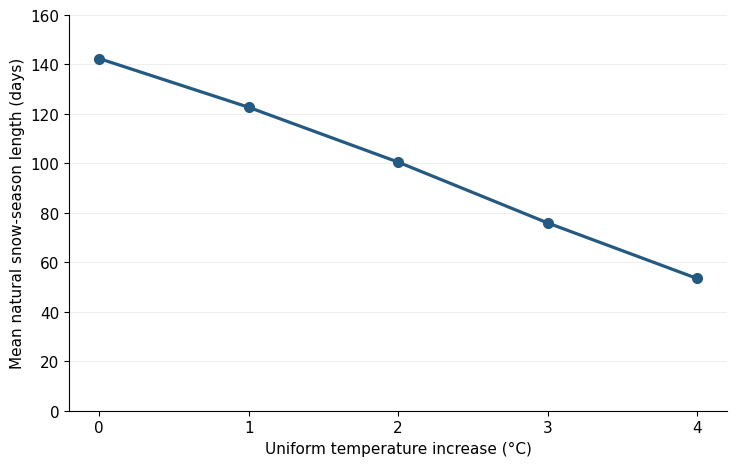


Saved to: /Users/evabenson/Files/thesis/ski_thesis_clean/outputs/thesis_figures


In [204]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Output directory
fig_dir = Path("outputs/thesis_figures")
fig_dir.mkdir(parents=True, exist_ok=True)

# Mean season length by warming scenario
warming_plot = (
    climate_results.groupby("warming_c", as_index=False)
    .agg(
        mean_season_days=("season_days", "mean")
    )
    .sort_values("warming_c")
)

# Print uncertainty table so we can verify the CI columns
print("BOOTSTRAP UNCERTAINTY COLUMNS:")
print(warming_uncertainty.columns.tolist())

print("\nWARMING SCENARIO MEANS:")
display(warming_plot.round(2))

# Figure styling
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "savefig.dpi": 300
})

fig, ax = plt.subplots(figsize=(7.5, 4.8))

ax.plot(
    warming_plot["warming_c"],
    warming_plot["mean_season_days"],
    marker="o",
    linewidth=2.3,
    markersize=7,
    color="#245A81"
)

ax.set(
    xlabel="Uniform temperature increase (°C)",
    ylabel="Mean natural snow-season length (days)",
    xticks=[0, 1, 2, 3, 4],
    ylim=(0, 160)
)

ax.grid(axis="y", alpha=0.2)

fig.tight_layout()

fig.savefig(
    fig_dir / "figure_03_warming_response.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    fig_dir / "figure_03_warming_response.pdf",
    bbox_inches="tight"
)

plt.show()

print("\nSaved to:", fig_dir.resolve())


In [205]:

print("WARMING UNCERTAINTY TABLE")
display(warming_uncertainty)

print("\nCOLUMN NAMES")
print(warming_uncertainty.columns.tolist())


WARMING UNCERTAINTY TABLE


,warming_c,mean_change_days,ci_lower,ci_upper
0,1,-19.704945,-21.088516,-18.266319
1,2,-41.874176,-44.900797,-38.918640
2,3,-66.462637,-70.944258,-62.087637
3,4,-88.922527,-94.470563,-83.509588



COLUMN NAMES
['warming_c', 'mean_change_days', 'ci_lower', 'ci_upper']


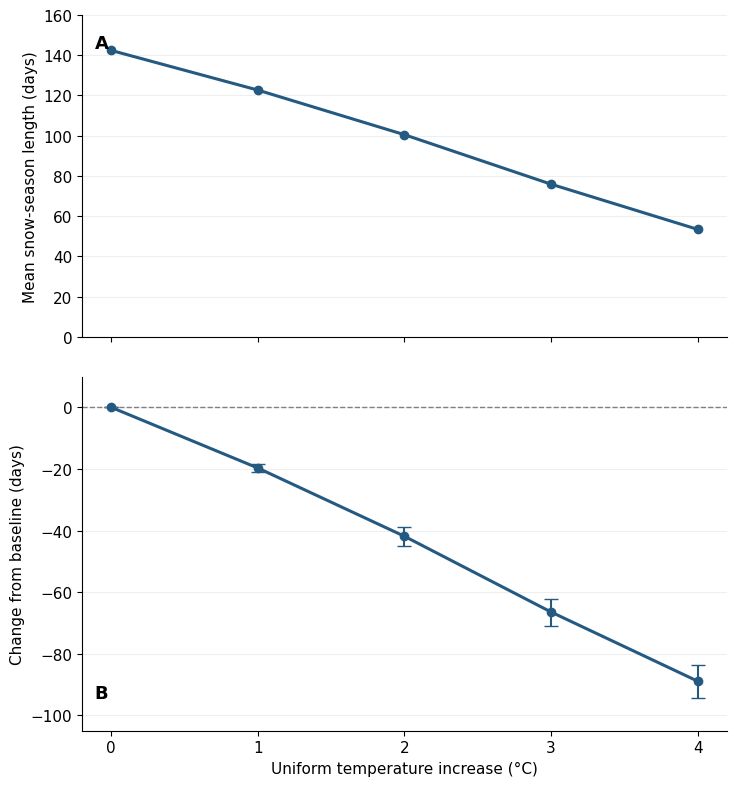

Saved final Figure 3:
outputs/thesis_figures/figure_03_warming_sensitivity.png
outputs/thesis_figures/figure_03_warming_sensitivity.pdf


In [206]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

fig_dir = Path("outputs/thesis_figures")
fig_dir.mkdir(parents=True, exist_ok=True)

# Mean modeled season length
means = (
    climate_results
    .groupby("warming_c", as_index=False)
    .agg(mean_days=("season_days", "mean"))
    .sort_values("warming_c")
)

# Bootstrap uncertainty for changes from baseline
ci = warming_uncertainty.sort_values("warming_c").copy()

# Include baseline (zero change by definition)
ci = pd.concat([
    pd.DataFrame({
        "warming_c": [0],
        "mean_change_days": [0.0],
        "ci_lower": [0.0],
        "ci_upper": [0.0]
    }),
    ci
], ignore_index=True)

# Asymmetric confidence interval distances
lower_err = ci["mean_change_days"] - ci["ci_lower"]
upper_err = ci["ci_upper"] - ci["mean_change_days"]

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "pdf.fonttype": 42,
    "savefig.dpi": 300
})

fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(7.5, 8),
    sharex=True,
    gridspec_kw={"height_ratios": [1, 1.1]}
)

color = "#245A81"

# Panel A: Absolute season length
ax1.plot(
    means["warming_c"],
    means["mean_days"],
    color=color,
    marker="o",
    linewidth=2.2,
    markersize=6
)

ax1.set_ylabel("Mean snow-season length (days)")
ax1.set_ylim(0, 160)
ax1.grid(axis="y", alpha=0.2)
ax1.text(
    0.02, 0.94, "A",
    transform=ax1.transAxes,
    fontsize=13, fontweight="bold",
    va="top"
)

# Panel B: Changes relative to baseline
ax2.errorbar(
    ci["warming_c"],
    ci["mean_change_days"],
    yerr=np.vstack([lower_err, upper_err]),
    fmt="o-",
    color=color,
    linewidth=2.2,
    markersize=6,
    capsize=5,
    elinewidth=1.5
)

ax2.axhline(0, color="gray", linewidth=1, linestyle="--")
ax2.set_ylabel("Change from baseline (days)")
ax2.set_xlabel("Uniform temperature increase (°C)")
ax2.set_xticks([0, 1, 2, 3, 4])
ax2.set_ylim(-105, 10)
ax2.grid(axis="y", alpha=0.2)
ax2.text(
    0.02, 0.08, "B",
    transform=ax2.transAxes,
    fontsize=13, fontweight="bold",
    va="bottom"
)

fig.tight_layout(h_pad=2)

fig.savefig(
    fig_dir / "figure_03_warming_sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    fig_dir / "figure_03_warming_sensitivity.pdf",
    bbox_inches="tight"
)

plt.show()

print("Saved final Figure 3:")
print(fig_dir / "figure_03_warming_sensitivity.png")
print(fig_dir / "figure_03_warming_sensitivity.pdf")


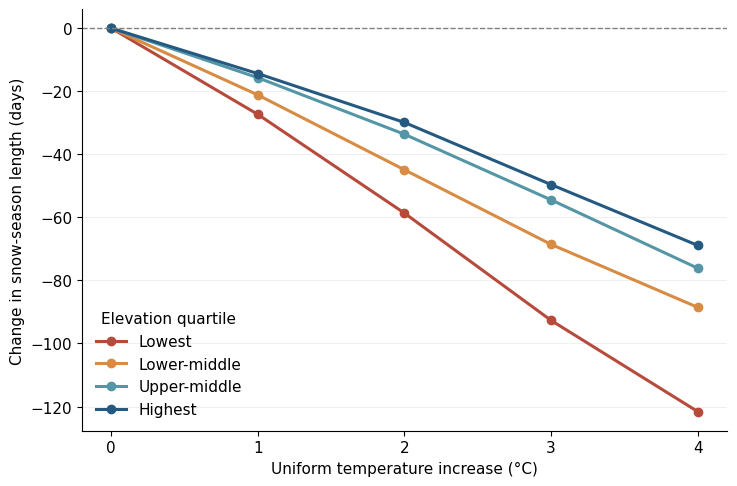


+2°C ELEVATION RESULTS


,elevation_quartile,baseline_days,mean_season_days,change_days
2,Lowest,154.9,96.2,-58.7
7,Lower-middle,126.2,81.3,-44.9
12,Upper-middle,137.6,103.9,-33.6
17,Highest,150.6,120.7,-29.9



Saved Figure 4 to: /Users/evabenson/Files/thesis/ski_thesis_clean/outputs/thesis_figures


In [207]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

fig_dir = Path("outputs/thesis_figures")
fig_dir.mkdir(parents=True, exist_ok=True)

# Resort elevations (one record per resort)
elevations = (
    resort_info[["resort_id", "elevation_m"]]
    .drop_duplicates("resort_id")
    .copy()
)

elevations["elevation_quartile"] = pd.qcut(
    elevations["elevation_m"],
    q=4,
    labels=[
        "Lowest",
        "Lower-middle",
        "Upper-middle",
        "Highest"
    ]
)

# Join elevation quartiles to climate scenario results
elevation_climate = climate_results.merge(
    elevations[["resort_id", "elevation_quartile"]],
    on="resort_id",
    validate="many_to_one"
)

# Average season length by elevation and warming scenario
elevation_summary = (
    elevation_climate.groupby(
        ["elevation_quartile", "warming_c"],
        observed=True
    )
    .agg(mean_season_days=("season_days", "mean"))
    .reset_index()
)

# Calculate changes relative to each elevation group's baseline
baseline = (
    elevation_summary[
        elevation_summary["warming_c"] == 0
    ][["elevation_quartile", "mean_season_days"]]
    .rename(columns={
        "mean_season_days": "baseline_days"
    })
)

elevation_summary = elevation_summary.merge(
    baseline,
    on="elevation_quartile",
    validate="many_to_one"
)

elevation_summary["change_days"] = (
    elevation_summary["mean_season_days"]
    - elevation_summary["baseline_days"]
)

# Plot
fig, ax = plt.subplots(figsize=(7.5, 5))

colors = {
    "Lowest": "#B64B3C",
    "Lower-middle": "#D88B42",
    "Upper-middle": "#5496A5",
    "Highest": "#245A81"
}

for group in colors:
    subset = elevation_summary[
        elevation_summary["elevation_quartile"] == group
    ].sort_values("warming_c")

    ax.plot(
        subset["warming_c"],
        subset["change_days"],
        marker="o",
        linewidth=2.2,
        markersize=6,
        color=colors[group],
        label=group
    )

ax.axhline(0, color="gray", linewidth=1, linestyle="--")

ax.set(
    xlabel="Uniform temperature increase (°C)",
    ylabel="Change in snow-season length (days)",
    xticks=[0, 1, 2, 3, 4]
)

ax.grid(axis="y", alpha=0.2)
ax.legend(title="Elevation quartile", frameon=False)

fig.tight_layout()

fig.savefig(
    fig_dir / "figure_04_elevation_vulnerability.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    fig_dir / "figure_04_elevation_vulnerability.pdf",
    bbox_inches="tight"
)

plt.show()

print("\n+2°C ELEVATION RESULTS")
display(
    elevation_summary[
        elevation_summary["warming_c"] == 2
    ][
        ["elevation_quartile", "baseline_days",
         "mean_season_days", "change_days"]
    ].round(1)
)

print("\nSaved Figure 4 to:", fig_dir.resolve())


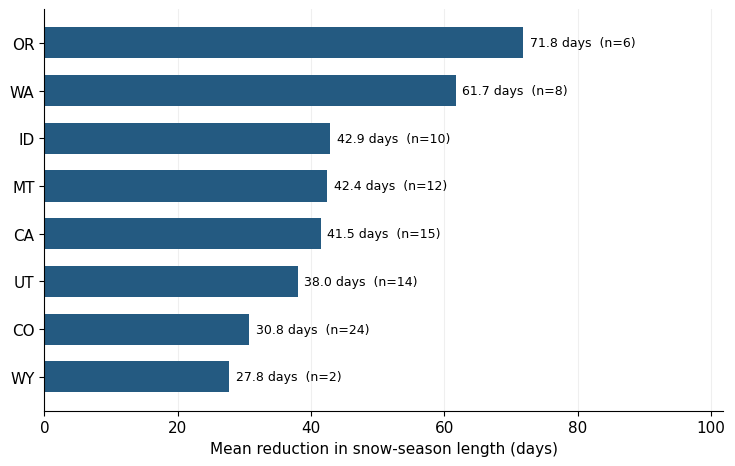


STATE VULNERABILITY SUMMARY


,state,n_resorts,mean_loss_days
4,OR,6,71.8
6,WA,8,61.7
2,ID,10,42.9
3,MT,12,42.4
0,CA,15,41.5
5,UT,14,38.0
1,CO,24,30.8
7,WY,2,27.8


In [208]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

fig_dir = Path("outputs/thesis_figures")
fig_dir.mkdir(parents=True, exist_ok=True)

# Use resort-level losses to calculate state means
state_fig = (
    resort_vulnerability
    .groupby("state", as_index=False)
    .agg(
        n_resorts=("resort_id", "nunique"),
        mean_loss_days=("days_lost_2c", "mean")
    )
    .sort_values("mean_loss_days", ascending=True)
)

fig, ax = plt.subplots(figsize=(7.5, 4.8))

bars = ax.barh(
    state_fig["state"],
    state_fig["mean_loss_days"],
    color="#245A81",
    height=0.65
)

# Label each bar with loss and sample size
for bar, (_, row) in zip(bars, state_fig.iterrows()):
    ax.text(
        bar.get_width() + 1,
        bar.get_y() + bar.get_height() / 2,
        f'{row["mean_loss_days"]:.1f} days  (n={int(row["n_resorts"])})',
        va="center",
        fontsize=9
    )

ax.set_xlabel("Mean reduction in snow-season length (days)")
ax.set_ylabel("")
ax.set_xlim(0, state_fig["mean_loss_days"].max() + 30)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

fig.tight_layout()

fig.savefig(
    fig_dir / "figure_05_state_vulnerability.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    fig_dir / "figure_05_state_vulnerability.pdf",
    bbox_inches="tight"
)

plt.show()

print("\nSTATE VULNERABILITY SUMMARY")
display(
    state_fig.sort_values(
        "mean_loss_days", ascending=False
    ).round(1)
)


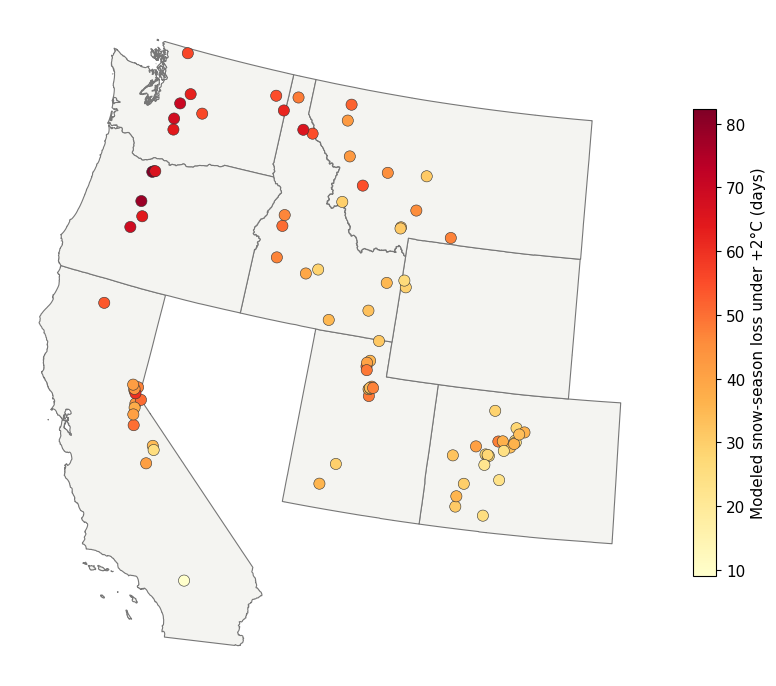

Resorts mapped: 91
Range of modeled losses:
count    91.0
mean     41.9
std      14.3
min       9.0
25%      30.5
50%      40.4
75%      49.8
max      82.3
Name: days_lost_2c, dtype: float64


In [209]:

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

fig_dir = Path("outputs/thesis_figures")
fig_dir.mkdir(parents=True, exist_ok=True)

# Join resort coordinates and modeled vulnerability
map_data = resort_states[
    ["resort_id", "resort_name", "geometry"]
].merge(
    resort_vulnerability[
        ["resort_id", "days_lost_2c"]
    ],
    on="resort_id",
    validate="one_to_one"
)

map_data = gpd.GeoDataFrame(
    map_data,
    geometry="geometry",
    crs=resort_states.crs
)

# Use the state boundaries already loaded in the notebook,
# if available. Otherwise retrieve Census state boundaries.
if "states" in globals() and isinstance(states, gpd.GeoDataFrame):
    state_boundaries = states.copy()
else:
    state_boundaries = gpd.read_file(
        "https://www2.census.gov/geo/tiger/GENZ2023/shp/"
        "cb_2023_us_state_500k.zip"
    )

# Restrict to the states represented in the study
study_states = ["CA", "CO", "ID", "MT", "OR", "UT", "WA", "WY"]

if "STUSPS" in state_boundaries.columns:
    state_boundaries = state_boundaries[
        state_boundaries["STUSPS"].isin(study_states)
    ].copy()
elif "state" in state_boundaries.columns:
    state_boundaries = state_boundaries[
        state_boundaries["state"].isin(study_states)
    ].copy()

# Use an equal-area projection for the western U.S.
map_crs = "EPSG:5070"

map_data = map_data.to_crs(map_crs)
state_boundaries = state_boundaries.to_crs(map_crs)

fig, ax = plt.subplots(figsize=(9, 7))

state_boundaries.plot(
    ax=ax,
    facecolor="#F4F4F1",
    edgecolor="#777777",
    linewidth=0.8
)

map_data.plot(
    ax=ax,
    column="days_lost_2c",
    cmap="YlOrRd",
    markersize=65,
    edgecolor="#333333",
    linewidth=0.4,
    legend=True,
    legend_kwds={
        "label": "Modeled snow-season loss under +2°C (days)",
        "shrink": 0.7
    }
)

ax.set_axis_off()
ax.set_aspect("equal")

fig.tight_layout()

fig.savefig(
    fig_dir / "figure_06_resort_vulnerability_map.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    fig_dir / "figure_06_resort_vulnerability_map.pdf",
    bbox_inches="tight"
)

plt.show()

print("Resorts mapped:", len(map_data))
print("Range of modeled losses:")
print(map_data["days_lost_2c"].describe().round(1))


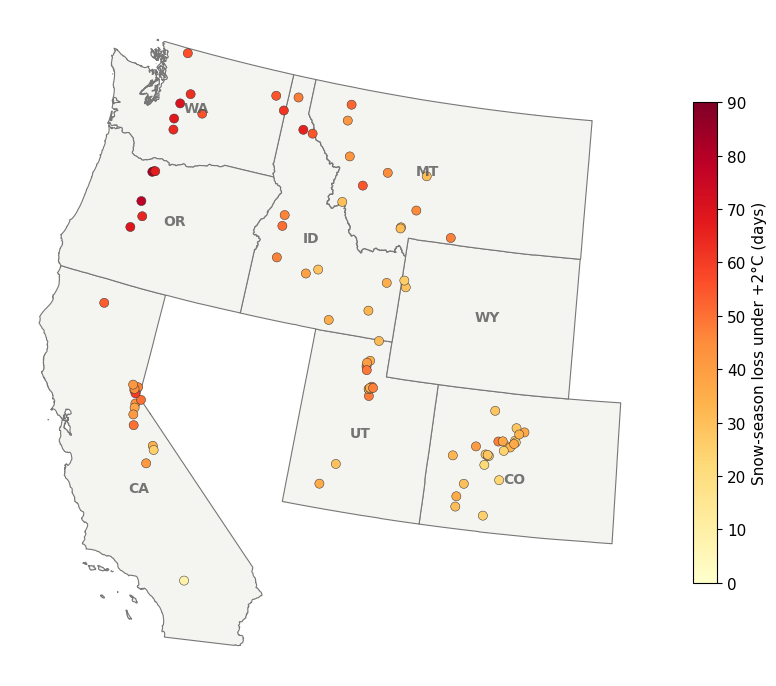

In [210]:

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

fig, ax = plt.subplots(figsize=(9, 7))

# State boundaries
state_boundaries.plot(
    ax=ax,
    facecolor="#F4F4F1",
    edgecolor="#777777",
    linewidth=0.8
)

# Resort vulnerability
map_data.plot(
    ax=ax,
    column="days_lost_2c",
    cmap="YlOrRd",
    norm=mcolors.Normalize(vmin=0, vmax=90),
    markersize=43,
    edgecolor="#333333",
    linewidth=0.35,
    legend=True,
    legend_kwds={
        "label": "Snow-season loss under +2°C (days)",
        "shrink": 0.72
    }
)

# State labels using representative points
state_label_positions = {
    "WA": (-120.7, 47.4),
    "OR": (-120.4, 44.1),
    "CA": (-119.2, 36.5),
    "ID": (-114.9, 44.5),
    "MT": (-110.7, 47.0),
    "WY": (-107.5, 43.1),
    "UT": (-111.7, 39.3),
    "CO": (-105.8, 38.6)
}

# Convert label coordinates to map projection
import geopandas as gpd

label_points = gpd.GeoDataFrame(
    {"state": list(state_label_positions.keys())},
    geometry=gpd.points_from_xy(
        [v[0] for v in state_label_positions.values()],
        [v[1] for v in state_label_positions.values()]
    ),
    crs="EPSG:4326"
).to_crs(map_crs)

for _, row in label_points.iterrows():
    ax.text(
        row.geometry.x,
        row.geometry.y,
        row["state"],
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold",
        color="#555555",
        alpha=0.8
    )

ax.set_axis_off()
ax.set_aspect("equal")

fig.tight_layout()

fig.savefig(
    fig_dir / "figure_06_resort_vulnerability_map.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    fig_dir / "figure_06_resort_vulnerability_map.pdf",
    bbox_inches="tight"
)

plt.show()


In [211]:

import pandas as pd

predictions = pd.read_csv(
    "outputs/model_validation_predictions.csv"
)

print("PREDICTION DATA COLUMNS")
print(predictions.columns.tolist())

print("\nFIRST FIVE ROWS")
display(predictions.head())

print("\nDATASET SIZE")
print(predictions.shape)


PREDICTION DATA COLUMNS
['fips', 'year', 'threshold_cm', 'validation', 'Model', 'observed', 'predicted']

FIRST FIVE ROWS


,fips,year,threshold_cm,validation,Model,observed,predicted
0,8019,2004,10,LOYO,FE1 Baseline,87.287497,126.704361
1,8019,2005,10,LOYO,FE1 Baseline,124.563982,135.220530
2,8019,2006,10,LOYO,FE1 Baseline,112.671397,128.792830
3,8019,2007,10,LOYO,FE1 Baseline,142.598728,125.831249
4,8019,2008,10,LOYO,FE1 Baseline,136.615701,139.388973



DATASET SIZE
(6000, 7)


In [213]:

import pandas as pd

print("POTENTIAL SNOW-DEPTH PREDICTION DATAFRAMES\n")

for name, obj in list(globals().items()):
    if not isinstance(obj, pd.DataFrame):
        continue

    cols = [str(c) for c in obj.columns]

    matching = [
        c for c in cols
        if any(term in c.lower() for term in [
            "pred", "snow_depth", "observed",
            "simulated", "recursive"
        ])
    ]

    if matching:
        print(f"{name}: {obj.shape}")
        print("  Matching columns:", matching[:15])
        print("  All columns:", cols[:30])
        print()


POTENTIAL SNOW-DEPTH PREDICTION DATAFRAMES

train: (347256, 33)
  Matching columns: ['snow_depth_m']
  All columns: ['date', 'resort_id', 'snow_depth_m', 'tmin', 'tmax', 'prcp', 'srad', 'dayl', 'elevation_m', 'slope_deg', 'northness', 'eastness', 'elevation_std_150m', 'winter_year', 'daymet_missing_original', 'snodas_missing_original', 'tmean', 'freezing_day', 'cold_precip_mm', 'day_of_year', 'season_sin', 'season_cos', 'prcp_3d', 'cold_precip_3d', 'prcp_7d', 'cold_precip_7d', 'prcp_14d', 'cold_precip_14d', 'prcp_30d', 'cold_precip_30d']

val: (74620, 33)
  Matching columns: ['snow_depth_m']
  All columns: ['date', 'resort_id', 'snow_depth_m', 'tmin', 'tmax', 'prcp', 'srad', 'dayl', 'elevation_m', 'slope_deg', 'northness', 'eastness', 'elevation_std_150m', 'winter_year', 'daymet_missing_original', 'snodas_missing_original', 'tmean', 'freezing_day', 'cold_precip_mm', 'day_of_year', 'season_sin', 'season_cos', 'prcp_3d', 'cold_precip_3d', 'prcp_7d', 'cold_precip_7d', 'prcp_14d', 'cold_pr

INDEPENDENT TEST PERFORMANCE
Observations: 74,529
MAE: 0.157 m
RMSE: 0.268 m
R²: 0.884


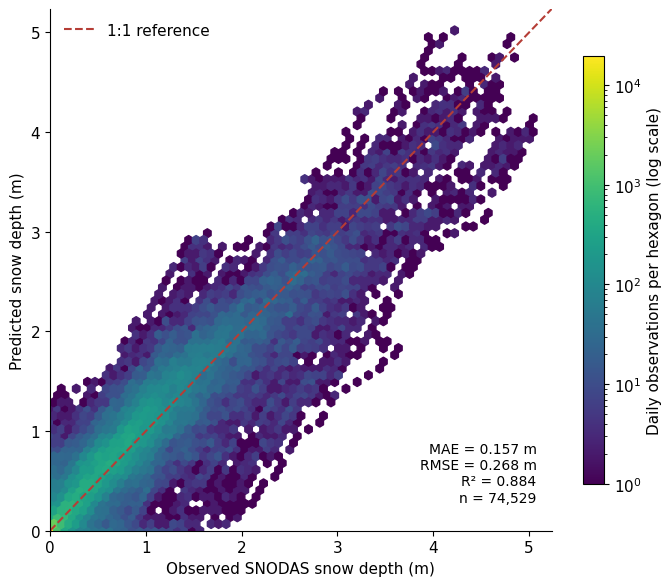

In [214]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

fig_dir = Path("outputs/thesis_figures")
fig_dir.mkdir(parents=True, exist_ok=True)

# Independent test-period recursive predictions
plot_df = recursive_test.loc[
    recursive_test["winter_year"].between(2021, 2023),
    ["snow_depth_m", "recursive_pred_m"]
].dropna().copy()

observed = plot_df["snow_depth_m"].to_numpy()
predicted = plot_df["recursive_pred_m"].to_numpy()

mae = mean_absolute_error(observed, predicted)
rmse = np.sqrt(mean_squared_error(observed, predicted))
r2 = r2_score(observed, predicted)

print("INDEPENDENT TEST PERFORMANCE")
print(f"Observations: {len(plot_df):,}")
print(f"MAE: {mae:.3f} m")
print(f"RMSE: {rmse:.3f} m")
print(f"R²: {r2:.3f}")

# Consistent axes for observed and predicted depth
axis_max = max(observed.max(), predicted.max()) * 1.03

fig, ax = plt.subplots(figsize=(7, 6))

hb = ax.hexbin(
    observed,
    predicted,
    gridsize=65,
    cmap="viridis",
    mincnt=1,
    bins="log"
)

ax.plot(
    [0, axis_max],
    [0, axis_max],
    linestyle="--",
    color="#B53D36",
    linewidth=1.5,
    label="1:1 reference"
)

ax.set_xlim(0, axis_max)
ax.set_ylim(0, axis_max)

ax.set_xlabel("Observed SNODAS snow depth (m)")
ax.set_ylabel("Predicted snow depth (m)")

ax.legend(frameon=False, loc="upper left")

ax.text(
    0.97, 0.05,
    f"MAE = {mae:.3f} m\n"
    f"RMSE = {rmse:.3f} m\n"
    f"R² = {r2:.3f}\n"
    f"n = {len(plot_df):,}",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=10,
    bbox=dict(
        facecolor="white",
        edgecolor="none",
        alpha=0.85
    )
)

cbar = fig.colorbar(hb, ax=ax, shrink=0.82)
cbar.set_label("Daily observations per hexagon (log scale)")

fig.tight_layout()

fig.savefig(
    fig_dir / "figure_02_recursive_model_validation.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    fig_dir / "figure_02_recursive_model_validation.pdf",
    bbox_inches="tight"
)

plt.show()


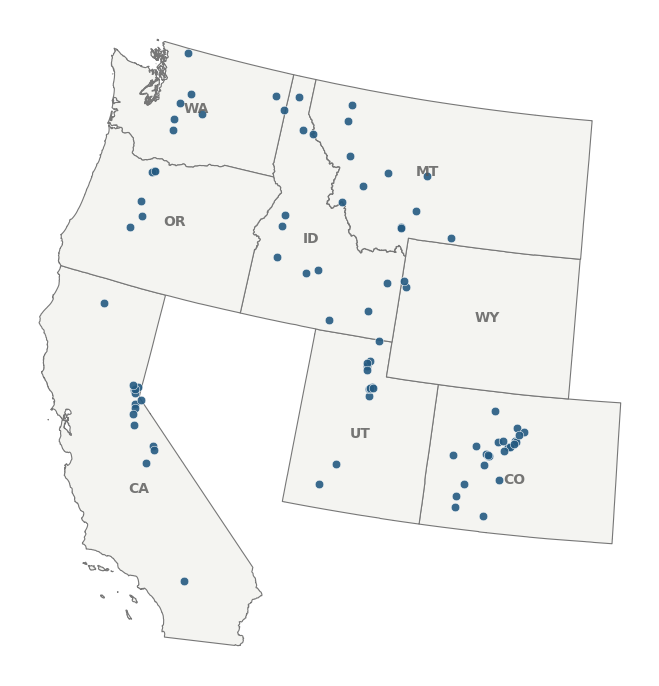

Number of resorts: 91


In [215]:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 7))

# Western state boundaries
state_boundaries.plot(
    ax=ax,
    facecolor="#F4F4F1",
    edgecolor="#777777",
    linewidth=0.8
)

# All 91 sampled ski resorts
map_data.plot(
    ax=ax,
    color="#245A81",
    markersize=38,
    edgecolor="white",
    linewidth=0.4,
    alpha=0.9
)

# Reuse the state label locations from Figure 6
for _, row in label_points.iterrows():
    ax.text(
        row.geometry.x,
        row.geometry.y,
        row["state"],
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold",
        color="#555555",
        alpha=0.8
    )

ax.set_axis_off()
ax.set_aspect("equal")

fig.tight_layout()

fig.savefig(
    fig_dir / "figure_01_study_area.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    fig_dir / "figure_01_study_area.pdf",
    bbox_inches="tight"
)

plt.show()

print("Number of resorts:", len(map_data))


In [216]:

import pandas as pd
from pathlib import Path

table_dir = Path("outputs/thesis_tables")
table_dir.mkdir(parents=True, exist_ok=True)

# Resort sample by state
state_sample = (
    resort_info.groupby("state")
    .agg(n_resorts=("resort_id", "nunique"))
    .reset_index()
    .sort_values("n_resorts", ascending=False)
)

print("TABLE 1A: RESORT SAMPLE BY STATE")
display(state_sample)

# Descriptive statistics
variables = {
    "snow_depth_m": "SNODAS snow depth (m)",
    "tmin": "Daily minimum temperature (°C)",
    "tmax": "Daily maximum temperature (°C)",
    "prcp": "Daily precipitation (mm)",
    "elevation_m": "Resort elevation (m)"
}

summary_rows = []

for col, label in variables.items():
    if col == "elevation_m":
        values = resort_info[col].dropna()
    else:
        values = recursive_df[col].dropna()

    summary_rows.append({
        "Variable": label,
        "N": len(values),
        "Mean": values.mean(),
        "SD": values.std(),
        "Min": values.min(),
        "Max": values.max()
    })

descriptive_table = pd.DataFrame(summary_rows)

print("\nTABLE 1B: DESCRIPTIVE STATISTICS")
display(descriptive_table.round(2))

state_sample.to_csv(
    table_dir / "table_01_state_sample.csv",
    index=False
)

descriptive_table.to_csv(
    table_dir / "table_01_descriptive_statistics.csv",
    index=False
)

print("\nTables saved to:", table_dir.resolve())


TABLE 1A: RESORT SAMPLE BY STATE


,state,n_resorts
1,CO,24
0,CA,15
5,UT,14
3,MT,12
2,ID,10
6,WA,8
4,OR,6
7,WY,2



TABLE 1B: DESCRIPTIVE STATISTICS


,Variable,N,Mean,SD,Min,Max
0,SNODAS snow depth (m),496405,0.62,0.78,0.00,6.22
1,Daily minimum temperature (°C),497315,-3.51,6.82,-38.65,22.34
2,Daily maximum temperature (°C),497315,7.64,8.08,-27.08,39.78
3,Daily precipitation (mm),497315,3.24,7.33,0.00,197.91
4,Resort elevation (m),91,2202.77,576.71,945.49,3432.96



Tables saved to: /Users/evabenson/Files/thesis/ski_thesis_clean/outputs/thesis_tables


In [217]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from pathlib import Path

table_dir = Path("outputs/thesis_tables")
table_dir.mkdir(parents=True, exist_ok=True)

# Daily recursive predictions available for validation and test
daily_sources = {
    "Validation (2018–2020)": recursive_predictions,
    "Test (2021–2023)": recursive_test
}

rows = []

for period, data in daily_sources.items():
    years = (2018, 2020) if "Validation" in period else (2021, 2023)

    subset = data.loc[
        data["winter_year"].between(*years),
        ["snow_depth_m", "recursive_pred_m"]
    ].dropna()

    obs = subset["snow_depth_m"].to_numpy()
    pred = subset["recursive_pred_m"].to_numpy()

    rows.append({
        "Outcome": "Daily snow depth",
        "Period": period,
        "N": len(subset),
        "MAE": mean_absolute_error(obs, pred),
        "RMSE": np.sqrt(mean_squared_error(obs, pred)),
        "R²": r2_score(obs, pred),
        "Bias": np.mean(pred - obs),
        "Units": "meters"
    })

# Season-length performance for all three periods
for period, years in [
    ("Training (2004–2017)", (2004, 2017)),
    ("Validation (2018–2020)", (2018, 2020)),
    ("Test (2021–2023)", (2021, 2023))
]:
    subset = full_validation.loc[
        full_validation["winter_year"].between(*years)
    ]

    obs = subset["observed_days"].to_numpy()
    pred = subset["predicted_days"].to_numpy()

    rows.append({
        "Outcome": "Snow-season length",
        "Period": period,
        "N": len(subset),
        "MAE": mean_absolute_error(obs, pred),
        "RMSE": np.sqrt(mean_squared_error(obs, pred)),
        "R²": r2_score(obs, pred),
        "Bias": np.mean(pred - obs),
        "Units": "days"
    })

performance_table = pd.DataFrame(rows)

print("TABLE 2: MODEL PERFORMANCE")
display(performance_table.round(3))

# Zero-season classification
zero_rows = []

for period, years in [
    ("Training", (2004, 2017)),
    ("Validation", (2018, 2020)),
    ("Test", (2021, 2023))
]:
    subset = full_validation.loc[
        full_validation["winter_year"].between(*years)
    ]

    observed_zero = subset["observed_days"] == 0
    predicted_zero = subset["predicted_days"] == 0

    tp = (observed_zero & predicted_zero).sum()

    zero_rows.append({
        "Period": period,
        "Observed zero seasons": observed_zero.sum(),
        "Predicted zero seasons": predicted_zero.sum(),
        "Recall": tp / observed_zero.sum()
        if observed_zero.sum() else np.nan
    })

zero_performance = pd.DataFrame(zero_rows)

print("\nZERO-SEASON CLASSIFICATION")
display(zero_performance.round(3))

performance_table.to_csv(
    table_dir / "table_02_model_performance.csv",
    index=False
)

zero_performance.to_csv(
    table_dir / "table_02_zero_season_performance.csv",
    index=False
)


TABLE 2: MODEL PERFORMANCE


,Outcome,Period,N,MAE,RMSE,R²,Bias,Units
0,Daily snow depth,Validation (2018–2020),74620,0.154,0.275,0.844,0.023,meters
1,Daily snow depth,Test (2021–2023),74529,0.157,0.268,0.884,0.017,meters
2,Snow-season length,Training (2004–2017),1274,18.753,28.520,0.753,4.002,days
3,Snow-season length,Validation (2018–2020),273,21.498,28.689,0.731,5.901,days
4,Snow-season length,Test (2021–2023),273,18.381,27.148,0.722,4.300,days



ZERO-SEASON CLASSIFICATION


,Period,Observed zero seasons,Predicted zero seasons,Recall
0,Training,61,29,0.410
1,Validation,13,2,0.154
2,Test,6,2,0.333


In [218]:

import numpy as np
import pandas as pd
from pathlib import Path

table_dir = Path("outputs/thesis_tables")
table_dir.mkdir(parents=True, exist_ok=True)

# Summarize each warming scenario
scenario_table = (
    climate_results.groupby("warming_c", as_index=False)
    .agg(
        resort_winters=("season_days", "size"),
        mean_season_days=("season_days", "mean"),
        median_season_days=("season_days", "median"),
        zero_season_winters=("season_days", lambda x: (x == 0).sum())
    )
    .sort_values("warming_c")
)

# Changes relative to the modeled historical baseline
baseline_mean = scenario_table.loc[
    scenario_table["warming_c"] == 0,
    "mean_season_days"
].iloc[0]

scenario_table["change_days"] = (
    scenario_table["mean_season_days"] - baseline_mean
)

scenario_table["pct_change"] = (
    100 * scenario_table["change_days"] / baseline_mean
)

scenario_table["zero_season_pct"] = (
    100 * scenario_table["zero_season_winters"]
    / scenario_table["resort_winters"]
)

# Join existing resort-cluster bootstrap confidence intervals
scenario_table = scenario_table.merge(
    warming_uncertainty[
        ["warming_c", "ci_lower", "ci_upper"]
    ],
    on="warming_c",
    how="left",
    validate="one_to_one"
)

# Baseline change is zero by definition
scenario_table.loc[
    scenario_table["warming_c"] == 0,
    ["ci_lower", "ci_upper"]
] = 0.0

# Formatted version for the thesis
thesis_table_3 = pd.DataFrame({
    "Warming (°C)": scenario_table["warming_c"],
    "Mean season (days)": scenario_table["mean_season_days"].round(1),
    "Change (days)": scenario_table["change_days"].round(1),
    "Change (%)": scenario_table["pct_change"].round(1),
    "95% CI for change (days)": [
        "Reference" if w == 0 else f"[{lo:.1f}, {hi:.1f}]"
        for w, lo, hi in zip(
            scenario_table["warming_c"],
            scenario_table["ci_lower"],
            scenario_table["ci_upper"]
        )
    ],
    "Zero-season winters": scenario_table["zero_season_winters"],
    "Zero-season share (%)": scenario_table["zero_season_pct"].round(1)
})

print("TABLE 3: WARMING SCENARIO RESULTS")
display(thesis_table_3)

thesis_table_3.to_csv(
    table_dir / "table_03_warming_scenarios.csv",
    index=False
)

scenario_table.to_csv(
    table_dir / "table_03_warming_scenarios_unrounded.csv",
    index=False
)

print("\nSaved to:", table_dir.resolve())


TABLE 3: WARMING SCENARIO RESULTS


,Warming (°C),Mean season (days),Change (days),Change (%),95% CI for change (days),Zero-season winters,Zero-season share (%)
0,0,142.4,0.0,0.0,Reference,33,1.8
1,1,122.7,-19.7,-13.8,"[-21.1, -18.3]",74,4.1
2,2,100.5,-41.9,-29.4,"[-44.9, -38.9]",160,8.8
3,3,75.9,-66.5,-46.7,"[-70.9, -62.1]",305,16.8
4,4,53.5,-88.9,-62.4,"[-94.5, -83.5]",524,28.8



Saved to: /Users/evabenson/Files/thesis/ski_thesis_clean/outputs/thesis_tables


In [219]:

import pandas as pd
from pathlib import Path

table_dir = Path("outputs/thesis_tables")
table_dir.mkdir(parents=True, exist_ok=True)

# State-level results from the full sample
state_summary = (
    resort_vulnerability.groupby("state", as_index=False)
    .agg(
        n_resorts=("resort_id", "nunique"),
        baseline_days=("baseline_days", "mean"),
        warming_2c_days=("warming_2c_days", "mean"),
        days_lost=("days_lost_2c", "mean"),
        pct_lost=("pct_season_lost_2c", "mean")
    )
)

# Accuracy-filtered robustness results
robustness_summary = (
    vulnerability_accuracy.assign(
        retained=lambda x: x["test_mae_days"] <= 20
    )
    .groupby("state")
    .apply(
        lambda g: pd.Series({
            "retained_resorts": int(g["retained"].sum()),
            "filtered_loss": g.loc[
                g["retained"], "days_lost_2c"
            ].mean()
        }),
        include_groups=False
    )
    .reset_index()
)

# Combine
state_table = state_summary.merge(
    robustness_summary,
    on="state",
    validate="one_to_one"
).sort_values("days_lost", ascending=False)

# Use the ratio of state means for percentage loss,
# rather than averaging individual resort percentages.
state_table["pct_lost"] = (
    100 * state_table["days_lost"]
    / state_table["baseline_days"]
)

thesis_table_4 = pd.DataFrame({
    "State": state_table["state"],
    "Resorts": state_table["n_resorts"],
    "Baseline (days)": state_table["baseline_days"].round(1),
    "+2°C (days)": state_table["warming_2c_days"].round(1),
    "Loss (days)": state_table["days_lost"].round(1),
    "Loss (%)": state_table["pct_lost"].round(1),
    "Retained (MAE ≤20d)": state_table["retained_resorts"].astype(int),
    "Filtered loss (days)": state_table["filtered_loss"].round(1)
})

print("TABLE 4: STATE VULNERABILITY AND ROBUSTNESS")
display(thesis_table_4)

thesis_table_4.to_csv(
    table_dir / "table_04_state_vulnerability.csv",
    index=False
)

state_table.to_csv(
    table_dir / "table_04_state_vulnerability_unrounded.csv",
    index=False
)

print("\nSaved to:", table_dir.resolve())


TABLE 4: STATE VULNERABILITY AND ROBUSTNESS


,State,Resorts,Baseline (days),+2°C (days),Loss (days),Loss (%),Retained (MAE ≤20d),Filtered loss (days)
4,OR,6,166.0,94.2,71.8,43.3,3,71.1
6,WA,8,176.1,114.4,61.7,35.1,8,61.7
2,ID,10,131.8,88.9,42.9,32.5,8,45.1
3,MT,12,147.5,105.0,42.4,28.8,6,42.9
0,CA,15,119.9,78.4,41.5,34.6,9,38.7
5,UT,14,142.8,104.8,38.0,26.6,9,38.1
1,CO,24,138.8,108.0,30.8,22.2,18,30.4
7,WY,2,168.6,140.8,27.8,16.5,1,26.3



Saved to: /Users/evabenson/Files/thesis/ski_thesis_clean/outputs/thesis_tables
